<div style="background-color: #1a1a2e; padding: 20px; border-radius: 10px; text-align:center">

<h1 style="color:#f39c12">International Trade Analysis (2015–2024)</h1>
<h3 style="color:#aaaaaa">A Multi-Dimensional Framework for Country Performance & Bilateral Risk</h3>
</div>

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# A. INTRODUCTION
</div>

**Context**
International trade is the backbone of global economic integration.
Understanding **who trades, how much, with whom, and at what risk**
is essential for strategic decision-making at the country, institutional,
and portfolio level.

**Objective**
This analysis builds a comprehensive trade intelligence framework
covering **187 countries over 2015–2024**, structured around three
complementary dimensions :

- **Structural performance** — how competitive is a country globally ?
- **Bilateral vulnerability** — how exposed is it to partner dependencies ?
- **Combined positioning** — where does a country stand when trade power
  and bilateral resilience are assessed together ?

**Data Collection**
UN Comtrade API — ~4,000 calls
(187 countries × 2 flows × 10 years, aggregate level)
Data delivered via ETL pipeline (Bronze / Silver / Gold layer)
consumed here at Gold level.

**Structure**
The analysis is organized in 9 sections (A → I), progressing from
global system analysis to country-level scoring and final classification.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# B. Executive Summary
</div>

**What We Analyzed**
187 countries — 10 years — 3 analytical dimensions :
global trade structure (F), bilateral dependency (G),
and combined country scoring (H).

**Key Results**

| Dimension | Key Finding |
|---|---|
| **Global Trade** | Top 10 countries control 55-60% of exports — highly concentrated and structurally frozen |
| **COVID Impact** | 2020 did not reshape bilateral architectures — divergence reached its minimum in 2021 (8.3%) | 
| **Trade Power** | Only 3 countries (China, Germany, USA) qualify as true structural Leaders |
| **Bilateral Risk** | 10% of countries face Critical bilateral dependency — predominantly small commodity-dependent economies |
| **Combined Score** | 20 Global Champions combine top trade power with strong bilateral resilience |

**Main Conclusion**
> Trade strength and trade resilience are complementary but independent.
> The most strategically valuable countries are those that combine both —
> a rare profile held by fewer than 11% of the world's trading nations.
> Results feed directly into the Trade × Economy synthesis,
where trade profiles are crossed with macroeconomic fundamentals.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# C. Data & Methodology
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Data Scope
</div>

| Dimension | Detail |
|---|---|
| **Source** | UN Comtrade — annual trade flows |
| **Period** | 2015–2024 (10 years) |
| **Countries** | 187 countries (aggregate) / 133 (bilateral 2024) |
| **Flows** | Exports (X), Imports (M), Total Trade |
| **Bilateral** | Partner-level data for 133 reporting countries |
| **Granularity** | Annual — no product-level disaggregation |
| **Pipeline** | UN Comtrade API → ETL (Bronze / Silver / Gold) → Gold layer consumed here |

**Key limitation** : bilateral data for 2024 covers 133 countries
due to UN Comtrade reporting lags. Full-period bilateral analysis
uses all available years per country (2015–2023/2024).


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Methodology Overview
</div>

**Section F — Global Trade Structure**
- **Indicators** : export share, coverage ratio, CAGR, volatility,
  negative frequency
- **Scoring** : z-score based composite → rank normalized 0→1
- **Classification** : 4 profiles (Strong / Good / Moderate / Weak)
  based on q85 / q50 / q15 quantile thresholds
- **Meta Profile** : 5 strategic profiles combining static, dynamic
  and strategic quadrants

**Section G — Bilateral Trade Analysis**
- **Indicators** : HHI (import/export), critical share, dependency top,
  n critical partners, BDI Structural
- **Scoring** : weighted composite → 0.35 critical share + 0.25 HHI
  + 0.20 dependency top + 0.10 n critical + 0.10 BDIS
- **Classification** : 4 profiles (Robust / Stable / Vulnerable / Critical)
- **Full Period** : median aggregation (mean for n_critical)

**Section H — Combined Country Scoring**
- **Method** : rank normalization for equal F/G contribution
- **Weights** : 0.60 × F rank + 0.40 × G rank (inverted)
- **Thresholds** : 0.80 / 0.55 / 0.30
- **Output** : 4 combined profiles + 4 strategic quadrants


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Design Choices
</div>

Four methodological choices deserve explicit justification :

- **Median over mean** for full-period aggregation → robust to
  the 2020 COVID outlier across all indicators.
- **Rank normalization** in H → ensures equal contribution from F
  and G despite their different score distributions.
- **Export-centric scoring** in F → trade power is measured by
  competitive export capacity, not import volume.
- **Aggregate-level granularity** → product/sector disaggregation
  is technically available but API-constrained (~4,000 calls per product).
  Aggregate flows provide a complete, consistent 187-country coverage
  that product-level data cannot match at this scale.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# D. Technical Setup
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Imports
</div>

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import zscore, spearmanr, linregress
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.animation import FuncAnimation
import seaborn as sns
import matplotlib.gridspec as gridspec
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Helper Functions
</div>

In [3]:
def init_plot(title: str, xlabel: str = "Year", ylabel: str = "" ):
    plt.figure(figsize=(10, 6))
    plt.title(title, fontsize=14, weight="bold", color="blue")
    plt.xlabel(xlabel, fontsize=12, weight="bold")
    plt.ylabel(ylabel, fontsize=12, weight="bold")
    plt.xticks(fontsize=10, weight="bold", color = "red")
    plt.yticks(fontsize=10, weight="bold", color = "red")

def _format_value(x):
    if abs(x) >= 1e12: return f"{x/1e12:.2f}T"
    if abs(x) >= 1e9: return f"{x/1e9:.2f}B" 
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.1f}K"
    return f"{x:.2f}"
def _desc_metric(x):
    if x == "M"    : return "Import"
    elif x == "X"  : return "Export"
    else           : return x
    
def normalize_delta(delta_series):
    """   Normalize delta sur 0-1 avec: - Amélioration (negatif) → 0-0.5  - Aggravation (positif) → 0.5-1    - Null (0 or NaN) → 0.5     """
    delta = delta_series.copy().fillna(0)
    if delta.abs().max() == 0:
        return pd.Series(0.5, index=delta.index)
    # Normalization Min-Max on absolute values 
    delta_abs = delta.abs()
    delta_norm = (delta_abs - delta_abs.min()) / (delta_abs.max() - delta_abs.min())
    # sign
    delta_norm = delta_norm * np.sign(delta)
    # 0-1
    delta_norm = (delta_norm + 1) / 2
    return delta_norm

## Function conversion 
def to_rgba(color, alpha=0.5):
    """ Convert rgb(), rgba(), or #hex to rgba() with transparence alpha """
    if color.startswith('rgb('):        return color.replace('rgb(', 'rgba(').replace(')', f', {alpha})') # Case 1: rgb(r, g, b)
    elif color.startswith('rgba('):     return color.rsplit(',', 1)[0] + f', {alpha})'  # Case 2: rgba(r, g, b, a) 
    elif color.startswith('#'):
        hex_color = color.lstrip('#')
        r = int(hex_color[0:2], 16)
        g = int(hex_color[2:4], 16)
        b = int(hex_color[4:6], 16)
        return f'rgba({r}, {g}, {b}, {alpha})'                        # Case 3: #RRGGBB (hex)
    else:         return f'rgba(128, 128, 128, {alpha})'             # Fallback (default color )

# Normalize dependency_top
def normalize_dep(df):
    max_dep = df["dependency_top"].max()
    if max_dep == 0: df["dependency_top_norm"] = 0
    else: df["dependency_top_norm"] = df["dependency_top"] / max_dep
    return df

def classify_hhi_level(hhi):
    if hhi < 0.08:      return "Low"      
    elif hhi < 0.15:    return "Moderate" 
    elif hhi < 0.25:    return "High"     
    else:               return "Extreme"
def classify_trend(delta):
    if pd.isna(delta) or delta == 0:        return "Stable"
    elif delta > 0.025:                      return "Increasing"
    elif delta < -0.025:                     return "Decreasing"
    else:                                   return "Stable"
def classify_bdi(bdi):
    if bdi < 0.2:      return 'Interdependence'      
    elif bdi < 0.5:    return 'Moderate Dependance' 
    elif bdi < 0.8:    return 'High Dependance'
    else:               return 'Critical Dependance'
def classify_dependency(dep):
    if dep < 0.15:      return 'Low'      
    elif dep < 0.25:    return 'Moderate' 
    elif dep < 0.45:    return 'High'
    else:               return 'Critical'

def dep_level(dep):
    if dep < 0.15:      return 'Low'      
    elif dep < 0.25:    return 'Moderate' 
    elif dep < 0.45:    return 'High'
    else:               return 'Critical'
def trend_label(x):
    if pd.isna(x): return 'Stable'
    elif x > 0.025: return 'Increasing'
    elif x < -0.025: return 'Decreasing'
    else: return 'Stable'

def classify_profile_score(score):
    """Classification based on score composite"""
    if score < 0.25:         return 'Robust'
    elif score < 0.35:       return 'Stable but Concentrated'
    elif score < 0.45:       return 'Vulnerable'
    else:                    return 'Critical Dependency'

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Configuration
</div>

In [5]:
import os
os.makedirs("../Figures/Trade", exist_ok=True)
os.makedirs("../Analysis_files/Trade", exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (10,6), 
    "axes.titlesize": 14,  "axes.titleweight": "bold",
    "axes.labelsize": 12,  "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.grid": True,  "grid.alpha": 0.3,
    "lines.linewidth": 2
})

def styled_figure(figsize=(12, 6)):
    """Create a styled figure with dark theme"""
    fig, ax = plt.subplots(figsize=figsize)
    apply_dark_style(ax, fig)
    return fig, ax

def styled_subplots(nrows=1, ncols=2, figsize=(18, 6)):
    """Create styled subplots with dark theme"""
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    fig.patch.set_facecolor('#1a1a2e')
    axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]
    for ax in axes_flat:  apply_dark_style(ax)
    return fig, axes

def apply_dark_style(ax, fig=None):
    """Apply dark theme to a single axis"""
    if fig:  fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    ax.title.set_color('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#444466')

def add_legend(ax, **kwargs):
    """Styled legend"""
    defaults = dict(fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white')
    defaults.update(kwargs)
    ax.legend(**defaults)

def save_figure(fig, filename, dpi=150):
    """Save figure with consistent settings"""
    plt.tight_layout()
    plt.savefig(filename, dpi=dpi, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

def annotate_first_last(ax, x, y, color, fontsize=7):
    """Annotate first and last points of a line"""
    ax.annotate(f"{y.iloc[0]*100:.1f}%",  xy=(x.iloc[0],  y.iloc[0]),
                xytext=(-18, 6), textcoords='offset points', fontsize=fontsize, color=color, fontweight='bold')
    ax.annotate(f"{y.iloc[-1]*100:.1f}%", xy=(x.iloc[-1], y.iloc[-1]),
                xytext=(5, 4), textcoords='offset points', fontsize=fontsize, color=color, fontweight='bold')

def add_risk_zones(ax, thresholds=((0.80, 1.00, '#e74c3c', 'High Risk (> 80%)'),
                                    (0.50, 0.80, '#f39c12', 'Moderate Risk (50-80%)'),
                                    (0.00, 0.50, '#2ecc71', 'Low Risk (< 50%)'))):
    """Add colored risk zones to axis"""
    for ymin, ymax, color, label in thresholds:
        ax.axhspan(ymin, ymax, color=color, alpha=0.15, label=label)
        if ymin > 0: ax.axhline(y=ymin, color=color, linewidth=0.8, linestyle='--', alpha=0.7)

def style_grid(ax):
    """Add consistent grid"""
    ax.grid(color='#444466', linewidth=0.4, alpha=0.4)

def add_twin_axis(ax):
    """Add styled secondary axis"""
    ax2 = ax.twinx()
    ax2.set_facecolor('#16213e')
    ax2.tick_params(colors='white')
    ax2.yaxis.label.set_color('white')
    for spine in ax2.spines.values():
        spine.set_edgecolor('#444466')
    return ax2

def annotate_endpoints(ax, x, y, color, fmt='.2f', pct=False):
    """Annotate first and last points of a line"""
    for xi, yi, offset in [(x.iloc[0], y.iloc[0], (-25, 6)), (x.iloc[-1], y.iloc[-1], (5, 4))]:
        label = f"{yi*100:{fmt}}%" if pct else f"{yi:{fmt}}"
        ax.annotate(label, xy=(xi, yi), xytext=offset, textcoords='offset points', fontsize=7.5, color=color, fontweight='bold')

def detect_sign_changes(df, col='bdi'):
    """Detect years where a column changes sign"""
    signs  = df[col].apply(lambda x: 1 if x > 0 else -1)
    shifts = signs.diff().abs() == 2
    return df.loc[shifts, 'year'].tolist()

def get_bdi_pair(df_bdi, country, partner):
    """Filter BDI table for a specific pair"""
    return (df_bdi[(df_bdi['country_name'] == country) & (df_bdi['partner_name'] == partner)].sort_values('year').copy())

def normalize_series(series):
    """Min-max normalization 0→1"""
    mn, mx = series.min(), series.max()
    if mx == mn:
        return series * 0
    return (series - mn) / (mx - mn)

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# E. Analytical Dataset Preparation
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Loading Gold Datasets
</div>

In [8]:
df_entities = pd.read_csv("../../data/gold/entities/entities.csv")
df_flows = pd.read_csv("../../data/gold/trade_flow/trade_flow.csv")
df_products = pd.read_csv("../../data/gold/products/products.csv")
df_trade_data = pd.read_csv("../../data/gold/trade_data/Trade_data.csv")

In [12]:
display(df_entities.shape)
df_entities.sample()

(312, 9)

,entity_key,country_id,country_code,country_iso3,country_name,wb_country_code,wb_country_iso3,wb_country_name,entity_type
61,62,CR,188.0000,CRI,Costa Rica,188.0000,CRI,Costa Rica,COUNTRY


In [15]:
display(df_products.shape)
df_products.sample()

(97, 4)

,product_key,cmdCode,product_description,sector
0,1,001,NaN,Produits agricoles et animaux vivants


In [17]:
display(df_flows.shape)
df_flows.sample()

(4, 3)

,flow_key,flow_code,flow_description
3,4,RX,RE_EXPORT


In [19]:
display(df_trade_data.shape)
df_trade_data.sample()

(543998, 8)

,trade_key,typeCode,reporter_key,partner_key,product_key,flow_key,year,primaryValue
478575,478576,C,162,27,97,2,2016,135.9660


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Merging Dimensions
</div>

In [22]:
trade = (
    df_trade_data
    .merge(df_entities[["entity_key", "country_name", "country_code", "country_iso3"]].rename(columns={"entity_key": "reporter_key"}), 
           on="reporter_key", how="left")
    .merge(df_entities[["entity_key", "country_code", "country_name", "country_iso3"]].rename(columns={"entity_key": "partner_key"}),
           on="partner_key", how="left", suffixes=("", "_partner"))
    .merge(df_flows[["flow_key", "flow_code", "flow_description"]], on="flow_key", how="left")
    .merge(df_products[["product_key", "cmdCode", "product_description", "sector"]], on="product_key", how="left")
)
trade = trade.rename(columns={
    "country_name_partner": "partner_name",
    "country_code_partner": "partner_code", 
    "country_iso3_partner": "partner_iso3",
    "primaryValue" : "value"
})
trade[["country_code", "partner_code" ]] = trade[["country_code", "partner_code" ]].astype('Int64')

In [23]:
# Aggregate to country/partner/year/flow level (sum across product lines)
trade = (trade.groupby(["typeCode", "country_name", "country_code", "country_iso3","partner_name", "partner_code", "partner_iso3", "year", "flow_code", "flow_description", "cmdCode", "product_description", "sector"], as_index=False)["value"].sum())

In [25]:
trade.sample().style.format(_format_value, subset=["value"])

,typeCode,country_name,country_code,country_iso3,partner_name,partner_code,partner_iso3,year,flow_code,flow_description,cmdCode,product_description,sector,value
164742,C,Estonia,233,EST,Guyana,328,GUY,2018,X,EXPORT,TOTAL,AGGREGATION ALL PRODUCTS,AGGREGATION ALL SECTORS,1.9K


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Data Quality Checks
</div>

In [29]:
def quick_quality_check(df):
    print(f"📊 Shape: {df.shape}")
    print(f"📅 Periode: {df['year'].min()} - {df['year'].max()}")
    print(f"🌍 Countries: {df['country_name'].nunique()}")
    print(f"⚠️  Missing values: {df.isnull().sum().sum()}")
    print(f"⚠️  Negative values: {(df['value'] < 0).sum()}")
quick_quality_check(trade)

📊 Shape: (543998, 14)
📅 Periode: 2015 - 2025
🌍 Countries: 188
⚠️  Missing values: 0
⚠️  Negative values: 0


In [31]:
df_check = (trade.groupby(["country_name", "year", "flow_code"])["value"]
            .count().reset_index()
            .rename(columns={"country_name":"country", "flow_code":"flow", "value":"vals"}))

In [33]:
df_check.sample()

,country,year,flow,vals
225,Bahamas,2017,X,66


In [35]:
# Coverage : % country/year/flow combinations with data
missing = df_check[df_check["vals"] == 0]
print(f"Missing combinations : {len(missing)} / {len(df_check)} ({len(missing)/len(df_check)*100:.1f}%)")

Missing combinations : 0 / 3475 (0.0%)


<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# F. Global Trade Analysis
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Analytical Base Tables
</div>

In [38]:
# World - Total - C - MX
df_trade = trade[(trade["partner_name"]=="World") & (trade["cmdCode"]=="TOTAL") & 
                 (trade["flow_code"].isin(["M", "X"])) & (trade["typeCode"] == "C") &
                    (trade["year"] <= 2024)].copy()
df_trade= df_trade[["country_code", "country_name", "country_iso3", "partner_name", "flow_code", "year", "value" ]]
df_trade.sample().style.format(_format_value, subset=["value"])

,country_code,country_name,country_iso3,partner_name,flow_code,year,value
434391,686,Senegal,SEN,World,M,2017,6.75B


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.1 Table Enrichment
</div>

In [41]:
# sum by year for all countries
trade_by_year = df_trade.groupby(['year', 'flow_code'])['value'].sum().reset_index()  
trade_by_year = (trade_by_year.pivot_table(index=["year"], columns="flow_code", values="value", fill_value=0 ).reset_index())
trade_by_year.sample().style.format(_format_value, subset=["X", "M"])

flow_code,year,M,X
9,2024,22.08T,21.47T


In [43]:
# Trade Balance, Coverage, Import, Export, Share Import, Share Export, growth import, growth export and growth balance  for each country
# Pivot (Import vs Export)
trade_data = (df_trade.pivot_table(index=["country_name", "country_code" ,"country_iso3", "year"], 
                                columns="flow_code", values="value", fill_value=0 ).reset_index())
trade_data = pd.merge(trade_data, trade_by_year[['year', 'M', 'X']], on='year', how='left', suffixes=("", "_Sum"))
# Total Trade 
trade_data["total_trade"] = trade_data["M"] + trade_data["X"]
# Trade Balance 
trade_data["trade_balance"] = trade_data.get("X", 0) - trade_data.get("M", 0)
trade_data["coverage_ratio"] = np.where(trade_data["M"] != 0,trade_data.get("X", 0) / trade_data.get("M", 0), 100)
# Share
trade_data["import_share"] = (trade_data.get("M", 0) / trade_data.get("M_Sum"))*100
trade_data["export_share"] = (trade_data.get("X", 0) / trade_data.get("X_Sum"))*100
# Export Rank
trade_data["rank"] = (trade_data.groupby("year")["export_share"].rank(method="first", ascending=False)).astype(int)
# Conversion to milliards
trade_data["trade_balance_B"] = trade_data["trade_balance"] / 1e9

In [45]:
# growth
df_trade = trade_data.copy()
df_trade = df_trade.sort_values(["country_name", "year"])
# Annual growth rates (%)
df_trade["import_growth"] = df_trade.groupby("country_name")["M"].pct_change() * 100
df_trade["export_growth"] = (df_trade.groupby("country_name")["X"].pct_change() * 100)
df_trade["balance_growth"] = (df_trade.groupby("country_name")["trade_balance_B"].pct_change() * 100)
df_trade["export_share_growth"] = (df_trade.groupby("country_name")["export_share"].pct_change() * 100)
df_trade["import_share_growth"] = (df_trade.groupby("country_name")["import_share"].pct_change() * 100)

In [47]:
df_trade.columns.name = None

In [49]:
df_trade.sample().style.format(_format_value, subset=[col for col in df_trade.columns if col not in ["flow_code", "country_name", "country_code", "country_iso3", "year"]])

,country_name,country_code,country_iso3,year,M,X,M_Sum,X_Sum,total_trade,trade_balance,coverage_ratio,import_share,export_share,rank,trade_balance_B,import_growth,export_growth,balance_growth,export_share_growth,import_share_growth
433,Curacao,531,CUW,2017,1.28B,105.0M,17.30T,16.99T,1.38B,-1.17B,0.08,0.01,0.00,162.00,-1.17,nan,nan,nan,nan,nan


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.2 Dynamic Features
</div>

In [52]:
# Fonction CAGR
def compute_cagr(series):
    series = series.dropna()
    if len(series) < 2:         return np.nan
    start = series.iloc[0]
    end = series.iloc[-1]
    n = len(series) - 1
    if start <= 0 or end <= 0:  return np.nan
    return (end / start) ** (1/n) - 1

In [54]:
df = df_trade.copy()
# Aggregation country-level
features = []
for country, group in df.groupby("country_name"):
    group = group.sort_values("year")

    # Totals
    total_export = group["X"].sum()
    total_import = group["M"].sum()
    # Avg_Growth
    avg_growth_export = group["export_growth"].mean()
    avg_growth_import = group["import_growth"].mean()
    
    # CAGR 
    cagr_export = compute_cagr(group["X"])
    cagr_import = compute_cagr(group["M"])
    
    # Volatility (std croissance)
    volatility_export = group["export_growth"].std()
    volatility_import = group["import_growth"].std()

    # years
    years_export = group["export_growth"].count()
    years_import = group["import_growth"].count()
    # Frequence negative years
    negfreq_export = (group["export_growth"] < 0).mean()
    negfreq_import = (group["import_growth"] < 0).mean()
    
    features.append({"country_name": country, "total_export":total_export, "total_import":total_import,
                     "avg_growth_export" : avg_growth_export, "avg_growth_import" : avg_growth_import,"cagr_export": cagr_export, "cagr_import": cagr_import,
                     "volatility_export": volatility_export,   "volatility_import": volatility_import, 
                     "years_export" : years_export, "years_import" : years_import, "negfreq_export": negfreq_export, "negfreq_import": negfreq_import})

df_trade_dynamic = pd.DataFrame(features)

# Normalization Z-score
for col in ["cagr_export", "cagr_import", "volatility_export", "volatility_import", "negfreq_export", "negfreq_import"]:
    df_trade_dynamic[f"z_{col}"] = (df_trade_dynamic[col] - df_trade_dynamic[col].mean()) / df_trade_dynamic[col].std()

# Resilience
df_trade_dynamic["resilience_export"] = (df_trade_dynamic["z_cagr_export"] - df_trade_dynamic["z_volatility_export"] - df_trade_dynamic["z_negfreq_export"])
df_trade_dynamic["resilience_import"] = (df_trade_dynamic["z_cagr_import"] - df_trade_dynamic["z_volatility_import"] - df_trade_dynamic["z_negfreq_import"])

# Sort
df_trade_dynamic = df_trade_dynamic.sort_values("resilience_export", ascending=False)

In [56]:
df_trade_dynamic.sample(3).style.format(_format_value, subset=[col for col in df_trade_dynamic.columns if col not in [ "country_name"]])

,country_name,total_export,total_import,avg_growth_export,avg_growth_import,cagr_export,cagr_import,volatility_export,volatility_import,years_export,years_import,negfreq_export,negfreq_import,z_cagr_export,z_cagr_import,z_volatility_export,z_volatility_import,z_negfreq_export,z_negfreq_import,resilience_export,resilience_import
53,Dominica,124.7M,1.94B,6.58,8.91,0.03,0.05,29.57,30.49,7.00,7.00,0.50,0.38,-0.26,-0.00,-0.01,1.31,1.18,0.27,-1.43,-1.58
75,Guinea-Bissau,937.6M,616.4M,-3.14,6.37,-0.09,0.03,38.82,35.28,3.00,3.00,0.25,0.50,-1.79,-0.34,0.12,1.80,-0.59,1.22,-1.32,-3.36
160,Spain,3.51T,3.89T,4.69,5.23,0.04,0.04,10.14,13.64,9.00,9.00,0.40,0.50,-0.13,-0.09,-0.30,-0.45,0.47,1.22,-0.30,-0.86


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.3 SAVE TABLES
</div>

In [59]:
df_trade.to_csv("../Analysis_files/Trade/df_trade.csv", index=False)
df_trade_dynamic.to_csv("../Analysis_files/Trade/df_trade_dynamic.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Global Trade System
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.1 Objectives
</div>

This section analyzes global trade as a system — not individual countries.
Four dimensions are covered : volume evolution (2.2), distribution (2.3),
balance structure (2.4), concentration (2.5), and volatility (2.6).

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.2 Global Trade Evolution
</div>

In [65]:
def global_trade_evolution(df_trade, metric):
    """   Global Trade Evolution   """

    metric_labels = {'total_trade': 'Total Trade', 'X': 'Exports', 'M': 'Imports'}
    label  = metric_labels.get(metric, metric)
    trends = df_trade.groupby('year')[metric].sum().reset_index()
    trends['yoy_pct'] = trends[metric].pct_change() * 100
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(16, 6))
    fig.suptitle(f'Global Trade Evolution — {label}', fontsize=14, fontweight='bold', color='white', y=1.01)

    # Volume line 
    ax1.plot(trends['year'], trends[metric], marker='o', linewidth=2.5, markersize=8, color='#3498db', zorder=3)
    ax1.fill_between(trends['year'], trends[metric], alpha=0.25, color='#3498db')
    ax1.axvline(x=2020, color='#e74c3c', linewidth=1.0, linestyle='--', alpha=0.7)
    ax1.text(2020.1, trends[metric].min() * 1.05, 'COVID-19', fontsize=7.5, color='#e74c3c', rotation=90, va='bottom')
    for idx, offset in [(0, (-20, 8)), (-1, (8, 4))]:
        val = trends[metric].iloc[idx] / 1e12
        yr  = trends['year'].iloc[idx]
        ax1.annotate(f'${val:.2f}T', xy=(yr, trends[metric].iloc[idx]), xytext=offset, textcoords='offset points', fontsize=8.5, color='#3498db', fontweight='bold')
    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel(f'{label} (USD)', fontsize=10)
    ax1.set_title('Volume Evolution', fontsize=11, pad=10)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T'))
    ax1.set_xticks(trends['year'])
    style_grid(ax1)

    # YoY growth bars
    yoy        = trends['yoy_pct'].fillna(0)
    bar_colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in yoy]
    bars       = ax2.bar(trends['year'], yoy, color=bar_colors, alpha=0.85, edgecolor='none', width=0.6, zorder=2)
    ax2.axhline(y=0, color='#aaaaaa', linewidth=1.0, alpha=0.8)
    for bar, val in zip(bars, yoy):
        if abs(val) > 0.5:
            ax2.text(bar.get_x() + bar.get_width() / 2, val + (0.3 if val > 0 else -0.8), f'{val:.1f}%', ha='center', va='bottom' if val > 0 else 'top', fontsize=7.5, color='white', fontweight='bold')
    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('YoY Growth (%)', fontsize=10)
    ax2.set_title('Year-over-Year Growth Rate', fontsize=11, pad=10)
    ax2.set_xticks(trends['year'])
    style_grid(ax2)

    save_figure(fig, f'../Figures/Trade/F_2_2_global_trade_evolution_{metric}.png')

    # Stats
    cagr = ((trends[metric].iloc[-1] / trends[metric].iloc[0]) ** (1/9) - 1) * 100
    print(f"2015: ${trends[metric].iloc[0]/1e12:.2f}T | " f"2024: ${trends[metric].iloc[-1]/1e12:.2f}T | CAGR: {cagr:.1f}%")

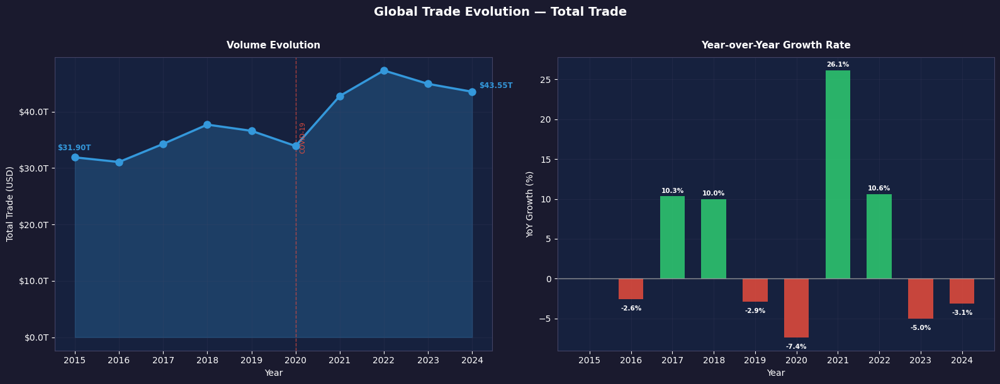

2015: $31.90T | 2024: $43.55T | CAGR: 3.5%


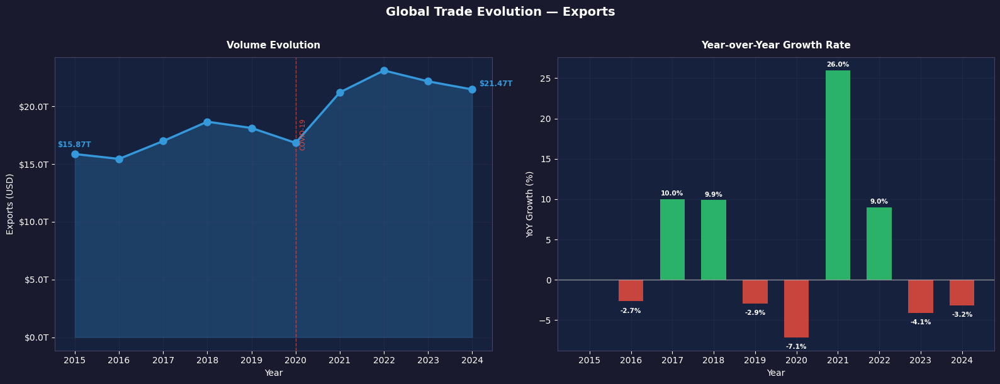

2015: $15.87T | 2024: $21.47T | CAGR: 3.4%


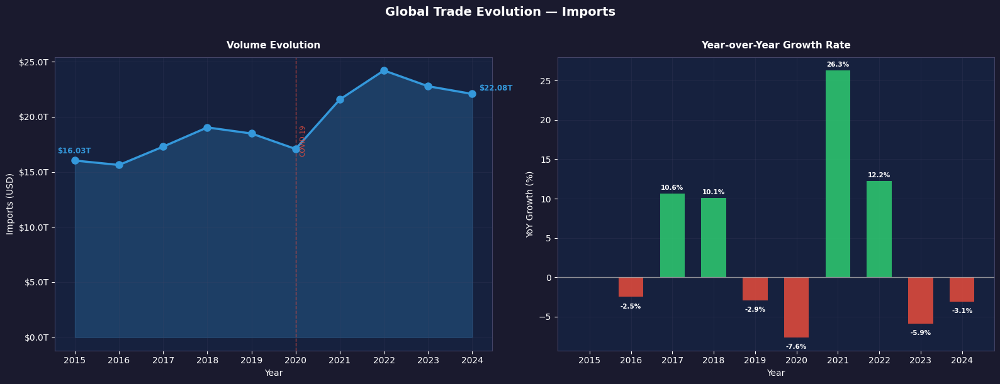

2015: $16.03T | 2024: $22.08T | CAGR: 3.6%


In [67]:
for metric in ['total_trade', 'X', 'M']:    global_trade_evolution(df_trade, metric)

- Global trade expanded significantly over 2015–2024, with the **2020 COVID-19
  shock** causing the sharpest single-year contraction in the period,
  followed by a strong rebound in 2021–2022.
- Exports and imports track closely over time, confirming the structural
  symmetry of global trade flows — divergences signal demand or supply shocks.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.3 Global Trade Distribution
</div>

In [70]:
def plot_top_trading_countries(df_trade, metric, n=15, year=None):
    """   Top N countries by trade volume + cumulative share  """

    metric_labels = {'total_trade': 'Total Trade', 'X': 'Exports', 'M': 'Imports'}
    label = metric_labels.get(metric, metric)
    colors = plt.cm.RdYlGn(np.linspace(0.2, 0.9, n))
    if year is None:   df_plot = df_trade.groupby('country_name')[metric].sum()
    else:   df_plot = df_trade[df_trade['year']==year].groupby('country_name')[metric].sum()

    top = df_plot.nlargest(n).sort_values(ascending=True).reset_index()
    top['share']      = top[metric] / df_plot.sum() * 100
    top['cumulative'] = top['share'].cumsum()
    total_share       = top['share'].sum()

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 8))
    
    # ax1 — Barres volume
    x_max = top[metric].max() / 1e12 * 1.35
    bars  = ax1.barh(range(n), top[metric]/1e12,
                     color=colors, edgecolor='none', height=0.6, zorder=2)
    ax1.set_xlim(0, x_max)
    ax1.set_yticks(range(n))
    ax1.set_yticklabels(top['country_name'], fontsize=9, color='white')
    ax1.set_xlabel(f'{label} (Trillion USD)', fontsize=10)
    ax1.set_title(f'Top {n} — {label} Volume', fontsize=11, pad=10)
    
    for bar, val, share in zip(bars, top[metric]/1e12, top['share']):
        ax1.text(val + x_max * 0.01,
                 bar.get_y() + bar.get_height()/2,
                 f'${val:.1f}T ({share:.1f}%)',
                 va='center', fontsize=7.5, color='white', fontweight='bold')
    style_grid(ax1)
    
    # ax2 — Cumulative line
    ax2.plot(top['cumulative'], range(n),
             color='#f1c40f', linewidth=2, marker='o', markersize=5, zorder=3)
    ax2.axvline(x=50, color='#f39c12', linewidth=0.8,
                linestyle='--', alpha=0.7, label='50%')
    ax2.axvline(x=80, color='#e74c3c', linewidth=0.8,
                linestyle='--', alpha=0.7, label='80%')
    ax2.set_xlim(0, 105)
    ax2.set_yticks(range(n))
    ax2.set_yticklabels(top['country_name'], fontsize=9, color='white')
    ax2.set_xlabel('Cumulative Share (%)', fontsize=10)
    ax2.set_title('Cumulative Share', fontsize=11, pad=10)
    style_grid(ax2)
    add_legend(ax2, loc='lower right', fontsize=7)

    save_figure(fig, f'../Figures/Trade/F_2_3_top_trading_countries_{metric}.png')

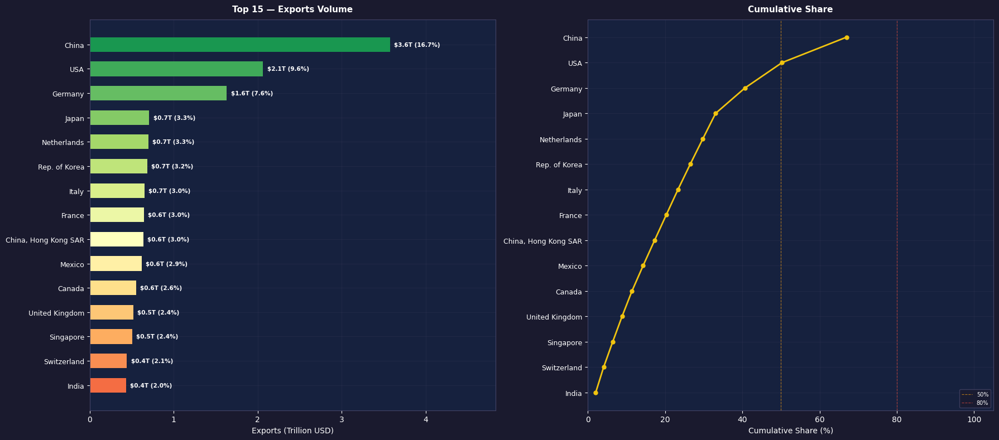

In [71]:
plot_top_trading_countries(df_trade, 'X', n=15, year=2024)

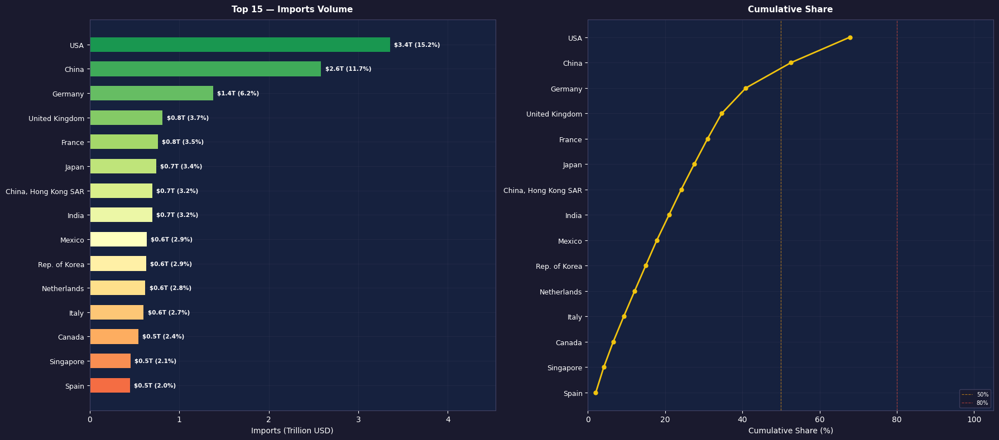

In [72]:
plot_top_trading_countries(df_trade, 'M', n=15, year=2024)

- Global trade follows a **Power Law distribution** — the top 3 countries
  (USA, Germany, China) alone account for over 30% of global imports,
  while the remaining 12 in the top 15 share the rest.
- The cumulative curve confirms that **50% of global trade is controlled
  by fewer than 6 countries** — a structural asymmetry that persists across years.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.4 Global Trade Balance Structure
</div>

In [77]:
def plot_trade_balance_analysis(df_trade, year=None, n=10):
    """     Butterfly chart : Top surplus vs Top deficit      """

    if year is None:
        df_agg = df_trade.groupby('country_name')['trade_balance'].median()
        title_suffix = 'Full Period (Median)'
    else:
        df_agg = df_trade[df_trade['year']==year].groupby('country_name')['trade_balance'].sum()
        title_suffix = str(year)

    top_surplus = df_agg.nlargest(n).reset_index()
    top_deficit = df_agg.nsmallest(n).reset_index()
    display(top_deficit)
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle(f'Global Trade Balance Structure — {title_suffix}', fontsize=14, fontweight='bold', color='white', y=1.01)

    for ax, df_plot, color, title in [(ax1, top_surplus.sort_values('trade_balance'),'#2ecc71', f'Top {n} Surplus Countries'),
        (ax2, top_deficit.sort_values('trade_balance', ascending=False),'#e74c3c', f'Top {n} Deficit Countries'),]:
        vals = df_plot['trade_balance'] / 1e9
        bars = ax.barh(df_plot['country_name'], vals, color=color, alpha=0.85, edgecolor='none', height=0.6, zorder=2)

        for bar, val in zip(bars, vals):
            ax.text(val + (-1 if val > 0 else 1), bar.get_y() + bar.get_height()/2, f'${abs(val):.0f}B',
                    va='center', ha='right' if val > 0 else 'left', fontsize=9, color='white', fontweight='bold')
        ax.axvline(x=0, color='#aaaaaa', linewidth=1.0, alpha=0.8)
        ax.set_xlabel('Trade Balance (Billion USD)', fontsize=10)
        ax.set_title(title, fontsize=11, pad=10)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${abs(x):.0f}B'))
        style_grid(ax)

    save_figure(fig, f'../Figures/Trade/F_2_4_trade_balance_{year if year else "full"}.png')

,country_name,trade_balance
0,USA,-1293009890207.0000
1,United Kingdom,-293180216538.3729
2,India,-263309635931.0440
3,France,-116085624313.7230
4,Turkiye,-82232142214.0000
5,Philippines,-61897170645.0000
6,"China, Hong Kong SAR",-58493319542.2980
7,Egypt,-49851100122.5570
8,Spain,-47600195046.8650
9,Romania,-36148481838.1900


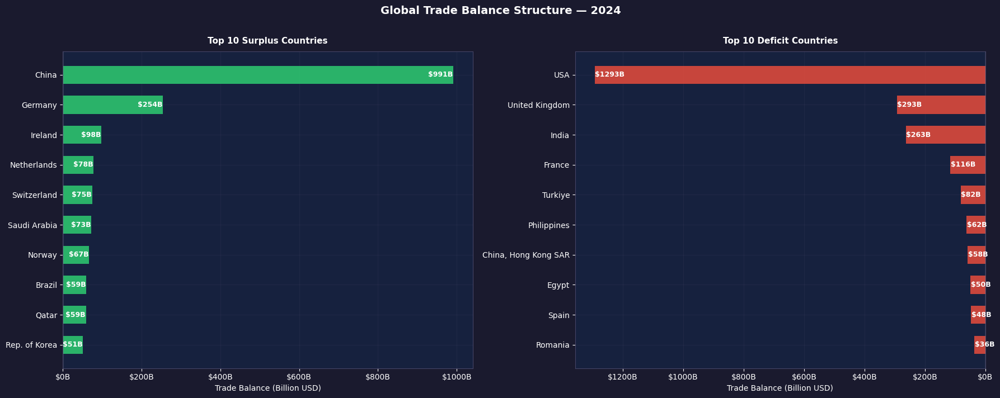

In [78]:
plot_trade_balance_analysis(df_trade, year=2024, n=10)

- Surplus countries are predominantly **manufacturing exporters**
  (China, Germany) and **energy exporters** (Norway, Saudi Arabia, Qatar),
  while deficit countries are **consumption-driven economies** (USA, UK, France).
- Trade imbalances are **structurally persistent** — the same countries
  appear year after year on both sides, confirming that balance profiles
  reflect deep economic specialization rather than cyclical fluctuations.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.5 Global Trade Concentration
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.5.1 Top3 / Top5 / Top10 Concentration
</div>

In [83]:
def concentration_ratio(df_trade, n):
    return (df_trade.sort_values("export_share", ascending=False).head(n)["export_share"].sum())

concentration_results = []
for year in df_trade["year"].unique():
    df_year = df_trade[df_trade["year"] == year]   
    top3 = concentration_ratio(df_year, 3)
    top5 = concentration_ratio(df_year, 5)
    top10 = concentration_ratio(df_year, 10)
    concentration_results.append({"year": year, "top3_share": top3, "top5_share": top5, "top10_share": top10})
df_concentration = pd.DataFrame(concentration_results).sort_values("year")
df_concentration.sample()

,year,top3_share,top5_share,top10_share
0,2015,32.1639,39.4214,54.4986


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.5.2 HHI
</div>

In [87]:
hhi_results = []
for year in df_trade["year"].unique():
    df_year = df_trade[df_trade["year"] == year]
    hhi = (df_year["export_share"] ** 2).sum()
    hhi_results.append({"year": year, "hhi_global": hhi})
df_hhi = pd.DataFrame(hhi_results).sort_values("year")
df_hhi.sample()

,year,hhi_global
4,2019,471.1860


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.5.3 Global Trade Hierarchy Stability (Rank Correlation)
</div>

It is essential to assess whether the global trade hierarchy remains stable over time.
A structurally stable system suggests entrenched economic dominance, while significant rank volatility may indicate geopolitical or structural shift

We measure how similar the ranking structure is from one year to the next using Rank correlation analysis (Spearman correlation)

In [93]:
rank_stability = []
years = sorted(df_trade["year"].unique())
for i in range(1, len(years)):
    year_t = years[i]
    year_t_1 = years[i - 1]
    df_t = df_trade[df_trade["year"] == year_t][["country_name", "rank"]]
    df_t_1 = df_trade[df_trade["year"] == year_t_1][["country_name", "rank"]]
    merged = df_t.merge(df_t_1, on="country_name", suffixes=("_t", "_t1"))
    corr, _ = spearmanr(merged["rank_t"], merged["rank_t1"])
    rank_stability.append({"year": year_t, "spearman_correlation": corr })
df_rank_stability = pd.DataFrame(rank_stability)
df_rank_stability.tail(1)

,year,spearman_correlation
8,2024,0.9972


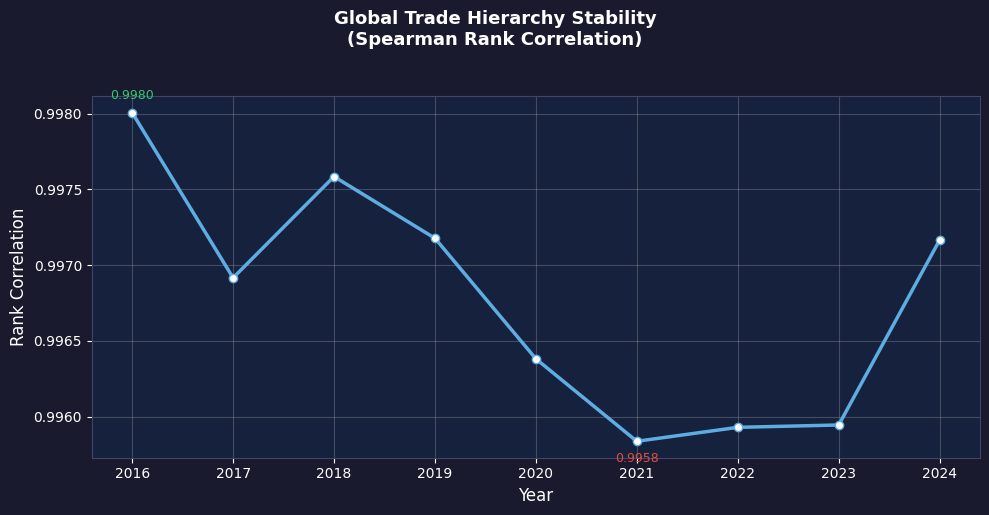

In [95]:
def plot_hierarchy_stability(df_rank_stability):
    fig, ax = styled_subplots(nrows=1, ncols=1, figsize=(10, 5))
    fig.suptitle('Global Trade Hierarchy Stability\n(Spearman Rank Correlation)',
                 fontsize=13, fontweight='bold', color='white', y=1.02)

    years = df_rank_stability['year'].tolist()
    corr  = df_rank_stability['spearman_correlation'].tolist()

    ax.plot(years, corr, color='#5dade2', linewidth=2.5, marker='o',
            markersize=6, markerfacecolor='white', markeredgecolor='#5dade2')

    # Annotate min and max
    idx_min = corr.index(min(corr))
    idx_max = corr.index(max(corr))
    ax.annotate(f'{corr[idx_min]:.4f}', xy=(years[idx_min], corr[idx_min]), xytext=(0, -15), 
                textcoords='offset points', color='#e74c3c', fontsize=9, ha='center')
    ax.annotate(f'{corr[idx_max]:.4f}', xy=(years[idx_max], corr[idx_max]), xytext=(0, 10), 
                textcoords='offset points', color='#2ecc71', fontsize=9, ha='center')

    ax.set_xlabel('Year', color='white')
    ax.set_ylabel('Rank Correlation', color='white')
    ax.set_xticks(years)

    plt.tight_layout()
    save_figure(fig, '../Figures/Trade/F_2_5_3_global_hierarchy_stability.png')
    
    plt.show()

plot_hierarchy_stability(df_rank_stability)

**Structural Interpretation:**

Spearman rank correlation measures how similar export rankings remain from one year to the next.

- Correlation close to 1 → highly stable hierarchy /  Moderate correlation → gradual structural shifts /  Low correlation → systemic reordering
- If global trade concentration is high and hierarchy stability is strong, this indicates a structurally entrenched system dominated by persistent leaders.
- If concentration is high but hierarchy is unstable, this suggests competitive reallocation among major economies.
- Hierarchy stability therefore complements concentration metrics in evaluating systemic rigidity versus transformation.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.5.4 Concentration Synthesis
</div>

In [99]:
df_concentration = df_concentration.merge(df_hhi, on = "year", how = "left").merge(df_rank_stability, on = "year", how = "left")
df_concentration.sample()

,year,top3_share,top5_share,top10_share,hhi_global,spearman_correlation
5,2020,32.1065,39.1916,53.8600,505.1967,0.9964


In [101]:
def plot_trade_concentration(df_trade, df_concentration, df_hhi):
    """   Concentration ratios + HHI   """

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(16, 6))
    fig.suptitle('Global Trade Concentration — Top N Shares & HHI', fontsize=14, fontweight='bold', color='white', y=1.01)

    # ── LEFT : Concentration ratios ───────────────────────────────────────────
    for col, color, label in [('top3_share',  '#e74c3c', 'Top 3'), ('top5_share',  '#f39c12', 'Top 5'), ('top10_share', '#2ecc71', 'Top 10'),]:
        ax1.plot(df_concentration['year'], df_concentration[col] , marker='o', linewidth=2, markersize=5, color=color, label=label)
        annotate_endpoints(ax1, df_concentration['year'], df_concentration[col], color, fmt='.1%')

    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel('Share of Global Exports (%)', fontsize=10)
    ax1.set_title('Concentration Ratios — Top N Share', fontsize=11, pad=10)
    ax1.set_xticks(df_concentration['year'])
    style_grid(ax1)
    add_legend(ax1, loc='best')

    # ── RIGHT : HHI ───────────────────────────────────────────────────────────
    ax2.plot(df_hhi['year'], df_hhi['hhi_global'], color='#3498db', linewidth=2.5, marker='o', markersize=6, zorder=3)
    ax2.fill_between(df_hhi['year'], df_hhi['hhi_global'], alpha=0.20, color='#3498db')

    # HHI reference lines
    for y_val, color, label in [(0.10, '#e74c3c', 'High Concentration'), (0.05, '#f39c12', 'Moderate'),]:
        ax2.axhline(y=y_val, color=color, linewidth=0.8, linestyle='--', alpha=0.7, label=label)

    annotate_endpoints(ax2, df_hhi['year'], df_hhi['hhi_global'], '#3498db', fmt='.4f')
    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('HHI', fontsize=10)
    ax2.set_title('Global HHI — Export Concentration', fontsize=11, pad=10)
    ax2.set_xticks(df_hhi['year'])
    style_grid(ax2)
    add_legend(ax2, loc='best')

    save_figure(fig, '../Figures/Trade/F_2_5_global_trade_concentration.png')

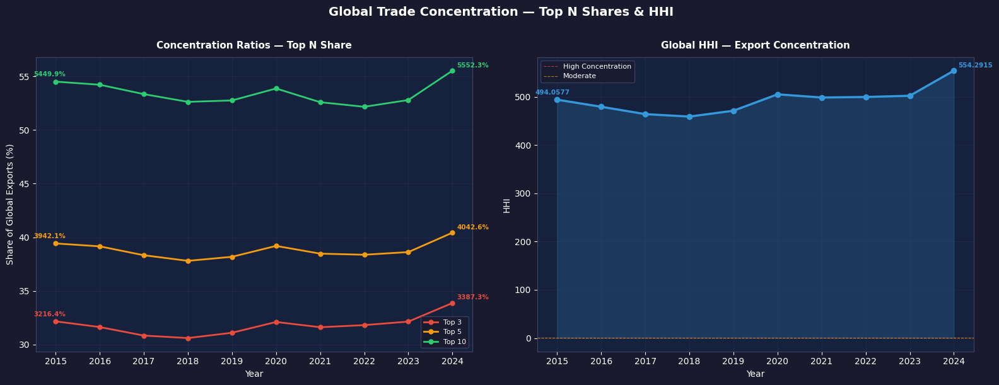

In [103]:
plot_trade_concentration(df_trade, df_concentration, df_hhi)

- **Trade is highly concentrated** — The top 10 countries consistently control **55–60% of global exports**,
  confirming the structurally asymmetric nature of globalization — trade
  power is heavily concentrated among a handful of economies.

- **The major finding** : Global trade was on a clear **de-concentration trend
  from 2015 to 2019** (HHI declining from ~750 to ~400), reflecting genuine
  trade diversification and the rise of new exporters. COVID-19 brutally
  interrupted this trend in 2020, forcing a **flight to safety toward dominant
  producers** — only large economies like China could sustain export capacity
  during global lockdowns.

- Since 2021, concentration has stabilized at an **intermediate plateau** —
  neither returning to pre-2019 diversification nor reaching crisis-level
  concentration. This signals a structural arrest of de-globalization
  rather than a full reversal.

- By **DOJ standards** (HHI < 1500 = competitive market), global trade remains
  structurally diversified — but the COVID shock revealed how fragile
  that diversification is under systemic stress.


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.5.5 Save Table
</div>

In [107]:
df_concentration.to_csv("../Analysis_files/Trade/df_concentration.csv", index=False)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 2.6 Global Trade Volatility
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.6.1 Volatility
</div>

In [111]:
def plot_volatility_world_map(df_trade_dynamic, metric='volatility_export'):
    """  World map volatility    """
    
    label = metric.replace('_', ' ').title()
    cap_val = df_trade_dynamic["volatility_export"].quantile(0.95)
    fig = px.choropleth(df_trade_dynamic, locations='country_name', locationmode='country names', color=metric, hover_name='country_name',
        hover_data={'volatility_export': ':.2f','volatility_import': ':.2f'}, title=f'<b>World Trade Volatility — {label}</b>',
        color_continuous_scale='Reds', range_color=[0, cap_val], width=1100, height=550)
    fig.update_layout(paper_bgcolor='#1a1a2e', plot_bgcolor='#16213e', font=dict(color='white'),
                      geo=dict(bgcolor='#16213e', showframe=False, showcoastlines=True, coastlinecolor='#444466', showland=True, landcolor='#2a2a4a',
                               showocean=True, oceancolor='#16213e', showlakes=False),
                      coloraxis_colorbar=dict(title=label, tickfont=dict(color='white'), titlefont=dict(color='white')),
                      title_font=dict(color='white', size=15), title_x=0.5)
    
    fig.write_html("../Figures/Trade/F_2_6_1_world_map_volatility.html", include_plotlyjs='cdn')
    fig.show()

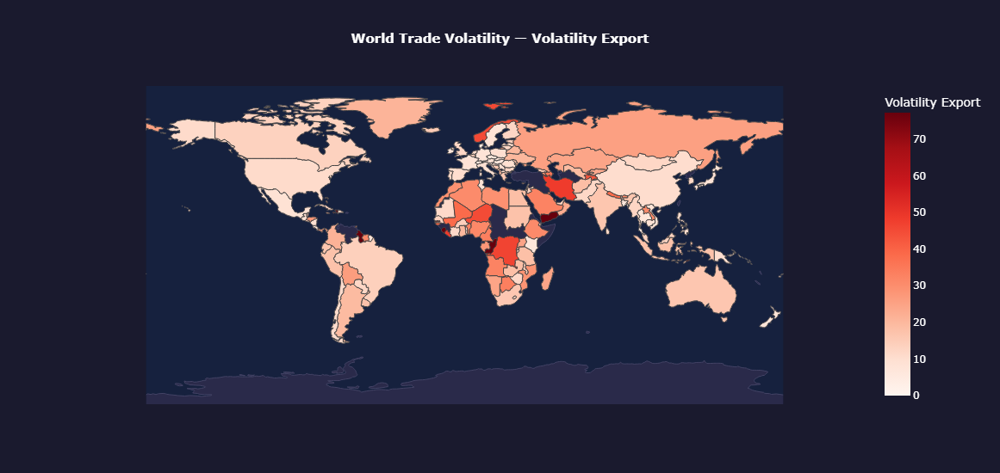

In [113]:
plot_volatility_world_map(df_trade_dynamic)

In [114]:
def plot_volatility_matrix(df_trade_dynamic, countries=None):

    df = df_trade_dynamic[['country_name', 'volatility_export', 'volatility_import']].copy()
    if countries:
        df_high = df[df['country_name'].isin(countries)]
        df_low  = df[~df['country_name'].isin(countries)]
    else:
        df_high = df
        df_low  = pd.DataFrame()

    fig, ax = styled_figure(figsize=(10, 6))
    ax.set_title('Volatility Matrix — Export vs Import Volatility\n' 'Above diagonal: Import more volatile | Below: Export more volatile',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # All countries background
    if not df_low.empty:
        ax.scatter(df_low['volatility_export'], df_low['volatility_import'], color='#aaaaaa', s=20, alpha=0.3, edgecolors='none', zorder=1)

    # Highlighted countries
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries or df['country_name'].tolist())}

    for _, row in df_high.iterrows():
        c = color_map.get(row['country_name'], '#3498db')
        ax.scatter(row['volatility_export'], row['volatility_import'], color=c, s=80, edgecolors='white', linewidths=0.8, zorder=3)
        ax.annotate(row['country_name'], xy=(row['volatility_export'], row['volatility_import']), xytext=(6, 3), textcoords='offset points',
                    fontsize=8, color=c, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'))

    # Diagonal
    max_val = max(df['volatility_export'].max(), df['volatility_import'].max())
    ax.plot([0, max_val], [0, max_val], color='#aaaaaa', linewidth=0.8, linestyle='--', alpha=0.6, label='Export Volatility = Import Volatility')

    ax.set_xlabel('Export Volatility', fontsize=10)
    ax.set_ylabel('Import Volatility', fontsize=10)
    ax.set_xlim(0, 50)
    ax.set_ylim(0, 35)
    style_grid(ax)
    add_legend(ax, loc='upper left')

    save_figure(fig, '../Figures/Trade/F_2_6_1_volatility_matrix.png')

In [115]:
countries=["USA", "China", "France", "Tunisia", "Morocco", "Egypt", "Qatar", "Canada"]

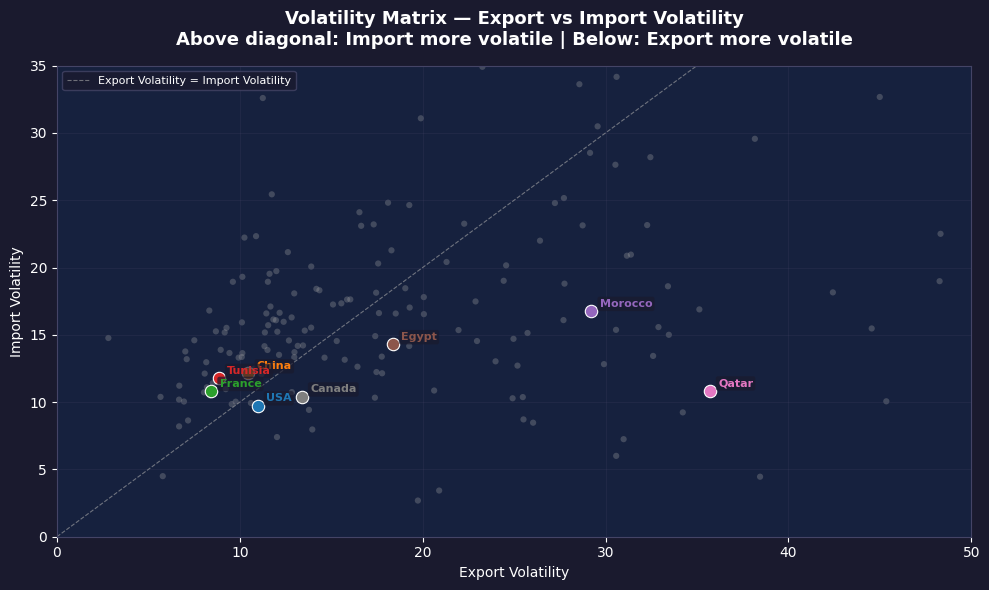

In [116]:
plot_volatility_matrix(df_trade_dynamic, countries)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 2.6.2 Countries risk (volatility vs growth)
</div>

In [121]:
def plot_stability_matrix(df_trade_dynamic, countries=None):
    """   risk matrix (quadrant) volatility vs growth """
    
    df = df_trade_dynamic[df_trade_dynamic['years_export'] >= 5][['country_name', 'avg_growth_export','volatility_export', 'total_export']].dropna().copy()
    median_growth = df['avg_growth_export'].median()
    median_vol    = df['volatility_export'].median()

    # Quadrant classification
    def get_quadrant(row):
        if row['avg_growth_export'] >= median_growth and   row['volatility_export'] <= median_vol:            return 'Stable Stars'
        elif row['avg_growth_export'] >= median_growth and row['volatility_export'] > median_vol:             return 'Boom-Bust'
        elif row['avg_growth_export'] < median_growth and  row['volatility_export'] <= median_vol:            return 'Mature'
        else:                                                                                                 return 'Vulnerable'

    df['quadrant'] = df.apply(get_quadrant, axis=1)

    quad_colors = {'Stable Stars':'#2ecc71', 'Boom-Bust':'#f1c40f', 'Mature':'#3498db', 'Vulnerable':'#e74c3c'}

    fig, ax = styled_figure(figsize=(14, 10))
    ax.set_title('Trade Risk-Return Matrix — Growth vs Volatility\n' 'Size: Total Export Volume', fontsize=13, fontweight='bold', color='white', pad=15)
    ax.set_xlim (-10, 40)
    ax.set_ylim (0, 60)
    # Plot by quadrant
    for quad, color in quad_colors.items():
        df_q = df[df['quadrant'] == quad]
        ax.scatter(df_q['avg_growth_export'], df_q['volatility_export'], s=df_q['total_export'] / df['total_export'].max() * 500 + 20,
                   color=color, alpha=0.5, edgecolors='none', zorder=1, label=f'{quad} ({len(df_q)})')

    # Highlighted countries
    if countries:
        df_high = df[df['country_name'].isin(countries)]
        colors_list = plt.cm.tab10.colors
        color_map   = {c: colors_list[i % 10] for i, c in enumerate(countries)}

        for _, row in df_high.iterrows():
            c = color_map.get(row['country_name'], 'white')
            ax.scatter(row['avg_growth_export'], row['volatility_export'], s=row['total_export'] / df['total_export'].max() * 500 + 80,
                       color=c, edgecolors='white', linewidths=1.2, zorder=4)
            ax.annotate(row['country_name'], xy=(row['avg_growth_export'], row['volatility_export']), xytext=(8, 4), textcoords='offset points',
                        fontsize=8, color=c,fontweight='bold',bbox=dict(boxstyle='round,pad=0.2',facecolor='#1a1a2e',alpha=0.7,edgecolor='none'),zorder=5)

    # Median lines
    ax.axvline(x=median_growth, color='white', linewidth=1.2, linestyle='--', alpha=0.7)
    ax.axhline(y=median_vol, color='white', linewidth=1.2, linestyle='--', alpha=0.7)

    # Quadrant labels
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    for label, x, y, color in \
        [('Stable Stars\n(High Growth\nLow Volatility)', median_growth + (xlim[1]-median_growth)*0.6, ylim[0] + (median_vol-ylim[0])*0.3, '#2ecc71'),
        ('Boom-Bust\n(High Growth\nHigh Volatility)', median_growth + (xlim[1]-median_growth)*0.6, median_vol + (ylim[1]-median_vol)*0.7, '#f1c40f'),
        ('Mature\n(Low Growth\nLow Volatility)', xlim[0] + (median_growth-xlim[0])*0.3, ylim[0] + (median_vol-ylim[0])*0.3, '#3498db'),
        ('Vulnerable\n(Low Growth\nHigh Volatility)', xlim[0] + (median_growth-xlim[0])*0.3, median_vol + (ylim[1]-median_vol)*0.7, '#e74c3c')]:
        
        ax.text(x, y, label, fontsize=8, color=color, ha='center', va='center', fontstyle='italic', bbox=dict(boxstyle='round,pad=0.3',
                          facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))

    ax.set_xlabel('Average Export Growth (%)', fontsize=10)
    ax.set_ylabel('Export Volatility', fontsize=10)
    
    style_grid(ax)
    add_legend(ax, loc='upper right', fontsize=8)

    save_figure(fig, '../Figures/Trade/F_2_6_2_stability_matrix.png')

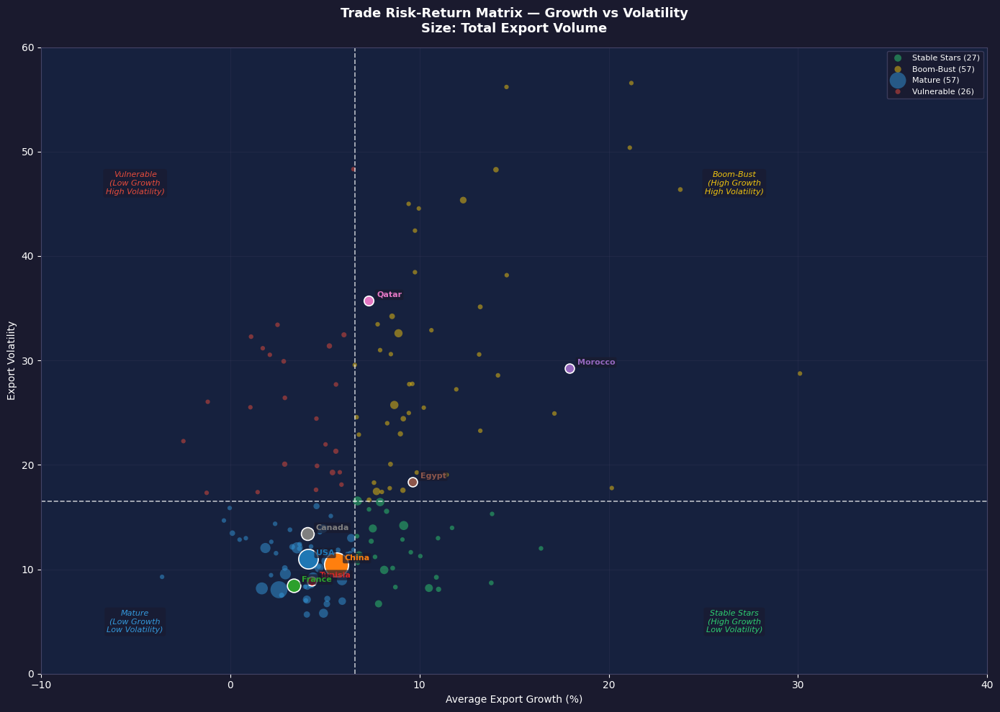

In [122]:
plot_stability_matrix(df_trade_dynamic, countries)

- **Volatility is geographically concentrated** — commodity-dependent economies
  (Sub-Saharan Africa, Middle East) show systematically higher export volatility
  than diversified economies, reflecting structural dependence on price-volatile
  raw materials.

- **Import and export volatility are correlated** — countries above the diagonal
  face greater supply-side instability than demand-side, signaling procurement
  vulnerability.

- **The Risk-Return Matrix reveals four structural profiles** :
  Stable Stars (high growth + low volatility) represent the most resilient
  exporters; Vulnerable countries (low growth + high volatility) face the
  highest structural risk and are the most exposed to external shocks.


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### Test
</div>

In [209]:
df_trade_dynamic.sample()
df_trade_dynamic[['country_name', 'volatility_export', 'volatility_import']].sort_values("volatility_export", ascending = False).head(5)
df_trade[(df_trade["year"]==2023) & (df_trade["country_name"]=="Germany")][["country_name", "country_code",  "M", "X"]].sort_values("M", ascending=False)
df_trade[df_trade["country_name"]=="Malawi"][["country_code","year", "M", "X"]]
df_trade[df_trade["country_code"]==792]
df_trade[df_trade["country_name"]=="France"][["country_name","year", "total_trade","M","X"]].style.format(_format_value, subset=["total_trade","M","X"])

,country_name,total_export,total_import,avg_growth_export,avg_growth_import,cagr_export,cagr_import,volatility_export,volatility_import,years_export,...,negfreq_export,negfreq_import,z_cagr_export,z_cagr_import,z_volatility_export,z_volatility_import,z_negfreq_export,z_negfreq_import,resilience_export,resilience_import
63,France,5619761123131.3232,6723204485494.1338,3.3395,3.9005,0.0303,0.0341,8.4367,10.8208,9,...,0.4000,0.5000,-0.2817,-0.2429,-0.3244,-0.7399,0.4721,1.2166,-0.4294,-0.7197


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Country Trade Structure
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.1 Country Data
</div>

In [127]:
# ── Demo country — change to any country in the dataset ──
country = "USA"

In [129]:
def country_data(country:str, df:pd.DataFrame = df_trade):
    df_country = df_trade[df_trade["country_name"] == country]
    df_MX = df_country.melt(id_vars=["year"], value_vars=["M", "X"], var_name="Flow", value_name="value")
    df_MX["value_B"] = df_MX["value"] / 1e9
    df_Share = df_country.melt(id_vars=["year"], value_vars=["import_share", "export_share"], var_name="Flow", value_name="Share")
    return df_country, df_MX, df_Share

In [131]:
df_country, df_MX, df_Share =  country_data(country)

In [133]:
df_country.sample().style.format(_format_value, subset=[col for col in df_trade.columns if col not in ["flow_code", "country_name", "country_code", "country_iso3",	"year"]])

,country_name,country_code,country_iso3,year,M,X,M_Sum,X_Sum,total_trade,trade_balance,coverage_ratio,import_share,export_share,rank,trade_balance_B,import_growth,export_growth,balance_growth,export_share_growth,import_share_growth
1570,USA,842,USA,2016,2.25T,1.45T,15.63T,15.45T,3.70T,-796.26B,0.65,14.37,9.39,2.00,-796.26,-2.86,-3.39,-1.89,-0.75,-0.39


In [135]:
df_MX.sample().style.format(_format_value, subset=["value"])

,year,Flow,value,value_B
6,2021,M,2.93T,2932.976075


In [137]:
df_Share.sample()

,year,Flow,Share
12,2017,export_share,9.0981


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.2 Export / Import Trends
</div>

In [140]:
def plot_trend_country(df_country, country):
    """     Export/Import Trends    Line chart with fill between + annotations    """
    fig, ax = styled_figure(figsize=(14, 6))
    ax.set_title(f'Imports and Exports Evolution — {country}',  fontsize=14, fontweight='bold', color='white', pad=15)

    # Lines
    ax.plot(df_country['year'], df_country['X'], marker='o', linewidth=2.5, markersize=6, color='#f39c12', label='Exports', zorder=3)
    ax.plot(df_country['year'], df_country['M'], marker='o', linewidth=2.5, markersize=6, color='#3498db', label='Imports', zorder=3)

    # Fill between
    ax.fill_between(df_country['year'], df_country['X'], df_country['M'], where=df_country['X'] > df_country['M'], color='#2ecc71', alpha=0.15, label='Surplus zone')
    ax.fill_between(df_country['year'], df_country['X'], df_country['M'], where=df_country['X'] <= df_country['M'],color='#e74c3c', alpha=0.15, label='Deficit zone')

    # Annotations last point
    for col, color, label in [('X', '#f39c12', 'X'), ('M', '#3498db', 'M')]:
        val = df_country[col].iloc[-1]
        yr  = df_country['year'].iloc[-1]
        ax.annotate(_format_value(val), xy=(yr, val), xytext=(8, 4), textcoords='offset points', fontsize=8, color=color, fontweight='bold')

    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Value (USD)', fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax.set_xticks(df_country['year'])
    style_grid(ax)
    add_legend(ax, loc='upper left')

    save_figure(fig, f'../Figures/Trade/F_3_2_export_import_trend_{country}.png')

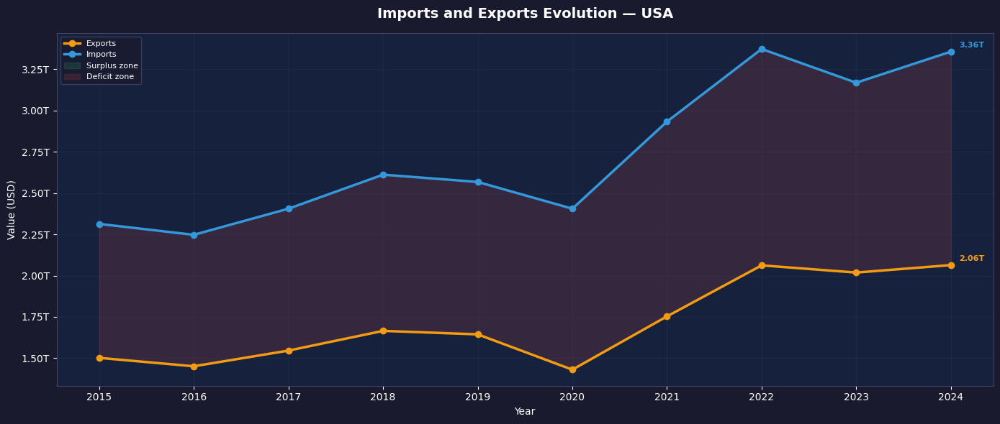

In [142]:
plot_trend_country(df_country, country)

The absolute volume trend reveals the structural trajectory of a country's
trade integration. A persistent gap between imports and exports signals
a structural trade orientation — either export-led growth or consumption-driven
dependency — that is rarely reversed in the short term.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.3 Export Share/ Import Share Trends
</div>

In [146]:
def plot_share_country(df_country, country):
    """    Export/Import Share Trends    Line chart : import_share vs export_share evolution    """
    fig, ax = styled_figure(figsize=(14, 6))
    ax.set_title(f'Share Imports and Share Exports Evolution — {country}', fontsize=14, fontweight='bold', color='white', pad=15)

    for col, color, label in [('import_share', '#3498db', 'Import Share'), ('export_share', '#f39c12', 'Export Share'),]:
        ax.plot(df_country['year'], df_country[col], marker='o', linewidth=2.5, markersize=6, color=color, label=label, zorder=3)

        # Annotate first and last
        for idx, offset in [(0, (-25, 6)), (-1, (5, 4))]:
            val = df_country[col].iloc[idx]
            yr  = df_country['year'].iloc[idx]
            ax.annotate(f'{_format_value(val)}%', xy=(yr, val), xytext=offset, textcoords='offset points', fontsize=8, color=color, fontweight='bold')

    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('%', fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{_format_value(x)}%'))
    ax.set_xticks(df_country['year'])
    style_grid(ax)
    add_legend(ax, loc='best')

    save_figure(fig, f'../Figures/Trade/F_3_3_share_export_import_trend_{country}.png')

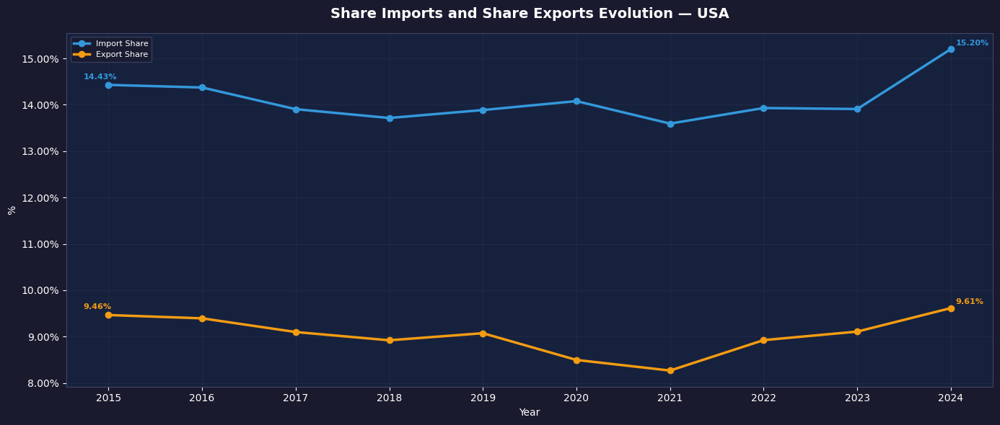

In [148]:
plot_share_country(df_country, country)

Export and import shares measure a country's weight within the global
trade system, independently of absolute volume growth. A declining share
despite rising volumes indicates that the country is growing slower than
the world average — losing relative competitive ground even while expanding.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.4 Trade Balance
</div>

In [152]:
def plot_balance_country(df_country, country):
    """    Trade Balance : Balance evolution & Coverage ratio + Global Trade Power (Import vs Export fill)    """
    
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle(f'Trade Balance Analysis — {country}', fontsize=14, fontweight='bold', color='white', y=1.01)

    # Balance + Coverage ratio 
    ax1.fill_between(df_country['year'], df_country['trade_balance'], 0, where=df_country['trade_balance'] >= 0, color='#2ecc71', alpha=0.3, label='Surplus')
    ax1.fill_between(df_country['year'], df_country['trade_balance'], 0, where=df_country['trade_balance'] < 0, color='#e74c3c', alpha=0.3, label='Deficit')
    ax1.plot(df_country['year'], df_country['trade_balance'], color='#3498db', linewidth=2.5, marker='o', markersize=5, zorder=3)
    ax1.axhline(y=0, color='#aaaaaa', linewidth=1.0, linestyle='--', alpha=0.7)

    ## Annotate last value
    last_bal = df_country['trade_balance'].iloc[-1]
    ax1.annotate(_format_value(last_bal), xy=(df_country['year'].iloc[-1], last_bal), xytext=(8, 4), textcoords='offset points', fontsize=8, color='white', fontweight='bold')

    ## Coverage ratio on secondary axis
    ax1_twin = add_twin_axis(ax1)
    ax1_twin.plot(df_country['year'], df_country['coverage_ratio'], color='#f1c40f', linewidth=1.5, marker='s', markersize=4, linestyle='--', label='Coverage Ratio', alpha=0.8)
    ax1_twin.axhline(y=1.0, color='#f1c40f', linewidth=0.8, linestyle=':', alpha=0.6)
    ax1_twin.set_ylabel('Coverage Ratio (X/M)', fontsize=9)
    ax1_twin.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    add_legend(ax1_twin, loc='best', fontsize=7)

    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel('Trade Balance (USD)', fontsize=10)
    ax1.set_title('Trade Balance & Coverage Ratio', fontsize=11, pad=10)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax1.set_xticks(df_country['year'])
    style_grid(ax1)
    add_legend(ax1, loc='best', fontsize=7)

    # Global Trade Power
    ax2.plot(df_country['year'], df_country['M'], color='#3498db', linewidth=2.5, marker='o', markersize=5, label='Imports', zorder=3)
    ax2.plot(df_country['year'], df_country['X'], color='#2ecc71', linewidth=2.5, marker='o', markersize=5, label='Exports', zorder=3)

    ax2.fill_between(df_country['year'], df_country['M'], df_country['X'], color='#e74c3c', alpha=0.20)

    ## Global shares annotation
    last = df_country.iloc[-1]
    ax2.text(0.4, 0.97, f"Global Import Share: {_format_value(last['import_share'])}%\n"
             f"Global Export Share: {_format_value(last['export_share'])}%\n"
             f"Trade Balance: {_format_value(last['trade_balance'])}",
             transform=ax2.transAxes, fontsize=9, color='white', va='top', bbox=dict(boxstyle='round,pad=0.4', facecolor='#1a1a2e', alpha=0.8, edgecolor='#444466'))

    ## Annotate last points
    for col, color in [('M', '#3498db'), ('X', '#2ecc71')]:
        val = df_country[col].iloc[-1]
        ax2.annotate(_format_value(val), xy=(df_country['year'].iloc[-1], val), xytext=(8, 4), textcoords='offset points', fontsize=8, color=color, fontweight='bold')

    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('Value (USD)', fontsize=10)
    ax2.set_title('Global Trade Power', fontsize=11, pad=10)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax2.set_xticks(df_country['year'])
    style_grid(ax2)
    add_legend(ax2, loc='best', fontsize=8)

    save_figure(fig, f'../Figures/Trade/F_3_4_trade_balance_{country}.png')

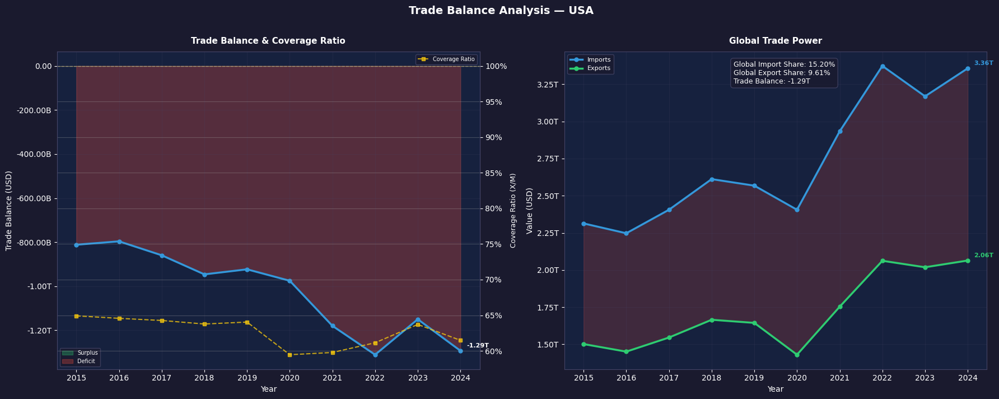

In [154]:
plot_balance_country(df_country, country)

The trade balance and coverage ratio together reveal the structural
orientation of an economy. A persistent deficit signals structural import dependency, while a rising coverage
ratio — even with a deficit — indicates improving export competitiveness.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.5 Trade Growth
</div>

Growth measures structural expansion capacity.
Persistent positive growth indicates increasing integration
within the global trade system.

In [159]:
def plot_growth_country(df_country, country):
    """    Trade Growth : Line chart : import_growth vs export_growth - Zero line + fill zones    """
    
    df_g = df_country.dropna(subset=['import_growth', 'export_growth']).copy()
    fig, ax = styled_figure(figsize=(14, 6))
    ax.set_title(f'Annual Import - Export Growth Rate — {country}', fontsize=14, fontweight='bold', color='white', pad=15)

    # Zero reference line
    ax.axhline(y=0, color='#aaaaaa', linewidth=1.0, linestyle='--', alpha=0.7)

    # Fill positive/negative zones
    ax.fill_between(df_g['year'], df_g['export_growth'], 0, where=df_g['export_growth'] >= 0, color='#2ecc71', alpha=0.08)
    ax.fill_between(df_g['year'], df_g['export_growth'], 0, where=df_g['export_growth'] < 0,  color='#e74c3c', alpha=0.08)

    # Lines
    for col, color, label, marker in [('export_growth', '#f39c12', 'Export Growth', 'o'), ('import_growth', '#3498db', 'Import Growth', 's'),]:
        ax.plot(df_g['year'], df_g[col], marker=marker, linewidth=2.5, markersize=6, color=color, label=label, zorder=3)

        # Annotate all points
        for _, row in df_g.iterrows():
            ax.annotate(f"{row[col]:.1f}%", xy=(row['year'], row[col]), xytext=(0, 8 if row[col] >= 0 else -12), textcoords='offset points',
                        fontsize=7, color=color, ha='center', fontweight='bold')

    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Growth (%)', fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax.set_xticks(df_g['year'])
    style_grid(ax)
    add_legend(ax, loc='best')

    save_figure(fig, f'../Figures/Trade/F_3_5_trade_growth_{country}.png')

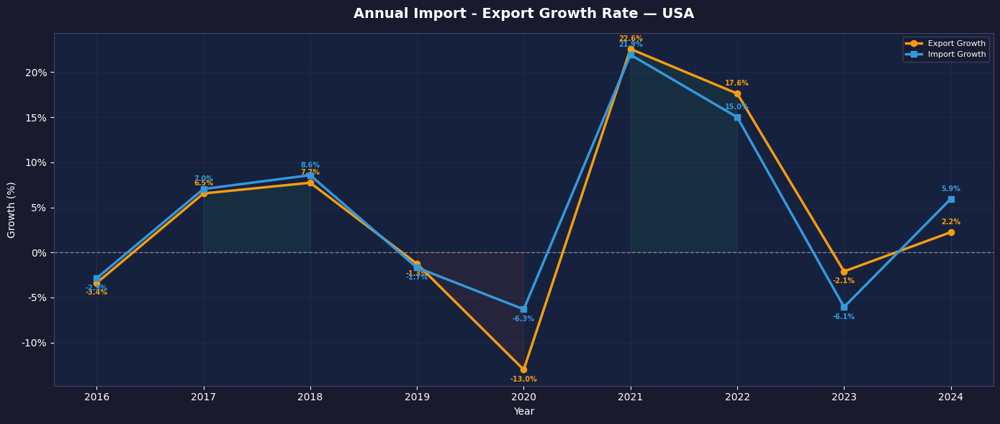

In [161]:
plot_growth_country(df_country, country)

Annual growth rates capture the cyclical sensitivity of trade flows.
The 2020 contraction and 2021 rebound are visible for virtually all
countries, confirming the systemic nature of the COVID shock. Countries
with lower growth volatility around these events demonstrate stronger
structural resilience.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.6 Global Trade View
</div>

In [164]:
def plot_global_view_country(df_country, country):
    """    Global Trade View : 4 subplots : Import/Export | Share | Growth | Balance    """
    df_g = df_country.dropna(subset=['import_growth', 'export_growth']).copy()

    fig, axes = styled_subplots(nrows=2, ncols=2, figsize=(18, 12))
    ax1, ax2, ax3, ax4 = axes.flatten()

    fig.suptitle(f'{country} — Global Trade Profile (Final Overview)', fontsize=16, fontweight='bold', color='white', y=1.01)

    # Import vs Export
    ax1.plot(df_country['year'], df_country['M'], color='#3498db', linewidth=2, marker='o', markersize=4, label='Imports')
    ax1.plot(df_country['year'], df_country['X'], color='#f39c12', linewidth=2, marker='o', markersize=4, label='Exports')
    ax1.annotate(_format_value(df_country['M'].iloc[-1]), xy=(df_country['year'].iloc[-1], df_country['M'].iloc[-1]),
                 xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='#3498db', fontweight='bold')
    ax1.annotate(_format_value(df_country['X'].iloc[-1]), xy=(df_country['year'].iloc[-1], df_country['X'].iloc[-1]),
                 xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='#f39c12', fontweight='bold')
    ax1.set_title('Imports vs Exports', fontsize=11, pad=8)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax1.set_xticks(df_country['year'])
    style_grid(ax1)
    add_legend(ax1, loc='best', fontsize=7)

    # Share
    for col, color, label in [('import_share', '#3498db', 'Import Share'), ('export_share', '#f39c12', 'Export Share'),]:
        ax2.plot(df_country['year'], df_country[col], marker='o', linewidth=2, markersize=4, color=color, label=label)
        ax2.annotate(f"{_format_value(df_country[col].iloc[-1])}%", xy=(df_country['year'].iloc[-1], df_country[col].iloc[-1]), 
                     xytext=(5, 4), textcoords='offset points', fontsize=7.5, color=color, fontweight='bold')
    ax2.set_title('Global Trade Shares (%)', fontsize=11, pad=8)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax2.set_xticks(df_country['year'])
    style_grid(ax2)
    add_legend(ax2, loc='best', fontsize=7)

    # Growth 
    ax3.axhline(y=0, color='#aaaaaa', linewidth=0.8, linestyle='--', alpha=0.7)
    for col, color, label, marker in [('import_growth', '#3498db', 'Import Growth', 's'), ('export_growth', '#f39c12', 'Export Growth', 'o'),]:
        ax3.plot(df_g['year'], df_g[col], marker=marker, linewidth=2, markersize=4, color=color, label=label)
        ax3.annotate(f"{df_g[col].iloc[-1]:.1f}%", xy=(df_g['year'].iloc[-1], df_g[col].iloc[-1]), xytext=(5, 4), textcoords='offset points',
                     fontsize=7.5, color=color, fontweight='bold')
    ax3.set_title('Annual Growth Rates (%)', fontsize=11, pad=8)
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax3.set_xticks(df_g['year'])
    style_grid(ax3)
    add_legend(ax3, loc='best', fontsize=7)

    # Balance
    ax4.fill_between(df_country['year'], df_country['trade_balance'], 0, where=df_country['trade_balance'] >= 0, color='#2ecc71', alpha=0.30)
    ax4.fill_between(df_country['year'], df_country['trade_balance'], 0, where=df_country['trade_balance'] < 0,  color='#e74c3c', alpha=0.30)
    ax4.plot(df_country['year'], df_country['trade_balance'], color='#e74c3c', linewidth=2, marker='o', markersize=4)
    ax4.axhline(y=0, color='#aaaaaa', linewidth=0.8, linestyle='--', alpha=0.7)
    ax4.annotate(_format_value(df_country['trade_balance'].iloc[-1]), xy=(df_country['year'].iloc[-1], df_country['trade_balance'].iloc[-1]),
                 xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='white', fontweight='bold')
    ax4.set_title('Trade Balance', fontsize=11, pad=8)
    ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax4.set_xticks(df_country['year'])
    style_grid(ax4)

    save_figure(fig, f'../Figures/Trade/F_3_6_global_trade_view_{country}.png')

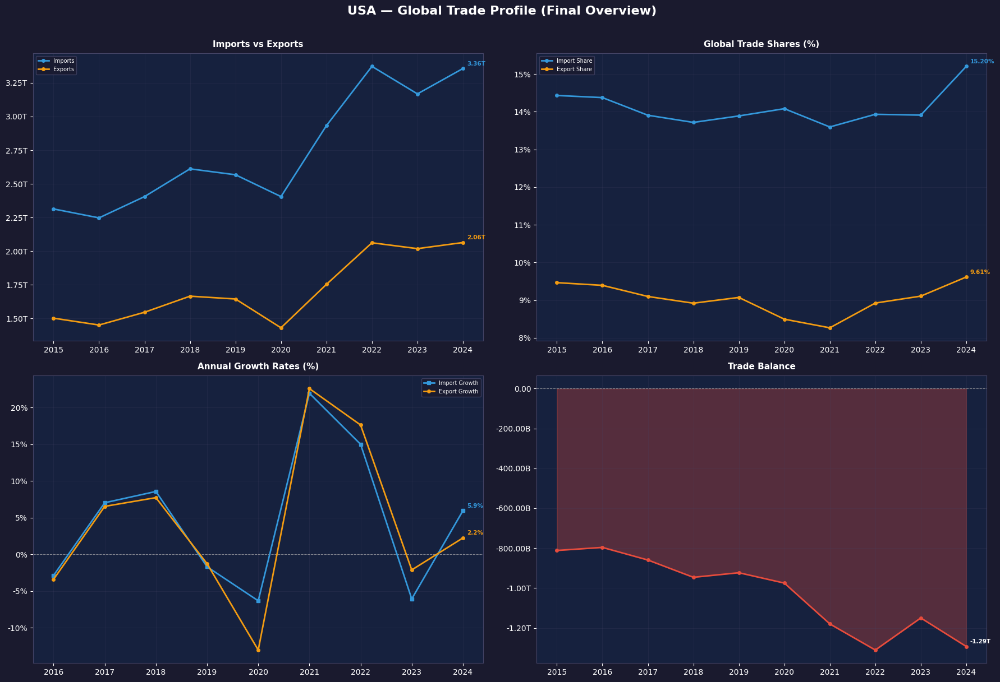

In [165]:
plot_global_view_country(df_country, country)

The four-panel dashboard provides a complete structural reading of a
country's trade profile in a single view — combining volume, share,
dynamics and balance. The most revealing signal is the divergence
between volume growth (panel 1) and share evolution (panel 2) :
a country can grow in absolute terms while losing global relevance.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 3.7 Structural Indicators
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.1 Create Structural Table
</div>

In [171]:
# Aggregation
df_structural = df_trade.groupby('country_name').agg(
    export_share_structural =('export_share', 'median'), 
    import_share_structural =('import_share', 'median'), 
    coverage_ratio_structural =('coverage_ratio', 'median')).reset_index()

# Normalization
df_structural["z_export_share"] = zscore(df_structural["export_share_structural"])
df_structural["z_import_share"] = zscore(df_structural["import_share_structural"])
df_structural["z_coverage_ratio"] = zscore(df_structural["coverage_ratio_structural"])

# Merge with df_trade_dynamic
df_structural = df_structural.merge(df_trade_dynamic, on="country_name", how="left")
df_structural = df_structural.dropna(subset=['cagr_export', 'volatility_export', 'negfreq_export', 'z_cagr_export', 'z_volatility_export', 'z_negfreq_export'])
df_structural.sample()

,country_name,export_share_structural,import_share_structural,coverage_ratio_structural,z_export_share,z_import_share,z_coverage_ratio,total_export,total_import,avg_growth_export,...,negfreq_export,negfreq_import,z_cagr_export,z_cagr_import,z_volatility_export,z_volatility_import,z_negfreq_export,z_negfreq_import,resilience_export,resilience_import
111,Mauritius,0.0098,0.0288,0.3428,-0.3472,-0.3347,-0.1277,19315067346.3250,54572457440.9460,-3.6005,...,0.7000,0.3000,-1.1452,-0.0740,-0.3121,-0.2514,2.5979,-0.2966,-3.4310,0.4740


In [172]:
# Classification
def classify_size(share):
    if share >= 2:          return "Leader"
    elif share >= 0.5:        return "Major"
    elif share >= 0.1:      return "Mid"
    else:                   return "Small"

def classify_balance(ratio):
    if ratio >= 1.15:         return 'Strong Surplus'
    elif ratio >= 1:         return 'Slight Surplus'
    elif ratio >= 0.85:       return 'Slight Deficit'
    else:                    return 'Structural Deficit'        

def classify_growth(z):
    if z >= 1:          return 'Strong Grower'
    elif z >= 0:        return 'Moderate Grower'
    elif z >= -1:       return 'Weak Grower'
    else:               return 'Declining'

def classify_stability(z):
    if z <= -0.5:    return 'Stable'        
    elif z <= 0.5:   return 'Moderate'
    elif z <= 1.5:   return 'Volatile'
    else:            return 'Very Volatile'

# Consistency
def classify_consistency(negfreq):
    if negfreq <= 0.20:    return 'Very Consistent'
    elif negfreq <= 0.35:  return 'Consistent' 
    elif negfreq <= 0.55:  return 'Inconsistent'
    else:                  return 'Very Inconsistent'

df_structural["size_profile"] = df_structural["export_share_structural"].apply(classify_size)
df_structural["balance_profile"] = df_structural["coverage_ratio_structural"].apply(classify_balance)
df_structural["growth_profile"] = df_structural["z_cagr_export"].apply(classify_growth)
df_structural["stability_profile"] = df_structural["z_volatility_export"].apply(classify_stability)
df_structural["consistency_profile"] = df_structural["negfreq_export"].apply(classify_consistency)

df_structural.sample().style.format(_format_value, subset=[col for col in df_structural.columns if col not in ["country_name", "size_profile", "balance_profile", "growth_profile", "stability_profile", "consistency_profile"]])

,country_name,export_share_structural,import_share_structural,coverage_ratio_structural,z_export_share,z_import_share,z_coverage_ratio,total_export,total_import,avg_growth_export,avg_growth_import,cagr_export,cagr_import,volatility_export,volatility_import,years_export,years_import,negfreq_export,negfreq_import,z_cagr_export,z_cagr_import,z_volatility_export,z_volatility_import,z_negfreq_export,z_negfreq_import,resilience_export,resilience_import,size_profile,balance_profile,growth_profile,stability_profile,consistency_profile
128,Norway,0.66,0.46,1.38,0.07,-0.05,0.02,1.39T,891.93B,12.31,3.60,0.06,0.03,45.36,10.06,9.00,9.00,0.50,0.40,0.03,-0.28,0.22,-0.82,1.18,0.46,-1.37,0.08,Major,Strong Surplus,Moderate Grower,Moderate,Inconsistent


The structural score combines five dimensions — size, balance, growth,
stability and consistency — into a single composite that positions each
country within the global trade hierarchy. The distribution confirms
that true structural strength is rare : only 15% of countries qualify
as Strong, while the majority cluster around moderate performance.
The score is deliberately export-centric, reflecting that trade power
is measured by a country's capacity to compete globally, not merely
to consume imports.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.2 Scoring
</div>

In [176]:
# Scoring
df_structural['structural_score'] = ( df_structural['z_export_share']    * 0.60 + df_structural['z_coverage_ratio']    * 0.10 +
                                      df_structural['z_cagr_export']     * 0.15 - df_structural['z_volatility_export'] * 0.10 -
                                      df_structural['z_negfreq_export']  * 0.05)

# Structural Profile
q85 = df_structural['structural_score'].quantile(0.85)
q50 = df_structural['structural_score'].quantile(0.50)
q15 = df_structural['structural_score'].quantile(0.15)

def score_profile(score):
    if score >= q85:    return 'Strong'
    elif score >= q50:  return 'Good'
    elif score >= q15:  return 'Moderate'
    else:               return 'Weak'

df_structural['structural_profile'] = df_structural['structural_score'].apply(score_profile)
df_structural = df_structural.sort_values('structural_score', ascending=False).reset_index(drop=True)
df_structural[["country_name", "structural_score", "structural_profile"]].head(3)

,country_name,structural_score,structural_profile
0,China,5.6164,Strong
1,USA,3.2878,Strong
2,Germany,2.9807,Strong


In [180]:
df_structural["structural_profile"].value_counts()

structural_profile
Good        64
Moderate    63
Strong      28
Weak        28
Name: count, dtype: int64

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.3 Summary
</div>

In [183]:
print(f"\n{'='*50}")
print(f"  F.3.7.3 — STRUCTURAL TABLE SUMMARY")
print(f"{'='*50}")
for col in ['size_profile', 'balance_profile', 'growth_profile', 'stability_profile', 'consistency_profile', 'structural_profile']:
    print(df_structural[col].value_counts())
    print(f"{'-'*50}")
print(f"\nScore describe:")
print(df_structural['structural_score'].describe().round(4))
print(f"{'-'*50}")
print(f"\nThresholds : q85={q85:.4f} | q50={q50:.4f} | q15={q15:.4f}")
print(f"{'-'*50}")
print(f"\nTop 3:")
print(df_structural[['country_name', 'structural_score',
                      'structural_profile']].head(3).to_string())
print(f"{'='*50}")


  F.3.7.3 — STRUCTURAL TABLE SUMMARY
size_profile
Small     114
Mid        33
Major      21
Leader     15
Name: count, dtype: int64
--------------------------------------------------
balance_profile
Structural Deficit    108
Strong Surplus         28
Slight Deficit         24
Slight Surplus         23
Name: count, dtype: int64
--------------------------------------------------
growth_profile
Weak Grower        89
Moderate Grower    67
Strong Grower      14
Declining          13
Name: count, dtype: int64
--------------------------------------------------
stability_profile
Moderate         171
Volatile           6
Very Volatile      6
Name: count, dtype: int64
--------------------------------------------------
consistency_profile
Inconsistent         76
Consistent           62
Very Consistent      37
Very Inconsistent     8
Name: count, dtype: int64
--------------------------------------------------
structural_profile
Good        64
Moderate    63
Strong      28
Weak        28
Name: cou

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.4 Radar Chart
</div>

In [186]:
def plot_structural_radar(df_structural, countries):
    """    Structural Radar Chart : 5 dimensions per country vs world average     """
    dims = ['size_profile', 'balance_profile', 'growth_profile','stability_profile', 'consistency_profile']
    LABEL_LEVELS = {
                    'size_profile':        {'Leader': 1.0, 'Major': 0.67,'Mid': 0.33, 'Small': 0.0},
                    'balance_profile':     {'Strong Surplus': 1.0, 'Slight Surplus': 0.67, 'Slight Deficit': 0.33, 'Structural Deficit': 0.0},
                    'growth_profile':      {'Strong Grower': 1.0, 'Moderate Grower': 0.67, 'Weak Grower': 0.33, 'Declining': 0.0},
                    'stability_profile':   {'Stable': 1.0, 'Moderate': 0.67, 'Volatile': 0.33, 'Very Volatile': 0.0},
                    'consistency_profile': {'Very Consistent': 1.0, 'Consistent': 0.67, 'Inconsistent': 0.33, 'Very Inconsistent': 0.0}
                    }

    dim_labels = ['Size', 'Balance', 'Growth', 'Stability', 'Consistency']
    n_dims     = len(dims)
    angles     = [n / float(n_dims) * 2 * np.pi for n in range(n_dims)]
    angles    += angles[:1]

    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(polar=True))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), dim_labels, color='white', fontsize=10)
    ax.set_ylim(0, 4)
    ax.set_yticks([1, 2, 3, 4])
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['Weak', 'Moderate', 'Good', 'Strong'], color='#aaaaaa', fontsize=7)
    ax.grid(color='#444466', linewidth=0.5, alpha=0.6)
    ax.spines['polar'].set_color('#444466')
    ax.set_title('Structural Profile Radar — Selected Countries', fontsize=13, fontweight='bold', color='white', pad=20)

    # World average
    avg_values = [df_structural[dim].map(LABEL_LEVELS[dim]).mean()  for dim in dims ]
    avg_values += avg_values[:1]
    ax.plot(angles, avg_values, color='#aaaaaa', linewidth=1.2, linestyle='--', alpha=0.8, label='World Average')
    ax.fill(angles, avg_values, color='#aaaaaa', alpha=0.05)

    # Countries
    df_high = df_structural[df_structural['country_name'].isin(countries)]

    for _, row in df_high.iterrows():
        values = [LABEL_LEVELS[dim].get(row[dim], 1) for dim in dims]
        values += values[:1]
        c = color_map[row['country_name']]
        ax.plot(angles, values, color=c, linewidth=2.0, label=f"{row['country_name']} " f"({row['structural_profile']})")
        ax.fill(angles, values, color=c, alpha=0.08)

    add_legend(ax, loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=8)

    save_figure(fig, '../Figures/Trade/F_3_7_4_structural_radar.png')

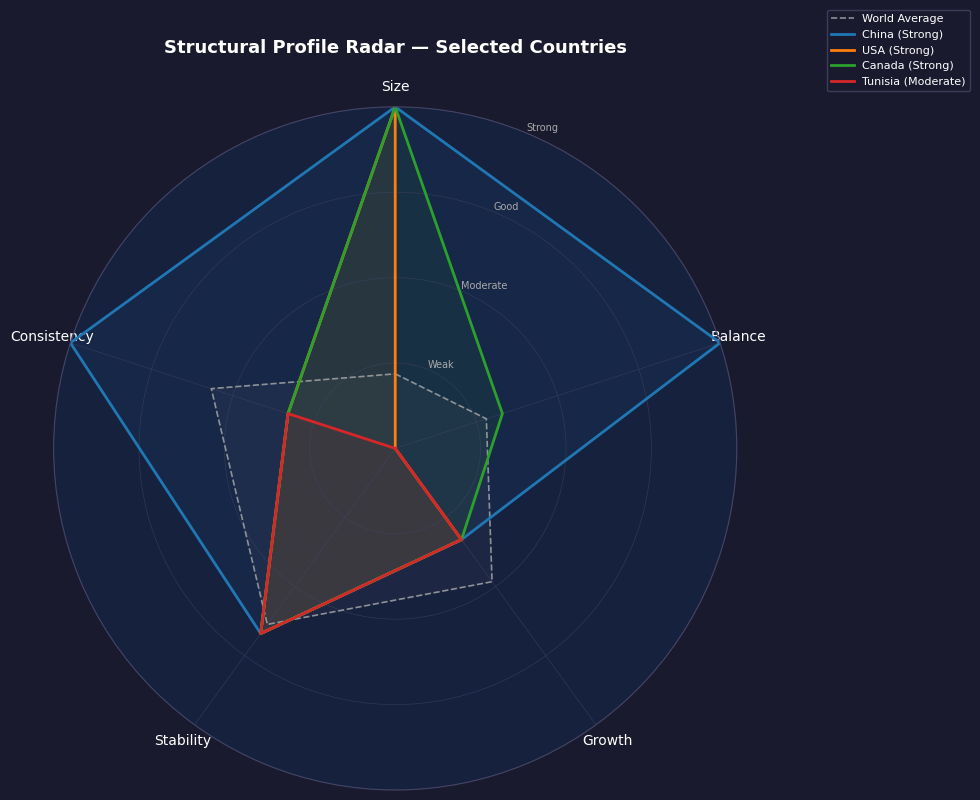

In [188]:
plot_structural_radar(df_structural, ["China", "USA", "Canada", "Tunisia"])

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.5 Score Card
</div>

In [190]:
LEVEL_COLORS = { 1: '#2ecc71', 2: '#3498db', 3: '#f39c12', 4: '#e74c3c' }
LABEL_LEVELS = {
    'size_profile':          {'Leader': 1, 'Major': 2, 'Mid': 3, 'Small': 4},
    'balance_profile':        {'Strong Surplus': 1, 'Slight Surplus': 2, 'Slight Deficit': 3, 'Structural Deficit': 4},
    'growth_profile':      {'Strong Grower': 1, 'Moderate Grower': 2, 'Weak Grower': 3, 'Declining': 4},
    'stability_profile':   {'Stable': 1, 'Moderate': 2, 'Volatile': 3, 'Very Volatile': 4},
    'consistency_profile': {'Very Consistent': 1, 'Consistent': 2, 'Inconsistent': 3, 'Very Inconsistent': 4},
    'structural_profile' : {'Strong': 1, 'Good': 2, 'Moderate': 3, 'Weak': 4}
}

In [193]:
def plot_structural_scorecard(country_name, df_structural):
    """   Card to synthetis values, scores and profiles    """
    row = df_structural[df_structural['country_name'] == country_name].iloc[0]
    indicator1 = {'label':'Size Profile','value': f"{row['export_share_structural']:.2f}%",
                  'zscore': row['z_export_share'],'profile': row['size_profile'],'field':'size_profile'}
    indicator2 = {'label':'Balance Profile (Coverage)','value':f"{row['coverage_ratio_structural']:.2f}",
                 'zscore': row['z_coverage_ratio'],'profile':row['balance_profile'],'field':'balance_profile'}
    indicator3 = {'label':'Growth Profile','value':f"{row['cagr_export']:.2f}%",
                 'zscore': row['z_cagr_export'],'profile':row['growth_profile'],'field':'growth_profile'}
    indicator4 = {'label':'Stability Profile', 'value':f"{row['volatility_export']:.2f}",
                 'zscore': row['z_volatility_export'],'profile':row['stability_profile'],'field':'stability_profile'}
    indicator5 = {'label':'Consistency Profile','value':f"{row['negfreq_export']:.2f}",
                 'zscore': row['z_negfreq_export'],'profile':row['consistency_profile'],'field':'consistency_profile'}
    indicators = [indicator1, indicator2, indicator3, indicator4, indicator5]
   
    # Score
    score       = row["structural_score"]
    score_label = row["structural_profile"]
    score_level = LABEL_LEVELS["structural_profile"][score_label]
    score_color = LEVEL_COLORS[score_level]

    # Figure
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.axis('off')
    fig.patch.set_facecolor('#1a1a2e')
    
    # Titre
    ax.text(0.5, 0.97, f'Structural Indicators — {country_name}', transform=ax.transAxes, fontsize=16, fontweight='bold', color='white', ha='center', va='top')
    
    # Headers
    headers = ['Indicator', 'Value', 'vs World (z)', 'Profile']
    xpos    = [0.05, 0.30, 0.50, 0.72]
    for h, x in zip(headers, xpos):
        ax.text(x, 0.87, h, transform=ax.transAxes, fontsize=10, color='#aaaaaa', fontweight='bold', ha='center' if x != 0.05 else 'left')
    
    # Ligne headers
    ax.plot([0.03, 0.97], [0.845, 0.845], transform=ax.transAxes, color='#444466', linewidth=0.8, clip_on=False)
    row_height = 0.1
    start_y    = 0.78
    
    # 5 Indicators
    for i, ind in enumerate(indicators):
        y = start_y - i * row_height
        # alterned background
        if i % 2 == 0:
            fancy = FancyBboxPatch((0.03, y - 0.05), 0.94, row_height - 0.01, transform=ax.transAxes,
                                   boxstyle="round,pad=0.01",facecolor='#16213e', edgecolor='none', zorder=0)
            ax.add_patch(fancy)
        # Indicators label
        ax.text(xpos[0], y, ind['label'], transform=ax.transAxes, fontsize=10, color='white', va='center')
        # Value
        ax.text(xpos[1], y, ind['value'], transform=ax.transAxes, fontsize=10, color='#e0e0e0', ha='center', va='center')
        # Z-score
        z = ind['zscore']
        z_color = '#2ecc71' if z > 0 else '#e74c3c'
        z_text  = f"+{z:.2f}σ" if z > 0 else f"{z:.2f}σ"
        ax.text(xpos[2], y, z_text, transform=ax.transAxes, fontsize=10, color=z_color, ha='center', va='center', fontweight='bold')
        # Colored badge
        level       = LABEL_LEVELS[ind['field']][ind['profile']]
        badge_color = LEVEL_COLORS[level]
        badge = FancyBboxPatch((xpos[3] - 0.01, y - 0.035), 0.26, 0.07, transform=ax.transAxes,
                    boxstyle="round,pad=0.01", facecolor=badge_color, edgecolor='none', alpha=0.85, zorder=1)
        ax.add_patch(badge)
        ax.text(xpos[3] + 0.12, y, ind['profile'], transform=ax.transAxes, fontsize=9, color='white', ha='center', va='center',
                fontweight='bold', zorder=2)

    # Separated line before score 
    y_sep = start_y - 5 * row_height + 0.01
    ax.plot([0.03, 0.97], [y_sep, y_sep], transform=ax.transAxes, color='#aaaaaa', linewidth=1.0, clip_on=False, linestyle='--')

    # Overall Score
    y_score = y_sep - 0.07
    score_bg = FancyBboxPatch((0.03, y_score - 0.05), 0.94, row_height - 0.01, transform=ax.transAxes,
                               boxstyle="round,pad=0.01", facecolor='#0f3460', edgecolor='none', zorder=0)
    ax.add_patch(score_bg)

    ax.text(xpos[0], y_score, 'Overall Score', transform=ax.transAxes, fontsize=11, color='white', va='center', fontweight='bold')
    ax.text(xpos[1], y_score, f"{score:.2f}", transform=ax.transAxes, fontsize=11, color='white', ha='center', va='center', fontweight='bold')
    ax.text(xpos[2], y_score, '', transform=ax.transAxes, fontsize=10, ha='center', va='center')

    badge_score = FancyBboxPatch((xpos[3] - 0.01, y_score - 0.035), 0.26, 0.07, transform=ax.transAxes,
                        boxstyle="round,pad=0.01", facecolor=score_color, edgecolor='none', alpha=0.95, zorder=1)
    ax.add_patch(badge_score)
    ax.text(xpos[3] + 0.12, y_score, score_label, transform=ax.transAxes,
            fontsize=10, color='white', ha='center', va='center', fontweight='bold', zorder=2)

    # Legendes level
    legend_y = y_score - 0.10 
    ax.text(0.03, legend_y, 'Levels:', transform=ax.transAxes, fontsize=8, color='#aaaaaa', va='center')
    level_labels = ['Strong', 'Good', 'Moderate', 'Weak']
    for j, (lvl, lbl) in enumerate(zip([1,2,3,4], level_labels)):
        xl = 0.15 + j * 0.18
        badge_l = FancyBboxPatch((xl, legend_y - 0.025), 0.15, 0.05, transform=ax.transAxes,
                                 boxstyle="round,pad=0.01", facecolor=LEVEL_COLORS[lvl], edgecolor='none', alpha=0.85)
        ax.add_patch(badge_l)
        ax.text(xl + 0.075, legend_y, lbl, transform=ax.transAxes, fontsize=8, color='white', ha='center', va='center', fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'../Figures/Trade/F_3_7_5_structural_scorecard_{country_name.replace(" ", "_")}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()


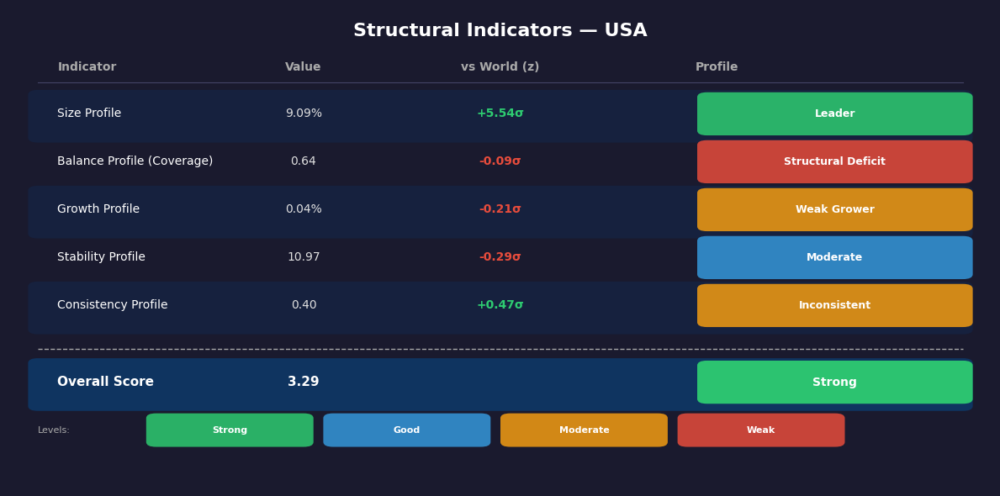

In [195]:
plot_structural_scorecard('USA', df_structural)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 3.7.6 Heatmap
</div>

In [198]:
def plot_structural_heatmap(df_structural, countries=None, top_n=None, profile=None, highlight_countries=None):
    """    Structural Indicators Heatmap    countries / top_n / profiles.    highlight_countries : list of countries to highlight    """

    # Filter 
    if countries:        df_plot = df_structural[df_structural['country_name'].isin(countries)].copy(); fig_name = "selected_countries"
    elif top_n:          df_plot = pd.concat([df_structural.head(top_n), df_structural.tail(top_n)]).drop_duplicates().copy(); fig_name = f"top_{top_n}"
    elif profile:       df_plot = df_structural[df_structural['structural_profile']==profile].copy(); fig_name = profile 
    else:                df_plot = df_structural.copy()

    df_plot = df_plot.sort_values('structural_score', ascending=False).reset_index(drop=True)
    n_countries = len(df_plot)
    
    if highlight_countries is None:     highlight_countries = []

    # Config 
    LABEL_LEVELS = {
        'size_profile':        {'Leader': 1, 'Major': 2, 'Mid': 3, 'Small': 4},
        'balance_profile':     {'Strong Surplus': 1, 'Slight Surplus': 2, 'Slight Deficit': 3, 'Structural Deficit': 4},
        'growth_profile':      {'Strong Grower': 1, 'Moderate Grower': 2, 'Weak Grower': 3, 'Declining': 4},
        'stability_profile':   {'Stable': 1, 'Moderate': 2, 'Volatile': 3, 'Very Volatile': 4},
        'consistency_profile': {'Very Consistent': 1, 'Consistent': 2, 'Inconsistent': 3, 'Very Inconsistent': 4},
        'structural_profile':  {'Strong': 1, 'Good': 2, 'Moderate': 3, 'Weak': 4}
    }
    LEVEL_COLORS = {1: '#2ecc71', 2: '#3498db', 3: '#f39c12', 4: '#e74c3c'}
    cols = ['size_profile','balance_profile','growth_profile','stability_profile','consistency_profile','structural_profile']
    col_labels = ['Size', 'Balance', 'Growth', 'Stability', 'Consistency', 'Overall']
   
    short_labels = {
        'Leader': 'Leader',       'Major': 'Major',
        'Mid': 'Mid',             'Small': 'Small',
        'Strong Surplus': 'Str.S', 'Slight Surplus': 'Slt.S',
        'Slight Deficit': 'Slt.D', 'Structural Deficit': 'Str.D',
        'Strong Grower': 'Strong', 'Moderate Grower': 'Moderate',
        'Weak Grower': 'Weak',     'Declining': 'Declining',
        'Stable': 'Stable',        'Moderate': 'Moderate',
        'Volatile': 'Volatile',    'Very Volatile': 'V.Volatile',
        'Very Consistent': 'V.Cons', 'Consistent': 'Cons.',
        'Inconsistent': 'Incons.',  'Very Inconsistent': 'V.Incons.',
        'Strong': 'Strong',         'Good': 'Good',
        'Weak': 'Weak',             'Moderate': 'Moderate'
    }

    # Figure 
    fig_height = max(10, n_countries * 0.35)
    fig, ax    = plt.subplots(figsize=(16, fig_height))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.axis('off')
    ax.set_title('Structural Classification Heatmap', fontsize=14, fontweight='bold', color='white', pad=15)

    # Dimensions 
    cell_h   = 1.0 / (n_countries + 2)
    name_w   = 0.22
    score_w  = 0.10
    col_w    = (1.0 - name_w - score_w - 0.04) / len(cols)
    x_starts = [name_w + score_w + i * col_w for i in range(len(cols))]
    y_header = 1.0 - cell_h * 0.5

    # Headers
    ax.text(0.02, y_header, 'Country', transform=ax.transAxes, fontsize=10, color='#aaaaaa', fontweight='bold', va='center')
    ax.text(name_w, y_header, 'Score', transform=ax.transAxes, fontsize=10, color='#aaaaaa', fontweight='bold', ha='center', va='center')
    for j, lbl in enumerate(col_labels):
        ax.text(x_starts[j] + col_w / 2, y_header, lbl, transform=ax.transAxes, fontsize=10, color='#aaaaaa', fontweight='bold', ha='center', va='center')

    ax.plot([0.01, 0.99], [y_header - cell_h * 0.45, y_header - cell_h * 0.45], transform=ax.transAxes, color='#444466', linewidth=0.8, clip_on=False)

    # Rows
    for i, (_, row) in enumerate(df_plot.iterrows()):
        y_center     = y_header - cell_h * (i + 1.2)
        is_highlight = row['country_name'] in highlight_countries

        bg_color = '#1e2a4a' if is_highlight else ('#16213e' if i % 2 == 0 else '#1a1a2e')
        bg = FancyBboxPatch((0.01, y_center - cell_h * 0.45), 0.98, cell_h * 0.9, transform=ax.transAxes, boxstyle='round,pad=0.005',
                            facecolor=bg_color, edgecolor='none', zorder=0)
        ax.add_patch(bg)

        if is_highlight:
            border = FancyBboxPatch((0.01, y_center - cell_h * 0.45), 0.98, cell_h * 0.9, transform=ax.transAxes, boxstyle='round,pad=0.005',
                                    facecolor='none', edgecolor='#f1c40f', linewidth=1.2, zorder=3)
            ax.add_patch(border)

        # Country name
        ax.text(0.02, y_center, row['country_name'], transform=ax.transAxes, fontsize=9, color='#f1c40f' if is_highlight else 'white',
                fontweight='bold' if is_highlight else 'normal', va='center')

        # Score
        ax.text(name_w, y_center, f"{row['structural_score']:.2f}", transform=ax.transAxes, fontsize=9, 
                color='#f1c40f' if is_highlight else '#e0e0e0', ha='center', va='center')

        # Badges
        for j, col in enumerate(cols):
            label = row[col]
            level = LABEL_LEVELS[col].get(label, 4)
            color = LEVEL_COLORS[level]
            x_cell = x_starts[j]

            badge = FancyBboxPatch((x_cell + 0.003, y_center - cell_h * 0.32), col_w - 0.006, cell_h * 0.64, transform=ax.transAxes,
                                   boxstyle='round,pad=0.005', facecolor=color, edgecolor='none', alpha=0.85, zorder=1)
            ax.add_patch(badge)

            ax.text(x_cell + col_w / 2, y_center, short_labels.get(label, label), transform=ax.transAxes, fontsize=9,
                    color='white', ha='center', va='center', fontweight='bold', zorder=2)

    # Legend
    y_legend     = y_header - cell_h * (n_countries + 1.8)
    level_labels = ['1 — Strong', '2 — Good', '3 — Moderate', '4 — Weak']
    ax.text(0.01, y_legend, 'Levels:', transform=ax.transAxes, fontsize=10, color='#aaaaaa', va='center')
    for k, (lvl, lbl) in enumerate(zip([1, 2, 3, 4], level_labels)):
        xl = 0.10 + k * 0.20
        b  = FancyBboxPatch((xl, y_legend - cell_h * 0.35), 0.17, cell_h * 0.7, transform=ax.transAxes, boxstyle='round,pad=0.005',
                            facecolor=LEVEL_COLORS[lvl], edgecolor='none', alpha=0.85)
        ax.add_patch(b)
        ax.text(xl + 0.085, y_legend, lbl, transform=ax.transAxes, fontsize=7.5, color='white', ha='center', va='center', fontweight='bold')

    save_figure(fig, f'../Figures/Trade/F_3_7_6_structural_heatmap_{fig_name}.png')

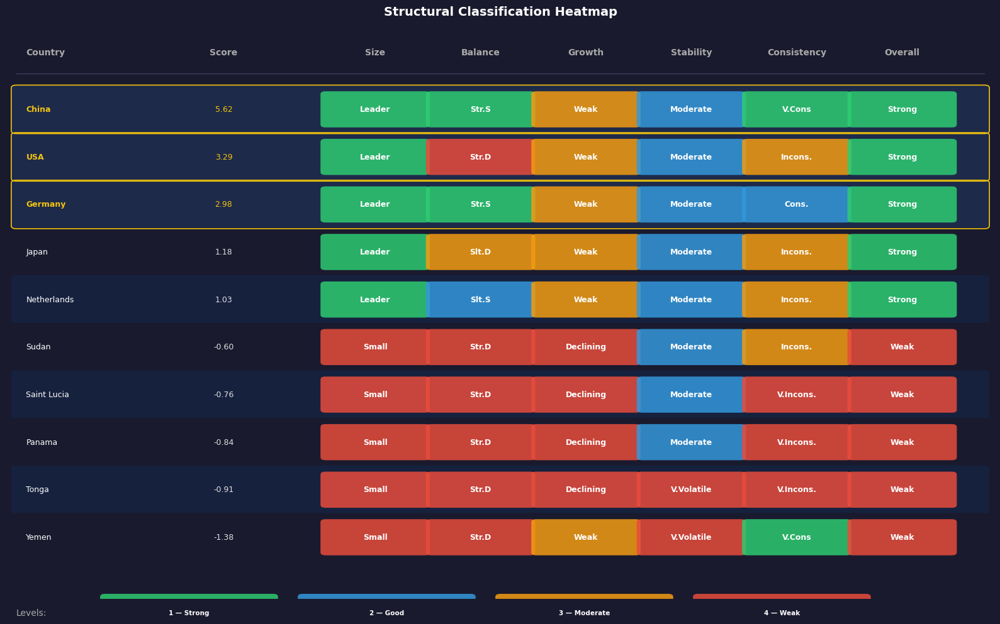

In [200]:
# Top n + Bottom n
plot_structural_heatmap(df_structural, top_n=5, highlight_countries=['USA', 'China', 'Germany'])

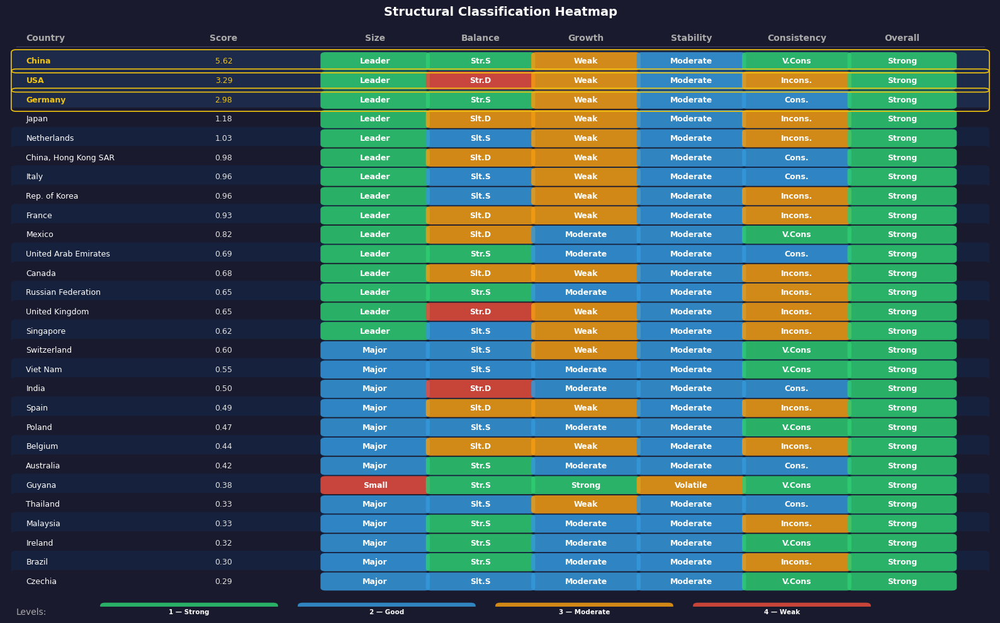

In [201]:
# Strong / Weak profiles only
plot_structural_heatmap(df_structural, profile='Strong', highlight_countries=['USA', 'China', 'Germany'])

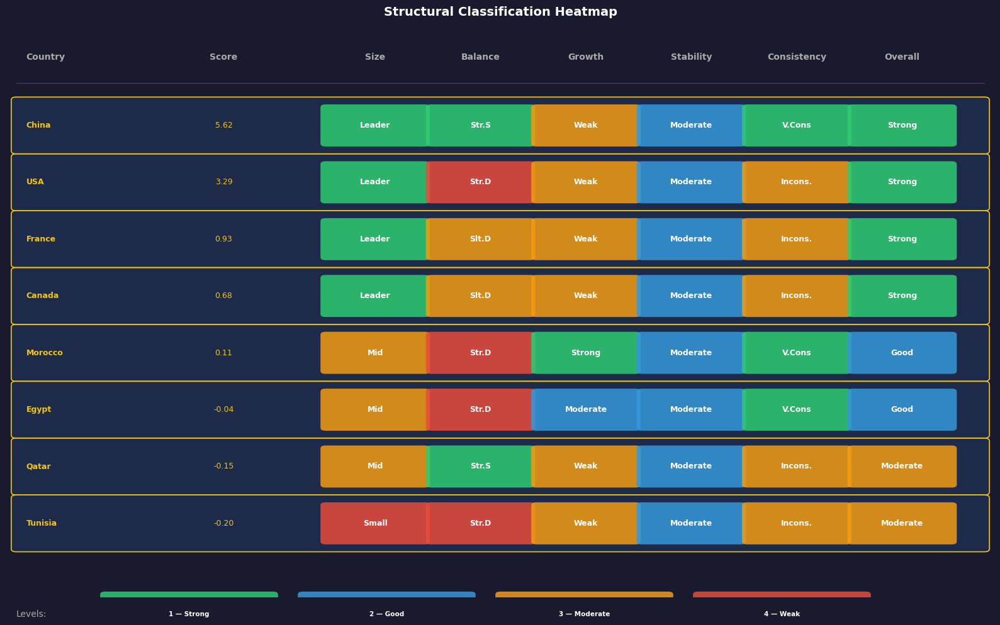

In [202]:
# Selected countries
plot_structural_heatmap(df_structural, countries=countries, highlight_countries=countries)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 4. Cross-Country Comparison
</div>

In [205]:
countries = ["USA", "China", "France", "Germany", "Qatar", "Saudi Arabia", "Brazil", "Tunisia"]
year = 2024

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.1 Import / Export Comparison
</div>

In [207]:
def plot_import_export_comparison(df_trade, countries, metric='X', year = None):
    """    Import/Export Comparison:    Line chart evolution + Bar chart snapshot last year    """
    label  = _desc_metric(metric)
    df_c   = df_trade[df_trade['country_name'].isin(countries)].copy()
    if year is None : year   = df_c['year'].max()
    df_yr  = df_c[df_c['year'] == year].sort_values(metric, ascending=True)

    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle(f'{label} Comparison — Selected Countries', fontsize=14, fontweight='bold', color='white', y=1.01)

    # Line chart
    for country in countries:
        df_co = df_c[df_c['country_name'] == country].sort_values('year')
        c = color_map[country]
        ax1.plot(df_co['year'], df_co[metric], color=c, linewidth=2.5, marker='o', markersize=5, label=country, zorder=3)
        # Annotate last point
        ax1.annotate(_format_value(df_co[metric].iloc[-1]), xy=(df_co['year'].iloc[-1], df_co[metric].iloc[-1]),
                     xytext=(5, 4), textcoords='offset points', fontsize=7.5, color=c, fontweight='bold')

    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel(f'{label} (USD)', fontsize=10)
    ax1.set_title(f'{label} Evolution', fontsize=11, pad=10)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax1.set_xticks(sorted(df_c['year'].unique()))
    style_grid(ax1)
    add_legend(ax1, loc='upper left', fontsize=7)

    # Bar chart snapshot 
    bar_colors = [color_map[c] for c in df_yr['country_name']]
    bars = ax2.barh(df_yr['country_name'], df_yr[metric], color=bar_colors, edgecolor='none', height=0.6, zorder=2)

    for bar, val in zip(bars, df_yr[metric]):
        ax2.text(val + df_yr[metric].max() * 0.01, bar.get_y() + bar.get_height()/2, _format_value(val), va='center', fontsize=8, color='white', fontweight='bold')

    ax2.set_xlabel(f'{label} (USD)', fontsize=10)
    ax2.set_title(f'{label} Ranking — {year}', fontsize=11, pad=10)
    ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    style_grid(ax2)

    save_figure(fig, f'../Figures/Trade/F_4_1_{label}_comparison.png')

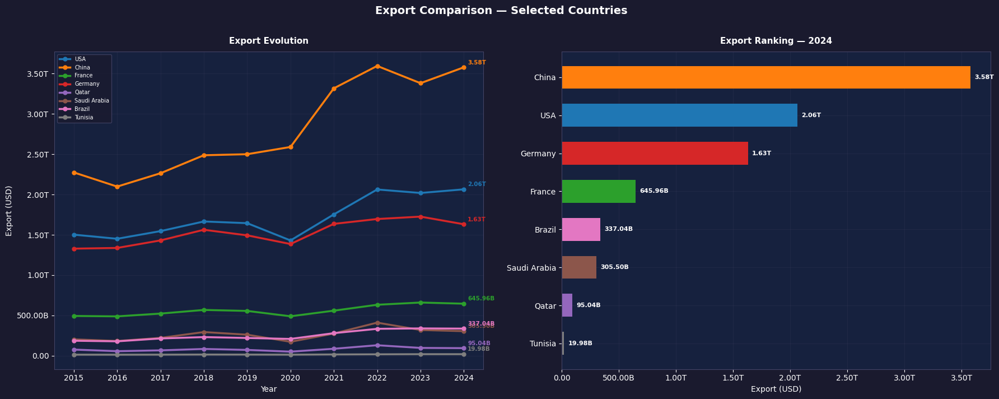

In [208]:
plot_import_export_comparison(df_trade, countries, 'X')

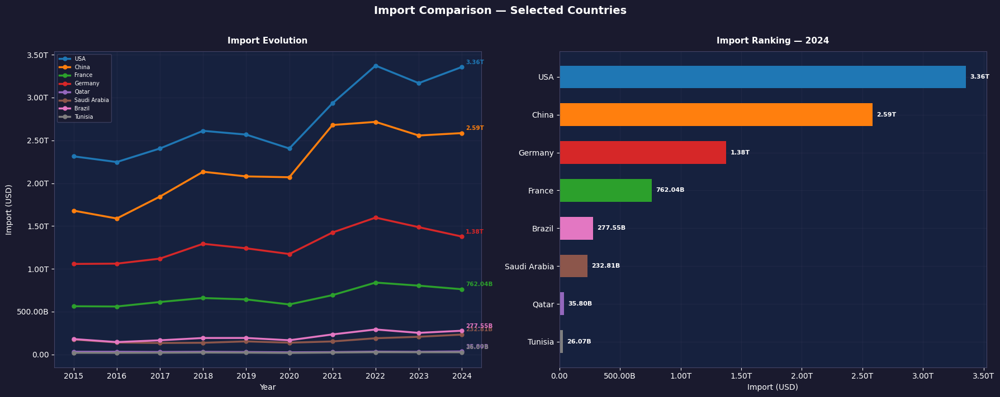

In [210]:
plot_import_export_comparison(df_trade, countries, metric='M')

Cross-country comparison reveals fundamentally different trade models
coexisting within the global system — export-led economies (China, Germany)
vs consumption-driven economies (USA, France). Volume alone does not determine
trade power : a country can rank high in imports while running a structural
deficit, reflecting domestic demand strength rather than competitive export capacity.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.2 Trade Balance Comparison
</div>

In [216]:
def plot_balance_comparison(df_trade, countries, year = None):
    """    Trade Balance Comparison:  Line chart evolution + Bar chart snapshot last year    """
    df_c  = df_trade[df_trade['country_name'].isin(countries)].copy()
    if not year :  year  = df_c['year'].max()
    df_yr = df_c[df_c['year'] == year].sort_values('trade_balance', ascending=True)

    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle('Trade Balance Comparison — Selected Countries', fontsize=14, fontweight='bold', color='white', y=1.01)

    # Line chart
    ax1.axhline(y=0, color='#aaaaaa', linewidth=1.0, linestyle='--', alpha=0.7)

    for country in countries:
        df_co = df_c[df_c['country_name'] == country].sort_values('year')
        c = color_map[country]
        ax1.plot(df_co['year'], df_co['trade_balance'], color=c, linewidth=2.5, marker='o', markersize=5, label=country, zorder=3)
        ax1.annotate(_format_value(df_co['trade_balance'].iloc[-1]), xy=(df_co['year'].iloc[-1], df_co['trade_balance'].iloc[-1]),
                     xytext=(5, 4), textcoords='offset points', fontsize=7.5, color=c, fontweight='bold')

    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel('Trade Balance (USD)', fontsize=10)
    ax1.set_title('Trade Balance Evolution', fontsize=11, pad=10)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    ax1.set_xticks(sorted(df_c['year'].unique()))
    style_grid(ax1)
    add_legend(ax1, loc='upper left', fontsize=7)

    # Bar chart snapshot
    bar_colors = ['#2ecc71' if v >= 0 else '#e74c3c' for v in df_yr['trade_balance']]
    bars = ax2.barh(df_yr['country_name'], df_yr['trade_balance'], color=bar_colors, edgecolor='none', height=0.6, zorder=2)
    ax2.axvline(x=0, color='#aaaaaa', linewidth=1.0, linestyle='-', alpha=0.8)

    for bar, val in zip(bars, df_yr['trade_balance']):
        offset = df_yr['trade_balance'].abs().max() * 0.02
        ax2.text(val + (offset if val >= 0 else -offset), bar.get_y() + bar.get_height()/2, _format_value(val),
                 va='center', ha='left' if val >= 0 else 'right', fontsize=8, color='white', fontweight='bold')

    ax2.set_xlabel('Trade Balance (USD)', fontsize=10)
    ax2.set_title(f'Trade Balance Ranking — {year}', fontsize=11, pad=10)
    ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: _format_value(x)))
    style_grid(ax2)

    save_figure(fig, '../Figures/Trade/F_4_2_balance_comparison.png')

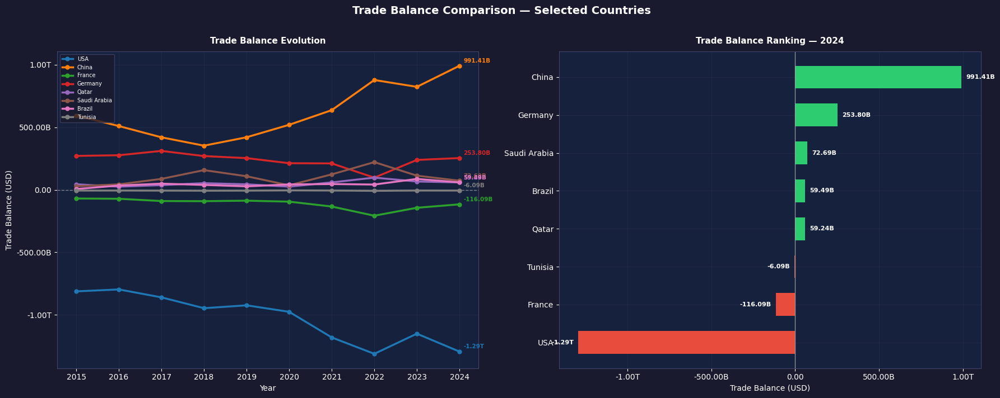

In [217]:
plot_balance_comparison(df_trade, countries, 2024)

Trade balance profiles are structurally persistent — surplus and deficit
countries rarely switch sides across years, confirming that balance
orientation reflects deep economic specialization. The most revealing
signal is the **magnitude divergence** : USA's structural deficit dwarfs
all other countries, illustrating the unique role of the dollar as global
reserve currency enabling sustained consumption-driven trade imbalances.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.3 Share Comparison
</div>

In [221]:
def plot_share_comparison(df_trade, countries, metric='export_share', year = None):
    """    Export/Import Share Comparison:   Line chart share evolution  +  Bar chart snapshot last year    """
    label  = 'Export Share' if metric == 'export_share' else 'Import Share'
    df_c   = df_trade[df_trade['country_name'].isin(countries)].copy()
    if not year : year   = df_c['year'].max()
    df_yr  = df_c[df_c['year'] == year].sort_values(metric, ascending=True)

    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle(f'{label} Comparison — Selected Countries', fontsize=14, fontweight='bold', color='white', y=1.01)

    # Line chart 
    for country in countries:
        df_co = df_c[df_c['country_name'] == country].sort_values('year')
        c = color_map[country]
        ax1.plot(df_co['year'], df_co[metric] , color=c, linewidth=2.5, marker='o', markersize=5, label=country, zorder=3)
        ax1.annotate(f"{df_co[metric].iloc[-1]:.2f}%", xy=(df_co['year'].iloc[-1], df_co[metric].iloc[-1]),
                     xytext=(5, 4), textcoords='offset points', fontsize=7.5, color=c, fontweight='bold')

    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel(f'{label} (%)', fontsize=10)
    ax1.set_title(f'{label} Evolution', fontsize=11, pad=10)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax1.set_xticks(sorted(df_c['year'].unique()))
    style_grid(ax1)
    add_legend(ax1, loc='upper left', fontsize=7)

    # Bar chart snapshot
    bar_colors = [color_map[c] for c in df_yr['country_name']]
    bars = ax2.barh(df_yr['country_name'], df_yr[metric], color=bar_colors, edgecolor='none', height=0.6, zorder=2)

    for bar, val in zip(bars, df_yr[metric]):
        ax2.text(val + df_yr[metric].max() * 0.01, bar.get_y() + bar.get_height()/2, f'{val:.2f}%',
                 va='center', fontsize=8, color='white', fontweight='bold')

    ax2.set_xlabel(f'{label} (%)', fontsize=10)
    ax2.set_title(f'{label} Ranking — {year}', fontsize=11, pad=10)
    ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    style_grid(ax2)

    save_figure(fig, f'../Figures/Trade/F_4_3_{metric}_comparison.png')

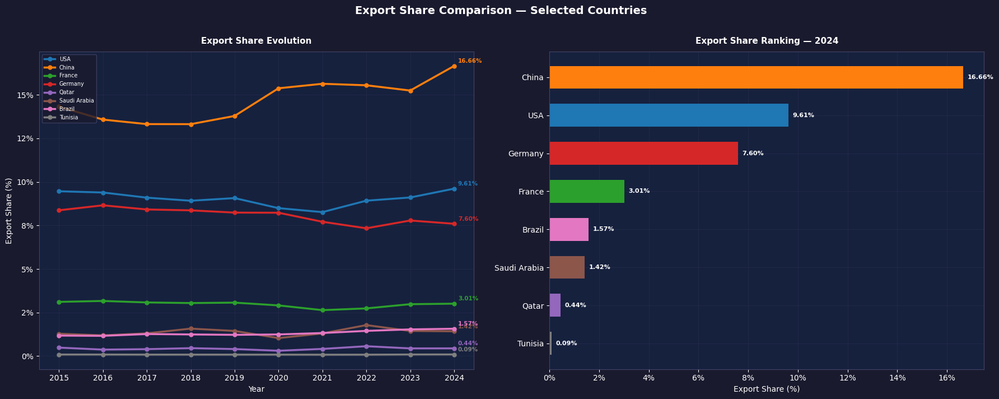

In [222]:
plot_share_comparison(df_trade, countries, metric='export_share')

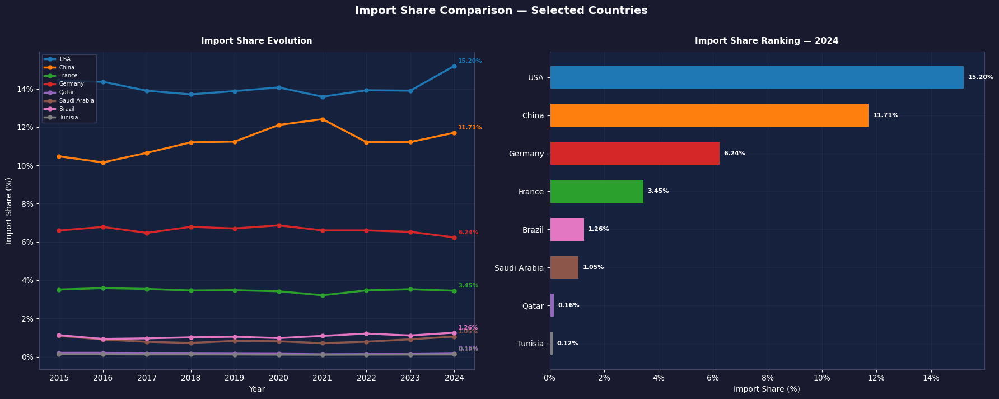

In [223]:
plot_share_comparison(df_trade, countries, metric='import_share')

Share analysis reveals the **relative weight** of each country within the
global trade system — independently of absolute volume growth. A country
can grow in absolute terms while losing global share, signaling that it
is expanding slower than the world average. The most structurally concerning
pattern is a persistent decline in export share combined with a rising
import share — a dual signal of competitive erosion and growing dependency

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.4 Growth Comparison
</div>

In [228]:
def plot_growth_comparison(df_trade, countries, metric='export_growth'):
    """    metric : 'export_growth' | 'import_growth'    """
    
    cagr_col   = 'cagr_export' if metric == 'export_growth' else 'cagr_import'
    label      = 'Export' if metric == 'export_growth' else 'Import'
    flow_col   = 'X' if metric == 'export_growth' else 'M'
    df_c = df_trade[df_trade['country_name'].isin(countries)].copy()

    # CAGR
    df_cagr = df_structural[df_structural['country_name'].isin(countries)][['country_name', cagr_col]]
    df_cagr = df_cagr.sort_values(cagr_col, ascending=True)

    # Base 100 
    base_year = df_c['year'].min()
    df_base   = df_c.pivot(index='year', columns='country_name', values=flow_col)
    df_base   = df_base.div(df_base.loc[base_year]) * 100

    # Colors 
    colors = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    # Figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    fig.patch.set_facecolor('#1a1a2e')
    for ax in [ax1, ax2]:
        ax.set_facecolor('#16213e')
        ax.tick_params(colors='white')
        ax.xaxis.label.set_color('white')
        ax.yaxis.label.set_color('white')
        ax.title.set_color('white')
        for spine in ax.spines.values():   spine.set_edgecolor('#444466')

    fig.suptitle(f'{label} Growth Comparison', fontsize=15,fontweight='bold', color='white', y=1.01)

    # Bar chart CAGR 
    bars = ax1.barh(df_cagr['country_name'], df_cagr[cagr_col],
                    color=[color_map[c] for c in df_cagr['country_name']], edgecolor='none', height=0.6)

    for bar, val in zip(bars, df_cagr[cagr_col]):
        ax1.text(val + 0.05, bar.get_y() + bar.get_height() / 2,
                 f'{val:.1f}%', va='center', fontsize=8, color='white')

    ax1.axvline(x=0, color='#aaaaaa', linewidth=0.8, linestyle='--')
    ax1.set_title(f'CAGR {label} — Full Period', fontsize=11, pad=10)
    ax1.set_xlabel('CAGR (%)', fontsize=9)
    ax1.grid(axis='x', color='#444466', linewidth=0.5, alpha=0.5)

    # Base 100 
    for country in countries:
        if country in df_base.columns:
            ax2.plot(df_base.index, df_base[country], label=country, color=color_map[country],
                     linewidth=2, marker='o', markersize=3)

    ax2.axhline(y=100, color='#aaaaaa', linewidth=0.8, linestyle='--')
    ax2.set_title(f'{label} Evolution — Base 100 ({base_year})', fontsize=11, pad=10)
    ax2.set_xlabel('Year', fontsize=9)
    ax2.set_ylabel(f'Index (Base 100 = {base_year})', fontsize=9)
    ax2.legend(fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left')
    ax2.grid(color='#444466', linewidth=0.5, alpha=0.5)

    plt.tight_layout()
    plt.savefig(f'../Figures/Trade/F_4_4_{metric}_comparison.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

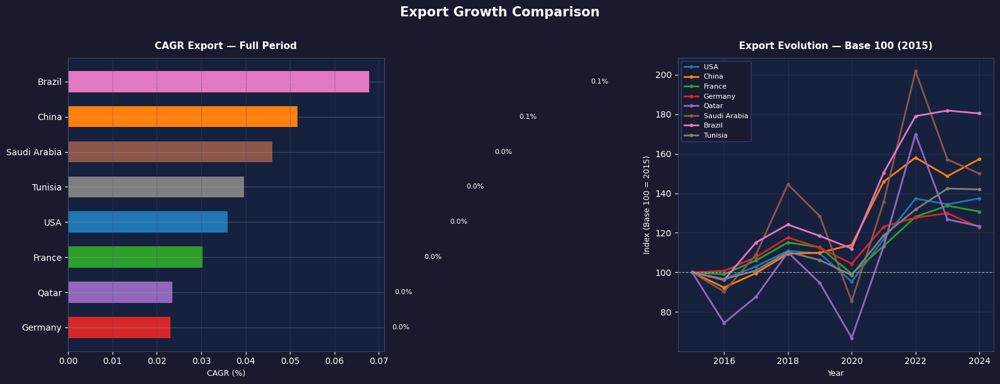

In [230]:
plot_growth_comparison(df_trade, countries, metric='export_growth')

CAGR comparison reveals **structural divergence** in long-term export
trajectories — countries with similar absolute volumes can have radically
different growth profiles, reflecting fundamental differences in economic
dynamism and global integration. The Base 100 visualization is the most
revealing : it strips away size effects and shows purely who is gaining
or losing momentum relative to their own 2015 baseline. Countries
consistently above the baseline post-2021 demonstrate genuine structural
recovery, while those returning to baseline signal a rebound without
structural improvement.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.5 Structural Vulnerability Profile
</div>

**Dimension Definitions**
| Dimension | Indicator | High Risk Means |
|---|---|---|
| **Growth Risk** | z_cagr_export (inverted) | Low or negative export growth |
| **Stability Risk** | z_volatility_export | High year-to-year fluctuations |
| **Consistency Risk** | z_negfreq_export | Frequent negative growth years |
| **Balance Risk** | z_coverage_ratio (inverted) | Structural trade deficit |

In [235]:
# Risk dimensions (normalized)
p95 = df_structural['coverage_ratio_structural'].quantile(0.95)
    
df_structural['growth_risk']      = 1 - normalize_series(df_structural['cagr_export'])
df_structural['stability_risk']   = normalize_series(df_structural['volatility_export'])
df_structural['consistency_risk'] = normalize_series(df_structural['negfreq_export'])
df_structural['balance_risk'] = 1 - normalize_series(df_structural['coverage_ratio_structural'].clip(upper=p95))

In [237]:
def plot_vulnerability_radar(df_structural, countries):
    """    Structural Vulnerability Radar.    Highlighted countries vs World Average   """
    
    df = df_structural.copy()
    risk_cols   = ['growth_risk', 'stability_risk', 'consistency_risk', 'balance_risk']
    risk_labels = ['Growth Risk', 'Stability Risk', 'Consistency Risk', 'Balance Risk']

    df_high   = df[df['country_name'].isin(countries)].copy()
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    # Angles
    n_dims = len(risk_cols)
    angles = [n / float(n_dims) * 2 * np.pi for n in range(n_dims)]
    angles += angles[:1]

    # Figure
    fig, ax = plt.subplots(figsize=(9, 6), subplot_kw=dict(polar=True))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), risk_labels, color='white', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.50, 0.75, 1.00])
    ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], color='#aaaaaa', fontsize=7)
    ax.grid(color='#444466', linewidth=0.5, alpha=0.6)
    ax.spines['polar'].set_color('#444466')
    ax.set_title('Structural Vulnerability Profile — Highlighted Countries', fontsize=13, fontweight='bold', color='white', pad=20)

    # World average
    avg_values  = [df[col].mean() for col in risk_cols] 
    avg_values += avg_values[:1]
    ax.plot(angles, avg_values, color='#aaaaaa', linewidth=1.2, linestyle='--', alpha=0.8, label='World Average')
    ax.fill(angles, avg_values, color='#aaaaaa', alpha=0.05)

    # Highlighted countries
    for _, row in df_high.iterrows():
        values  = [row[col] for col in risk_cols]
        values += values[:1]
        c = color_map[row['country_name']]
        ax.plot(angles, values, color=c, linewidth=2.0,label=row['country_name'])
        ax.fill(angles, values, color=c, alpha=0.08)

    ax.legend(fontsize=9, facecolor='#1a1a2e', edgecolor='#444466',
              labelcolor='white', loc='upper right',bbox_to_anchor=(1.35, 1.15))

    plt.tight_layout()
    plt.savefig('../Figures/Trade/F_4_6_1_vulnerability_radar.png', dpi=150, bbox_inches='tight')
    plt.show()

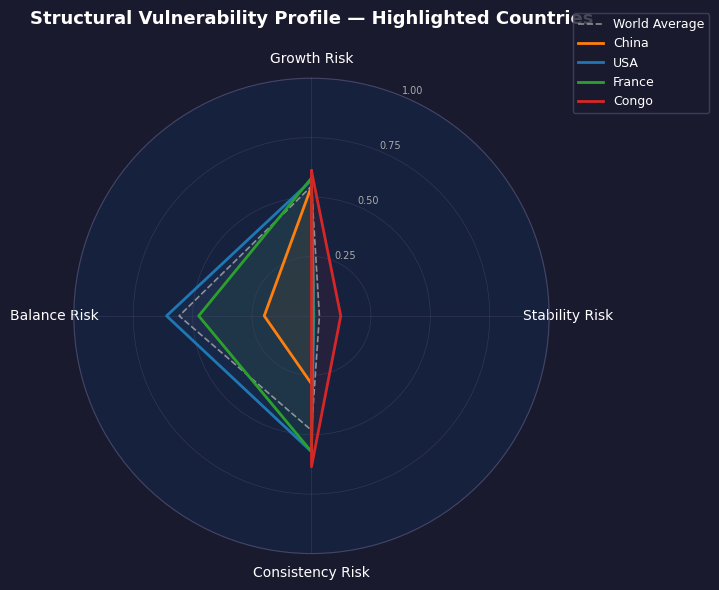

In [238]:
plot_vulnerability_radar(df_structural, ["USA", "China", "France", "Congo"])

In [240]:
def plot_vulnerability_heatmap(df_structural, countries=None, top_n=None, profiles=None, highlight_countries=None):
    """    Structural Vulnerability Heatmap.  All countries sorted by structural score    """

    df = df_structural.copy()
    risk_cols   = ['growth_risk', 'stability_risk', 'consistency_risk', 'balance_risk']
    risk_labels = ['Growth\nRisk', 'Stability\nRisk', 'Consistency\nRisk', 'Balance\nRisk']

    # Filter 
    if countries: df_all = df[df['country_name'].isin(countries)].copy()
    elif top_n:   
            df_sorted = df.sort_values('structural_score', ascending=False)
            df_all = pd.concat([df_sorted.head(top_n), df_sorted.tail(top_n)]).drop_duplicates()
    elif profiles: df_all = df[df['structural_profile'].isin(profiles)].copy()
    else: df_all = df.copy()
    
    df_all = df_all.sort_values('structural_score', ascending=False).reset_index(drop=True)
    n_countries = len(df_all)
    if highlight_countries is None:      highlight_countries = []

    # Figure 
    fig_height = max(14, n_countries * 0.35)
    fig, ax    = plt.subplots(figsize=(12, fig_height))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.axis('off')
    ax.set_title('Structural Vulnerability Heatmap \n' '(sorted by Structural Score | Green = Low Risk | Red = High Risk)',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # Dimensions
    cell_h  = 1.0 / (n_countries + 2)
    name_w  = 0.32
    score_w = 0.12
    col_w   = (1.0 - name_w - score_w - 0.04) / len(risk_cols)
    x_starts = [name_w + score_w + i * col_w for i in range(len(risk_cols))]
    y_header = 1.0 - cell_h * 0.5

    # Headers
    ax.text(0.02, y_header, 'Country', transform=ax.transAxes, fontsize=8, color='#aaaaaa', fontweight='bold', va='center')
    ax.text(name_w, y_header, 'Score', transform=ax.transAxes, fontsize=8, color='#aaaaaa', fontweight='bold', ha='center', va='center')
    for j, lbl in enumerate(risk_labels):
        ax.text(x_starts[j] + col_w / 2, y_header, lbl, transform=ax.transAxes, fontsize=8, color='#aaaaaa', fontweight='bold', ha='center', va='center')
    ax.plot([0.01, 0.99], [y_header - cell_h * 0.45, y_header - cell_h * 0.45], transform=ax.transAxes, color='#444466', linewidth=0.8, clip_on=False)

    # Rows
    for i, (_, row) in enumerate(df_all.iterrows()):
        y_center     = y_header - cell_h * (i + 1.2)
        is_highlight = row['country_name'] in countries

        # Row background
        bg_color = '#1e2a4a' if is_highlight else ('#16213e' if i % 2 == 0 else '#1a1a2e')
        bg = FancyBboxPatch((0.01, y_center - cell_h * 0.45), 0.98, cell_h * 0.9, transform=ax.transAxes, 
                            boxstyle='round,pad=0.005', facecolor=bg_color, edgecolor='none', zorder=0)
        ax.add_patch(bg)

        if is_highlight:
            border = FancyBboxPatch((0.01, y_center - cell_h * 0.45), 0.98, cell_h * 0.9, transform=ax.transAxes, 
                                    boxstyle='round,pad=0.005', facecolor='none', edgecolor='#f1c40f', linewidth=1.2, zorder=3)
            ax.add_patch(border)

        # Country name
        ax.text(0.02, y_center, row['country_name'], transform=ax.transAxes, fontsize=7.5,
                color='#f1c40f' if is_highlight else 'white', fontweight='bold' if is_highlight else 'normal', va='center')

        # Structural score
        ax.text(name_w, y_center, f"{row['structural_score']:.2f}", transform=ax.transAxes, fontsize=7.5,
                color='#f1c40f' if is_highlight else '#e0e0e0', ha='center', va='center')

        # Risk cells
        for j, col in enumerate(risk_cols):
            val        = row[col]
            risk_color = plt.cm.RdYlGn(1 - val)
            x_cell     = x_starts[j]

            cell = FancyBboxPatch((x_cell + 0.002, y_center - cell_h * 0.38), col_w - 0.004, cell_h * 0.76,
                                  transform=ax.transAxes, boxstyle='round,pad=0.003',
                                  facecolor=risk_color, edgecolor='none', alpha=0.85, zorder=1)
            ax.add_patch(cell)
            ax.text(x_cell + col_w / 2, y_center, f"{val:.2f}", transform=ax.transAxes, fontsize=8.0,
                    color='white', ha='center', va='center', fontweight='bold', zorder=2)

    plt.tight_layout()
    plt.savefig('../Figures/Trade/F_4_6_2_vulnerability_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

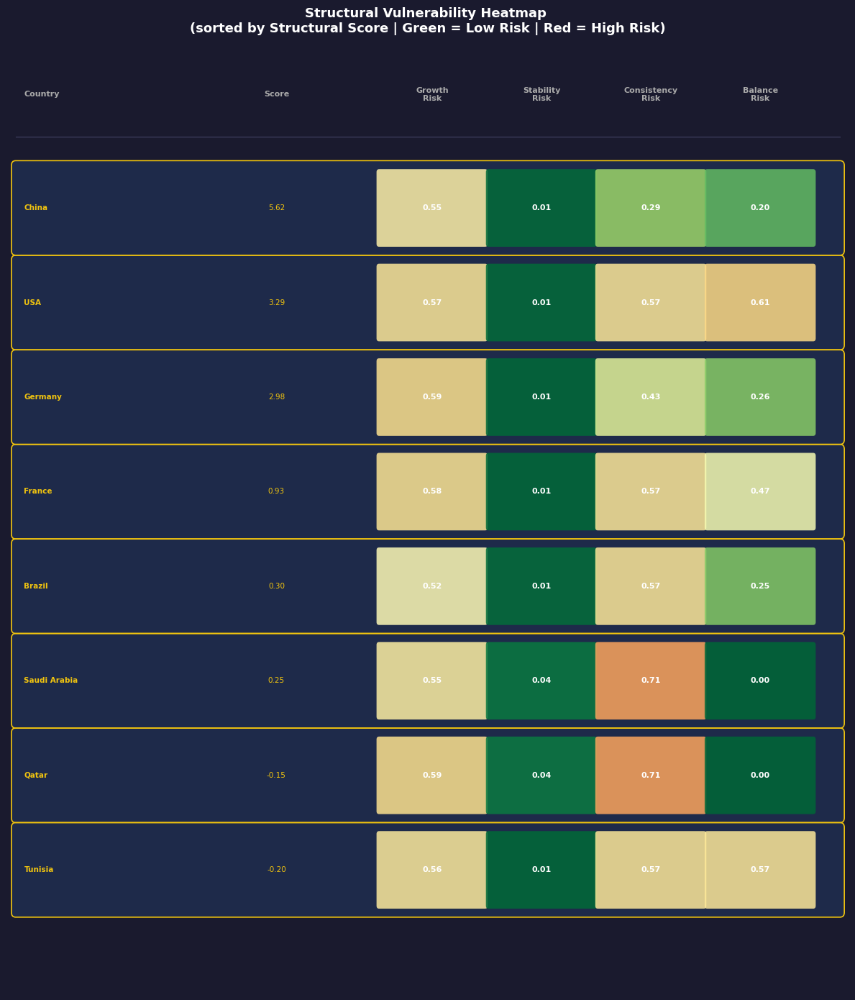

In [242]:
plot_vulnerability_heatmap(df_structural, countries)

**Key Insights**

- `Vulnerability is multi-dimensional` — a country can score low risk on
  growth but high risk on balance, revealing hidden structural weaknesses
  that a single composite score would mask.

- `Large economies tend to show higher Balance Risk` — persistent trade
  deficits (USA, France) reflect structural consumption patterns,
  not necessarily economic weakness.

- `High Stability Risk countries` are often commodity-dependent economies
  whose exports fluctuate with global price cycles (energy, metals, agriculture).

- `The radar chart reveals trade-offs` — countries near the world average
  on all dimensions are structurally neutral; outliers on specific dimensions
  warrant deeper country-level investigation.

- `Structural Score vs Vulnerability` — a high structural score does not
  guarantee low vulnerability across all dimensions. Some Global Leaders
  carry significant Balance or Stability Risk despite their overall strength.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.6 Positioning
</div>

Quadrants provide a **relative visual positioning**, while classification is based on absolute economic thresholds.

Three complementary quadrant analyses:
- **Static** : export_share vs coverage_ratio → size + balance
- **Dynamic** : z_cagr_export vs z_volatility_export → growth + risk
- **Strategic** : export_share vs cagr_export → BCG-style positioning
- **Profile** : meta_profile synthesis across all dimensions

In [251]:
p90 = df_trade["export_share"].quantile(0.90)
p75 = df_trade["export_share"].quantile(0.75)
p50 = df_trade["export_share"].quantile(0.50)

def classify_size(row):
    if row["export_share"] >= p90:        return "Global Leaders"
    elif row["export_share"] >= p75:      return "Major Players"
    elif row["export_share"] >= p50:      return "Mid Players"
    else:                                 return "Small Players"
        
def classify_size(share):
    if share >= 5:        return "Global Leaders"
    elif share >= 1:      return "Major Players"
    elif share >= 0.1:    return "Mid Players"
    else:                 return "Small Players"

def classify(row):
    # share
    if row["export_share"] >= 5:        size = "Leader"
    elif row["export_share"] >= 1:      size = "Major"
    elif row["export_share"] >= 0.1:    size = "Mid"
    else:                               size = "Small"
    # Balance
    if row["trade_balance"] >= 0:       balance = "Surplus"
    else:                               balance = "Deficit"
    return f"{size} - {balance}"

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 4.6.1 Quadrant Classification
</div>

In [255]:
# Static Quadrant: export_share vs coverage_ratio
median_share    = df_structural['export_share_structural'].median()
median_coverage = df_structural['coverage_ratio_structural'].median()

def classify_static_quadrant(row):
    large   = row['export_share_structural'] >= median_share
    surplus = row['coverage_ratio_structural'] >= median_coverage
    if large and surplus:         return 'Dominant'
    elif large and not surplus:   return 'Vulnerable'
    elif not large and surplus:   return 'Balanced'
    else:                         return 'Marginal'

df_structural['static_quadrant'] = df_structural.apply(classify_static_quadrant, axis=1)

# Dynamic Quadrant: z_cagr_export vs z_volatility_export
def classify_dynamic_quadrant(row):
    high_growth = row['z_cagr_export'] >= 0
    low_vol     = row['z_volatility_export'] <= 0
    if high_growth and low_vol:         return 'Star'
    elif high_growth and not low_vol:   return 'Risky Grower'
    elif not high_growth and low_vol:   return 'Stable Stagnant'
    else:                               return 'Declining'

df_structural['dynamic_quadrant'] = df_structural.apply(classify_dynamic_quadrant, axis=1)

# Strategic Quadrant: export_share vs cagr_export 
def classify_strategic_quadrant(row):
    large       = row['export_share_structural'] >= 1.0
    high_growth = row['cagr_export'] >= 0
    if large and high_growth:         return 'Star'
    elif large and not high_growth:   return 'Cash Cow'
    elif not large and high_growth:   return 'Emerging'
    else:                             return 'Marginal'

df_structural['strategic_quadrant'] = df_structural.apply(classify_strategic_quadrant, axis=1)

# Trade Profile: combine 3 quadrants
df_structural['trade_profile'] = (df_structural['static_quadrant'] + ' | ' +  df_structural['dynamic_quadrant'] + ' | ' + df_structural['strategic_quadrant'])

# Meta Profile: 6 profiles 
def compute_meta_profile(row):
    static    = row['static_quadrant']
    dynamic   = row['dynamic_quadrant']
    strategic = row['strategic_quadrant']

    if static == 'Dominant' and strategic == 'Stars':                                                    return 'Global Leader'
    elif static in ['Dominant', 'Vulnerable'] and  strategic in ['Stars', 'Cash Cow']:                   return 'Established Power'
    elif strategic == 'Emerging' and dynamic == 'Star':                                                  return 'Rising Challenger'
    elif strategic == 'Emerging' and dynamic == 'Risky Grower':                                          return 'Volatile Emerging'
    elif dynamic == 'Declining' or (strategic == 'Marginal' and dynamic == 'Stable Stagnant'):           return 'Peripheral'
    else:                                                                                                return 'Transitional'

df_structural['meta_profile'] = df_structural.apply(compute_meta_profile, axis=1)

In [257]:
# Summary
print('Static Quadrant:')
print(df_structural['static_quadrant'].value_counts())
print(50* "-")
print('\nDynamic Quadrant:')
print(df_structural['dynamic_quadrant'].value_counts())
print(50* "-")
print('\nStrategic Quadrant:')
print(df_structural['strategic_quadrant'].value_counts())
print(50* "-")
print('\nMeta Profile:')
print(df_structural['meta_profile'].value_counts())

Static Quadrant:
static_quadrant
Dominant      72
Marginal      71
Vulnerable    20
Balanced      20
Name: count, dtype: int64
--------------------------------------------------

Dynamic Quadrant:
dynamic_quadrant
Stable Stagnant    76
Star               69
Declining          26
Risky Grower       12
Name: count, dtype: int64
--------------------------------------------------

Strategic Quadrant:
strategic_quadrant
Emerging    131
Star         28
Marginal     24
Name: count, dtype: int64
--------------------------------------------------

Meta Profile:
meta_profile
Transitional         71
Rising Challenger    58
Peripheral           42
Volatile Emerging    12
Name: count, dtype: int64


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 4.6.2 Structural Positioning
</div>

In [260]:
def plot_static_quadrant_animated(df_trade, countries, interval=1200):
    """    Animated Static Quadrant with trajectory. Axes : export_share vs coverage_ratio. threshold : export_share = 1.0%, coverage_ratio = 1.0    """

    df_c      = df_trade[df_trade['country_name'].isin(countries)].copy()
    years     = sorted(df_c['year'].unique())
    threshold_x = 1.0   # export_share
    threshold_y = 1.0   # coverage_ratio

    # Couleurs
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    # Limites axes
    xlim = (-1, df_c['export_share'].max() * 1.05)
    ylim = (-1, df_c['coverage_ratio'].max() * 1.05)
    # Figure
    fig, ax = plt.subplots(figsize=(14, 10))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#444466')

    # Quadrant backgrounds
    ax.fill_betweenx([threshold_y, ylim[1]], threshold_x, xlim[1], color='#1a3a2a', alpha=0.35)  # Dominant
    ax.fill_betweenx([ylim[0], threshold_y], threshold_x, xlim[1], color='#3a2a1a', alpha=0.35)  # Vulnerable
    ax.fill_betweenx([threshold_y, ylim[1]], xlim[0], threshold_x, color='#1a2a3a', alpha=0.35)  # Balanced
    ax.fill_betweenx([ylim[0], threshold_y], xlim[0], threshold_x, color='#2a1a1a', alpha=0.35)  # Marginal

    # Labels quadrants
    quadrant_labels = [
        ('Dominant\n(Large & Surplus)',  threshold_x + (xlim[1] - threshold_x) * 0.5,  threshold_y + (ylim[1] - threshold_y) * 0.75),
        ('Vulnerable\n(Large & Deficit)', threshold_x + (xlim[1] - threshold_x) * 0.5,  ylim[0]     + (threshold_y - ylim[0])  * 0.25),
        ('Balanced\n(Small & Surplus)',   xlim[0]     + (threshold_x - xlim[0])  * 0.5,  threshold_y + (ylim[1] - threshold_y) * 0.75),
        ('Marginal\n(Small & Deficit)',   xlim[0]     + (threshold_x - xlim[0])  * 0.5,  ylim[0]     + (threshold_y - ylim[0])  * 0.25),
    ]
    for lbl, x, y in quadrant_labels:
        ax.text(x, y, lbl, fontsize=8.5, color='#cccccc', ha='center', va='center', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))

    # Lines thresholds
    ax.axvline(x=threshold_x, color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    ax.axhline(y=threshold_y, color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    
    ax.set_xlabel('Export Share (%) — Trade Size', fontsize=10)
    ax.set_ylabel('Coverage Ratio (X/M) — Trade Balance', fontsize=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(color='#444466', linewidth=0.4, alpha=0.4)

    # Animated Elements per country
    trail_lines  = {}
    points       = {}
    annotations  = {}

    for country in countries:
        c = color_map[country]
        trail_lines[country], = ax.plot([], [], color=c, linewidth=1.8, alpha=0.6, zorder=1)
        points[country]       = ax.scatter([], [], color=c, s=100, zorder=4, edgecolors='white', linewidths=0.8)
        annotations[country]  = ax.annotate(country, xy=(0, 0), xytext=(8, 4), textcoords='offset points', fontsize=8, color=c, fontweight='bold', 
                                            bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=5)
    # Animated Title
    title = ax.set_title('', fontsize=13, fontweight='bold', color='white', pad=15)
    # Legend
    legend_elements = [plt.Line2D([0], [0], color=color_map[c], linewidth=2, marker='o', markersize=7, label=c) for c in countries]
    ax.legend(handles=legend_elements, fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='best')
    year_text = ax.text(0.95, 0.95, '', transform=ax.transAxes, fontsize=28, color='white', ha='right', va='top', fontweight='bold', alpha=0.4)
    
    # init function
    def init():
        for country in countries:
            trail_lines[country].set_data([], [])
            points[country].set_offsets(np.empty((0, 2)))
            annotations[country].set_position((0, 0))
        title.set_text('')
        return list(trail_lines.values()) + list(points.values()) + list(annotations.values()) + [title]

    # update Function
    def update(frame):
        year = years[frame]
        title.set_text(f'Static Positioning — Export Share vs Coverage Ratio  |  Year : {year}')
        year_text.set_text(str(year))
        for country in countries:
            df_country = df_c[df_c['country_name'] == country].sort_values('year')
            df_till    = df_country[df_country['year'] <= year]
            if df_till.empty: continue
            x_trail = df_till['export_share'].values
            y_trail = df_till['coverage_ratio'].values
            # Cumulated trajectory
            trail_lines[country].set_data(x_trail, y_trail)
            # Current Point
            points[country].set_offsets([[x_trail[-1], y_trail[-1]]])
            # Annotation
            annotations[country].xy = (x_trail[-1], y_trail[-1])
        return list(trail_lines.values()) + list(points.values()) + list(annotations.values()) + [title]

    # Animation
    anim = FuncAnimation(fig, update, frames=len(years), init_func=init, interval=interval, blit=True, repeat=True)
    plt.tight_layout()
    anim.save('../Figures/Trade/F_4_6_2_positioning_static_quadrant.gif', writer='pillow', dpi=120)
    plt.show()
    return anim

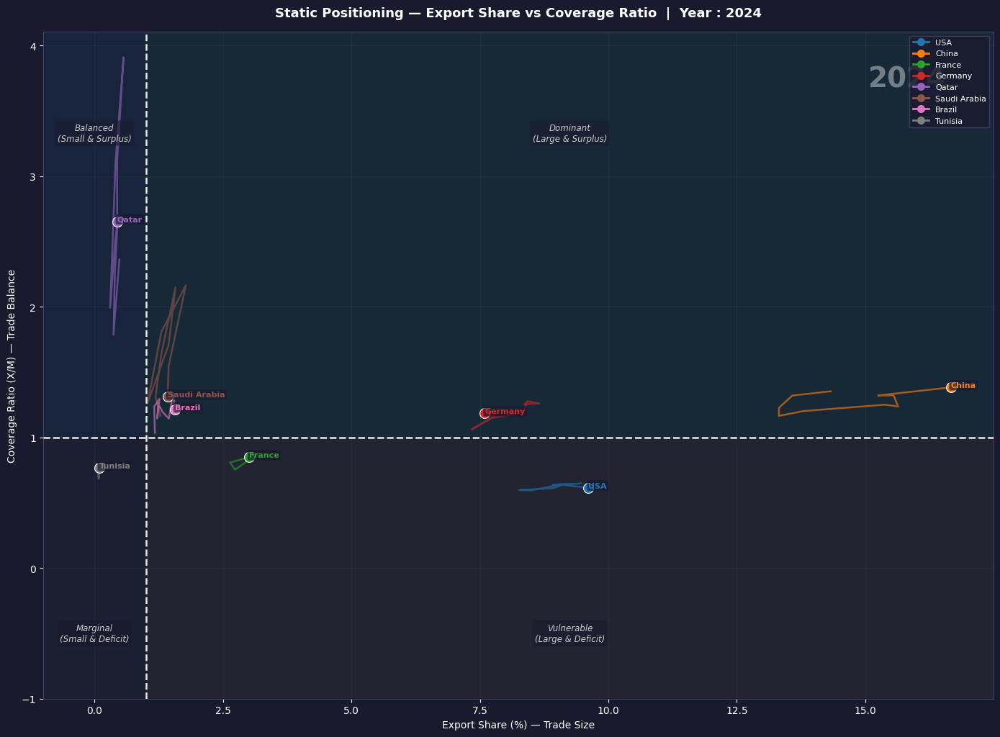

In [262]:
anim = plot_static_quadrant_animated(df_trade, countries, interval=1200)

**Global Observations**
- The static quadrant reveals the structural position of each country at the intersection of trade size and balance orientation.
- The majority of countries cluster in the `Marginal / Balanced quadrant` (export_share < 1%),
  confirming that global trade is highly concentrated among a small number of nations.
- Only `China and the USA` clearly dominate by size, yet they sit on `opposite sides`
  of the coverage ratio line — illustrating two fundamentally different trade models.
- The `coverage_ratio = 1.0` threshold acts as a `structural divide`: most countries
  remain consistently above or below it across all years.

**Country Specific Insights**
| Country | Quadrant | Key Observation |
|---|---|---|
| **China** | Dominant | Large share + strong surplus — archetypal export powerhouse |
| **USA** | Vulnerable | Massive size but structural deficit — consumption-driven economy |
| **France** | Marginal / Balanced | Modest share, near-deficit coverage ratio |
| **Qatar** | Balanced (Small & Surplus) | Small share but very high coverage ratio — energy-driven export efficiency |
| **Tunisia** | Marginal | Small share and persistent deficit — import-dependent developing economy |


**Trajectory Insights**
- `Balance type is structurally sticky`: countries rarely cross the `coverage_ratio = 1.0` line,
  suggesting that trade balance profiles are persistent structural features, not temporary fluctuations.
- `Post-2020 shift` is visible for most countries — the COVID shock caused a temporary contraction
  followed by a strong rebound, visible as a reversal in trajectory around 2020–2021.
- `China's share keeps drifting rightward` over time, reflecting its increasing dominance
  in global exports across the entire period.
- `Qatar shows high vertical volatility` in coverage ratio — heavily dependent on
  commodity price cycles (energy exports).

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 4.6.3 Dynamic Positioning
</div>

In [267]:
def plot_dynamic_quadrant(df_structural, countries, annotate=True):
    """
    Dynamic Quadrant : Export Growth (z_cagr_export) vs Export Volatility (z_volatility_export)
    Color : resilience_export. Thresholds : z = 0 for both axes
    All countries in background, highlighted countries annotated
    """

    df_all  = df_structural.copy()
    df_high = df_structural[df_structural['country_name'].isin(countries)].copy()

    # ── Colors ────────────────────────────────────────────────────────────────
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, 10))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#444466')
    ax.set_title('Dynamic Positioning — Export Growth vs Export Volatility\n' 'Color: Resilience Score | Size: CAGR Magnitude',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Axis limits ───────────────────────────────────────────────────────────
    xlim = (df_all['cagr_export'].quantile(0.01) * 1.1, df_all['cagr_export'].quantile(0.98))
    ylim = (df_all['volatility_export'].quantile(0.01) * 0.1, df_all['volatility_export'].quantile(0.95))

    # ── Quadrant backgrounds ──────────────────────────────────────────────────
    ax.fill_betweenx([0, ylim[1]], 0, xlim[1], color='#1a3a2a', alpha=0.35)  # Star
    ax.fill_betweenx([ylim[0], 0], 0, xlim[1], color='#1a2a3a', alpha=0.35)  # Stable Stagnant
    ax.fill_betweenx([0, ylim[1]], xlim[0], 0,  color='#3a2a1a', alpha=0.35)  # Risky Grower
    ax.fill_betweenx([ylim[0], 0], xlim[0], 0,  color='#2a1a1a', alpha=0.35)  # Declining

    quadrant_labels = [
        ('Star\n(High Growth + Low Volatility)',           xlim[1] * 0.5,                  ylim[0] * 10 ),
        ('Stable Stagnant\n(Low Growth + Low Volatility)',  xlim[0] + (0 - xlim[0]) * 0.5, ylim[0] * 10),
        ('Risky Grower\n(High Growth + High Volatility)', xlim[1] * 0.5,                  ylim[1] * 0.5),
        ('Declining\n(Low Growth + High Volatility)',      xlim[0] + (0 - xlim[0]) * 0.5, ylim[1] * 0.5)
    ]
    for lbl, x, y in quadrant_labels:
        ax.text(x, y, lbl, fontsize=8.5, color='#cccccc', ha='center', va='center', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))

    # ── Threshold lines ───────────────────────────────────────────────────────
    threshold_x = 0   # cagr = 0 → positive vs negative growth
    threshold_y = df_all['volatility_export'].median()  # median volatility
    ax.axvline(x==threshold_x, color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    ax.axhline(y==threshold_y, color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    ax.plot([xlim[0], xlim[1]], [threshold_y, threshold_y],color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    
    # ── All countries background ──────────────────────────────────────────────
    ax.scatter(df_all['cagr_export'], df_all['volatility_export'], c='#aaaaaa', s=150, alpha=0.3, zorder=1, edgecolors='none')

    # ── Highlighted countries ─────────────────────────────────────────────────
    sc = ax.scatter(df_high['cagr_export'], df_high['volatility_export'], c=df_high['resilience_export'],
                    cmap='RdYlGn', s=df_high['cagr_export'].abs() * 100 + 100, zorder=3, edgecolors='white', linewidths=0.8,
                    vmin=df_all['resilience_export'].quantile(0.05), vmax=df_all['resilience_export'].quantile(0.95))

    # ── Annotations ───────────────────────────────────────────────────────────
    if annotate:
        for _, row in df_high.iterrows():
            ax.annotate(row['country_name'],
                        xy=(row['cagr_export'], row['volatility_export']), xytext=(8, 4), textcoords='offset points',
                        fontsize=8, color=color_map.get(row['country_name'], 'white'),fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.2',facecolor='#1a1a2e',alpha=0.7, edgecolor='none'),zorder=4)

    # ── Colorbar ──────────────────────────────────────────────────────────────
    cbar = plt.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label('Resilience Score', color='white', fontsize=9)
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

    # ── Axes labels ───────────────────────────────────────────────────────────
    ax.set_xlabel('Export Growth — CAGR', fontsize=10)
    ax.set_ylabel('Export Volatility', fontsize=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(color='#444466', linewidth=0.4, alpha=0.4)

    # ── Legend ────────────────────────────────────────────────────────────────
    legend_elements = [
        plt.scatter([], [], s=150,  c='white', alpha=0.3, label='All countries'),
        plt.scatter([], [], s=250, c='white', edgecolors='white', label='Highlighted countries'),
    ]
    ax.legend(handles=legend_elements, fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='best')

    plt.tight_layout()
    plt.savefig('../Figures/Trade/F_4_6_3_dynamic_quadrant.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

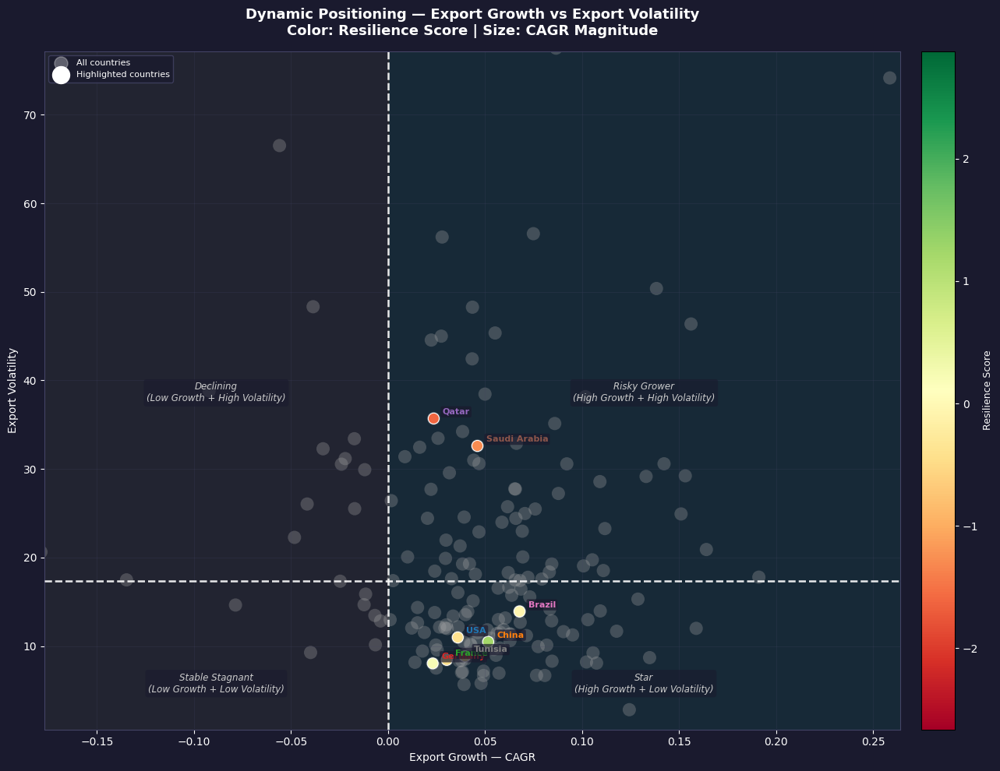

In [268]:
plot_dynamic_quadrant(df_structural, countries, annotate=True)

**Global Observations**
- Countries identified as "Volatile Performers" in the dynamic quadrant
often appear as "Emerging Challengers" in the strategic quadrant,
highlighting a trade-off between growth and stability.
- Most countries cluster near the center (z ≈ 0 on both axes), confirming that the majority
  of nations have average growth and average volatility relative to the global distribution.
- True outliers — countries with extreme growth or extreme volatility — are rare,
  making them immediately identifiable as structural exceptions.
- High resilience scores (green) tend to appear in the `Star quadrant`,
  confirming that resilience and stable growth are correlated.
  

**Quadrant Interpretation**
| Quadrant | Profile | Typical Countries |
|---|---|---|
| `Star` | High growth + Low volatility | Consistent export powerhouses |
| `Risky Grower` | High growth + High volatility | Commodity-driven or emerging economies |
| `Stable Stagnant` | Low growth + Low volatility | Mature economies with limited expansion |
| `Declining` | Low growth + High volatility | Structurally weakening exporters |

**Key Insights**
- `Resilience acts as a differentiator within quadrants` — two countries in the same
  quadrant with different resilience scores represent fundamentally different risk profiles.
- Countries in the `Risky Grower quadrant with low resilience` (dark color) are the
  most vulnerable — high growth but unsustainable and fragile.
- `Point size reflects CAGR magnitude` — large points in the Star quadrant
  are the most strategically significant exporters globally.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 4.6.4 Strategic Positioning
</div>

In [273]:
def plot_strategic_quadrant(df_structural, countries, annotate=True):
    """
    Strategic Quadrant : Export Share vs CAGR Export (BCG-style)
    Color : structural_score. Thresholds : export_share = 1.0%, cagr = 0
    All countries in background, highlighted countries annotated
    """
    df_all  = df_structural.copy()
    df_high = df_structural[df_structural['country_name'].isin(countries)].copy()

    # ── Colors ────────────────────────────────────────────────────────────────
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}
    threshold_x = 1.0  # export_share %
    threshold_y = 0.0  # cagr = 0

    # ── Axis limits ───────────────────────────────────────────────────────────
    xlim = (0, df_all['export_share_structural'].max() * 1.1)
    ylim = (df_all['cagr_export'].min() * 1.1, df_all['cagr_export'].max() * 1.1)

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, 10))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#444466')

    ax.set_title('Strategic Positioning — Export Share vs Export Growth \n'
    'Color: Structural Score | Size: Export Share Magnitude',fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Quadrant backgrounds ──────────────────────────────────────────────────
    ax.fill_betweenx([threshold_y, ylim[1]], threshold_x, xlim[1], color='#1a3a2a', alpha=0.35)  # Stars
    ax.fill_betweenx([ylim[0], threshold_y], threshold_x, xlim[1], color='#3a2a1a', alpha=0.35)  # Cash Cows
    ax.fill_betweenx([threshold_y, ylim[1]], 0, threshold_x, color='#1a2a3a', alpha=0.35)  # Emerging
    ax.fill_betweenx([ylim[0], threshold_y], 0, threshold_x, color='#2a1a1a', alpha=0.35)  # Marginal

    quadrant_labels = [
        ('Emerging\n(Small & Growing)',       threshold_x * 0.5,                           ylim[1] * 0.75),
        ('Star\n(Large & Growing)',  threshold_x + (xlim[1] - threshold_x) * 0.5, ylim[1] * 0.75),
        ('Marginal\n(Small & Stagnant)',    threshold_x * 0.5,                            ylim[0] * 0.5),
        ('Cash Cows\n(Large & Stagnant)',   threshold_x + (xlim[1] - threshold_x) * 0.5,  ylim[0] * 0.5),
    ]
    for lbl, x, y in quadrant_labels:
        ax.text(x, y, lbl, fontsize=8.5, color='#cccccc', ha='center', va='center', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))

    # ── Threshold lines ───────────────────────────────────────────────────────
    ax.axvline(x=threshold_x, color='white', linewidth=1.8, linestyle='--', alpha=0.9, zorder=5)
    ax.plot([xlim[0], xlim[1]], [threshold_y, threshold_y],color='white',linewidth=1.8,linestyle='--',alpha=0.9,zorder=5)

    # ── All countries background ──────────────────────────────────────────────
    ax.scatter(df_all['export_share_structural'], df_all['cagr_export'], c='#aaaaaa', s=80, alpha=0.3, zorder=1, edgecolors='none')

    # ── Highlighted countries ─────────────────────────────────────────────────
    sc = ax.scatter(df_high['export_share_structural'], df_high['cagr_export'],
                    c=df_high['structural_score'], cmap='RdYlGn', s=df_high['export_share_structural'] * 80 + 80,
                    zorder=3, edgecolors='white', linewidths=0.8,
                    vmin=df_all['structural_score'].quantile(0.05), vmax=df_all['structural_score'].quantile(0.95))

    # ── Annotations ───────────────────────────────────────────────────────────
    if annotate:
        for _, row in df_high.iterrows():
            ax.annotate(row['country_name'], xy=(row['export_share_structural'], row['cagr_export']),
                        xytext=(8, 4), textcoords='offset points', fontsize=8, color=color_map.get(row['country_name'], 'white'),
                        fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e',
                        alpha=0.7, edgecolor='none'), zorder=4)

    # ── Colorbar ──────────────────────────────────────────────────────────────
    cbar = plt.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label('Structural Score', color='white', fontsize=9)
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

    # ── Axes labels ───────────────────────────────────────────────────────────
    ax.set_xlabel('Export Share (%) — Trade Size', fontsize=10)
    ax.set_ylabel('Export Growth — CAGR (%)', fontsize=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(color='#444466', linewidth=0.4, alpha=0.4)

    # ── Legend ────────────────────────────────────────────────────────────────
    legend_elements = [plt.scatter([], [], s=50,  c='#aaaaaa', alpha=0.4, label='All countries'),
        plt.scatter([], [], s=150, c='white', edgecolors='white', label='Highlighted countries')]
    ax.legend(handles=legend_elements,fontsize=8,facecolor='#1a1a2e',edgecolor='#444466',labelcolor='white',loc='best')

    plt.tight_layout()
    plt.savefig('../Figures/Trade/F_4_6_4_strategic_quadrant.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

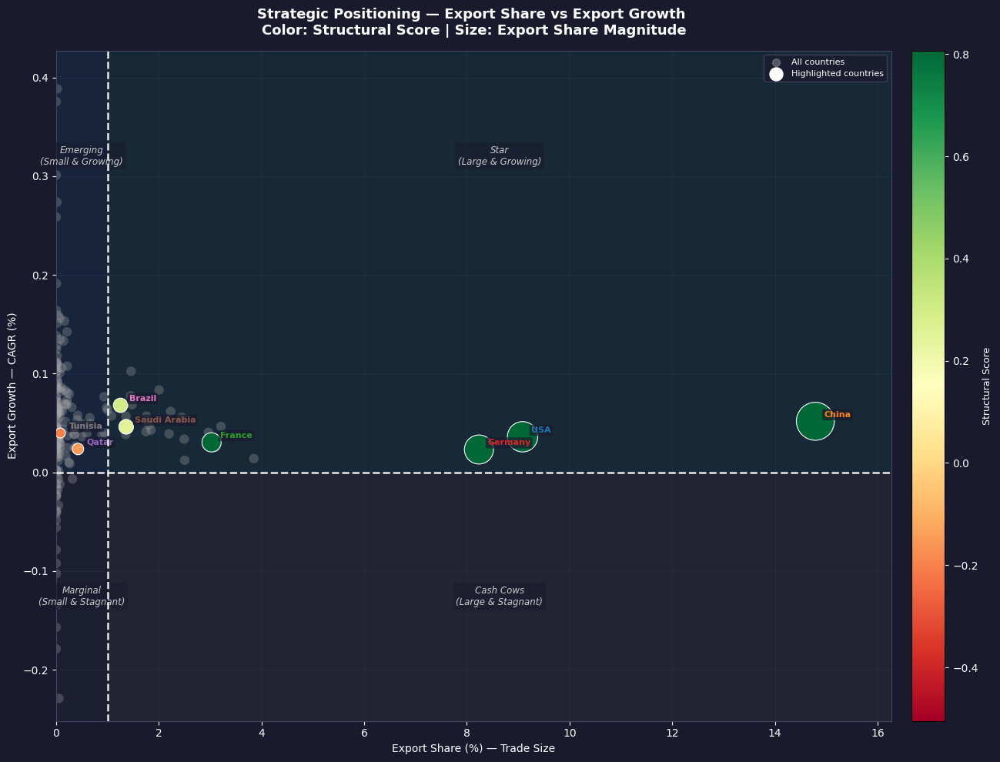

In [274]:
plot_strategic_quadrant(df_structural, countries, annotate=True)

**Global Observations**
- The vast majority of countries are in the `Emerging or Marginal quadrants`
  (export_share < 1%), confirming extreme concentration of global trade.
- The `Stars quadrant` is almost empty — only a handful of nations combine
  large share AND positive growth, making them the true strategic leaders.
- Structural score (color) strongly correlates with position —
  green points dominate the right side, red points dominate the left.
- The `Marginal quadrant is nearly empty` — this is analytically expected:
  the 2015–2024 period reflects overall global trade expansion, meaning even
  small traders achieved positive CAGR. A negative CAGR over this full period
  signals a truly structural decline, affecting only a handful of countries.

**Quadrant Interpretation**
| Quadrant | Profile | Strategic Implication |
|---|---|---|
| `Star` | Large & Growing | Global trade leaders — expanding dominance |
| `Cash Cows` | Large & Stagnant | Established powers losing momentum |
| `Emerging` | Small & Growing | Future challengers — watch closely |
| `Marginal` | Small & Stagnant | Limited strategic relevance |

**Key Insights**
- `China and Germany` are likely in the Stars quadrant —
  combining scale with sustained growth.
- `USA and France` may sit in Cash Cows — large share but slowing CAGR,
  reflecting mature export structures.
- `Small high-growth countries` in the Emerging quadrant with high structural
  scores (green) represent the most interesting future challengers.
- `Point size reflects export share magnitude` — the largest points
  in Stars quadrant are the most strategically dominant nations globally.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 4.6.5 Profile Positioning
</div>

In [281]:
# ── Static Quadrant ───────────────────────────────────────────────────────────
def classify_static(row):
    x = row['export_share_structural']
    y = row['coverage_ratio_structural']
    if x >= 1.0 and y >= 1.0:   return 'Dominant'
    elif x >= 1.0 and y < 1.0:  return 'Vulnerable'
    elif x < 1.0 and y >= 1.0:  return 'Balanced'
    else:                        return 'Marginal'

# ── Dynamic Quadrant ──────────────────────────────────────────────────────────
threshold_vol = df_structural["volatility_export"].median()
def classify_dynamic(row):
    x = row['cagr_export']
    y = row['volatility_export']
    if x >= 0 and y <= threshold_vol:    return 'Star'
    elif x >= 0 and y > threshold_vol:   return 'Risky Grower'
    elif x < 0 and y <= threshold_vol:   return 'Stable Stagnant'
    else:                                return 'Declining'

# ── Strategic Quadrant ────────────────────────────────────────────────────────
def classify_strategic(row):
    x = row['export_share_structural']
    y = row['cagr_export']
    if x >= 1.0 and y >= 0:   return 'Star'
    elif x >= 1.0 and y < 0:  return 'Cash Cow'
    elif x < 1.0 and y >= 0:  return 'Emerging'
    else:                     return 'Marginal'

df_structural['static_quadrant']   = df_structural.apply(classify_static,     axis=1)
df_structural['dynamic_quadrant']  = df_structural.apply(classify_dynamic,    axis=1)
df_structural['strategic_quadrant'] = df_structural.apply(classify_strategic, axis=1)

In [284]:
# Level 1 : Full combined profile 
df_structural['trade_profile'] = (df_structural['static_quadrant']   + ' | ' +  df_structural['dynamic_quadrant']  +
                                  ' | ' + df_structural['strategic_quadrant'])
# Level 2 : Meta-profile 
def compute_meta_profile(row):
    static    = row['static_quadrant']
    dynamic   = row['dynamic_quadrant']
    strategic = row['strategic_quadrant']

    
    if static == 'Dominant' and strategic == 'Star':                                           return 'Global Leader'     
    elif (static in ['Dominant', 'Vulnerable']) and strategic in ['Star', 'Cash Cow']:        return 'Established Power' 
    elif strategic == 'Emerging' and dynamic == 'Star':                                        return 'Rising Challenger' # small but genuinely dynamic AND stable
    elif strategic == 'Emerging' and dynamic == 'Risky Grower':                                return 'Volatile Emerging' # small + growing but unstable
    elif dynamic == 'Declining' or (strategic == 'Marginal' and dynamic == 'Stable Stagnant'): return 'Peripheral'
    else:                                                                                      return 'Transitional'

df_structural['meta_profile'] = df_structural.apply(compute_meta_profile, axis=1)

In [285]:
# ── Check distribution ────────────────────────────────────────────────────────
df_structural['meta_profile'].value_counts()

meta_profile
Volatile Emerging    73
Rising Challenger    58
Peripheral           24
Global Leader        17
Established Power    11
Name: count, dtype: int64

In [286]:
def plot_profile_positioning(df_structural, countries, annotate=True):
    """
    Profile Positioning — Meta Profile visualization
    Axes : export_share_structural vs structural_score
    Color : meta_profile. Size  : cagr_export magnitude
    """
    df_all  = df_structural.copy()
    df_high = df_structural[df_structural['country_name'].isin(countries)].copy()
    # ── Meta profile colors ───────────────────────────────────────────────────
    meta_colors = {
        'Global Leader':      '#2ecc71',   
        'Established Power':  '#3498db',   
        'Rising Challenger':  '#f1c40f',   
        'Volatile Emerging':  '#f39c12',   
        'Peripheral':         '#e74c3c',   
        'Transitional':       '#9b59b6' 
    }

    # ── Figure : 2 subplots ───────────────────────────────────────────────────
    fig = plt.figure(figsize=(18, 10))
    fig.patch.set_facecolor('#1a1a2e')

    gs  = fig.add_gridspec(1, 2, width_ratios=[2, 1], wspace=0.05)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])

    for ax in [ax1, ax2]:
        ax.set_facecolor('#16213e')
        ax.tick_params(colors='white')
        ax.xaxis.label.set_color('white')
        ax.yaxis.label.set_color('white')
        for spine in ax.spines.values(): spine.set_edgecolor('#444466')

    fig.suptitle('Trade Profile Positioning — Meta Profile Classification',fontsize=15, fontweight='bold', color='white', y=1.01)

    # ── Scatter plot — all countries ──────────────────────────────────────────
    for profile, color in meta_colors.items():
        df_p = df_all[df_all['meta_profile'] == profile]
        ax1.scatter(df_p['export_share_structural'], df_p['structural_score'],  c=color, s=df_p['cagr_export'].abs() * 100 + 50,
                    alpha=0.5, edgecolors='none', zorder=1, label=profile)

    # Highlighted countries
    for _, row in df_high.iterrows():
        color = meta_colors.get(row['meta_profile'], 'white')
        ax1.scatter(row['export_share_structural'], row['structural_score'],
                    c=color, s=row['cagr_export'] * 100 + 200, edgecolors='white', linewidths=1.2, zorder=3)
        if annotate:
            ax1.annotate(row['country_name'], xy=(row['export_share_structural'], row['structural_score']),
                         xytext=(8, 4), textcoords='offset points', fontsize=8, color=color, fontweight='bold',
                         bbox=dict(boxstyle='round,pad=0.2',facecolor='#1a1a2e',alpha=0.7,edgecolor='none'), zorder=4)

    ax1.set_xlabel('Export Share (%) — Trade Size', fontsize=10)
    ax1.set_ylabel('Structural Score', fontsize=10)
    ax1.grid(color='#444466', linewidth=0.4, alpha=0.4)
    ax1.legend(fontsize=8, facecolor='#1a1a2e', edgecolor='#444466',
               labelcolor='white', loc='upper left', title='Meta Profile', title_fontsize=8)

    # ── Bar chart — distribution ──────────────────────────────────────────────
    dist = df_all['meta_profile'].value_counts().reindex(meta_colors.keys()).dropna()
    bars = ax2.barh(dist.index, dist.values,color=[meta_colors[p] for p in dist.index],edgecolor='none', height=0.6)

    for bar, val in zip(bars, dist.values):
        ax2.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
                 str(int(val)), va='center', fontsize=9,color='white', fontweight='bold')

    ax2.set_xlabel('Number of Countries', fontsize=10)
    ax2.set_title('Profile Distribution', fontsize=11,color='white', pad=10)
    ax2.tick_params(axis='y', labelsize=9, labelcolor='white')
    ax2.grid(axis='x', color='#444466', linewidth=0.4, alpha=0.4)
    ax2.set_xlim(0, dist.max() * 1.2)

    plt.tight_layout()
    plt.savefig('../Figures/Trade/F_4_6_5_profile_positioning.png', dpi=150,bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

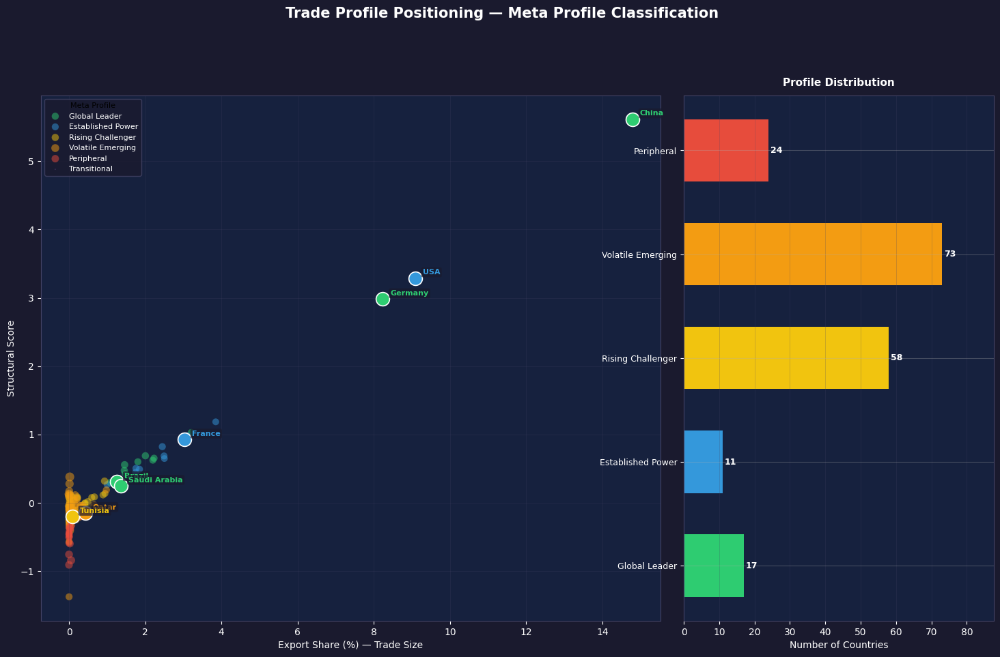

In [287]:
plot_profile_positioning(df_structural, countries, annotate=True)

**Profile Definitions**

| Meta Profile | Criteria | Count |
|---|---|---|
| **Global Leader** | Dominant share + positive CAGR (Stars quadrant) | 17 |
| **Established Power** | Large share but deficit or slowing growth | 11 |
| **Rising Challenger** | Small share + stable dynamic growth (Star quadrant) | 58 |
| **Volatile Emerging** | Small share + high growth but unstable (Risky Grower) | 73 |
| **Peripheral** | Declining or structurally stagnant | 24 |

**Key Insights**

- **Global trade leadership is export-centric by design** — this classification
  is based on export performance, not overall economic size. Countries combining
  dominant export share with positive CAGR rank as Global Leaders regardless
  of their absolute economic weight.

- **USA and China as Established Powers** reflects a structural reality —
  both are massive traders but show signs of slowing export growth and/or
  persistent trade imbalances, a natural evolution for mature large economies.

- **Rising Challengers (58 countries)** represent the most reliable dynamic
  segment — small in absolute terms but growing consistently without boom-bust
  cycles. These are the most promising candidates for future structural shifts.

- **Volatile Emerging (73 countries)** grow fast but irregularly — high
  potential but structurally fragile. They require individual analysis before
  inclusion in any strategic portfolio.

- **Peripheral countries (24)** are characterized by declining exports
  combined with stagnation — the most structurally vulnerable group,
  often small commodity-dependent economies.

**Important Caveat**
This classification is **export-driven and period-specific (2015–2024)**.
The 2020 COVID shock affects CAGR calculations — countries with strong
pre-2020 performance may be downgraded due to the sharp contraction,
while fast post-2020 recoveries may inflate scores for some nations.
The distinction between Rising Challenger and Volatile Emerging
is particularly sensitive to this effect.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.7 Save Table
</div>

In [295]:
df_structural.to_csv("../Analysis_files/Trade/df_structural.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 5. Global Trade Conclusions
</div>

**Volume & Cycles**
Global exports grew from **$21.1T (2015) to $28.0T (2024)** (+32%), but the trajectory
was far from linear. The 2019–2020 contraction (−5.4%) was sharply reversed by a
+22.7% rebound in 2021. The subsequent deceleration (−1.2% in 2023, −3.2% in 2024)
signals a structural cooling beyond post-COVID normalization.

**Concentration & Hierarchy**
Global trade remains highly concentrated : the top 10 exporters control **56% of
global export volume** (2024), down from 59% in 2015. The HHI fell from 765 to 502
over the period, confirming a gradual de-concentration — yet hierarchy positions are
remarkably frozen (Spearman ρ > 0.992 every year). Trade volumes shift; rankings do not.

**Country Profiles**
Structural analysis across 187 countries reveals a sharply asymmetric distribution :
only **28 countries (15%) qualify as Strong**, while 63 cluster in Moderate territory.
The Risk-Return Matrix identifies 19 Stable Stars (high growth, low volatility)
against 19 Vulnerable economies (low growth, high volatility) — structurally exposed
with little dynamic upside.

**Combined Assessment**
Crossing global performance (F) with bilateral resilience (G), only **20 countries
(10.7%) reach Global Champion status** — combining trade strength with bilateral
independence. Germany leads (0.996), followed by UK, Spain and China. At the opposite
end, 47 Fragile economies (25%) face simultaneous structural weakness and bilateral
vulnerability.

**Forward**
These profiles feed directly into the Trade × Economy synthesis, where structural
and dynamic trade positioning are crossed with macroeconomic fundamentals to identify
the drivers of trade resilience.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# G. Bilateral Trade Analysis
</div>

In [300]:
countries=["USA", "China", "France", "Tunisia", "Qatar", "Canada"]

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Objectives, Analytical Framework and Structure
</div>

This section analyzes trade at the bilateral level — not global aggregates.
Three dimensions are covered : partner concentration structure (5), asymmetric
dependency between country pairs (6–7), most critical dependencies (8),
and bilateral typology profiles over time (9–10).
The central concept is the **Bilateral Dependency Index (BDI)** — measuring
not just trade volume but the asymmetry of dependence between trading partners.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Methodology and Theoretical Definitions
</div>

**HHI (Herfindahl-Hirschman Index)** — measures partner concentration.
HHI = Σ(share_i²) × 10,000. Range 0–10,000. High HHI = few dominant partners.

**BDI (Bilateral Dependency Index)** — measures asymmetric dependence
between a country pair (A, B) : BDI = share of B in A's trade − share of A
in B's trade. Positive = A depends more on B than B on A.

**BDIS (Structural BDI)** — full-period aggregation of BDI,
capturing structural rather than annual dependency.

**Bilateral Profile** — composite classification combining HHI level,
BDI asymmetry, and dependency score into a typology
(Robust / Competitive / Vulnerable / Fragile).

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Construction of Bilateral Analytical Tables
</div>

In [307]:
# Total trade per country (with World) can serve as a total to calculate share
df_world_trade = trade[(trade['cmdCode'] == 'TOTAL') & (trade['partner_name'] == 'World') & (trade["flow_code"].isin(["M", "X"])) & (trade["typeCode"] == "C")][["country_code","country_iso3", "country_name", "flow_code", 'year', 'value']].copy()

# Filter bilateral data (exclude World and agregats)
df_bi_trade = trade[(trade["cmdCode"] == "TOTAL") &  (trade["partner_name"] != "World") & (trade["flow_code"].isin(["M", "X"])) & (trade["typeCode"] == "C")].copy()
df_bi_trade = df_bi_trade[["country_name", "country_iso3", "partner_name", "partner_iso3", "year", "flow_code", "value" ]]

# Add total and share features
df_bi_trade = (df_bi_trade.assign(
        total=lambda x: x.groupby(['country_name', 'year', 'flow_code'])['value'].transform('sum'), # Calculate total par country/year/flow
        share=lambda x: x['value'] / x['total'] # Calculate share
    ))

In [308]:
df_world_trade.sample().style.format(_format_value, subset=["value"])

,country_code,country_iso3,country_name,flow_code,year,value
266817,404,KEN,Kenya,X,2022,7.37B


In [311]:
df_bi_trade.sample().style.format(_format_value, subset=["value", "total"])

,country_name,country_iso3,partner_name,partner_iso3,year,flow_code,value,total,share
208322,Guatemala,GTM,Australia,AUS,2018,X,13.1M,10.86B,0.001205


In [313]:
print(f"df_bi_trade  : {df_bi_trade.shape[0]:,} rows | "
      f"{df_bi_trade['country_name'].nunique()} countries | "
      f"years {df_bi_trade['year'].min()}–{df_bi_trade['year'].max()}")
print(f"df_world_trade : {df_world_trade.shape[0]:,} rows")

df_bi_trade  : 540,523 rows | 188 countries | years 2015–2025
df_world_trade : 3,475 rows


In [315]:
df_bi_trade.to_csv("../Analysis_files/Trade/df_bi_trade.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 4. Global Trade Flow Visualization
#### Sankey Diagram
</div>

In [317]:
def plot_sankey_bilateral(df_bi_trade, year=None, countries=None, n=10, top_per_flow=20):
    """     Sankey Diagram — Bilateral Trade Flows :  Top flows balanced between X and M - Hover includes flow_code, value, share    """
    
    import plotly.graph_objects as go

    # ── Parameters ────────────────────────────────────────────────────────────
    if year is None: year = df_bi_trade['year'].max()
    if countries is None:countries = (df_bi_trade[df_bi_trade['year'] == year].groupby('country_name')['value'].sum()
                     .nlargest(n).index.tolist())

    # ── Filter data ───────────────────────────────────────────────────────────
    df = df_bi_trade[(df_bi_trade['year'] == year) & (df_bi_trade['country_name'].isin(countries))].copy()

    # ── Top flows balanced X and M ────────────────────────────────────────────
    df_x = df[df['flow_code'] == 'X'].nlargest(top_per_flow, 'value')
    df_m = df[df['flow_code'] == 'M'].nlargest(top_per_flow, 'value')
    df_sankey = pd.concat([df_x, df_m], ignore_index=True)
    df_sankey['value_B'] = df_sankey['value'] / 1e9
    # ── Nodes ─────────────────────────────────────────────────────────────────
    all_nodes  = pd.concat([df_sankey['country_name'], df_sankey['partner_name']]).unique().tolist()
    node_dict  = {c: i for i, c in enumerate(all_nodes)}
    # Node colors — highlighted countries vs partners
    node_colors = ['rgba(85, 107, 47, 0.85)' if c in countries else 'rgba(149, 165, 166, 0.6)' for c in all_nodes]
    # ── Links (Export → orange | Import → blue) ────────────────────────────────
    link_colors = []
    sources, targets, values, labels = [], [], [], []
    for _, row in df_sankey.iterrows():
        if row['flow_code'] == 'X':
            src = node_dict[row['country_name']]
            tgt = node_dict[row['partner_name']]
            color = 'rgba(230, 126, 34, 0.45)'   # orange = export
        else:
            src = node_dict[row['partner_name']]
            tgt = node_dict[row['country_name']]
            color = 'rgba(52, 152, 219, 0.45)'    # blue = import

        sources.append(src)
        targets.append(tgt)
        values.append(row['value_B'])
        link_colors.append(color)
        labels.append(f"{row['country_name']} → {row['partner_name']}<br>"
            f"Flow: {'Export' if row['flow_code'] == 'X' else 'Import'}<br>"
            f"Value: ${row['value_B']:.1f}B<br>" f"Share: {row['share']*100:.1f}%")

    # ── Figure ────────────────────────────────────────────────────────────────
    fig = go.Figure(go.Sankey(
        arrangement='snap',
        node=dict(pad=20, thickness=20, line=dict(color='white', width=0.5), label=all_nodes, color=node_colors,
            hovertemplate='<b>%{label}</b><extra></extra>'),
        link=dict(source=sources, target=targets, value=values, color=link_colors, customdata=labels,
            hovertemplate='%{customdata}<extra></extra>')))

    fig.update_layout(title=dict(text=f'Global Trade Flows — {year}<br>' f'<sup>Top {n} countries | '
                 f'<span style="color:rgba(230,126,34,1)">■ Exports</span>  '
                 f'<span style="color:rgba(52,152,219,1)">■ Imports</span></sup>',
                 font=dict(size=16, color='white'),x=0.5), paper_bgcolor='#1a1a2e', plot_bgcolor='#16213e', 
                 font=dict(color='white', size=11), height=800, margin=dict(l=30, r=30, t=80, b=30))
    fig.write_html("../Figures/Trade/G_4_sankey_2024.html", include_plotlyjs='cdn')
    
    fig.show()

    # ── Summary ───────────────────────────────────────────────────────────────
    print(f"\n{'='*80}")
    print(f"  TRADE FLOW SUMMARY — {year}")
    print(f"{'='*80}")
    print(f"  Nodes (countries)   : {len(all_nodes)}")
    print(f"  Links (flows)       : {len(values)}")
    print(f"  Total value         : ${sum(values):,.1f}B")
    print(f"  Exports represented : ${df_x['value'].sum()/1e9:,.1f}B")
    print(f"  Imports represented : ${df_m['value'].sum()/1e9:,.1f}B")
    print(f"{'='*80}\n")

    top10 = df_sankey.nlargest(10, 'value')[['country_name', 'partner_name', 'flow_code', 'value_B', 'share']].copy()
    top10['share'] = (top10['share'] * 100).round(1)
    top10['value_B'] = top10['value_B'].round(1)
    top10.columns = ['Country', 'Partner', 'Flow', 'Value ($B)', 'Share (%)']
    print(top10.to_string(index=False))

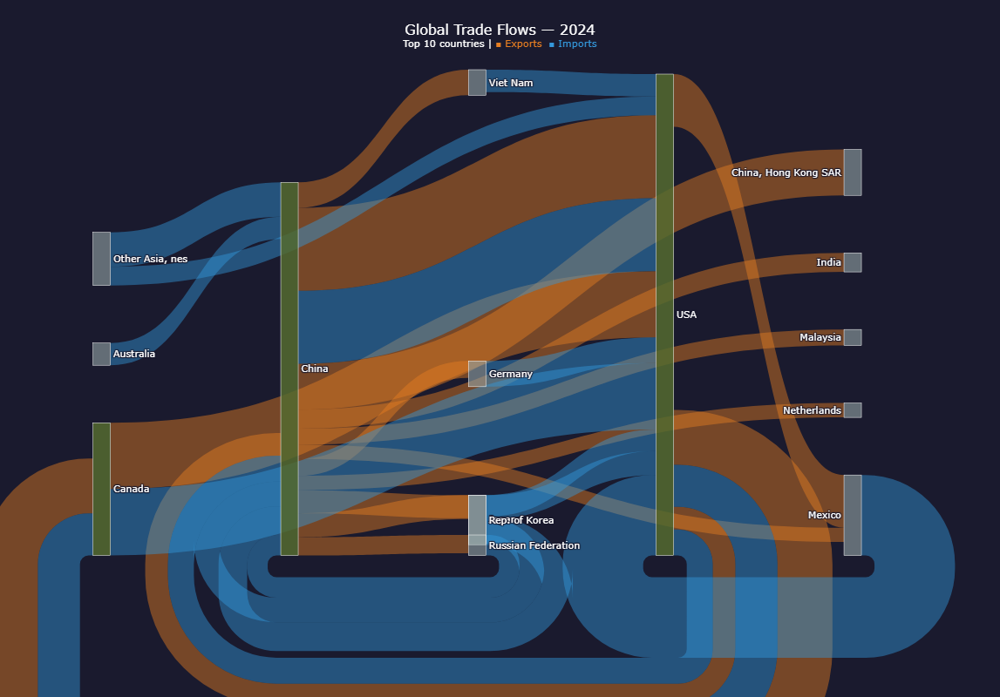


  TRADE FLOW SUMMARY — 2024
  Nodes (countries)   : 15
  Links (flows)       : 30
  Total value         : $6,511.0B
  Exports represented : $3,147.9B
  Imports represented : $3,363.1B

Country              Partner Flow  Value ($B)  Share (%)
  China                  USA    X    525.6000    14.7000
    USA               Mexico    M    510.0000    15.2000
    USA                China    M    462.6000    13.8000
    USA               Canada    M    421.2000    12.5000
 Canada                  USA    X    419.6000    76.3000
    USA               Canada    X    348.4000    16.9000
    USA               Mexico    X    334.0000    16.2000
  China China, Hong Kong SAR    X    290.9000     8.1000
 Canada                  USA    M    266.4000    49.3000
  China      Other Asia, nes    M    217.8000     8.4000


In [318]:
plot_sankey_bilateral(df_bi_trade, year=2024, countries=countries, n=10, top_per_flow=15)

- `Trade is highly concentrated` — the top 10 countries account for the majority
  of global bilateral flows, confirming the structural asymmetry observed in Section F.

- `Export and Import flows are not symmetric` — the largest export flows do not
  mirror the largest import flows, revealing directional trade imbalances between
  major economies.

- `USA, China and Germany dominate both sides` — they appear as major nodes
  on both export and import flows, confirming their role as global trade hubs
  rather than purely exporters or importers.

- `Partner concentration is visible` — several countries show most of their
  trade volume concentrated toward a single dominant partner (e.g. Canada → USA — Canada directs ~67% of its exports
  to the USA alone, the highest single-partner dependency among G20 economies),
  anticipating the HHI analysis in Section 5.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 5. Partners Structure & Bilateral Concentration
</div>

In [324]:
def top_n_share_partner(df_bi_trade, country, flow, n):
    df = df_bi_trade[(df_bi_trade["country_name"]== country) & (df_bi_trade["flow_code"]== flow)].sort_values(["year","share"], ascending=[True, False])
    topn = df.groupby(["country_name", "year", "flow_code"]).head(n) # top n partner
    top_n = topn.groupby(["country_name", "year", "flow_code"])['share'].sum().reset_index() # sum top_n share
    return topn, top_n

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.1 Partners Share
</div>

In [327]:
def plot_partner_share(df_bi_trade, country, flow, year=None, n=10):
    """    Partners Share : Bar chart for a given year (static snapshot) |   Line chart evolution of top partners over time   """
    
    topn, top_n = top_n_share_partner(df_bi_trade, country, flow, n)
    if year is None: year = topn['year'].max()
    df_year = topn[topn['year'] == year].copy()
    # Top partners identified in the latest year — used for time series
    top_partners = df_year.nlargest(n, 'share')['partner_name'].tolist()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    fig.patch.set_facecolor('#1a1a2e')
    for ax in [ax1, ax2]:
        ax.set_facecolor('#16213e')
        ax.tick_params(colors='white')
        ax.xaxis.label.set_color('white')
        ax.yaxis.label.set_color('white')
        ax.title.set_color('white')
        for spine in ax.spines.values(): spine.set_edgecolor('#444466')

    fig.suptitle(f'Partner Share Analysis — {country} | ' f'{"Exports" if flow == "X" else "Imports"} | Top {n}',
                 fontsize=14, fontweight='bold', color='white', y=1.01)
    # ── Colors per partner ────────────────────────────────────────────────────
    colors    = plt.cm.tab10.colors
    color_map = {p: colors[i % 10] for i, p in enumerate(top_partners)}
    # ── LEFT : Bar chart snapshot ─────────────────────────────────────────────
    df_sorted = df_year.sort_values('share', ascending=False).head(n)
    bar_colors = [color_map.get(p, '#aaaaaa') for p in df_sorted['partner_name']]
    bars = ax1.barh(df_sorted['partner_name'], df_sorted['share'] * 100,color=bar_colors, edgecolor='none', height=0.6)

    for bar, val in zip(bars, df_sorted['share'] * 100):
        ax1.text(val + 0.3, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center', fontsize=8,
                 color='white', fontweight='bold')

    # Risk zones
    ax1.axvline(x=50, color='#e74c3c', linewidth=1.0, linestyle='--', alpha=0.7, label='50% threshold')
    ax1.axvline(x=30, color='#f39c12', linewidth=1.0, linestyle='--', alpha=0.7, label='30% threshold')
    ax1.set_xlabel('Share (%)', fontsize=9)
    ax1.set_title(f'Top {n} Partners — {year}', fontsize=11, pad=10)
    ax1.invert_yaxis()
    ax1.grid(axis='x', color='#444466', linewidth=0.4, alpha=0.5)
    ax1.legend(fontsize=7, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='lower right')

    # ── RIGHT : Line chart evolution ──────────────────────────────────────────
    df_time = topn[topn['partner_name'].isin(top_partners)].copy()

    for partner in top_partners:
        df_p = df_time[df_time['partner_name'] == partner].sort_values('year')
        if df_p.empty:            continue
        c = color_map.get(partner, '#aaaaaa')
        ax2.plot(df_p['year'], df_p['share'] * 100, color=c, linewidth=2, marker='o', markersize=4, label=partner)
        # Annotate last point
        ax2.annotate(f"{df_p['share'].iloc[-1]*100:.1f}%", xy=(df_p['year'].iloc[-1], df_p['share'].iloc[-1] * 100),
                     xytext=(5, 0), textcoords='offset points', fontsize=7, color=c)
    ax2.set_xlabel('Year', fontsize=9)
    ax2.set_ylabel('Share (%)', fontsize=9)
    ax2.set_title('Partner Share Evolution Over Time', fontsize=11, pad=10)
    ax2.legend(fontsize=7, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left', ncol=2)
    ax2.grid(color='#444466', linewidth=0.4, alpha=0.4)

    plt.tight_layout()
    plt.savefig(f'../Figures/Trade/G_5_1_partner_share_{country}_{flow}.png', dpi=150,bbox_inches='tight',facecolor=fig.get_facecolor())
    plt.show()

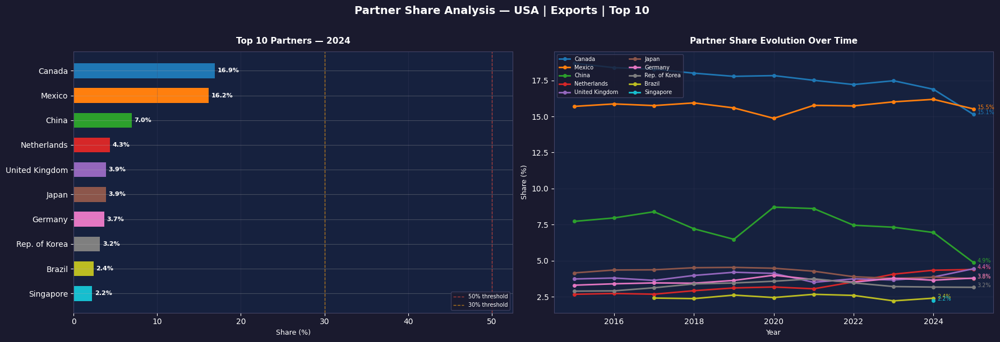

In [329]:
plot_partner_share(df_bi_trade, 'USA', 'X', year=2024, n=10)

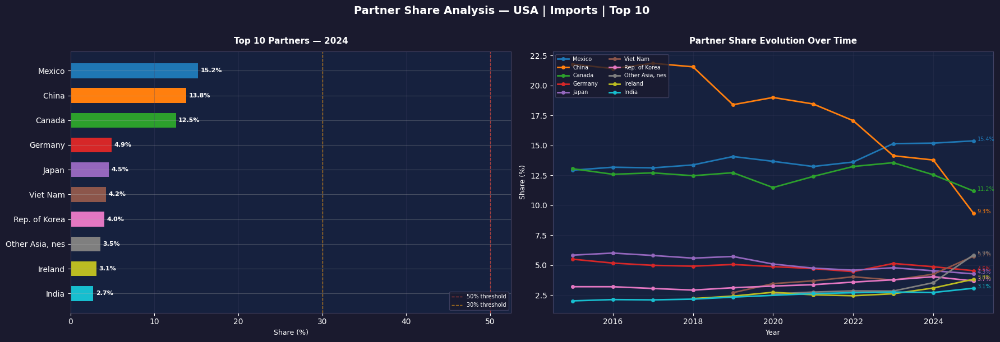

In [330]:
plot_partner_share(df_bi_trade, 'USA', 'M', year=2024, n=10)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.2 Partners Concentration (TOP 3/5/10)
</div>

In [332]:
def plot_partner_concentration(df_bi_trade, country, flow):
    """    Partners Concentration : Top 3 / 5 / 10 share evolution | Risk zones colored | Reference thresholds   """
    
    _, top_3  = top_n_share_partner(df_bi_trade, country, flow, 3)
    _, top_5  = top_n_share_partner(df_bi_trade, country, flow, 5)
    _, top_10 = top_n_share_partner(df_bi_trade, country, flow, 10)

    fig, ax = styled_figure(figsize=(12, 6))
    ax.set_title(f'Partner Concentration — {country} | '  f'{"Exports" if flow == "X" else "Imports"}',
                 fontsize=13, fontweight='bold', color='white', pad=15)
    years = top_3['year'].values
    # ── Risk zones ────────────────────────────────────────────────────────────
    add_risk_zones(ax)
    # ── Reference lines ───────────────────────────────────────────────────────
    ax.axhline(y=0.80, color='#e74c3c', linewidth=0.8, linestyle='--', alpha=0.7)
    ax.axhline(y=0.50, color='#f39c12', linewidth=0.8, linestyle='--', alpha=0.7)
    # ── Lines Top 3 / 5 / 10 ─────────────────────────────────────────────────
    line_styles = [(top_3, '#e74c3c','o', 'Top 3'), (top_5, '#f39c12', 's', 'Top 5'), (top_10, '#2ecc71', '^', 'Top 10')]
    for df_top, color, marker, label in line_styles:
        ax.plot(df_top['year'], df_top['share'],color=color, linewidth=2, marker=marker,markersize=5, label=label, zorder=3)
        # Annotate first and last
        ax.annotate(f"{df_top['share'].iloc[0]*100:.1f}%", xy=(df_top['year'].iloc[0], df_top['share'].iloc[0]),
                    xytext=(-18, 6), textcoords='offset points', fontsize=7, color=color, fontweight='bold')
        ax.annotate(f"{df_top['share'].iloc[-1]*100:.1f}%", xy=(df_top['year'].iloc[-1], df_top['share'].iloc[-1]),
                    xytext=(5, 4), textcoords='offset points', fontsize=7, color=color, fontweight='bold')
    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Cumulative Share (%)', fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax.set_xticks(years)
    ax.grid(color='#444466', linewidth=0.4, alpha=0.5)
    ax.legend(fontsize=9, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='lower right')
    plt.tight_layout()
    plt.savefig(f'../Figures/Trade/G_5_2_partner_concentration_{country}_{flow}.png', dpi=150, bbox_inches='tight',facecolor=fig.get_facecolor())
    plt.show()

    # ── Summary table ─────────────────────────────────────────────────────────
    df_summary = top_3.merge(top_5,  on=['country_name', 'year', 'flow_code'], suffixes=('_top3', '_top5'))
    df_summary = df_summary.merge(top_10, on=['country_name', 'year', 'flow_code'])
    df_summary.columns = ['Country', 'Year', 'Flow', 'Top 3', 'Top 5', 'Top 10']
    for col in ['Top 3', 'Top 5', 'Top 10']:
        df_summary[col] = (df_summary[col] * 100).round(1).astype(str) + '%'
    return df_summary

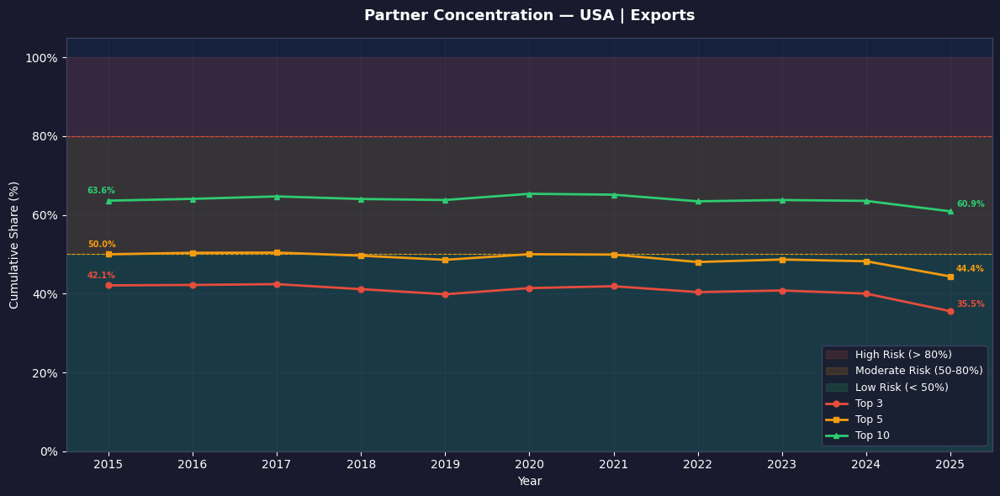

,Country,Year,Flow,Top 3,Top 5,Top 10
10,USA,2025,X,35.5%,44.4%,60.9%


In [333]:
df_conc = plot_partner_concentration(df_bi_trade, 'USA', 'X')
df_conc.tail(1)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.3 Create HHI Dataframe
</div>

In [335]:
df_hhi = (df_bi_trade.groupby(['country_name', 'year', 'flow_code'], as_index=False).agg(hhi=('share', lambda x: (x**2).sum()), n_partners=('partner_name', 'nunique')))

# Delta
df_hhi = df_hhi.sort_values(['country_name', 'flow_code', 'year'])
df_hhi['delta_hhi'] = df_hhi.groupby(['country_name', 'flow_code'])['hhi'].diff()

# Normalisation
df_hhi['hhi_norm'] = ((df_hhi['hhi'] - 1/df_hhi['n_partners']) / (1 - 1/df_hhi['n_partners']))
df_hhi['delta_hhi_norm'] = df_hhi.groupby('flow_code')['delta_hhi'].transform(normalize_delta)

# Level and trend
df_hhi['hhi_level'] = df_hhi["hhi"].apply(classify_hhi_level)
df_hhi['hhi_trend'] = df_hhi['delta_hhi'].apply(classify_trend)

# final columns
df_hhi = df_hhi[['country_name', 'year', 'flow_code', 'n_partners', 'hhi', 'delta_hhi', 'hhi_norm', 'delta_hhi_norm', 'hhi_level', 'hhi_trend' ]]

In [336]:
df_hhi.sample()

,country_name,year,flow_code,n_partners,hhi,delta_hhi,hhi_norm,delta_hhi_norm,hhi_level,hhi_trend
3315,United Arab Emirates,2017,M,199,0.0607,-0.0549,0.0559,0.4461,Low,Decreasing


In [337]:
df_hhi.to_csv("../Analysis_files/Trade/df_bi_hhi.csv", index=False)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.4 HHI Time Evolution
</div>

In [340]:
def plot_hhi_evolution(df_hhi, country):
    """    HHI Time Evolution :  - Line chart Import vs Export  | Risk zones | Peak annotation | Delta HHI     """
    
    df_exp = df_hhi[(df_hhi['country_name'] == country) & (df_hhi['flow_code'] == 'X')].sort_values('year')
    df_imp = df_hhi[(df_hhi['country_name'] == country) & (df_hhi['flow_code'] == 'M')].sort_values('year')

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 9))
    fig.suptitle(f'HHI Concentration Evolution — {country}', fontsize=14, fontweight='bold', color='white', y=1.01)
    # ── Shared risk zones config ──────────────────────────────────────────────
    hhi_thresholds = (
        (0.18, 1.00, '#e74c3c', 'High Concentration (> 0.18)'),
        (0.10, 0.18, '#f39c12', 'Moderate Concentration (0.10–0.18)'),
        (0.00, 0.10, '#2ecc71', 'Diversified (< 0.10)'),)

    for ax, df, flow_label, color in [(ax1, df_exp, 'Exports', '#f39c12'),(ax2, df_imp, 'Imports', '#3498db')]:
        # Risk zones
        add_risk_zones(ax, hhi_thresholds)
        # Reference lines
        ax.axhline(y=0.18, color='#e74c3c', linewidth=1.0, linestyle='--', alpha=0.8)
        ax.axhline(y=0.10, color='#f39c12', linewidth=1.0, linestyle='--', alpha=0.8)
        # HHI line
        ax.plot(df['year'], df['hhi'], color=color, linewidth=2.5, marker='o', markersize=5, zorder=3, label=f'HHI {flow_label}')
        # Peak annotation
        if not df.empty:
            idx_max = df['hhi'].idxmax()
            peak    = df.loc[idx_max]
            ax.annotate(f"Peak: {peak['hhi']:.3f}", xy=(peak['year'], peak['hhi']),xytext=(8, 8), 
                        textcoords='offset points', fontsize=10, color='white', fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'))
        # First and last annotations
        ax.annotate(f"{df['hhi'].iloc[0]:.3f}", xy=(df['year'].iloc[0], df['hhi'].iloc[0]),
                    xytext=(-20, 6), textcoords='offset points', fontsize=9, color=color)
        ax.annotate(f"{df['hhi'].iloc[-1]:.3f}", xy=(df['year'].iloc[-1], df['hhi'].iloc[-1]),
                    xytext=(5, 4), textcoords='offset points', fontsize=9, color=color)
        # Delta HHI as secondary axis
        ax_twin = ax.twinx()
        ax_twin.set_facecolor('#16213e')
        delta_colors = ['#2ecc71' if d < 0 else '#e74c3c' for d in df['delta_hhi'].fillna(0)]
        ax_twin.bar(df['year'], df['delta_hhi'].fillna(0), color=delta_colors, alpha=0.3, width=0.4, zorder=1)
        ax_twin.set_ylabel('ΔHHI', color='#aaaaaa', fontsize=9)
        ax_twin.tick_params(colors='#aaaaaa')
        ax_twin.axhline(y=0, color='#aaaaaa', linewidth=0.6, linestyle='-', alpha=0.5)
        # Axes
        ax.set_xlabel('Year', fontsize=10)
        ax.set_ylabel('HHI', fontsize=10)
        ax.set_title(f'HHI {flow_label}', fontsize=11, pad=10)
        ax.set_ylim(0, 0.3)
        ax.set_xticks(df['year'])
        style_grid(ax)
        add_legend(ax, loc='upper left')

    save_figure(fig, f'../Figures/Trade/G_5_4_hhi_evolution_{country}.png')

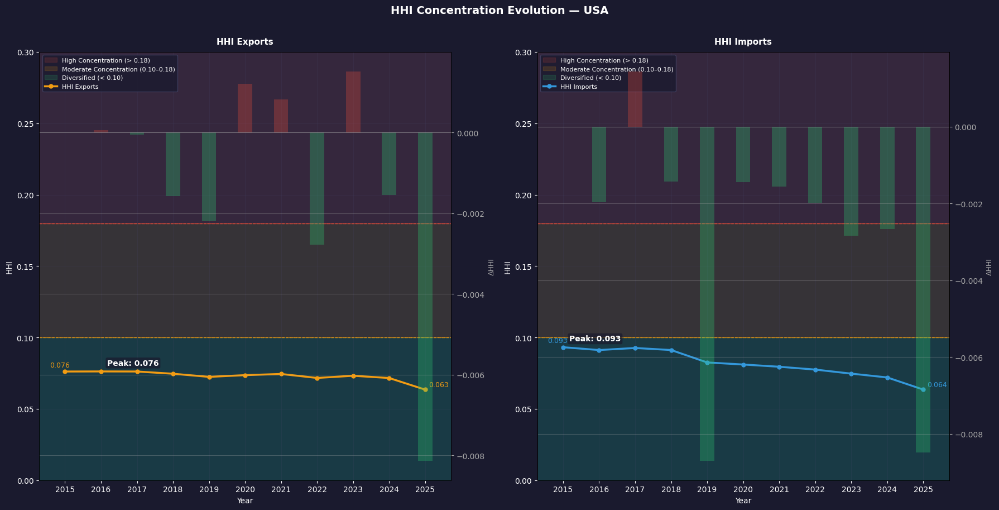

In [341]:
plot_hhi_evolution(df_hhi, 'USA')

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.5 Dependency (Import score vs Export score)
</div>

In [345]:
def plot_hhi_dependency(df_hhi, countries, year=None):
    """ HHI Dependency: Scatter plot HHI Import vs HHI Export, 4 quadrants : Diversified / Import Exposed / Export Exposed / Dual Exposed  """
    
    if year is None:  year = df_hhi['year'].max()

    # ── Prepare data ──────────────────────────────────────────────────────────
    hhi_exp =(df_hhi[(df_hhi['year'] == year) & (df_hhi['country_name'].isin(countries)) & (df_hhi['flow_code'] == 'X')]
               [['country_name', 'hhi']].rename(columns={'hhi': 'hhi_export'}))
    hhi_imp =(df_hhi[(df_hhi['year'] == year) & (df_hhi['country_name'].isin(countries)) & (df_hhi['flow_code'] == 'M')]
               [['country_name', 'hhi']].rename(columns={'hhi': 'hhi_import'}))
    df_plot = hhi_exp.merge(hhi_imp, on='country_name').dropna()
    threshold = 0.10  # HHI diversification threshold
    
    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax = styled_figure(figsize=(12, 8))
    ax.set_title(f'HHI Import vs Export — Dependency Quadrants | {year}', fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Quadrant backgrounds ──────────────────────────────────────────────────
    xlim = (0, df_plot['hhi_export'].max() * 1.05)
    ylim = (0, df_plot['hhi_import'].max() * 1.05)
    
    ax.fill_betweenx([threshold, ylim[1]], threshold, xlim[1], color='#e74c3c', alpha=0.08)  # Dual Exposed
    ax.fill_betweenx([0, threshold], threshold, xlim[1], color='#f39c12', alpha=0.08)   # Export Exposed
    ax.fill_betweenx([threshold, ylim[1]], 0, threshold, color='#3498db', alpha=0.08)   # Import Exposed
    ax.fill_betweenx([0, threshold], 0, threshold, color='#2ecc71', alpha=0.08)   # Diversified
    quadrant_labels = [
        ('Dual Exposed',    xlim[1] * 0.70, threshold * 1.1),
        ('Export Exposed',  xlim[1] * 0.70, ylim[1] * 0.12),
        ('Import Exposed',  xlim[1] * 0.08, threshold * 1.1),
        ('Diversified',     xlim[1] * 0.08, ylim[1] * 0.12), ]
    for lbl, x, y in quadrant_labels:
        ax.text(x, y, lbl, fontsize=9, color='#cccccc', ha='center', va='center', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))

    # ── Threshold lines ───────────────────────────────────────────────────────
    ax.axvline(x=threshold, color='white', linewidth=1.5, linestyle='--', alpha=0.8)
    ax.axhline(y=threshold, color='white', linewidth=1.5, linestyle='--', alpha=0.8)

    # ── Diagonal reference ────────────────────────────────────────────────────
    max_val = max(xlim[1], ylim[1])
    ax.plot([0, max_val], [0, max_val], color='#aaaaaa', linewidth=0.8, linestyle=':', alpha=0.6,
            label='HHI Import = HHI Export')

    # ── Scatter points ────────────────────────────────────────────────────────
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}
    for _, row in df_plot.iterrows():
        c = color_map.get(row['country_name'], '#aaaaaa')
        ax.scatter(row['hhi_export'], row['hhi_import'], color=c, s=120, zorder=3, edgecolors='white', linewidths=0.8)
        ax.annotate(row['country_name'], xy=(row['hhi_export'], row['hhi_import']), xytext=(8, 4),
                    textcoords='offset points', fontsize=8, color=c, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'))
    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlabel('HHI Export — Export Concentration', fontsize=10)
    ax.set_ylabel('HHI Import — Import Concentration', fontsize=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    style_grid(ax)
    add_legend(ax, loc='upper left')

    save_figure(fig, f'../Figures/Trade/G_5_5_hhi_dependency_{year}.png')

    # ── Summary table ─────────────────────────────────────────────────────────
    df_plot['quadrant'] = df_plot.apply(lambda r:
        'Dual Exposed'   if r['hhi_export'] >= threshold and r['hhi_import'] >= threshold else
        'Export Exposed' if r['hhi_export'] >= threshold and r['hhi_import'] < threshold  else
        'Import Exposed' if r['hhi_export'] < threshold  and r['hhi_import'] >= threshold else
        'Diversified', axis=1)

    print(f"\n{'='*60}")
    print(f"  HHI DEPENDENCY SUMMARY — {year}")
    print(f"{'='*60}")
    print(df_plot[['country_name', 'hhi_export', 'hhi_import', 'quadrant']].to_string(index=False))
    print(f"{'='*60}\n")
    return df_plot

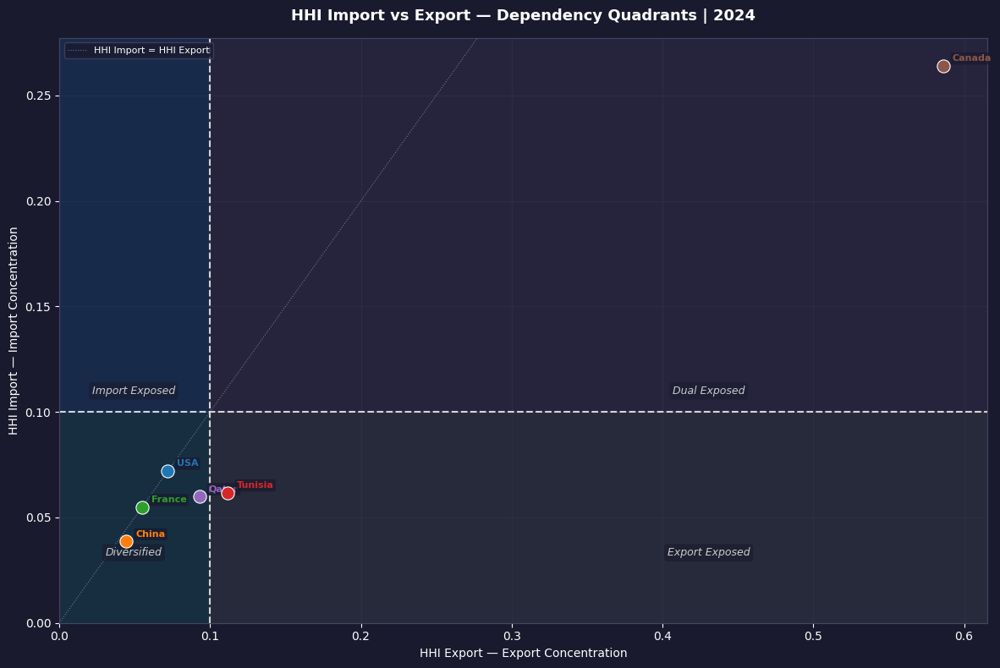


  HHI DEPENDENCY SUMMARY — 2024
country_name  hhi_export  hhi_import       quadrant
      Canada      0.5860      0.2641   Dual Exposed
       China      0.0445      0.0387    Diversified
      France      0.0549      0.0549    Diversified
       Qatar      0.0930      0.0599    Diversified
     Tunisia      0.1115      0.0618 Export Exposed
         USA      0.0716      0.0720    Diversified



In [346]:
df_dep = plot_hhi_dependency(df_hhi, countries, year=2024)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.6 HHI Internal Structure : Contribution of partners to HHI
</div>

In [349]:
def plot_hhi_internal_structure(df_bi_trade, country, flow, year=None):
    """    Pareto chart : partner HHI contribution + cumulative line : Reveals which partners drive concentration   """

    df = df_bi_trade[(df_bi_trade['country_name'] == country) & (df_bi_trade['flow_code'] == flow)].copy()
    if year is None: year = df['year'].max()
    df = df[df['year'] == year].copy()
    df['hhi_contribution'] = df['share'] ** 2
    df = df.sort_values('hhi_contribution', ascending=False).head(15)
    # Cumulative
    total_hhi    = df['hhi_contribution'].sum()
    df['cumulative'] = df['hhi_contribution'].cumsum() / total_hhi * 100
    df['hhi_pct']    = df['hhi_contribution'] / total_hhi * 100

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax1 = styled_figure(figsize=(14, 6))
    ax2 = ax1.twinx()
    ax2.set_facecolor('#16213e')
    ax2.tick_params(colors='white')
    ax2.yaxis.label.set_color('white')

    fig.suptitle(f'HHI Internal Structure — {country} | ' f'{"Exports" if flow == "X" else "Imports"} | {year}',
                 fontsize=13, fontweight='bold', color='white')

    # ── Bar chart — HHI contribution ──────────────────────────────────────────
    colors = plt.cm.RdYlGn_r([i / len(df) for i in range(len(df))])
    bars = ax1.bar(df['partner_name'], df['hhi_pct'], color=colors, edgecolor='none', width=0.6, zorder=2)

    for bar, val in zip(bars, df['hhi_pct']):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f'{val:.1f}%', ha='center', va='bottom',
                 fontsize=7, color='white', fontweight='bold')

    # ── Cumulative line ───────────────────────────────────────────────────────
    ax2.plot(df['partner_name'], df['cumulative'], color='#f1c40f', linewidth=2.5, marker='o',
             markersize=5, zorder=3, label='Cumulative HHI %')

    # Reference lines at 50% and 80%
    ax2.axhline(y=80, color='#e74c3c', linewidth=1.0, linestyle='--', alpha=0.8, label='80% threshold')
    ax2.axhline(y=50, color='#f39c12', linewidth=1.0, linestyle='--', alpha=0.8, label='50% threshold')

    # Annotate cumulative points
    for i, (_, row) in enumerate(df.iterrows()):
        ax2.annotate(f"{row['cumulative']:.0f}%", xy=(i, row['cumulative']), xytext=(0, 8),
                     textcoords='offset points', fontsize=6.5, color='#f1c40f', ha='center')

    # ── Axes ──────────────────────────────────────────────────────────────────
    ax1.set_xlabel('Partner', fontsize=10)
    ax1.set_ylabel('HHI Contribution (%)', fontsize=10)
    ax2.set_ylabel('Cumulative HHI (%)', fontsize=10)
    ax2.set_ylim(0, 115)
    ax1.set_xticklabels(df['partner_name'], rotation=45, ha='right', fontsize=8, color='white')
    style_grid(ax1)
    add_legend(ax2, loc='best')

    # ── Annotation total HHI ─────────────────────────────────────────────────
    ax1.text(0.98, 0.8, f'Total HHI = {total_hhi:.4f}', transform=ax1.transAxes,fontsize=9, color='white', ha='right',
             va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.8, edgecolor='#444466'))

    save_figure(fig, f'../Figures/Trade/G_5_6_hhi_structure_{country}_{flow}_{year}.png')

    # ── Summary ───────────────────────────────────────────────────────────────
    n_50 = (df['cumulative'] <= 50).sum() + 1
    n_80 = (df['cumulative'] <= 80).sum() + 1
    print(f"\n{'='*55}")
    print(f"  HHI INTERNAL STRUCTURE — {country} {flow} {year}")
    print(f"{'='*55}")
    print(f"  Total HHI          : {total_hhi:.4f}")
    print(f"  Partners for 50%   : {n_50}")
    print(f"  Partners for 80%   : {n_80}")
    print(f"  Top partner share  : {df['hhi_pct'].iloc[0]:.1f}% of HHI")
    print(f"{'='*55}\n")

    return df

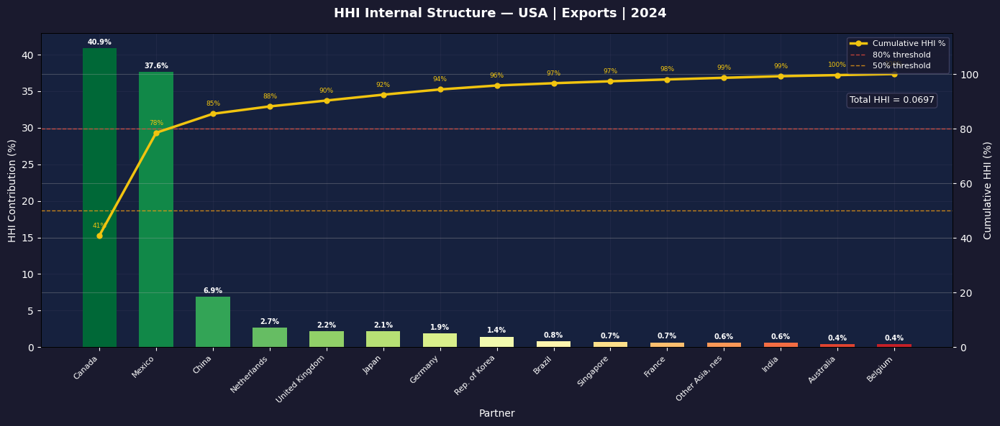


  HHI INTERNAL STRUCTURE — USA X 2024
  Total HHI          : 0.0697
  Partners for 50%   : 2
  Partners for 80%   : 3
  Top partner share  : 40.9% of HHI



In [353]:
df_struct_exp = plot_hhi_internal_structure(df_bi_trade, 'USA', 'X', year=2024)

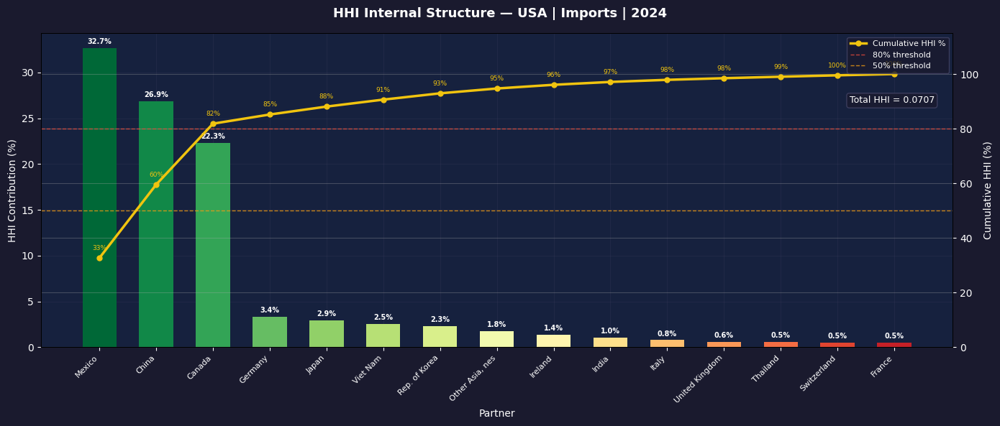


  HHI INTERNAL STRUCTURE — USA M 2024
  Total HHI          : 0.0707
  Partners for 50%   : 2
  Partners for 80%   : 3
  Top partner share  : 32.7% of HHI



In [355]:
df_struct_imp = plot_hhi_internal_structure(df_bi_trade, 'USA', 'M', year=2024)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 5.7 Breaks Detection
</div>

- **Trade concentration is structurally persistent** — HHI levels rarely change
  dramatically year-over-year, suggesting that partner structures are sticky
  and driven by geography, treaties, and supply chains rather than price signals.
- **Import concentration consistently exceeds export concentration** for most countries,
  revealing a systematic supply-side vulnerability — countries diversify their
  export markets faster than their import sources.
- **COVID-19 (2020) is the dominant shock** detected in break analysis across
  most countries — sudden HHI spikes in 2020 reflect partner reorientation
  and supply chain disruptions, with partial normalization by 2022.
- **HHI internal structure reveals the "dominant partner effect"** — in most cases,
  1-2 partners explain over 60% of the total HHI, meaning concentration
  is driven by a single relationship, not a general lack of diversification.

In [360]:
def plot_hhi_breaks(df_hhi, country, threshold=0.01):
    """    HHI line chart with shock markers  |  Delta HHI bar chart  | Automatic shock annotation    """

    df_exp = df_hhi[(df_hhi['country_name'] == country) &  (df_hhi['flow_code'] == 'X')].sort_values('year')
    df_imp = df_hhi[(df_hhi['country_name'] == country) &  (df_hhi['flow_code'] == 'M')].sort_values('year')

    shocks_exp = df_exp[df_exp['delta_hhi'].abs() >= threshold]
    shocks_imp = df_imp[df_imp['delta_hhi'].abs() >= threshold]

    fig, axes = styled_subplots(nrows=2, ncols=2, figsize=(18, 10))
    ax_hhi_exp, ax_hhi_imp   = axes[0]
    ax_delta_exp, ax_delta_imp = axes[1]

    fig.suptitle(f'HHI Break Detection — {country} | Threshold = {threshold}',
                 fontsize=14, fontweight='bold', color='white', y=1.01)

    # ── HHI thresholds config ─────────────────────────────────────────────────
    hhi_thresholds = (
        (0.18, 1.00, '#e74c3c', 'High (> 0.18)'),
        (0.10, 0.18, '#f39c12', 'Moderate (0.10–0.18)'),
        (0.00, 0.10, '#2ecc71', 'Diversified (< 0.10)'),)

    for ax_hhi, ax_delta, df, shocks, flow_label, line_color in [
        (ax_hhi_exp, ax_delta_exp, df_exp, shocks_exp, 'Exports', '#f39c12'),
        (ax_hhi_imp, ax_delta_imp, df_imp, shocks_imp, 'Imports', '#3498db'),]:
        # ── HHI line + shock markers ──────────────────────────────────────────
        add_risk_zones(ax_hhi, hhi_thresholds)
        ax_hhi.axhline(y=0.18, color='#e74c3c', linewidth=0.8, linestyle='--', alpha=0.7)
        ax_hhi.axhline(y=0.10, color='#f39c12', linewidth=0.8, linestyle='--', alpha=0.7)
        ax_hhi.plot(df['year'], df['hhi'], color=line_color, linewidth=2.5, marker='o', markersize=4,
                    zorder=2, label=f'HHI {flow_label}')
        ax_hhi.set_ylim(0, max(0.3, max(df['hhi'])*1.5))

        # Shock markers on HHI line
        for _, shock in shocks.iterrows():
            direction = '▲' if shock['delta_hhi'] > 0 else '▼'
            color     = '#2ecc71' if shock['delta_hhi'] > 0 else '#e74c3c'
            ax_hhi.scatter(shock['year'], shock['hhi'], s=150, color=color, zorder=4, edgecolors='white', linewidths=1.0)
            ax_hhi.annotate(f"{direction} {shock['delta_hhi']:+.3f}", xy=(shock['year'], shock['hhi']), xytext=(8, 10),
                            textcoords='offset points', fontsize=7.5, color=color, fontweight='bold',
                            bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.8, edgecolor='none'))

        ax_hhi.set_title(f'HHI {flow_label} — Shock Markers', fontsize=11, pad=10)
        ax_hhi.set_ylabel('HHI', fontsize=9)
        ax_hhi.set_xticks(df['year'])
        style_grid(ax_hhi)
        add_legend(ax_hhi, loc='upper left')

        # ── Delta HHI bar chart ───────────────────────────────────────────────
        delta_colors = ['#2ecc71' if d > 0 else '#e74c3c' for d in df['delta_hhi'].fillna(0)]
        bars = ax_delta.bar(df['year'], df['delta_hhi'].fillna(0), color=delta_colors, edgecolor='none',width=0.5,zorder=2)

        # Highlight shocks
        for _, shock in shocks.iterrows():
            idx = df[df['year'] == shock['year']].index
            if not idx.empty:
                bar_idx = df.index.get_loc(idx[0])
                bars[bar_idx].set_edgecolor('white')
                bars[bar_idx].set_linewidth(1.5)

        ax_delta.axhline(y=0, color='#aaaaaa', linewidth=0.8, linestyle='-', alpha=0.6)
        ax_delta.axhline(y=threshold,  color= '#2ecc71', linewidth=0.8, linestyle='--', alpha=0.7,
                         label=f'+Threshold ({threshold})')
        ax_delta.axhline(y=-threshold, color= '#e74c3c', linewidth=0.8, linestyle='--', alpha=0.7,
                         label=f'-Threshold ({threshold})')

        # Value labels on bars
        for bar, val in zip(bars, df['delta_hhi'].fillna(0)):
            if abs(val) >= threshold:
                ax_delta.text(bar.get_x() + bar.get_width() / 2, val + (0.001 if val > 0 else -0.002),
                    f'{val:+.3f}',ha='center',va='bottom' if val > 0 else 'top',fontsize=7,color='white',fontweight='bold')

        ax_delta.set_title(f'ΔHHI {flow_label} — Concentration Changes', fontsize=11, pad=10)
        ax_delta.set_ylabel('ΔHHI', fontsize=9)
        ax_delta.set_xticks(df['year'])
        style_grid(ax_delta)
        add_legend(ax_delta, loc='upper left')

    save_figure(fig, f'../Figures/Trade/G_5_7_hhi_breaks_{country}.png')

    # ── Summary shocks ────────────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  DETECTED SHOCKS — {country} | Threshold = {threshold}")
    print(f"{'='*60}")
    for flow_label, shocks in [('Exports', shocks_exp), ('Imports', shocks_imp)]:
        if shocks.empty: print(f"  {flow_label} : No significant shock detected")
        else:
            print(f"  {flow_label} :")
            for _, s in shocks.iterrows():
                direction = 'Concentration ↑' if s['delta_hhi'] > 0 else 'Diversification ↓'
                print(f"    {int(s['year'])} → ΔHHI = {s['delta_hhi']:+.4f} | {direction}")
    print(f"{'='*60}\n")

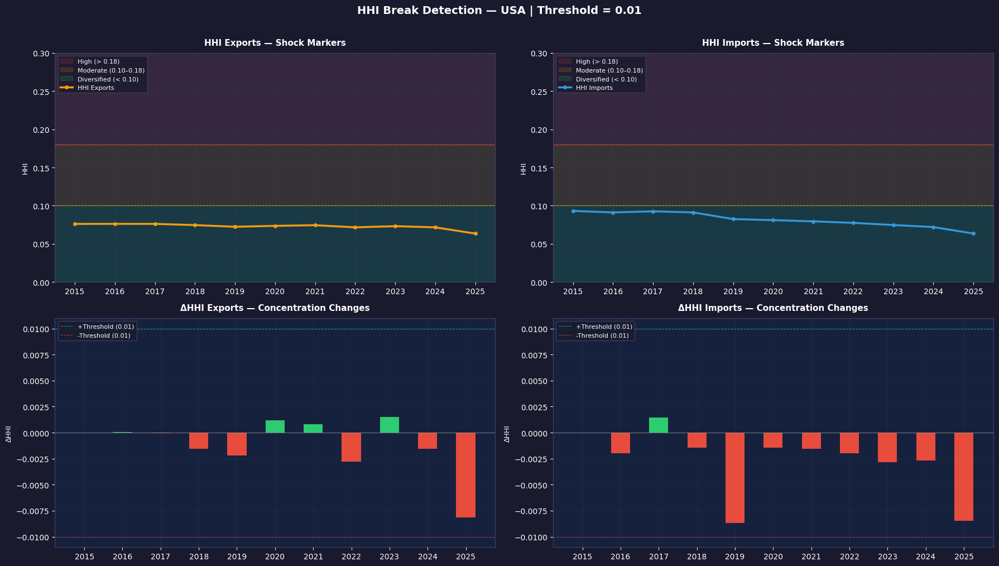


  DETECTED SHOCKS — USA | Threshold = 0.01
  Exports : No significant shock detected
  Imports : No significant shock detected



In [361]:
plot_hhi_breaks(df_hhi, 'USA',  threshold=0.01)

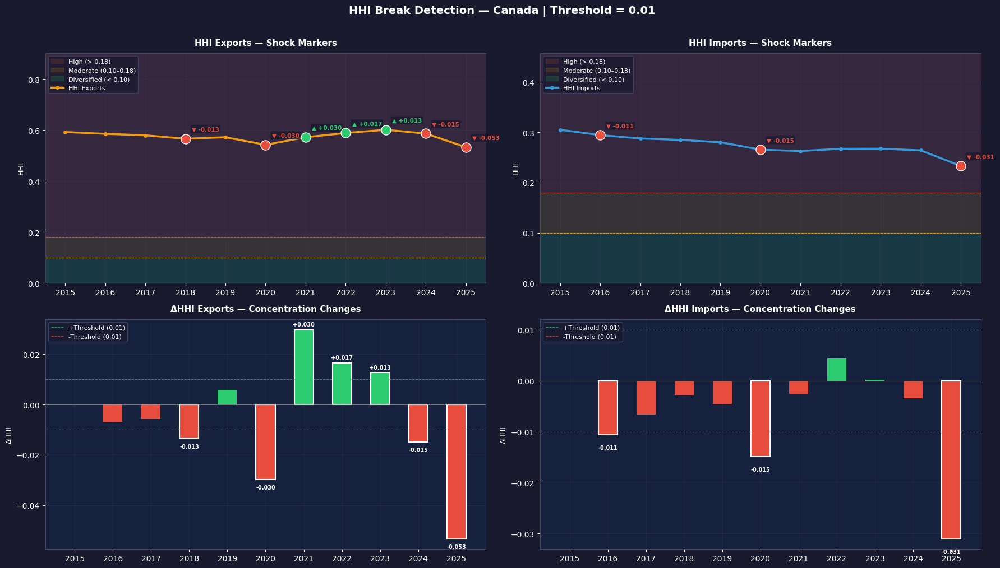


  DETECTED SHOCKS — Canada | Threshold = 0.01
  Exports :
    2018 → ΔHHI = -0.0135 | Diversification ↓
    2020 → ΔHHI = -0.0298 | Diversification ↓
    2021 → ΔHHI = +0.0298 | Concentration ↑
    2022 → ΔHHI = +0.0166 | Concentration ↑
    2023 → ΔHHI = +0.0127 | Concentration ↑
    2024 → ΔHHI = -0.0150 | Diversification ↓
    2025 → ΔHHI = -0.0534 | Diversification ↓
  Imports :
    2016 → ΔHHI = -0.0106 | Diversification ↓
    2020 → ΔHHI = -0.0149 | Diversification ↓
    2025 → ΔHHI = -0.0310 | Diversification ↓



In [364]:
plot_hhi_breaks(df_hhi, 'Canada', threshold=0.01)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 6. Asymmetric Bilateral Dependency
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.1 Create DBI TABLE
</div>

In [369]:
# Calculate total trade bilateral (Import + Export)
df_bilateral_total = (df_bi_trade.groupby(['country_name', 'partner_name', 'year'], as_index=False)['value'].sum().rename(columns={'value': 'bilateral_trade'}))
# Calculate total trade per country
df_country_total = (df_bi_trade.groupby(['country_name', 'year'], as_index=False)['value'].sum().rename(columns={'value': 'total_trade'}))
# Calculate dependency (bilateral share)
df_dep = df_bilateral_total.merge(df_country_total, on=['country_name', 'year'])
df_dep['dependency'] = df_dep['bilateral_trade'] / df_dep['total_trade']
# Self-join for inverse flow
df_bdi = df_dep.merge(df_dep, left_on=['country_name', 'partner_name', 'year'], right_on=['partner_name', 'country_name', 'year'], suffixes=('', '_reverse'))
# Calculate BDI
df_bdi['bdi'] = abs(df_bdi['dependency'] - df_bdi['dependency_reverse'])
# Keep useful columns
df_bdi = df_bdi[['country_name', 'partner_name', 'year', 'dependency', 'dependency_reverse', 'bdi']]
# Normalization
df_bdi['bdi_norm'] = (df_bdi['bdi'] / 1.0).clip(upper=1.0)
# Classification
df_bdi['dep_level'] = df_bdi['dependency'].apply(classify_dependency)
df_bdi['dep_reverse_level'] = df_bdi['dependency_reverse'].apply(classify_dependency)
df_bdi['bdi_level'] = df_bdi['bdi'].apply(classify_bdi)
# Dominant partner (A deponds on B or B depends on A)
df_bdi['dominant_partner'] = df_bdi.apply(
    lambda row: row['partner_name'] if row['dependency'] > row['dependency_reverse'] else row['country_name'], axis=1)
# Dependency type
df_bdi['dependency_type'] = df_bdi.apply(
    lambda row: f"{row['country_name']} depends on {row['partner_name']}" 
                if row['dependency'] > row['dependency_reverse']
                else f"{row['partner_name']} depends on {row['country_name']}",
    axis=1)

In [371]:
df_bdi.sample()

,country_name,partner_name,year,dependency,dependency_reverse,bdi,bdi_norm,dep_level,dep_reverse_level,bdi_level,dominant_partner,dependency_type
9510,Australia,Malaysia,2020,0.0234,0.0247,0.0012,0.0012,Low,Low,Interdependence,Australia,Malaysia depends on Australia


In [372]:
df_bdi.to_csv("../Analysis_files/Trade/df_bdi.csv", index=False)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.2 BDI for a pair of countries
</div>

In [374]:
# Utility functions
def get_bdi_pair(df_bdi, country, partner):
    """Filter BDI table for a specific pair"""
    return (df_bdi[(df_bdi['country_name'] == country) & (df_bdi['partner_name'] == partner)]
            .sort_values('year').copy())

def annotate_endpoints(ax, x, y, color, fmt='.2f', pct=False):
    """Annotate first and last points of a line"""
    for xi, yi, offset in [(x.iloc[0], y.iloc[0], (-25, 6)), (x.iloc[-1], y.iloc[-1], (5, 4))]:
        label = f"{yi*100:{fmt}}%" if pct else f"{yi:{fmt}}"
        ax.annotate(label, xy=(xi, yi), xytext=offset, textcoords='offset points',
                    fontsize=7.5, color=color, fontweight='bold')

In [375]:
def plot_bdi_pair_evolution(df_bdi, country, partner):
    """    Mirror bar chart : dependency vs dependency_reverse  -    BDI as line overlay    """

    df = get_bdi_pair(df_bdi, country, partner)
    fig, ax = styled_figure(figsize=(14, 7))
    ax.set_title(f'Bilateral Dependency Analysis — {country} ↔ {partner}', fontsize=13, fontweight='bold', color='white', pad=15)
    width = 0.35

    # ── Mirror bars ───────────────────────────────────────────────────────────
    ax.bar(df['year'] - width/2, df['dependency'], width=width, color='#e74c3c', alpha=0.8,
           label=f'{country} → {partner}', zorder=2)
    ax.bar(df['year'] + width/2, -df['dependency_reverse'], width=width, color='#2ecc71', alpha=0.8,
           label=f'{partner} → {country}', zorder=2)

    # ── BDI line ──────────────────────────────────────────────────────────────
    ax2 = add_twin_axis(ax)
    ax2.plot(df['year'], df['bdi'], color='#3498db', linewidth=2.5, marker='o', markersize=6, zorder=4, label='BDI')
    ax2.axhline(y=0.20, color='#f39c12', linewidth=0.8, linestyle='--', alpha=0.7, label='Moderate (0.20)')
    ax2.axhline(y=0.50, color='#e74c3c', linewidth=0.8, linestyle='--', alpha=0.7, label='Strong (0.50)')
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel('BDI', fontsize=9)
    
    annotate_endpoints(ax2, df['year'], df['bdi'], '#3498db', fmt='.3f')
    add_legend(ax2, loc='upper right', fontsize=7)

    dominant = df['dominant_partner'].iloc[-1]
    ax2.annotate(f'Dominant: {dominant}', xy=(df['year'].iloc[-1], df['bdi'].iloc[-1]), xytext=(-60, -18), textcoords='offset points',
        fontsize=8, color='#f1c40f', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.8, edgecolor='none'))
    
    # ── Y axis labels ─────────────────────────────────────────────────────────
    ax.axhline(y=0, color='#aaaaaa', linewidth=0.8, alpha=0.6)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{abs(x)*100:.0f}%'))
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Dependency (Share)', fontsize=10)
    ax.set_xticks(df['year'])
    style_grid(ax)
    add_legend(ax, loc='upper left', fontsize=7)

    save_figure(fig, f'../Figures/Trade/G_6_2_bdi_pair_{country}_{partner}.png')

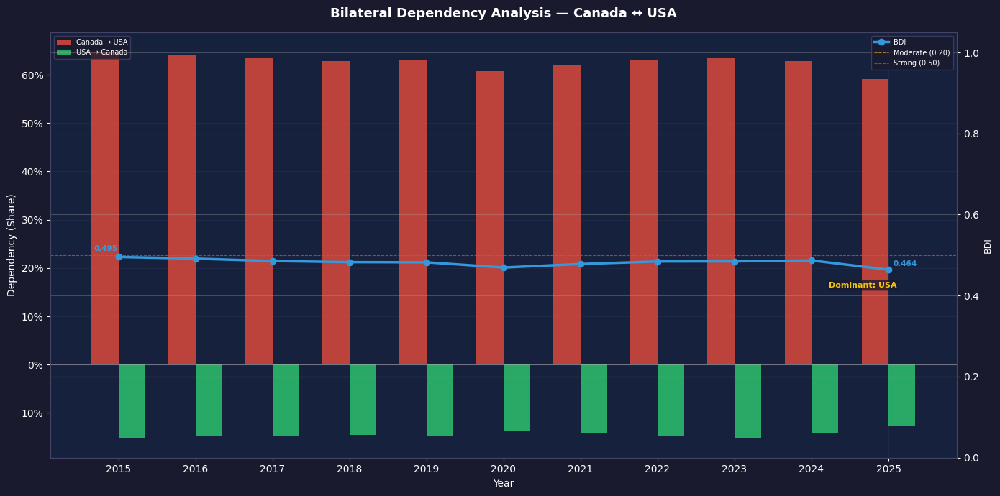

In [377]:
df = plot_bdi_pair_evolution(df_bdi, 'Canada', 'USA')

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 6.3 Dependency Cartography (Top parteners)
</div>

Objectif : Identify critical partners for a given country

In [380]:
def dependency_cartography(df_bi_trade, df_bdi, country, flow, year=None, n=10):
    """    Prepare dependency cartography table for top n partners Returns merged df_bdi with share info for top partners    """
    
    if year is None: year = df_bdi[df_bdi['country_name'] == country]['year'].max()
    # Top n partners by share
    top_partners, _ = top_n_share_partner(df_bi_trade, country, flow, n)
    top_partners    = top_partners[top_partners['year'] == year]
    top_part        = top_partners['partner_name'].drop_duplicates().tolist()
    # Filter BDI for these partners
    df = df_bdi[(df_bdi['country_name'] == country) & (df_bdi['partner_name'].isin(top_part)) & (df_bdi['year'] == year)].copy()
    return df

In [381]:
def plot_dependency_cartography(df_bi_trade, df_bdi, country, flow, year=None, n=10):
    """ Dependency Cartography:  Mirror bar chart : dependency vs dependency_reverse for top partners |  Size of BDI as color intensity  """
    
    df = dependency_cartography(df_bi_trade, df_bdi, country, flow, year, n)
    if year is None: year = df['year'].max()

    df = df.sort_values('dependency', ascending=True)

    fig, ax = styled_figure(figsize=(14, 8))
    ax.set_title(f'Dependency Cartography — {country} | '
                 f'{"Exports" if flow == "X" else "Imports"} | {year}', fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Color by BDI level ────────────────────────────────────────────────────
    bdi_colors = df['bdi_norm'].apply(lambda x:
        '#e74c3c' if x >= 0.50 else
        '#f39c12' if x >= 0.20 else
        '#2ecc71')

    # ── Mirror bars ───────────────────────────────────────────────────────────
    bars_dep = ax.barh(df['partner_name'], df['dependency'] * 100, color=bdi_colors, alpha=0.85, height=0.5, zorder=2,
                       label=f'{country} dependency on partner')

    bars_rev = ax.barh(df['partner_name'], -df['dependency_reverse'] * 100, color='#3498db', alpha=0.50, height=0.5, zorder=2,
                       label='Partner dependency on country')

    # ── Value labels ──────────────────────────────────────────────────────────
    for bar, val in zip(bars_dep, df['dependency'] * 100):
        ax.text(val + 0.3, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center', fontsize=7.5, color='white', fontweight='bold')

    for bar, val in zip(bars_rev, df['dependency_reverse'] * 100):
        ax.text(-val - 0.3, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center',ha='right',fontsize=7.5, color='#3498db', fontweight='bold')

    # ── BDI annotation on right ───────────────────────────────────────────────
    x_max = df['dependency'].max() * 100 * 1.35
    for i, (_, row) in enumerate(df.iterrows()):
        bdi_color = ('#e74c3c' if row['bdi_norm'] >= 0.50 else
                     '#f39c12' if row['bdi_norm'] >= 0.20 else
                     '#2ecc71')
        ax.text(x_max, i, f"BDI: {row['bdi']:.3f}", va='center', fontsize=7.5, color=bdi_color, fontweight='bold')

    # ── Reference line ────────────────────────────────────────────────────────
    ax.axvline(x=0, color='white', linewidth=1.2, linestyle='-', alpha=0.8)

    # ── Risk threshold lines ──────────────────────────────────────────────────
    for x, color, label in [(20, '#f39c12', 'Moderate (20%)'), (50, '#e74c3c', 'Strong (50%)')]:
        ax.axvline(x=x,  color=color, linewidth=0.8, linestyle='--', alpha=0.6, label=label)
        ax.axvline(x=-x, color='#3498db', linewidth=0.8, linestyle='--', alpha=0.4)

    # ── Color legend for BDI ──────────────────────────────────────────────────
    from matplotlib.patches import Patch
    bdi_legend = [
        Patch(color='#e74c3c', alpha=0.85, label='Strong asymmetry (BDI ≥ 0.50)'),
        Patch(color='#f39c12', alpha=0.85, label='Moderate asymmetry (BDI 0.20–0.50)'),
        Patch(color='#2ecc71', alpha=0.85, label='Interdependence (BDI < 0.20)'),
        Patch(color='#3498db', alpha=0.50, label='Partner dependency'),]

    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlabel('Dependency (%) — Positive: Reporter | Negative: Partner', fontsize=9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{abs(x):.0f}%'))
    ax.set_xlim(-df['dependency_reverse'].max() * 120, df['dependency'].max() * 160)
    style_grid(ax)
    ax.legend(handles=bdi_legend, fontsize=7.5, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='best')

    save_figure(fig, f'../Figures/Trade/G_6_3_dependency_cartography_{country}_{flow}_{year}.png')

    # ── Summary ───────────────────────────────────────────────────────────────
    print(f"\n{'='*65}")
    print(f"  DEPENDENCY CARTOGRAPHY — {country} | {flow} | {year}")
    print(f"{'='*65}")
    print(f"  {'Partner':<25} {'Dep. →':>8} {'Dep. ←':>8} {'BDI':>8} {'Profile':<20}")
    print(f"  {'-'*65}")
    for _, row in df.sort_values('dependency', ascending=False).iterrows():
        profile = ('Strong asymmetry' if row['bdi_norm'] >= 0.50 else
                   'Moderate' if row['bdi_norm'] >= 0.20 else
                   'Interdependence')
        print(f"  {row['partner_name']:<25} "  f"{row['dependency']*100:>7.1f}% "
              f"{row['dependency_reverse']*100:>7.1f}% "  f"{row['bdi']:>8.3f}  {profile}")
    print(f"{'='*65}\n")

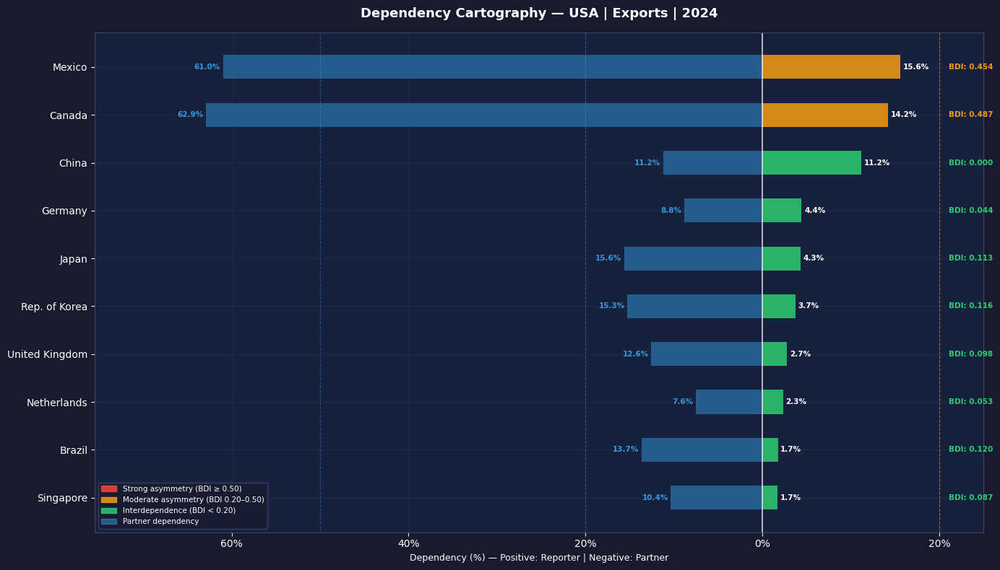


  DEPENDENCY CARTOGRAPHY — USA | X | 2024
  Partner                     Dep. →   Dep. ←      BDI Profile             
  -----------------------------------------------------------------
  Mexico                       15.6%    61.0%    0.454  Moderate
  Canada                       14.2%    62.9%    0.487  Moderate
  China                        11.2%    11.2%    0.000  Interdependence
  Germany                       4.4%     8.8%    0.044  Interdependence
  Japan                         4.3%    15.6%    0.113  Interdependence
  Rep. of Korea                 3.7%    15.3%    0.116  Interdependence
  United Kingdom                2.7%    12.6%    0.098  Interdependence
  Netherlands                   2.3%     7.6%    0.053  Interdependence
  Brazil                        1.7%    13.7%    0.120  Interdependence
  Singapore                     1.7%    10.4%    0.087  Interdependence



In [382]:
plot_dependency_cartography(df_bi_trade, df_bdi, 'USA', 'X', year=2024, n=10)

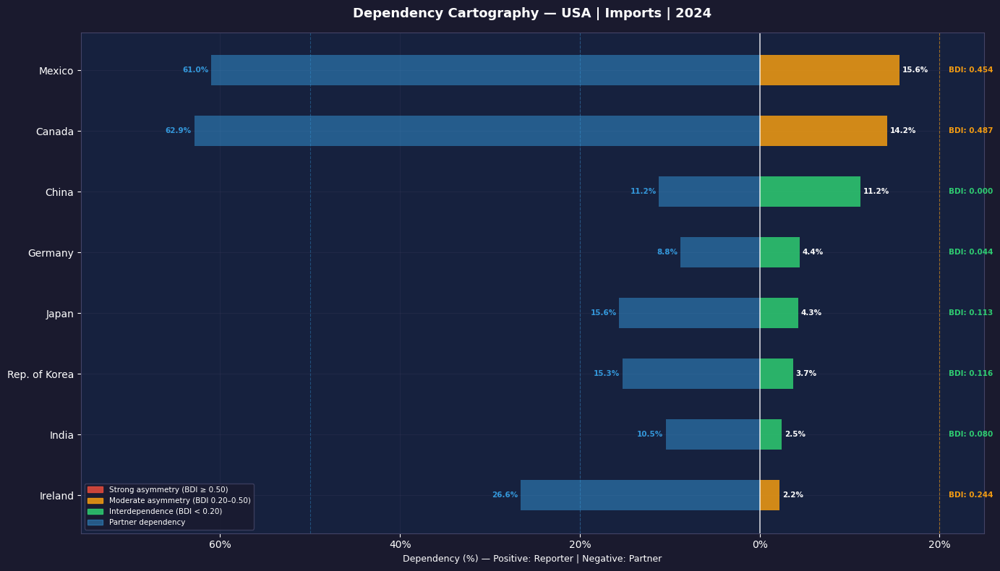


  DEPENDENCY CARTOGRAPHY — USA | M | 2024
  Partner                     Dep. →   Dep. ←      BDI Profile             
  -----------------------------------------------------------------
  Mexico                       15.6%    61.0%    0.454  Moderate
  Canada                       14.2%    62.9%    0.487  Moderate
  China                        11.2%    11.2%    0.000  Interdependence
  Germany                       4.4%     8.8%    0.044  Interdependence
  Japan                         4.3%    15.6%    0.113  Interdependence
  Rep. of Korea                 3.7%    15.3%    0.116  Interdependence
  India                         2.5%    10.5%    0.080  Interdependence
  Ireland                       2.2%    26.6%    0.244  Moderate



In [383]:
plot_dependency_cartography(df_bi_trade, df_bdi, 'USA', 'M', year=2024, n=10)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.4 Heatmap BDI
</div>

In [386]:
def plot_bdi_heatmap(df_bdi, countries, year=None):
    """    Matrix of BDI between selected countries -  Sequential colormap — BDI always positive (0 = symmetric, 1 = total asymmetry)   """
    
    if year is None:    year = df_bdi['year'].max()

    # ── Prepare matrix ────────────────────────────────────────────────────────
    df_year = df_bdi[(df_bdi['year'] == year) & (df_bdi['country_name'].isin(countries)) & (df_bdi['partner_name'].isin(countries))].copy()
    matrix = df_year.pivot(index='country_name', columns='partner_name', values='bdi').reindex(index=countries, columns=countries)

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax = styled_figure(figsize=(12, 10))
    ax.set_title(f'BDI Matrix — Bilateral Asymmetry | {year}\n' f'0 = Symmetric | 1 = Total Asymmetry',
                 fontsize=12, fontweight='bold', color='white', pad=15)

    # ── Heatmap — sequential colormap ────────────────────────────────────────
    im = ax.imshow(matrix.values, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')

    # ── Cell annotations ──────────────────────────────────────────────────────
    for i in range(len(countries)):
        for j in range(len(countries)):
            val = matrix.values[i, j]
            if np.isnan(val) or i == j:   continue
            # Text color based on background intensity
            color = 'white' if val > 0.5 else '#1a1a2e'
            # BDI level label
            level = ('Strong'   if val >= 0.50 else
                     'Moderate' if val >= 0.20 else
                     'Low')
            ax.text(j, i, f'{val:.3f}\n{level}', ha='center', va='center', fontsize=7.5, color=color, fontweight='bold')

    # ── Diagonal ──────────────────────────────────────────────────────────────
    for k in range(len(countries)):
        ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=True, color='#444466', zorder=2))
        ax.text(k, k, '—', ha='center', va='center', fontsize=10, color='#aaaaaa', zorder=3)

    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xticks(range(len(countries)))
    ax.set_yticks(range(len(countries)))
    ax.set_xticklabels(countries, rotation=45, ha='right', fontsize=9, color='white')
    ax.set_yticklabels(countries, fontsize=9, color='white')
    ax.set_xlabel('Partner', fontsize=9)
    ax.set_ylabel('Reporter', fontsize=9)

    # ── Colorbar ──────────────────────────────────────────────────────────────
    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.8)
    cbar.set_label('BDI — Asymmetry Index', color='white', fontsize=9)
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
    cbar.set_ticks([0, 0.20, 0.50, 1.0])
    cbar.set_ticklabels(['0.00\nSymmetric', '0.20\nModerate', '0.50\nStrong', '1.00\nTotal'])

    style_grid(ax)
    save_figure(fig, f'../Figures/Trade/G_6_4_bdi_heatmap_{year}.png')

    # ── Summary ───────────────────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  BDI MATRIX SUMMARY — {year}")
    print(f"{'='*60}")
    strong   = df_year[df_year['bdi'] >= 0.50]
    moderate = df_year[(df_year['bdi'] >= 0.20) & (df_year['bdi'] < 0.50)]
    print(f"  Strong asymmetry   pairs (BDI ≥ 0.50) : {len(strong)}")
    print(f"  Moderate asymmetry pairs (BDI 0.20–0.50) : {len(moderate)}")
    if not df_year.empty:
        top = df_year.loc[df_year['bdi'].idxmax()]
        print(f"  Most asymmetric pair :")
        print(f"    {top['country_name']} ↔ {top['partner_name']} " f": BDI = {top['bdi']:.3f} | {top['dominant_partner']}")
    print(f"{'='*60}\n")

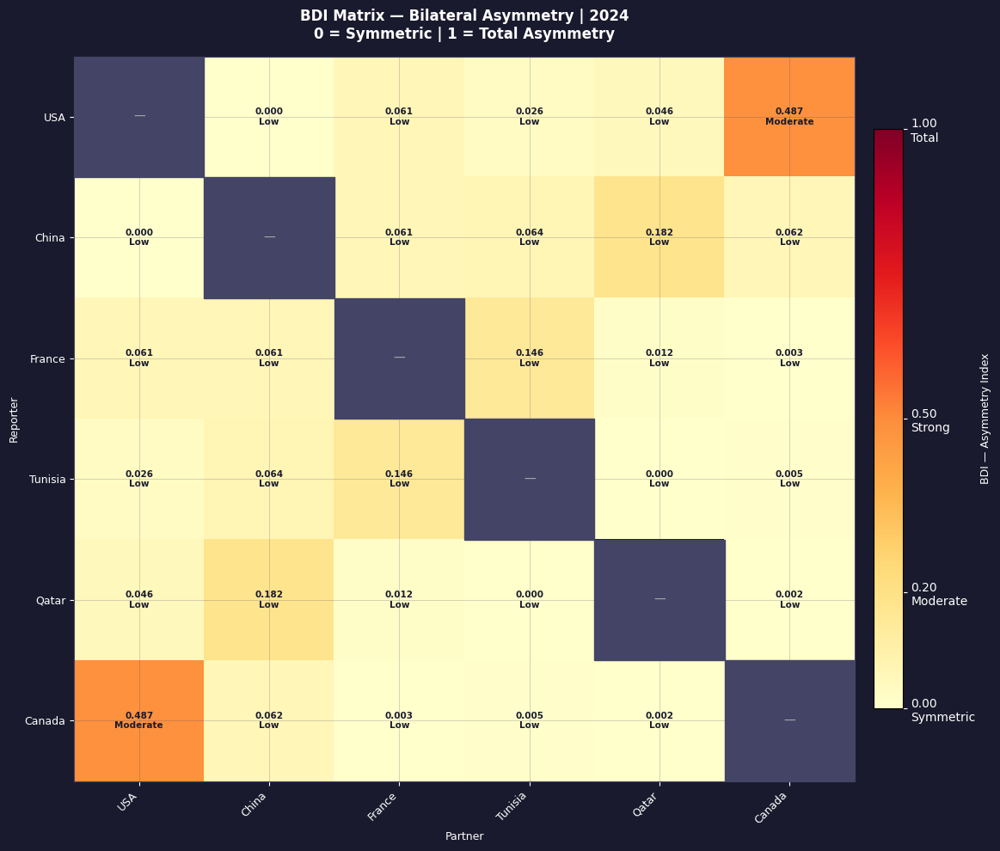


  BDI MATRIX SUMMARY — 2024
  Strong asymmetry   pairs (BDI ≥ 0.50) : 0
  Moderate asymmetry pairs (BDI 0.20–0.50) : 2
  Most asymmetric pair :
    Canada ↔ USA : BDI = 0.487 | USA



In [387]:
plot_bdi_heatmap(df_bdi, countries, year=2024)

- **Asymmetry is the norm, not the exception** — truly symmetric bilateral
  relationships (BDI ≈ 0) are rare. Most pairs show a clear dominant/dependent
  structure that persists over time.
- **Dependency direction is structurally stable** — BDI sign reversals
  (change of who depends on whom) are extremely rare, confirming that
  trade power relationships are sticky and path-dependent.
- **Small countries show systematically higher dependency** on large partners —
  Canada and Mexico toward USA, Tunisia and Morocco toward Europe —
  reflecting geographic and economic gravity effects.
- **BDI combined with HHI is the most powerful diagnostic** — a country
  with high HHI AND high BDI toward a single partner represents
  the highest structural vulnerability profile.
  Canada exemplifies this : Top-3 export share ~40%, BDI toward USA ~0.49 —
  the most concentrated and asymmetric bilateral relationship in the dataset.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 7. Structural Bilateral Dependency Index (BDI)
</div>

BDI vs Structural BDI

BDI measures asymmetry between two specific countries — who depends more on whom in a bilateral relationship.
Structural BDI measures the internal export/import imbalance of a single country across all its partners — how differently its trade is distributed between exports and imports globally.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 7.1 Create DBI STRUCTURAL TABLE
</div>

In [392]:
def compute_bdi_structural_all_countries(df_bi_trade):
    """   BDI structurel = Σ|X_share - M_share| / 2 :    Measure imbalance export/import per partner    """
    
    # Pivot pour avoir X et M par pays/année/partenaire
    pivot = (df_bi_trade.pivot_table(index=['country_name', 'year', 'partner_name'], columns='flow_code', values='share', aggfunc='sum', fill_value=0).reset_index())
    
    # S'assurer que X et M existent
    pivot['X'] = pivot.get('X', 0)
    pivot['M'] = pivot.get('M', 0)
    
    # Difference absolute of structures
    pivot['abs_diff'] = abs(pivot['X'] - pivot['M'])
    
    # Agregation per country/year
    df_bdi_struct = (pivot.groupby(['country_name', 'year'], as_index=False)['abs_diff'].sum().assign(bdis=lambda x: x['abs_diff'] / 2).drop('abs_diff', axis=1))
    
    # Calculer nombre de partenaires (pour normalisation)
    n_partners = (df_bi_trade.groupby(['country_name', 'year'])['partner_name'].nunique().reset_index().rename(columns={'partner_name': 'n_partners'}))
    # Merge
    df_bdi_struct = df_bdi_struct.merge(n_partners, on=['country_name', 'year'])
    
    # Normaliser BDI (0-1) : BDI max théorique = 1 (tous exports vers 1 pays, tous imports d'un autre) -- BDI min théorique = 0 (X_share = M_share pour tous partenaires)
    df_bdi_struct['bdis_norm'] = (df_bdi_struct['bdis'] / 1.0).clip(upper=1.0)  # Max = 1 -- Cap à 1
    # level 
    df_bdi_struct['bdis_level'] = df_bdi_struct['bdis'].apply(classify_bdi)
    # Trier
    df_bdi_struct = df_bdi_struct.sort_values(['country_name', 'year'])[["country_name", "year", "n_partners", "bdis", "bdis_norm", "bdis_level"]]
    # variation annuelle delta
    df_bdi_struct['delta_bdis'] = (df_bdi_struct.groupby('country_name')['bdis'].diff())
    df_bdi_struct['delta_bdis_norm'] = normalize_delta(df_bdi_struct['delta_bdis'])
    return df_bdi_struct

In [393]:
df_bdi_structural = compute_bdi_structural_all_countries(df_bi_trade)
df_bdi_structural.sample()

,country_name,year,n_partners,bdis,bdis_norm,bdis_level,delta_bdis,delta_bdis_norm
1737,Zimbabwe,2023,159,0.3864,0.3864,Moderate Dependance,0.0028,0.5026


In [394]:
df_bdi_structural.to_csv("../Analysis_files/Trade/df_bdi_structural.csv", index=False)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 7.2 Visualisation
</div>

In [396]:
def plot_bdis_evolution(df_bdi_structural, countries):
    """    Line chart for selected countries:     Risk zones + thresholds + annotations    """

    fig, ax = styled_figure(figsize=(14, 7))
    ax.set_title('Structural BDI Evolution — Export/Import Asymmetry by Partner', fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Risk zones ────────────────────────────────────────────────────────────
    bdis_zones = (
        (0.50, 1.00, '#e74c3c', 'Critical (> 0.50)'),
        (0.30, 0.50, '#f39c12', 'Strong (0.30–0.50)'),
        (0.15, 0.30, '#f1c40f', 'Moderate (0.15–0.30)'),
        (0.00, 0.15, '#2ecc71', 'Balanced (< 0.15)'),)
    add_risk_zones(ax, bdis_zones)
    for y, color in [(0.50, '#e74c3c'), (0.30, '#f39c12'), (0.15, '#2ecc71')]:
        ax.axhline(y=y, color=color, linewidth=0.8, linestyle='--', alpha=0.7)

    # ── Lines per country ─────────────────────────────────────────────────────
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}
    for country in countries:
        df_c = (df_bdi_structural[df_bdi_structural['country_name'] == country].sort_values('year'))
        if df_c.empty:            continue
        c = color_map[country]
        ax.plot(df_c['year'], df_c['bdis'], color=c, linewidth=2.5, marker='o', markersize=5, label=country, zorder=3)
        annotate_endpoints(ax, df_c['year'], df_c['bdis'], c, fmt='.3f')

    # ── Annotate threshold crossings for critical countries ───────────────────
    critical_threshold = 0.40
    for country in countries:
        df_c = df_bdi_structural[df_bdi_structural['country_name'] == country].sort_values('year')
        if df_c.empty:  continue
        above = df_c['bdis'] >= critical_threshold
        crossings = df_c['year'][above & (~above.shift(1, fill_value=False))]
        for yr in crossings:
            val = df_c.loc[df_c['year'] == yr, 'bdis'].values[0]
            ax.annotate(f'↑ {country}', xy=(yr, val), xytext=(4, 6), textcoords='offset points',
                        fontsize=7, color='#e74c3c', fontweight='bold')
    
    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Structural BDI', fontsize=10)
    ax.set_ylim(0, 1.05)
    style_grid(ax)
    add_legend(ax, loc='upper right')

    save_figure(fig, '../Figures/Trade/G_7_1_bdis_evolution.png')

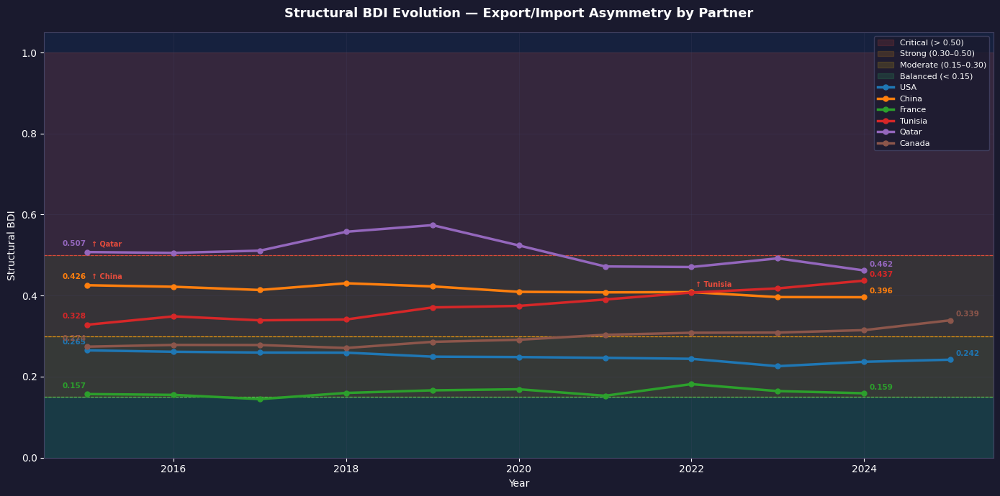

In [397]:
plot_bdis_evolution(df_bdi_structural, countries)

In [398]:
# Top n lollipop ──────────────────────────────────────────────────────
def plot_bdis_top(df_bdi_structural, n=20):
    """ Top n countries by average Structural BDI :   Lollipop chart with risk color coding    """
    
    df_avg = (df_bdi_structural.groupby('country_name')['bdis'].mean().nlargest(n).reset_index().sort_values('bdis', ascending=True))
    fig, ax = styled_figure(figsize=(12, 9))
    ax.set_title(f'Top {n} Countries — Average Structural BDI (Full Period)', fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Risk colors ───────────────────────────────────────────────────────────
    bar_colors = df_avg['bdis'].apply(lambda x:
        '#e74c3c' if x >= 0.50 else
        '#f39c12' if x >= 0.30 else
        '#f1c40f' if x >= 0.15 else
        '#2ecc71')

    # ── Lollipop ──────────────────────────────────────────────────────────────
    ax.hlines(df_avg['country_name'], 0, df_avg['bdis'], color=bar_colors, linewidth=2.0, alpha=0.7)
    ax.scatter(df_avg['bdis'], df_avg['country_name'],   color=bar_colors, s=100, zorder=3, edgecolors='white', linewidths=0.8)

    # Value labels
    for _, row in df_avg.iterrows():
        ax.text(row['bdis'] + 0.005, row['country_name'], f'{row["bdis"]:.3f}', va='center', fontsize=8, color='white', fontweight='bold')

    # Risk threshold lines
    for x, color, label in [(0.15, '#2ecc71','Balanced (0.15)'), (0.30, '#f39c12', 'Strong (0.30)'),(0.50, '#e74c3c', 'Critical (0.50)')]:
        ax.axvline(x=x, color=color, linewidth=0.8, linestyle='--', alpha=0.7, label=label)

    ax.set_xlabel('Average Structural BDI', fontsize=10)
    ax.set_xlim(0, df_avg['bdis'].max() * 1.2)
    style_grid(ax)
    add_legend(ax, loc='lower right')

    save_figure(fig, '../Figures/Trade/G_7_2_bdis_top.png')

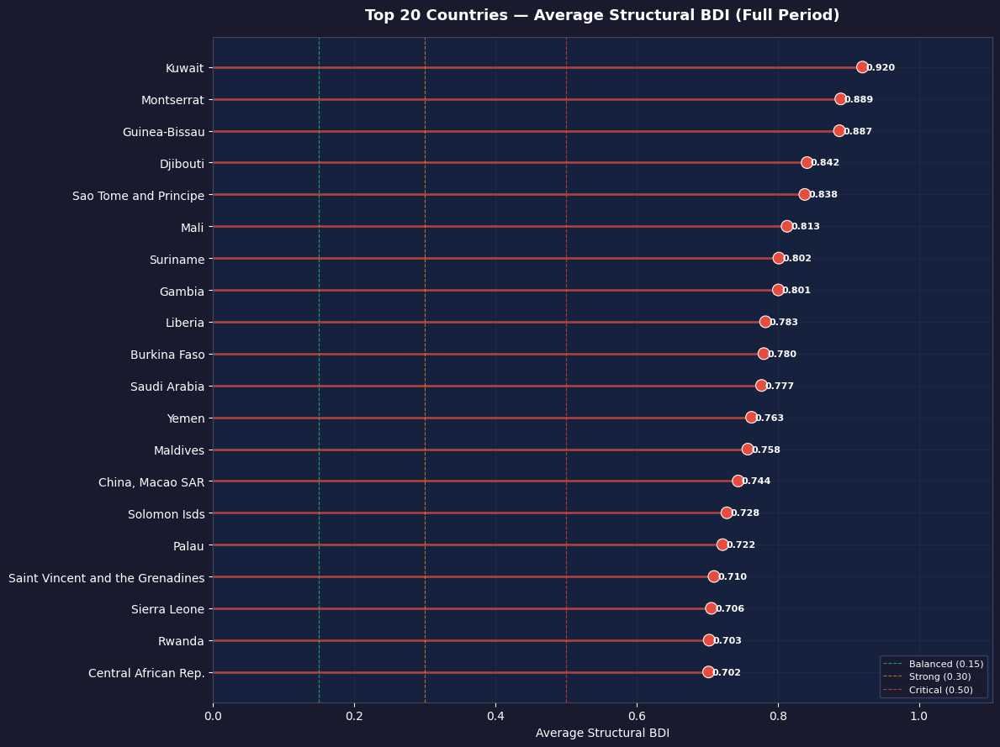

In [399]:
plot_bdis_top(df_bdi_structural)

In [402]:
# ── Merged heatmap bdis + delta_bdis ─────────────────────────────────
def plot_bdis_heatmap(df_bdi_structural, countries):
    """ merged : BDIS level + Delta BDIS heatmaps:  bdis level | delta_bdis evolution    """

    df_c = df_bdi_structural[df_bdi_structural['country_name'].isin(countries)].copy()
    pivot_bdis  = df_c.pivot(index='country_name', columns='year', values='bdis').reindex(countries)
    pivot_delta = df_c.pivot(index='country_name', columns='year', values='delta_bdis').reindex(countries)
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(20, 6))
    fig.suptitle('Structural BDI Heatmap — Level & Evolution', fontsize=14, fontweight='bold', color='white', y=1.01)

    for ax, pivot, cmap, title, vmin, vmax, label in [
        (ax1, pivot_bdis,  'YlOrRd',   'BDIS Level', 0, 1, 'BDIS (0=Balanced | 1=Critical)'),
        (ax2, pivot_delta, 'RdYlGn_r', 'BDIS Delta (Red=Worsening)',
         -pivot_delta.abs().max().max(), pivot_delta.abs().max().max(),'ΔBDIS (Negative=Improvement)')]:
        
        im = ax.imshow(pivot.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        # Cell annotations
        for i in range(len(countries)):
            for j in range(pivot.shape[1]):
                val = pivot.values[i, j]
                if np.isnan(val):      continue
                color = 'white' if abs(val) > abs(vmax) * 0.5 else '#1a1a2e'
                ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=7.5, color=color, fontweight='bold')

        ax.set_xticks(range(pivot.shape[1]))
        ax.set_xticklabels(pivot.columns, rotation=45, ha='right', fontsize=8, color='white')
        ax.set_yticks(range(len(countries)))
        ax.set_yticklabels(countries, fontsize=9, color='white')
        ax.set_title(title, fontsize=11, pad=10)
        cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.8)
        cbar.set_label(label, color='white', fontsize=8)
        cbar.ax.yaxis.set_tick_params(color='white')
        plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

    save_figure(fig, '../Figures/Trade/G_7_3_bdis_heatmap.png')

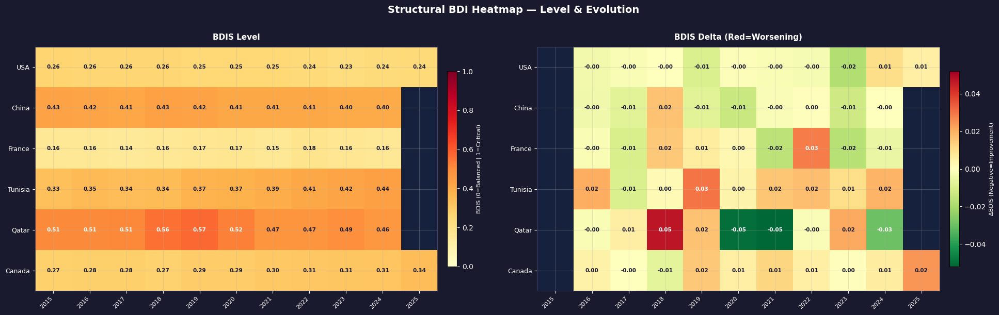

In [403]:
plot_bdis_heatmap(df_bdi_structural, countries)

- A high Structural BDI indicates that a country exports to different partners
  than it imports from — a sign of structural fragility and supply chain vulnerability.
- Countries with Structural BDI > 0.30 are structurally exposed to asymmetric
  shocks — a disruption from a key import partner cannot be compensated
  by export partners.
- A rising delta_bdis over time signals increasing structural divergence
  between export and import networks — a growing risk, not a static one.
- **Tunisia shows the most persistent deterioration** in this sample — BDIS
  rising from 0.34 (2015) to 0.44 (2024) without reversal, signaling a
  structural drift between export and import networks over the full period.
- **The Top 20 most asymmetric countries are almost exclusively small states**
  (Sub-Saharan Africa, islands, Gulf states) — their high BDIS reflects
  mono-product export structures combined with diversified import needs,
  a structurally fragile profile that large economies rarely exhibit.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 8. Most Critical Dependencies
</div>

Beyond global concentration (HHI) and bilateral asymmetry (BDI), this section
identifies the most strategically exposed relationships for each country —
capturing not only the dominant partner but the full profile of critical
dependencies that will feed into the bilateral classification scoring.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.1 Create Top Dependency TABLE
</div>

In [411]:
def compute_dependency_top(df_bi_trade, df_bdi, threshold=0.15):
    """   Build dependency_top table with enriched indicators: Captures top partner + critical dependency profile per country/year
          threshold : dependency level considered critical    """

    # ── Merge BDI with trade volume ───────────────────────────────────────────
    df = df_bdi.merge(df_bi_trade[['country_name', 'partner_name', 'year', 'value']]
        .groupby(['country_name', 'partner_name', 'year'], as_index=False)['value'].sum(),
        on=['country_name', 'partner_name', 'year'], how='left')

    # ── Rank partners by dependency ───────────────────────────────────────────
    df['partner_rank'] = (df.groupby(['country_name', 'year'])['dependency'].rank(ascending=False, method='first'))

    # ── Top partner ───────────────────────────────────────────────────────────
    df_top = (df[df['partner_rank'] == 1]
              .rename(columns={'partner_name': 'top_partner', 'value': 'top_partner_volume','bdi': 'bdi_top',
                  'dependency': 'dependency_top','dependency_reverse': 'dependency_reverse'})[
              ['country_name', 'year', 'top_partner','top_partner_volume', 'bdi_top','dependency_top', 'dependency_reverse']])

    # ── Critical partners indicators ──────────────────────────────────────────
    df_critical = (df.groupby(['country_name', 'year'])
                   .apply(lambda x: pd.Series({
                       'n_critical'    : (x['dependency'] >= threshold).sum(),
                       'critical_share': x.loc[x['dependency'] >= threshold,'dependency'].sum(),
                       'dependency_hhi': (x['dependency'] ** 2).sum()})).reset_index())
    # ── Merge ─────────────────────────────────────────────────────────────────
    df_dep_top = df_top.merge(df_critical, on=['country_name', 'year'], how='left')
    # Clip critical_share à [0, 1] — avoid negative values after normalization
    df_dep_top['critical_share']      = df_dep_top['critical_share'].clip(lower=0)
    
    # ── Delta ─────────────────────────────────────────────────────────────────
    df_dep_top = df_dep_top.sort_values(['country_name', 'year'])
    for col in ['bdi_top', 'dependency_top', 'n_critical', 'critical_share']:
        df_dep_top[f'delta_{col}'] = (df_dep_top.groupby('country_name')[col].diff())

    # ── Normalization ─────────────────────────────────────────────────────────
    df_dep_top['dependency_top_norm'] = ((df_dep_top['dependency_top'] - df_dep_top['dependency_top'].min()) / (df_dep_top['dependency_top'].max() - df_dep_top['dependency_top'].min()))
    df_dep_top['n_critical_norm'] = ((df_dep_top['n_critical'] - df_dep_top['n_critical'].min()) / (df_dep_top['n_critical'].max() - df_dep_top['n_critical'].min()))
    df_dep_top['critical_share_norm'] = ((df_dep_top['critical_share'] - df_dep_top['critical_share'].min()) /(df_dep_top['critical_share'].max() - df_dep_top['critical_share'].min()))
    df_dep_top['critical_share_norm'] = df_dep_top['critical_share_norm'].clip(lower=0, upper=1)
    df_dep_top['delta_n_critical_norm'] = ((df_dep_top['delta_n_critical'] - df_dep_top['delta_n_critical'].min()) / (df_dep_top['delta_n_critical'].max() - df_dep_top['delta_n_critical'].min()))
    df_dep_top['delta_dependency_top_norm'] = ((df_dep_top['delta_dependency_top'] - df_dep_top['delta_dependency_top'].min()) / (df_dep_top['delta_dependency_top'].max() - df_dep_top['delta_dependency_top'].min()))
    df_dep_top['delta_critical_share_norm'] = ((df_dep_top['delta_critical_share'] - df_dep_top['delta_critical_share'].min()) / (df_dep_top['delta_critical_share'].max() - df_dep_top['delta_critical_share'].min()))
    
    # ── Level & Trend ─────────────────────────────────────────────────────────
    df_dep_top['dependency_top_level'] = df_dep_top['dependency_top'].apply(dep_level)
    df_dep_top['bdi_top_trend']        = df_dep_top['delta_bdi_top'].apply(trend_label)
    df_dep_top['dependency_top_trend'] = df_dep_top['delta_dependency_top'].apply(trend_label)

    return df_dep_top

In [412]:
df_dependency_top = compute_dependency_top(df_bi_trade, df_bdi, threshold=0.15)
df_dependency_top.sample()

,country_name,year,top_partner,top_partner_volume,bdi_top,dependency_top,dependency_reverse,n_critical,critical_share,dependency_hhi,...,delta_critical_share,dependency_top_norm,n_critical_norm,critical_share_norm,delta_n_critical_norm,delta_dependency_top_norm,delta_critical_share_norm,dependency_top_level,bdi_top_trend,dependency_top_trend
602,France,2019,Germany,173280853546.9320,0.0737,0.1445,0.0707,0.0000,0.0000,0.0547,...,-0.1510,0.1674,0.0000,0.0000,0.2500,0.6431,0.5300,Low,Stable,Stable


In [416]:
df_dependency_top.to_csv("../Analysis_files/Trade/df_dependency_top.csv", index=False)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.2 Hetmap Top Dependency
</div>

In [418]:
def plot_dependency_top_heatmap(df_dependency_top, countries, year=None):
    """    Heatmap : Top Partner + Dependency + BDI per country per year    """

    if year is None: years = sorted(df_dependency_top['year'].unique())
    else:  years = [year]
    df_c = df_dependency_top[df_dependency_top['country_name'].isin(countries)].copy()

    pivot_dep     = df_c.pivot(index='country_name', columns='year', values='dependency_top').reindex(countries)
    pivot_partner = df_c.pivot(index='country_name', columns='year', values='top_partner').reindex(countries)
    pivot_bdi     = df_c.pivot(index='country_name', columns='year', values='bdi_top').reindex(countries)

    fig, ax = styled_figure(figsize=(18, len(countries) * 0.9 + 3))
    ax.set_title('Most Critical Dependencies — Top Partner Evolution\n''Color: Dependency Level | Text: Partner | BDI',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    im = ax.imshow(pivot_dep.values, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')

    # Cell annotations
    for i in range(len(countries)):
        for j, yr in enumerate(pivot_dep.columns):
            dep = pivot_dep.values[i, j]
            bdi = pivot_bdi.values[i, j]
            partner = pivot_partner.values[i, j]
            if any(v is None or (isinstance(v, float) and np.isnan(v))
                   for v in [dep, bdi]):  continue
            text_color = 'white' if dep > 0.4 else '#1a1a2e'
            ax.text(j, i, f'{partner}\n{dep*100:.1f}% | BDI:{bdi:.2f}', ha='center', va='center', fontsize=8, color=text_color, fontweight='bold')

    ax.set_xticks(range(len(pivot_dep.columns)))
    ax.set_xticklabels(pivot_dep.columns, rotation=45, ha='right', fontsize=11, color='white')
    ax.set_yticks(range(len(countries)))
    ax.set_yticklabels(countries, fontsize=10, color='white')

    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.8)
    cbar.set_label('Dependency Level', color='white', fontsize=9)
    cbar.set_ticks([0, 0.15, 0.25, 0.45, 1.0])
    cbar.set_ticklabels(['0\nLow', '0.15\nModerate','0.25\nHigh', '0.45\nCritical', '1.0'])
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

    save_figure(fig, '../Figures/Trade/G_8_2_dependency_top_heatmap.png')

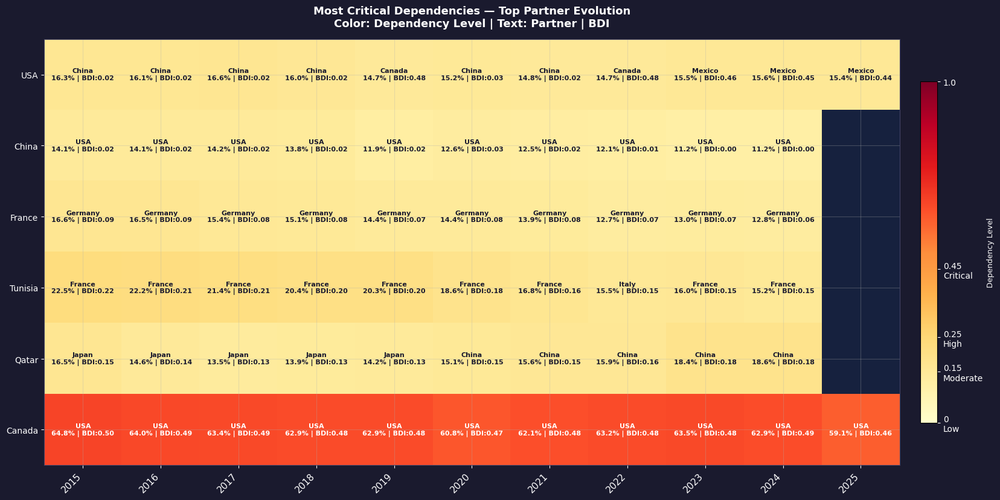

In [420]:
plot_dependency_top_heatmap(df_dependency_top, countries)

In [421]:
countries = ['USA', 'China', 'France', 'Egypt', 'Qatar', 'Canada', 'Brazil', 'Tunisia']

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.3 Number of Critical Partners
</div>

In [425]:
def plot_critical_n(df_dependency_top, countries):
    """ N Critical Partners : bars grouped by country (moean + % + max)"""
    markers = ['o','s','^','D','v','p','h','*','X','P']
    colors   = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    df_c = df_dependency_top[df_dependency_top['country_name'].isin(countries)].copy()
    summary = (df_c.groupby('country_name')['n_critical']
               .agg(mean='mean', max='max', pct_above_zero=lambda x: (x > 0).mean() * 100).reindex(countries))

    fig, ax = styled_figure(figsize=(12, 6))
    fig.suptitle('Critical Dependency — N Critical Partners per Country', fontsize=13, fontweight='bold', color='white')

    positions = np.arange(len(countries))
    bars = ax.bar(positions, summary['mean'], width=0.6,
                  color=[color_map[c] for c in countries],
                  alpha=0.85, zorder=2, edgecolor='white', linewidth=0.5)

    for bar, country in zip(bars, countries):
        pct = summary.loc[country, 'pct_above_zero']
        mx  = int(summary.loc[country, 'max'])
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'{pct:.0f}% yrs\nmax={mx}',
                ha='center', va='bottom', fontsize=8, color=color_map[country], fontweight='bold')

    ax.set_xlabel('Country', fontsize=10)
    ax.set_ylabel('Average N Critical Partners (dependency ≥ 15%)', fontsize=10)
    ax.set_xticks(positions)
    ax.set_xticklabels(countries, rotation=20, ha='right', fontsize=9, color='white')
    ax.set_ylim(0, summary['mean'].max() * 1.6)
    style_grid(ax)

    save_figure(fig, '../Figures/Trade/G_8_3_n_critical.png')

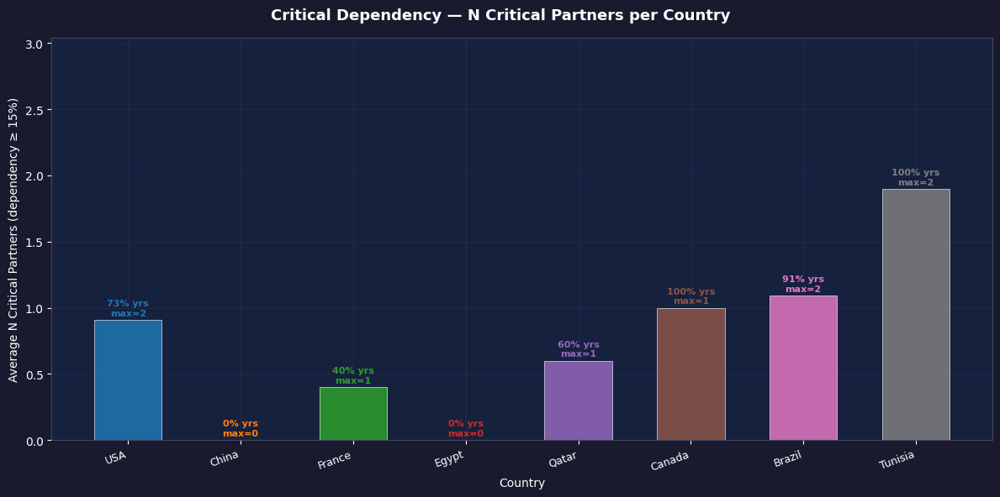

In [426]:
plot_critical_n(df_dependency_top, countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.4 Critical Share evolution
</div>

In [430]:
def plot_critical_share(df_dependency_top, countries):
    """     Critical Share evolution : bars grouped by year  """
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    df_c  = df_dependency_top[df_dependency_top['country_name'].isin(countries)].copy()
    
    # ── Align on common years only ────────────────────────────────────────────
    all_years = sorted(df_c['year'].unique())
    n_years   = len(all_years)
    year_pos  = {yr: i for i, yr in enumerate(all_years)}  # year → x position
    n     = len(countries)
    width = 0.8 / n
    
    fig, ax = styled_figure(figsize=(14, 6))
    fig.suptitle('Critical Share Evolution — Share of Trade with Critical Partners', fontsize=13, fontweight='bold', color='white')

    for k, country in enumerate(countries):
        df_co  = df_c[df_c['country_name'] == country].sort_values('year')
        color  = color_map[country]
        offset = (k - n / 2) * width + width / 2

        # Use actual year positions — skip missing years
        x_vals = [year_pos[yr] + offset for yr in df_co['year']]
        
        ax.bar(x_vals, df_co['critical_share'] * 100, width=width, color=color, alpha=0.80, label=country, 
               zorder=2, edgecolor='#1a1a2e', linewidth=0.3)

    ax.set_xlabel('Year', color='white')
    ax.set_ylabel('Critical Share (%)', color='white')
    ax.set_xticks(range(n_years))
    ax.set_xticklabels(all_years, rotation=45, ha='right', fontsize=8, color='white')
    style_grid(ax)
    ax.legend(fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left',
              bbox_to_anchor=(1.01, 1), borderaxespad=0)
    plt.tight_layout()
    save_figure(fig, '../Figures/Trade/G_8_3_critical_share.png')

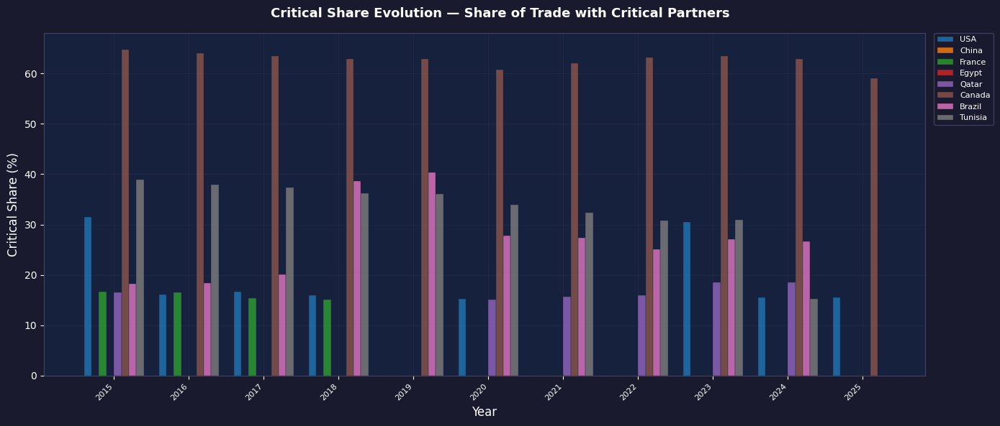

In [434]:
plot_critical_share(df_dependency_top, countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.5 Dependency HHI evolution
</div>

In [438]:
def plot_dependency_hhi(df_dependency_top, countries):
    """   Dependency HHI evolution : line chart by country  """

    markers   = ['o','s','^','D','v','p','h','*','X','P']
    colors    = plt.cm.tab10.colors
    color_map = {c: colors[i % 10] for i, c in enumerate(countries)}

    df_c     = df_dependency_top[df_dependency_top['country_name'].isin(countries)].copy()
    
    # ── Align on union of all years ───────────────────────────────────────────
    all_years = sorted(df_c['year'].unique())
    year_pos  = {yr: i for i, yr in enumerate(all_years)}

    fig, ax = styled_figure(figsize=(14, 8))
    fig.suptitle('Dependency HHI Evolution — Partner Concentration Over Time', fontsize=13, fontweight='bold', color='white')

    for i, country in enumerate(countries):
        df_co = df_c[df_c['country_name'] == country].sort_values('year')
        if df_co.empty:    continue
        color = color_map[country]
        
        # Map actual years to x positions — gaps remain as gaps in the line
        x_vals = [year_pos[yr] for yr in df_co['year']]
        
        ax.plot(x_vals, df_co['dependency_hhi'], color=color, linewidth=2, marker=markers[i % len(markers)],
                markersize=5, label=country, zorder=3)

        # Annotate first and last available point
        ax.annotate(f"{df_co['dependency_hhi'].iloc[0]:.2f}", xy=(x_vals[0], df_co['dependency_hhi'].iloc[0]),
                    xytext=(-18, 4), textcoords='offset points', fontsize=8, color=color)
        ax.annotate(f"{df_co['dependency_hhi'].iloc[-1]:.2f}", xy=(x_vals[-1], df_co['dependency_hhi'].iloc[-1]),
                    xytext=(4, 4), textcoords='offset points',  fontsize=8, color=color)

    ax.set_xlabel('Year', color='white')
    ax.set_ylabel('Dependency HHI', color='white')
    ax.set_xticks(range(len(all_years)))
    ax.set_xticklabels(all_years, rotation=45, ha='right', fontsize=8, color='white')
    style_grid(ax)
    ax.legend(fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left',
              bbox_to_anchor=(1.01, 1), borderaxespad=0)
    plt.tight_layout()
    save_figure(fig, '../Figures/Trade/G_8_4_dependency_hhi.png')

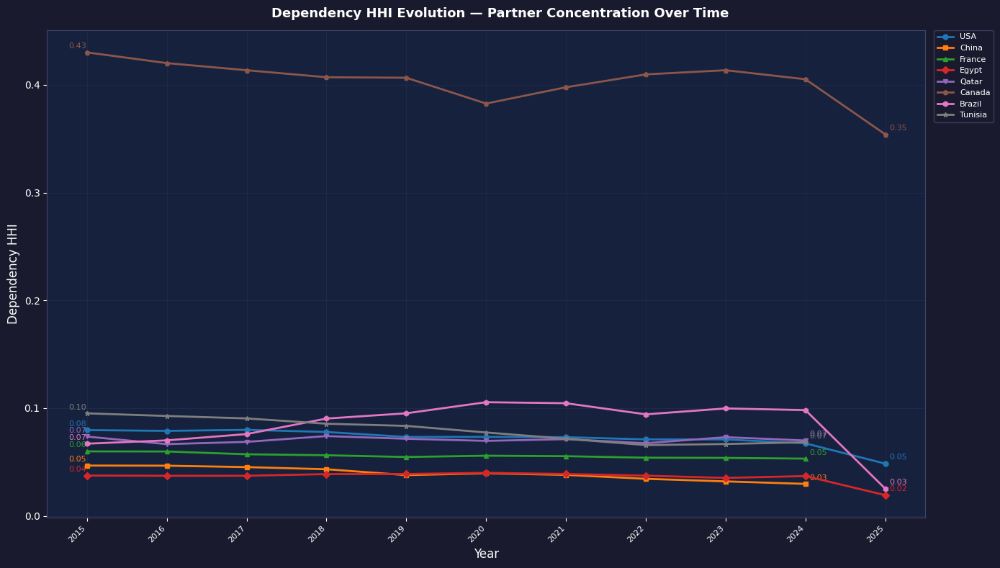

In [439]:
plot_dependency_hhi(df_dependency_top, countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 8.6 Insights
</div>

- **Top partner dependency is structurally persistent** — the dominant partner
  rarely changes over time, confirming the gravity-driven nature of trade relationships.
- **Partner switches signal macro-structural shifts** — USA's top export partner
  shifted from China (2015–2018) to Canada (2019–2022) to Mexico (2023–2024),
  reflecting the US-China trade war and post-COVID nearshoring dynamics.
- **n_critical reveals hidden vulnerability** — a country with moderate top
  dependency but many critical partners (n_critical > 3) is structurally more
  exposed than a country concentrated on a single dominant partner.
- **critical_share + dependency_hhi together** provide the most complete picture
  of a country's bilateral exposure — critical_share captures breadth,
  dependency_hhi captures concentration within critical relationships.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 9. Bilateral Typology (Annual)
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.1 Merge Tables
</div>

In [451]:
def build_summary_table(df_hhi, df_dependency_top, df_bdi_structural, df_world_trade):
    """ Merge all bilateral indicators into a single summary table    """
    
    # HHI + Dependency Top
    df = df_hhi.merge(df_dependency_top, on=['country_name', 'year'], how='left')
    # BDI Structural
    df = df.merge(df_bdi_structural[['country_name', 'year', 'bdis', 'bdis_norm','bdis_level', 'delta_bdis']], on=['country_name', 'year'], how='left')
    # Trade volume
    df = df.merge(df_world_trade[['country_name', 'year', 'flow_code', 'value']], on=['country_name', 'year', 'flow_code'], how='left')
    return df

In [452]:
df_summary = build_summary_table(df_hhi, df_dependency_top, df_bdi_structural, df_world_trade)
df_summary.sample().style.format(_format_value, subset=["value"])

,country_name,year,flow_code,n_partners,hhi,delta_hhi,hhi_norm,delta_hhi_norm,hhi_level,hhi_trend,top_partner,top_partner_volume,bdi_top,dependency_top,dependency_reverse,n_critical,critical_share,dependency_hhi,delta_bdi_top,delta_dependency_top,delta_n_critical,delta_critical_share,dependency_top_norm,n_critical_norm,critical_share_norm,delta_n_critical_norm,delta_dependency_top_norm,delta_critical_share_norm,dependency_top_level,bdi_top_trend,dependency_top_trend,bdis,bdis_norm,bdis_level,delta_bdis,value
2663,Romania,2017,M,174,0.074738,-0.002103,0.069390,0.497935,Low,Stable,Germany,33344955885.070000,0.200999,0.213825,0.012826,1.000000,0.213825,0.076989,0.003404,0.004202,0.000000,0.004202,0.248884,0.333333,0.239132,0.500000,0.652136,0.658071,Moderate,Stable,Stable,0.185639,0.185639,Interdependence,0.003718,85.32B


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.2 Logic Profile
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
####  Logic Classification
</div>

In [455]:
def classify_profile_logic(row):
    hhi_lvl = row['hhi_level']
    dep_lvl = row['dependency_top_level']
    hhi_tr  = row['hhi_trend']
    dep_tr  = row['dependency_top_trend']
    n_crit  = row['n_critical']

    if hhi_lvl == 'Extreme' and dep_lvl == 'Critical':                                                               return 'Critical Dependency'
    if (hhi_lvl in ['High','Extreme'] and dep_lvl in ['High','Critical'] and hhi_tr == 'Increasing' and dep_tr == 'Increasing'): 
                                                                                                                     return 'Critical Dependency'
    if hhi_lvl == 'Extreme' or dep_lvl == 'Critical':                                                                return 'Vulnerable'
    if hhi_lvl == 'High' and dep_lvl == 'High':                                                                      return 'Vulnerable'
    if (hhi_lvl == 'High' and dep_lvl == 'Moderate' and      hhi_tr == 'Increasing'):                                return 'Vulnerable'
    if (dep_lvl == 'High' and hhi_lvl == 'Moderate' and      dep_tr == 'Increasing'):                                return 'Vulnerable'
    if (hhi_lvl == 'Moderate' and dep_lvl == 'Moderate' and  hhi_tr == 'Increasing' and dep_tr == 'Increasing'):     return 'Vulnerable'
    if hhi_lvl in ['Moderate', 'High'] or dep_lvl in ['Moderate', 'High']:                                           return 'Stable but Concentrated'
    return 'Robust'

In [457]:
df_summary['profile_logic'] = df_summary.apply(classify_profile_logic, axis=1)
df_summary.sample().style.format(_format_value, subset=["value"])

,country_name,year,flow_code,n_partners,hhi,delta_hhi,hhi_norm,delta_hhi_norm,hhi_level,hhi_trend,top_partner,top_partner_volume,bdi_top,dependency_top,dependency_reverse,n_critical,critical_share,dependency_hhi,delta_bdi_top,delta_dependency_top,delta_n_critical,delta_critical_share,dependency_top_norm,n_critical_norm,critical_share_norm,delta_n_critical_norm,delta_dependency_top_norm,delta_critical_share_norm,dependency_top_level,bdi_top_trend,dependency_top_trend,bdis,bdis_norm,bdis_level,delta_bdis,value,profile_logic
90,Antigua and Barbuda,2019,X,56,0.301070,0.140700,0.288362,0.584660,Extreme,Increasing,USA,277676451.080000,0.458292,0.458409,0.000116,1.000000,0.458409,0.224179,-0.025722,-0.025727,0.000000,-0.025727,0.536002,0.333333,0.512662,0.500000,0.627007,0.633372,Critical,Decreasing,Decreasing,0.788072,0.788072,High Dependance,0.112284,37.4M,Critical Dependency


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
####  Logic Profile Distribution
</div>

In [461]:
df_summary[(df_summary["flow_code"]=="X") & (df_summary["year"]==2023)]['profile_logic'].value_counts()

profile_logic
Stable but Concentrated    71
Vulnerable                 43
Robust                     28
Critical Dependency        21
Name: count, dtype: int64

In [462]:
df_summary[(df_summary["flow_code"]=="M") & (df_summary["year"]==2024)]['profile_logic'].value_counts()

profile_logic
Stable but Concentrated    76
Robust                     30
Vulnerable                 22
Critical Dependency         8
Name: count, dtype: int64

**Data Note** : Annual analysis for 2024 covers 133 countries due to
reporting lags in UN Comtrade bilateral trade data. 

- The majority of countries fall in **Stable but Concentrated** or **Vulnerable**
  categories, confirming that pure diversification is structurally rare globally.
- Import profiles show systematically higher vulnerability than export profiles,
  reflecting the asymmetric nature of supply-side dependency vs market dependency.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.3 Score & Profile Score
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
####  Score & Profile
</div>

In [470]:
def compute_bilateral_score(row):
    """  Composite score Static only — Dynamic (non discriminant)    """
    score = 0.35* row['critical_share_norm'] + 0.25* row['hhi_norm'] + 0.2* row['dependency_top_norm'] + 0.1* row['n_critical_norm'] + 0.1* row['bdis_norm']
    return score

def classify_profile_score(score):
    if score < 0.10:    return 'Robust'
    elif score < 0.30:  return 'Stable but Concentrated'
    elif score < 0.50:  return 'Vulnerable'
    else:               return 'Critical Dependency'

In [471]:
df_summary['score_flow'] = df_summary.apply(compute_bilateral_score, axis=1)
df_summary['profile_score'] = df_summary['score_flow'].apply(classify_profile_score)
df_summary.sample().style.format(_format_value, subset=["value"])

,country_name,year,flow_code,n_partners,hhi,delta_hhi,hhi_norm,delta_hhi_norm,hhi_level,hhi_trend,top_partner,top_partner_volume,bdi_top,dependency_top,dependency_reverse,n_critical,critical_share,dependency_hhi,delta_bdi_top,delta_dependency_top,delta_n_critical,delta_critical_share,dependency_top_norm,n_critical_norm,critical_share_norm,delta_n_critical_norm,delta_dependency_top_norm,delta_critical_share_norm,dependency_top_level,bdi_top_trend,dependency_top_trend,bdis,bdis_norm,bdis_level,delta_bdis,value,profile_logic,score_flow,profile_score
3211,Tunisia,2019,M,177,0.070984,-0.000466,0.065706,0.499542,Low,Stable,France,7420414896.008000,0.195879,0.203199,0.007320,2.000000,0.360249,0.083568,-0.000725,-0.000902,0.000000,-0.001568,0.236410,0.666667,0.402885,0.500000,0.647851,0.653310,Moderate,Stable,Stable,0.370843,0.370843,Moderate Dependance,0.029764,21.57B,Stable but Concentrated,0.308469,Vulnerable


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
####  Profile Distribution
</div>

In [474]:
df_summary[(df_summary["flow_code"]=="X") & (df_summary["year"]==2024)]['profile_score'].value_counts()

profile_score
Stable but Concentrated    65
Vulnerable                 36
Robust                     26
Critical Dependency         9
Name: count, dtype: int64

In [475]:
df_summary[(df_summary["flow_code"]=="M") & (df_summary["year"]==2024)]['profile_score'].value_counts()

profile_score
Stable but Concentrated    69
Vulnerable                 34
Robust                     25
Critical Dependency         8
Name: count, dtype: int64

- Score distributions are right-skewed — most countries cluster at low-moderate
  vulnerability, with a long tail of highly exposed countries confirming
  that critical dependency is structurally rare but concentrated.
- Import and Export score distributions are nearly identical in shape,
  suggesting that bilateral concentration is symmetric across trade directions
  for most countries — divergences reveal structural asymmetries worth investigating.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.4 Final Table
</div>

In [479]:
def classify_profile_logic_global(row):
    """Combined Import + Export logic profile"""
    
    p_imp = row.get('profile_logic_import', '')
    p_exp = row.get('profile_logic_export', '')

    if (p_imp == 'Critical Dependency' and p_exp == 'Critical Dependency'):  return 'Critical Dependency'
    if (p_imp == 'Critical Dependency' or  p_exp == 'Critical Dependency'):  return 'Vulnerable'
    if p_imp == 'Vulnerable' or p_exp == 'Vulnerable':                       return 'Vulnerable'
    if p_imp == 'Robust' and p_exp == 'Robust':                              return 'Robust'
    
    return 'Stable but Concentrated'

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.4.1 Create Final Table
</div>

In [485]:
def build_final_table(df_summary):
    """ Pivot Import/Export → Final bilateral typology table    """
    
    # Split Import / Export
    df_imp = df_summary[df_summary['flow_code'] == 'M'].copy()
    df_exp = df_summary[df_summary['flow_code'] == 'X'].copy()
    # Rename Import columns
    imp_rename = {
                    'hhi': 'hhi_import', 'hhi_norm': 'hhi_import_norm', 'hhi_level': 'hhi_import_level', 'hhi_trend': 'hhi_import_trend',
                    'delta_hhi': 'delta_hhi_import', 'n_partners': 'n_partners_import', 'score_flow': 'score_import', 
                    'profile_score': 'profile_score_import', 'profile_logic': 'profile_logic_import', 'value': 'value_import'
                 }
    # Rename Export columns
    exp_rename = {
                    'hhi': 'hhi_export', 'hhi_norm': 'hhi_export_norm', 'hhi_level': 'hhi_export_level', 'hhi_trend': 'hhi_export_trend',
                    'delta_hhi': 'delta_hhi_export', 'n_partners': 'n_partners_export', 'score_flow': 'score_export', 
                    'profile_score': 'profile_score_export', 'profile_logic': 'profile_logic_export', 'value': 'value_export'
                 }
    df_imp = df_imp.rename(columns=imp_rename)
    df_exp = df_exp.rename(columns=exp_rename)
    # Shared columns
    shared = ['country_name', 'year', 'top_partner', 'dependency_top','dependency_top_norm', 'dependency_top_level', 'dependency_top_trend',
              'n_critical', 'n_critical_norm', 'critical_share', 'critical_share_norm','bdis', 'bdis_norm', 'bdis_level']
    imp_cols = shared + list(imp_rename.values())
    exp_cols = ['country_name', 'year'] + list(exp_rename.values())
    
    df_final = df_imp[imp_cols].merge(df_exp[exp_cols], on=['country_name', 'year'], how='outer')
    df_final['total_trade'] = df_final['value_export'] + df_final['value_import']
    # Global score and profile
    df_final['score_global'] = (0.55 * df_final['score_import'] + 0.45 * df_final['score_export'])
    df_final['profile_score_global']  = df_final['score_global'].apply(classify_profile_score)
    df_final['profile_logic_global']  = df_final.apply(classify_profile_logic_global, axis=1)

    return df_final

In [486]:
df_final = build_final_table(df_summary)
df_final.sample()

,country_name,year,top_partner,dependency_top,dependency_top_norm,dependency_top_level,dependency_top_trend,n_critical,n_critical_norm,critical_share,...,delta_hhi_export,n_partners_export,score_export,profile_score_export,profile_logic_export,value_export,total_trade,score_global,profile_score_global,profile_logic_global
1139,Netherlands,2023,Germany,0.2002,0.2328,Moderate,Stable,1.0000,0.3333,0.2002,...,-0.0071,235.0000,0.2049,Stable but Concentrated,Stable but Concentrated,717440099558.3510,1364473993216.5439,0.2020,Stable but Concentrated,Stable but Concentrated


In [489]:
df_final[df_final['year']==2024]['profile_logic_global'].value_counts()

profile_logic_global
Stable but Concentrated    66
Vulnerable                 41
Robust                     22
Critical Dependency         7
Name: count, dtype: int64

In [490]:
df_final[df_final['year']==2024]['profile_score_global'].value_counts()

profile_score_global
Stable but Concentrated    70
Vulnerable                 33
Robust                     25
Critical Dependency         8
Name: count, dtype: int64

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.4.2 Global Score
</div>

In [497]:
def plot_global_scores(df_final, countries, year):    
    df_viz = df_final[(df_final["country_name"].isin(countries)) & (df_final["year"]== year)].dropna().sort_values('profile_score_global', ascending=True)
    fig = go.Figure()
    fig.add_trace(go.Bar(y=df_viz['country_name'], x=df_viz['score_global'],  orientation='h',
        marker=dict(color=df_viz['profile_score_global'].map({
                'Robust': 'green', 'Stable but Concentrated': 'gold',
                'Vulnerable': 'orange','Critical Dependency': 'red'})),
        text=df_viz['score_global'].round(3), textposition='outside', hovertemplate='<b>%{y}</b><br>Score: %{x:.3f}<br>Profil: ' + df_viz['profile_score_global'] + '<extra></extra>'))
    
    fig.update_layout(title=dict(text='Trade Vulnerability — Global Bilateral Score',
                                 font=dict(color='white', size=14)),
                      xaxis_title='Vulnerability Score (0–1)', yaxis_title='Country',
                      height=60 * len(countries), showlegend=False, template='plotly_dark',
                      paper_bgcolor='#1a1a2e',  plot_bgcolor='#16213e', font=dict(color='white'),
                      xaxis=dict(gridcolor='#444466', zerolinecolor='#444466'),
                      yaxis=dict(gridcolor='#444466'))
    fig.write_html(f'../Figures/Trade/G_9_4_2_global_scores_{year}.html', include_plotlyjs='cdn')
    fig.show()

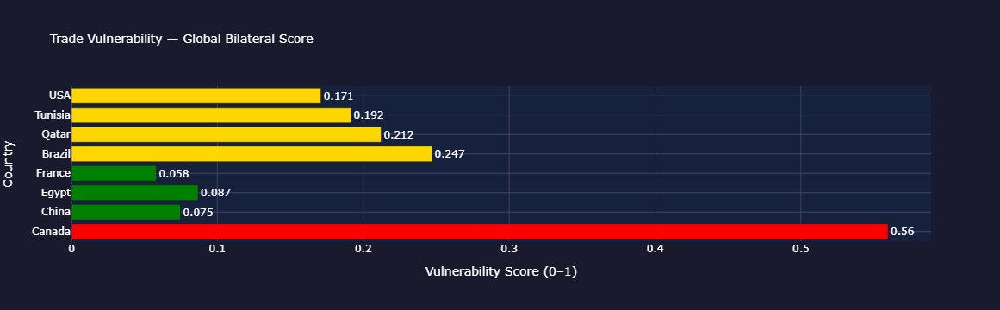

In [498]:
plot_global_scores(df_final, countries, 2024)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.4.3 Import vs Export Vulnerability
</div>

In [504]:
def plot_import_export_vulnerability(df_final, countries, year=None):
    """    Import vs Export Vulnerability Scatter: X : score_import | Y : score_export | Color : profile_score_global | Size : score_global    """
    
    if year is None:      year = df_final['year'].max()
    df_y = df_final[(df_final['year'] == year)].dropna(subset=['score_import', 'score_export']).copy()
    df_high = df_y[df_y['country_name'].isin(countries)]
    profile_colors = {'Robust':'#2ecc71', 'Stable but Concentrated': '#f1c40f', 'Vulnerable':'#f39c12','Critical Dependency':'#e74c3c'}
    fig, ax = styled_figure(figsize=(14, 10))
    ax.set_title(f'Import vs Export Vulnerability — {year}\n' f'Above diagonal : Import more exposed | ' f'Below : Export more exposed', fontsize=13, fontweight='bold', color='white', pad=15)

    # All countries background
    for profile, color in profile_colors.items():
        df_p = df_y[df_y['profile_score_global'] == profile]
        ax.scatter(df_p['score_import'], df_p['score_export'], color=color, s=40, alpha=0.35, edgecolors='none', zorder=1)

    # Highlighted countries
    for _, row in df_high.iterrows():
        color = profile_colors.get(row['profile_score_global'], '#aaaaaa')
        ax.scatter(row['score_import'], row['score_export'], color=color, s=row['score_global'] * 800 + 80, edgecolors='white', linewidths=1.0, zorder=3, alpha=0.9)
        ax.annotate(row['country_name'], xy=(row['score_import'], row['score_export']), xytext=(8, 4), textcoords='offset points', fontsize=8, 
                    color=color, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)

    # Diagonal balanced line
    max_val = max(df_y['score_import'].max(), df_y['score_export'].max()) * 1.1
    ax.plot([0, max_val], [0, max_val], color='#aaaaaa', linewidth=1.0, linestyle='--', alpha=0.7, label='Import = Export (Balanced)')

    # Threshold lines
    for val, color, label in [(0.10, '#2ecc71', 'Robust threshold'), (0.30, '#f1c40f', 'Stable threshold'), (0.50, '#f39c12', 'Vulnerable threshold')]:
        ax.axvline(x=val, color=color, linewidth=0.8, linestyle=':', alpha=0.5)
        ax.axhline(y=val, color=color, linewidth=0.8, linestyle=':', alpha=0.5)
    ax.axvline(x=0.50, color='#f39c12', linewidth=2, linestyle=':', alpha=1)
    ax.axhline(y=0.50, color='#f39c12', linewidth=2, linestyle=':', alpha=1)

    # Quadrant labels
    quad_labels = [(0.65, 0.15, 'Import\nExposed',  '#e74c3c'), (0.3, 0.65, 'Export\nExposed',  '#f39c12'),
                   (0.65, 0.65, 'Dual\nExposed',    '#e74c3c'),  (0.3, 0.15, 'Balanced\nLow Risk','#2ecc71'),]
    for x, y, lbl, color in quad_labels:
        ax.text(x, y, lbl, fontsize=8, color=color, ha='center', va='center', fontstyle='italic', 
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.9, edgecolor='none'))

    # Legend profiles
    from matplotlib.patches import Patch
    legend_elements = [Patch(color=color, alpha=0.85, label=profile.split(' ', 1)[-1]) for profile, color in profile_colors.items()]
    ax.legend(handles=legend_elements, fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left',
              title='Profile', title_fontsize=8)

    ax.set_xlabel('Import Vulnerability Score', fontsize=10)
    ax.set_ylabel('Export Vulnerability Score', fontsize=10)
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    style_grid(ax)

    save_figure(fig, f'../Figures/Trade/G_9_4_3_import_export_vulnerability_{year}.png')

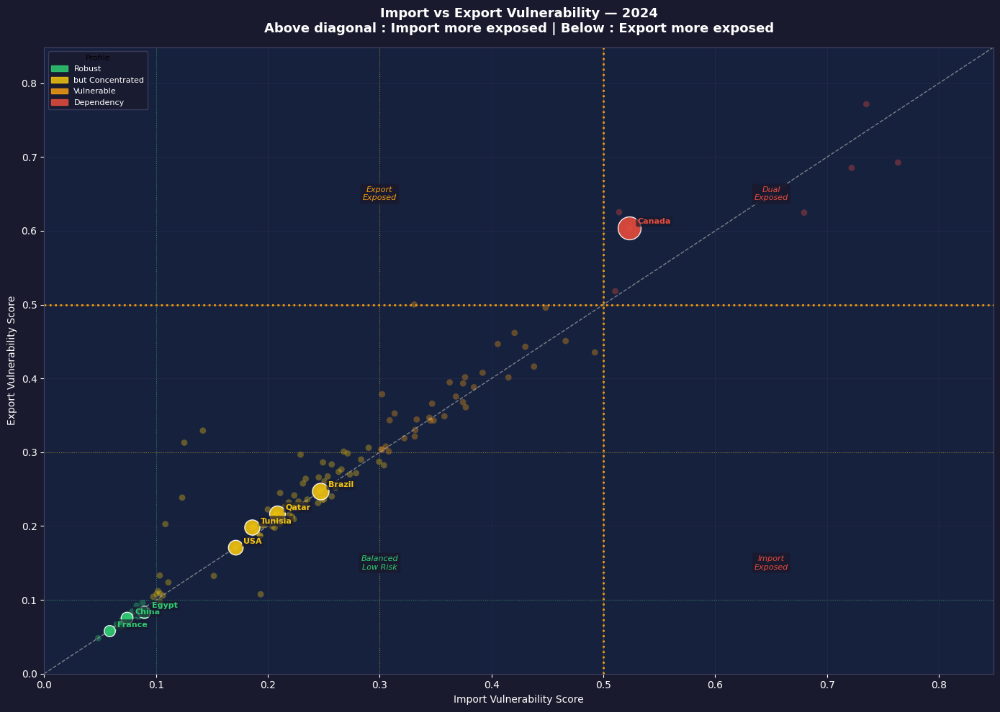

In [506]:
plot_import_export_vulnerability(df_final, countries, year=2024)

- Most countries cluster near the diagonal — import and export vulnerability
  are correlated, suggesting that partner concentration affects both
  trade directions simultaneously.
- Countries above the diagonal (Import > Export exposure) represent
  supply-side dependent economies — more vulnerable to procurement shocks
  than to market loss.
- Highlighted countries in the Dual Exposed quadrant combine high import
  and export concentration — the most strategically fragile profiles.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.4.4 Risk matrix (HHI vs Dependency)
</div>

In [511]:
def plot_risk_matrix(df_final, countries, year=None, n=20):
    """    Risk Matrix : HHI vs critical_share. Size : score_global | Color : profile_score_global. All countries + highlighted    """
    
    if year is None: year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year].dropna(subset=['score_global']).copy()
    # Average HHI import/export
    df_y['hhi_avg'] = (df_y['hhi_import'] + df_y['hhi_export']) / 2
    df_high = df_y[df_y['country_name'].isin(countries)]
    profile_colors = {'Robust':'#2ecc71', 'Stable but Concentrated': '#f1c40f', 'Vulnerable':'#f39c12','Critical Dependency':'#e74c3c'}
    
    fig, ax = styled_figure(figsize=(14, 10))
    ax.set_title(f'Bilateral Exposure Matrix — HHI vs Critical Share | {year}\n' f'Size: Global Score | Color: Risk Profile',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # Quadrant backgrounds
    median_x = df_y['hhi_avg'].median()
    median_y = df_y['critical_share'].median()
    xlim = (0, df_y['hhi_avg'].max() * 0.9)
    ylim = (-0.1, df_y['critical_share'].max() * 0.9)

    ax.fill_betweenx([median_y, ylim[1]], median_x, xlim[1], color='#e74c3c', alpha=0.07)  # High HHI + High critical share
    ax.fill_betweenx([-0.1, median_y], median_x, xlim[1], color='#f39c12', alpha=0.07)  # High HHI + Low critical share
    ax.fill_betweenx([median_y, ylim[1]], 0, median_x, color='#f39c12', alpha=0.07)  # Low HHI + High critical share
    ax.fill_betweenx([-0.1, median_y], 0, median_x, color='#2ecc71', alpha=0.07)  # Low HHI + Low critical share

    quadrant_labels = [('Dual Risk', xlim[1] * 0.5, ylim[1] * 0.75), ('HHI Driven', xlim[1] * 0.5, ylim[1] * 0.12),
                       ('Critical Share Driven', xlim[1] * 0.075, ylim[1] * 0.75), ('Low Exposure', xlim[1] * 0.075, ylim[1] * 0.12)]
    for lbl, x, y in quadrant_labels:
        ax.text(x, y, lbl, fontsize=8.5, color='#cccccc', ha='center', va='center', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))
    # Median lines
    ax.axvline(x=median_x, color='white', linewidth=1.5, linestyle='--', alpha=0.7)
    ax.axhline(y=median_y, color='white', linewidth=1.5, linestyle='--', alpha=0.7)
    
    # All countries
    for profile, color in profile_colors.items():
        df_p = df_y[df_y['profile_score_global'] == profile]
        ax.scatter(df_p['hhi_avg'], df_p['critical_share'], color=color, s=30, alpha=0.30, edgecolors='none', zorder=1)
    # Highlighted countries
    for _, row in df_high.iterrows():
        color = profile_colors.get(row['profile_score_global'], '#aaaaaa')
        ax.scatter(row['hhi_avg'], row['critical_share'], color=color, s=row['score_global'] * 800 + 100, 
                   edgecolors='white', linewidths=1.0, zorder=3, alpha=0.9)
        ax.annotate(row['country_name'], xy=(row['hhi_avg'], row['critical_share']),
                    xytext=(8, 4), textcoords='offset points', fontsize=8, color=color, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)
    # Legend 
    from matplotlib.patches import Patch
    legend_elements = [Patch(color=color, alpha=0.85, label=profile.split(' ', 1)[-1]) for profile, color in profile_colors.items()]
    ax.legend(handles=legend_elements, fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left', title='Profile', title_fontsize=8)

    ax.set_xlabel('Average HHI (Import + Export) / 2', fontsize=10)
    ax.set_ylabel('Critical_Share', fontsize=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    style_grid(ax)

    save_figure(fig, f'../Figures/Trade/G_9_4_4_bilateral_exposure_matrix_{year}.png')

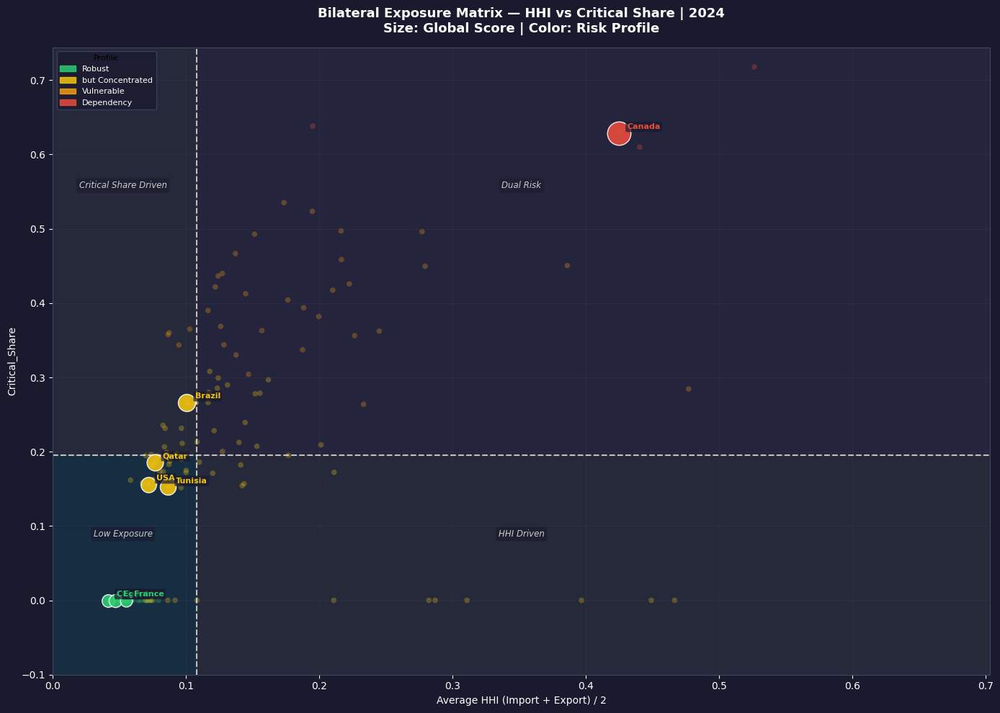

In [512]:
plot_risk_matrix(df_final, countries, year=2024)

- **Risk matrix** reveals two distinct vulnerability drivers —
  HHI-driven countries concentrate on few partners globally,
  while dependency-driven countries over-rely on a single dominant partner.
  The Dual Risk quadrant contains the most strategically exposed economies.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.5 Results And Stats
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.5.1 Results
</div>

In [518]:
def results_stats(df_final, year=None, countries=None, n=10):
    """   Distribution and top countries   """
    if year is None:    year = df_final['year'].max()
    df_res = df_final[df_final['year'] == year]

    print(f"\n{'='*70}")
    print(f"  BILATERAL TYPOLOGY RESULTS — {year}")
    print(f"{'='*70}")

    # Profile distribution
    print(f"\n  Profile Score Distribution:")
    for profile, count in df_res['profile_score_global'].value_counts().items():
        pct = count / len(df_res) * 100
        print(f"    {profile:<35} : {count:>3} ({pct:.1f}%)")

    print(f"\n  Profile Logic Distribution:")
    for profile, count in df_res['profile_logic_global'].value_counts().items():
        pct = count / len(df_res) * 100
        print(f"    {profile:<35} : {count:>3} ({pct:.1f}%)")

    # Sample countries
    cols = ['country_name', 'score_global', 'score_import', 'score_export', 'profile_score_global', 'profile_logic_global']
    if countries:
        print(f"\n  Selected Countries:")
        print(df_res[df_res['country_name'].isin(countries)][cols].sort_values('score_global').to_string(index=False))


In [519]:
results_stats(df_final, year=2024, countries=countries)


  BILATERAL TYPOLOGY RESULTS — 2024

  Profile Score Distribution:
    Stable but Concentrated             :  70 (51.5%)
    Vulnerable                          :  33 (24.3%)
    Robust                              :  25 (18.4%)
    Critical Dependency                 :   8 (5.9%)

  Profile Logic Distribution:
    Stable but Concentrated             :  66 (48.5%)
    Vulnerable                          :  41 (30.1%)
    Robust                              :  22 (16.2%)
    Critical Dependency                 :   7 (5.1%)

  Selected Countries:
country_name  score_global  score_import  score_export    profile_score_global    profile_logic_global
      France        0.0581        0.0582        0.0581                  Robust                  Robust
       China        0.0747        0.0740        0.0755                  Robust                  Robust
       Egypt        0.0868        0.0893        0.0839                  Robust                  Robust
         USA        0.1710        0.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.5.2 Profiles Distribution
</div>

In [523]:
def plot_logic_profile_distribution(df_final, year=None):
    """ Logic Profile Distribution : Bar chart : global + import + export side by side    """
    if year is None:     year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year]
    profiles = ['Robust', 'Stable but Concentrated', 'Vulnerable', 'Critical Dependency']
    profile_colors = {'Robust':'#2ecc71', 'Stable but Concentrated': '#f1c40f', 'Vulnerable':'#f39c12','Critical Dependency':'#e74c3c'}

    # Prepare data 
    data = {}
    for col, label in [('profile_logic_global', 'Global'), ('profile_logic_import', 'Import'), ('profile_logic_export', 'Export')]:
        counts = df_y[col].value_counts().reindex(profiles, fill_value=0)
        data[label] = counts
        
    df_plot = pd.DataFrame(data)

    # Figure 
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, 7))
    fig.suptitle(f'Logic Profile Distribution — {year}', fontsize=14, fontweight='bold', color='white', y=1.01)

    # LEFT : Grouped bar chart 
    x      = np.arange(len(profiles))
    width  = 0.25
    labels = ['Global', 'Import', 'Export']
    bar_colors = ['#3498db', '#e74c3c', '#2ecc71']

    for i, (label, color) in enumerate(zip(labels, bar_colors)):
        bars = ax1.bar(x + i * width, df_plot[label], width=width, color=color, alpha=0.85, label=label, edgecolor='none', zorder=2)
        for bar, val in zip(bars, df_plot[label]):
            if val > 0:
                ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, str(int(val)), ha='center', va='bottom', fontsize=8, color='white', fontweight='bold')

    ax1.set_xticks(x + width)
    ax1.set_xticklabels(['Robust', 'Stable', 'Vulnerable', 'Critical'], fontsize=9, color='white')
    ax1.set_ylabel('Number of Countries', fontsize=10)
    ax1.set_title('Profile Distribution — Global / Import / Export', fontsize=11, pad=10)
    style_grid(ax1)
    add_legend(ax1, loc='upper right')

    # RIGHT : Stacked % bar chart (for Global) 
    years   = sorted(df_final['year'].unique())
    bottom  = np.zeros(len(years))
    for profile in profiles:
        counts = [df_final[df_final['year'] == y]['profile_logic_global'].value_counts().get(profile, 0) for y in years]
        totals = [len(df_final[df_final['year'] == y]) for y in years]
        pcts   = [c / t * 100 if t > 0 else 0 for c, t in zip(counts, totals)]

        bars = ax2.bar(years, pcts, bottom=bottom, color=profile_colors[profile], alpha=0.85, edgecolor='none', label=profile.split(' ', 1)[-1], zorder=2)
        
        last_year = years[-1]
        last_idx  = list(years).index(last_year)
        for bar in bars:
            h = bar.get_height()
            if h > 3 and bar.get_x() + bar.get_width() / 2 > last_year - 0.5:
                ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + h / 2, f'{h:.0f}%', ha='center', 
                         va='center', fontsize=8, color='white', fontweight='bold')
        bottom += np.array(pcts)

    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('Share (%)', fontsize=10)
    ax2.set_title('Profile Evolution Over Time (%)', fontsize=11, pad=10)
    ax2.set_ylim(0, 105)
    ax2.set_xticks(years)
    style_grid(ax2)
    add_legend(ax2, loc='best', fontsize=7)

    save_figure(fig, '../Figures/Trade/G_9_5_2_logic_profile_distribution.png')

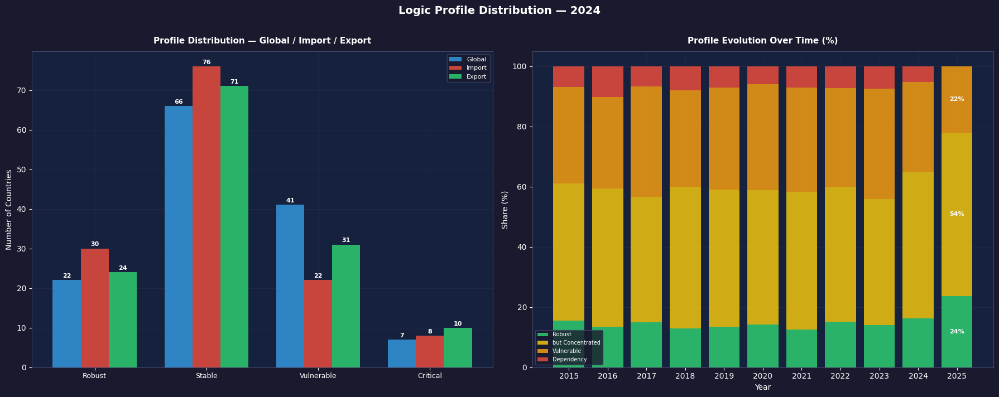

In [526]:
plot_logic_profile_distribution(df_final, year=2024)

In [527]:
def plot_score_distribution(df_final, year=None):
    """    Score Distribution : Histogram + KDE of score_global, score_import, score_export  + Profile threshold lines    """
    
    if year is None:        year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year].dropna(subset=['score_global', 'score_import', 'score_export'])
    fig, axes = styled_subplots(nrows=1, ncols=3, figsize=(18, 6))
    ax1, ax2, ax3 = axes
    fig.suptitle(f'Bilateral Score Distribution — {year}', fontsize=14, fontweight='bold', color='white', y=1.01)

    # ── Threshold config ──────────────────────────────────────────────────────
    thresholds = [(0.10, '#2ecc71', 'Robust'), (0.30, '#f1c40f', 'Stable'), (0.50, '#f39c12', 'Vulnerable')]

    for ax, col, label, color in [
        (ax1, 'score_import',  'Import Score',  '#e74c3c'),
        (ax2, 'score_export',  'Export Score',  '#2ecc71'),
        (ax3, 'score_global',  'Global Score',  '#3498db'),]:
        
        data = df_y[col].dropna()
        # Histogram
        n, bins, patches = ax.hist(data, bins=20, color=color, alpha=0.6, edgecolor='none', zorder=2, density=False)
        # KDE
        from scipy.stats import gaussian_kde
        kde_x = np.linspace(data.min(), data.max(), 200)
        kde   = gaussian_kde(data)
        ax_kde = ax.twinx()
        ax_kde.set_facecolor('#16213e')
        ax_kde.plot(kde_x, kde(kde_x), color=color, linewidth=2.5, zorder=3)
        ax_kde.set_yticks([])
        for spine in ax_kde.spines.values(): spine.set_edgecolor('#444466')

        # Threshold lines + zone labels
        ymax = n.max() * 1.3
        for x_thresh, t_color, t_label in thresholds:
            ax.axvline(x=x_thresh, color=t_color, linewidth=1.2, linestyle='--', alpha=0.8)
            ax.text(x_thresh + 0.005, ymax * 0.85, t_label, fontsize=7, color=t_color, rotation=90, va='top')
        # Mean + median
        ax.axvline(x=data.mean(), color='white', linewidth=1.0, linestyle=':', alpha=0.7, label=f'Mean: {data.mean():.3f}')
        ax.axvline(x=data.median(), color='#aaaaaa', linewidth=1.0, linestyle=':', alpha=0.7, label=f'Median: {data.median():.3f}')
        # Stats annotation
        ax.text(0.97, 0.95, f'Mean:   {data.mean():.3f}\n' f'Median: {data.median():.3f}\n' f'Std: {data.std():.3f}', transform=ax.transAxes, 
                fontsize=8, color='white', ha='right', va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.8, edgecolor='#444466'))

        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel('Count', fontsize=10)
        ax.set_title(f'{label} Distribution', fontsize=11, pad=10)
        ax.set_ylim(0, ymax)
        style_grid(ax)
        add_legend(ax, loc='upper left', fontsize=7)

    save_figure(fig, '../Figures/Trade/G_9_5_2_score_distribution.png')

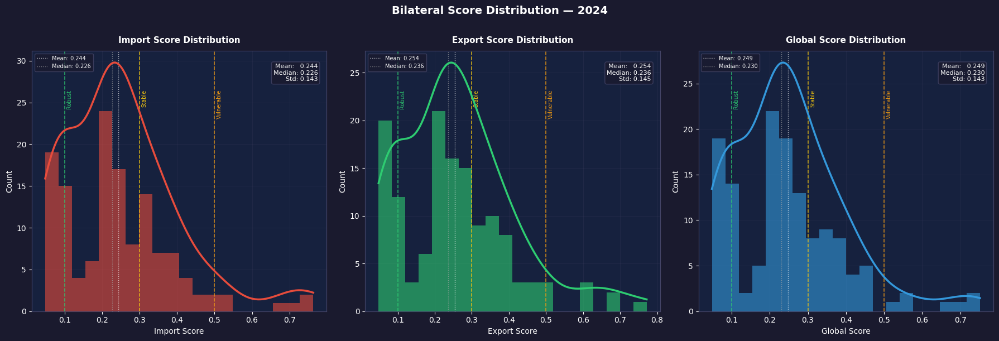

In [528]:
plot_score_distribution(df_final, year=2024)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.5.3 Top Robust/Vulnerable countries
</div>

In [530]:
def plot_global_scores_ranking(df_final, countries, year=None, n=15):
    """    Global Score Ranking : Top N Vulnerable + Top N Robust horizontal bar chart    """
    if year is None:        year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year].dropna(subset=['score_global']).copy()
    top_vulnerable = df_y.nlargest(n, 'score_global')
    top_robust     = df_y.nsmallest(n, 'score_global')

    profile_colors = {'Robust':'#2ecc71', 'Stable but Concentrated': '#f1c40f', 'Vulnerable':'#f39c12','Critical Dependency':'#e74c3c'}
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, n * 0.7 + 3))
    fig.suptitle(f'Bilateral Risk Ranking — Top {n} | {year}', fontsize=14, fontweight='bold', color='white', y=1.01)

    for ax, df_plot, title in [(ax1, top_vulnerable.sort_values('score_global'), f'Top {n} Most Vulnerable'),
                               (ax2, top_robust.sort_values('score_global', ascending=False), f'Top {n} Most Robust'),]:
        bar_colors = [profile_colors.get(p, '#aaaaaa') for p in df_plot['profile_score_global']]
        bars = ax.barh(df_plot['country_name'], df_plot['score_global'], color=bar_colors, edgecolor='none', height=0.6, zorder=2)
        # Value labels
        for bar, val in zip(bars, df_plot['score_global']):
            ax.text(val + 0.003, bar.get_y() + bar.get_height() / 2, f'{val:.3f}', va='center', fontsize=8, color='white', fontweight='bold')

        # Highlight selected countries
        for i, (_, row) in enumerate(df_plot.iterrows()):
            if row['country_name'] in countries:
                bars[i].set_edgecolor('#f1c40f')
                bars[i].set_linewidth(2.0)
        # Threshold lines
        for val, color, label in [(0.10, '#2ecc71', 'Robust'), (0.30, '#f1c40f', 'Stable'), (0.50, '#f39c12', 'Vulnerable')]:
            ax.axvline(x=val, color=color, linewidth=0.8, linestyle='--', alpha=0.7, label=label)
            
        ax.set_xlabel('Bilateral Risk Score', fontsize=10)
        ax.set_title(title, fontsize=11, pad=10)
        ax.set_xlim(0, df_y['score_global'].max() * 1.2)
        style_grid(ax)
        add_legend(ax, loc='lower right', fontsize=7)

    save_figure(fig, f'../Figures/Trade/G_9_5_3_score_ranking_{year}.png')

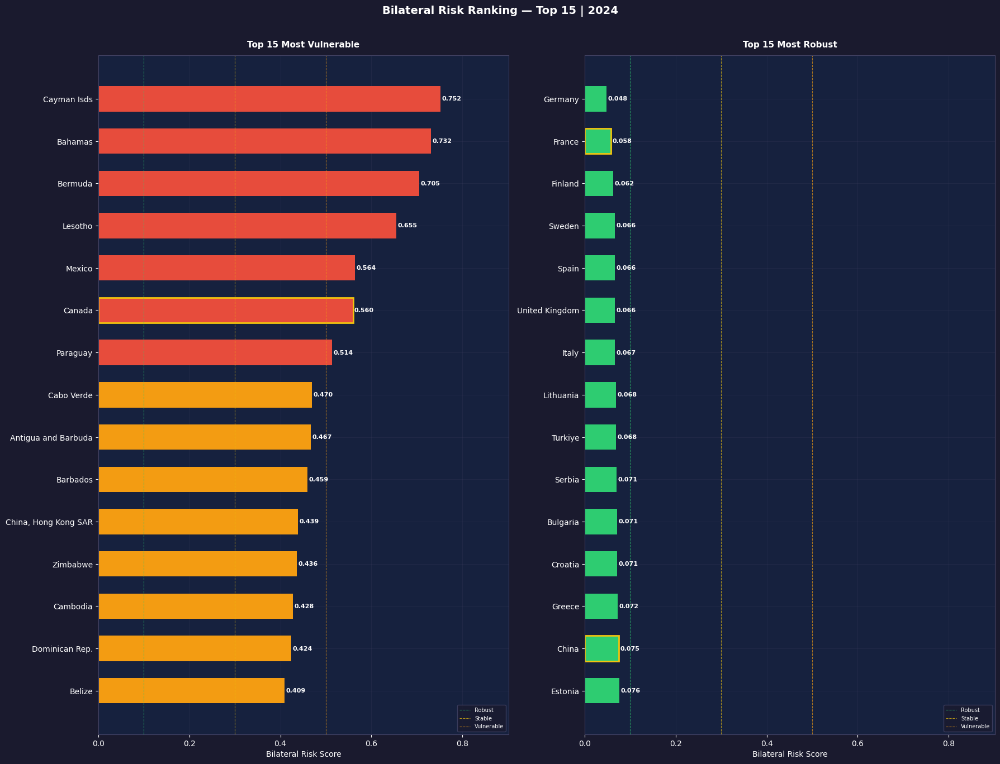

In [533]:
plot_global_scores_ranking(df_final, countries, year=2024, n=15)

- **Score ranking** confirms that small trade-dependent economies
  (island states, landlocked countries) dominate the Critical quadrant —
  their limited partner diversification creates structural fragility
  regardless of trade volume.
- **Canada (0.558) and Mexico (0.563) rank in the Top 6 most bilaterally
  vulnerable countries** — despite being G20 economies and Top 5 exporters.
  This counter-intuitive result reflects the structural cost of over-dependence
  on a single dominant partner (USA) — trade power does not protect
  against bilateral fragility.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.6 PROFILES CONVERGENCE/DIVERGENCE
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.6.1 Convergence
</div>

In [539]:
df_final['convergence'] = (df_final['profile_score_global'] == df_final['profile_logic_global'])
# In 70% of cases, the two approaches converge. Divergences indicate countries in structural transition.

In [540]:
def plot_convergence_matrix(df_final, year=None):
    """    Convergence Matrix (Confusion Matrix style) : Score profile vs Logic profile. Green diagonal = convergence | Red off-diagonal = divergence    """
    from sklearn.metrics import confusion_matrix
    from matplotlib.colors import ListedColormap

    if year is None:        year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year].dropna(subset=['profile_score_global', 'profile_logic_global'])
    profiles = ['Robust', 'Stable but Concentrated', 'Vulnerable', 'Critical Dependency']
    short    = ['Robust', 'Stable', 'Vulnerable', 'Critical']
    
    cm = confusion_matrix(df_y['profile_score_global'], df_y['profile_logic_global'], labels=profiles)

    # Color matrix : 0=empty, 1=divergence, 2=convergence
    color_matrix        = np.zeros(cm.shape)
    color_matrix[cm > 0] = 1
    np.fill_diagonal(color_matrix, 2)
    cmap = ListedColormap(['#1a1a2e', '#e74c3c', '#2ecc71'])

    fig, ax = styled_figure(figsize=(10, 8))
    ax.set_title(f'Convergence Matrix — Score vs Logic | {year}\n' f'Green = Convergence | Red = Divergence', fontsize=13, fontweight='bold', color='white', pad=15)
    im = ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=2, aspect='auto')

    # Cell annotations
    for i in range(len(profiles)):
        for j in range(len(profiles)):
            val = cm[i, j]
            if val == 0:                continue
            text_color = 'white' if color_matrix[i, j] < 2 else '#1a1a2e'
            ax.text(j, i, str(int(val)), ha='center', va='center', fontsize=13, color=text_color, fontweight='bold')

    ax.set_xticks(range(len(profiles)))
    ax.set_yticks(range(len(profiles)))
    ax.set_xticklabels(short, fontsize=10, color='white')
    ax.set_yticklabels(short, fontsize=10, color='white')
    ax.set_xlabel('Logic Profile', fontsize=10)
    ax.set_ylabel('Score Profile', fontsize=10)

    # Convergence rate annotation
    conv_rate = df_y['convergence'].mean() * 100
    ax.text(0.98, 0.02, f'Convergence Rate: {conv_rate:.1f}%', transform=ax.transAxes, fontsize=10, color='white', ha='right', va='bottom', 
            fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.8, edgecolor='#444466'))

    save_figure(fig, f'../Figures/Trade/G_9_6_1_convergence_matrix_{year}.png')


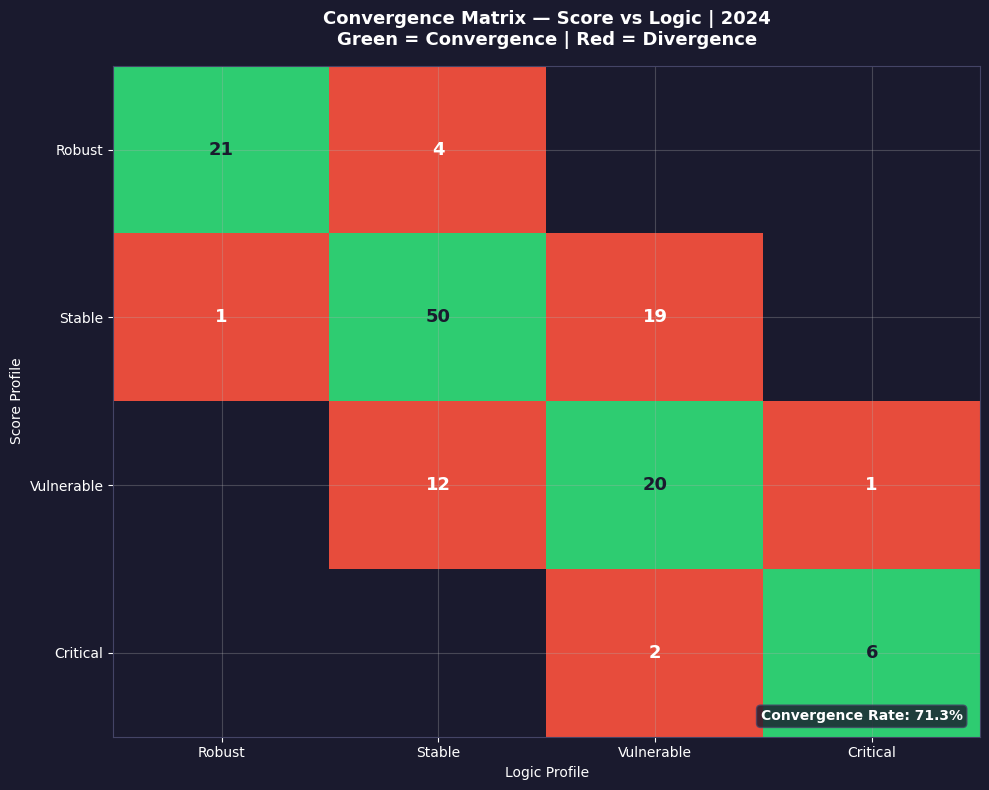

In [541]:
plot_convergence_matrix(df_final, year=2024)

- **High convergence rate** between score and logic profiles confirms that
  the two classification approaches are methodologically consistent —
  divergences are analytically meaningful, not random noise.

In [543]:
df_final[df_final['year']==2024][['profile_score_global', 'profile_logic_global']].loc[~df_final[df_final['year']==2024]['convergence']].value_counts().head(10)

profile_score_global     profile_logic_global   
Stable but Concentrated  Vulnerable                 19
Vulnerable               Stable but Concentrated    12
Robust                   Stable but Concentrated     4
Critical Dependency      Vulnerable                  2
Stable but Concentrated  Robust                      1
Vulnerable               Critical Dependency         1
Name: count, dtype: int64

In [544]:
def plot_convergence_scatter(df_final, countries, year=None):
    """    Convergence Scatter: X : score_global | Color : profile_logic | Marker : convergence. Highlights divergent countries    """
    
    if year is None:  year = df_final['year'].max()
    df_y = df_final[df_final['year'] == year].dropna(subset=['score_global', 'profile_logic_global', 'profile_score_global']).copy()
    profile_colors = {'Robust':'#2ecc71', 'Stable but Concentrated': '#f1c40f', 'Vulnerable':'#f39c12','Critical Dependency':'#e74c3c'}

    fig, ax = styled_figure(figsize=(14, 8))
    ax.set_title(f'Score vs Logic Convergence — {year}\n'  f'Circle = Convergence | X = Divergence | ' f'Color = Logic Profile',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Plot all countries ────────────────────────────────────────────────────
    for _, row in df_y.iterrows():
        color  = profile_colors.get(row['profile_logic_global'], '#aaaaaa')
        marker = 'o' if row['convergence'] else 'X'
        size   = 150 if row['country_name'] in countries else 100
        alpha  = 0.9 if row['country_name'] in countries else 0.4
        zorder = 3 if row['country_name'] in countries else 1

        ax.scatter(row['score_global'], list(profile_colors.keys()).index(row['profile_logic_global']) + np.random.uniform(-0.2, 0.2),
                   color=color, marker=marker, s=size, alpha=alpha,
                   edgecolors='white' if row['country_name'] in countries else 'none', linewidths=0.8, zorder=zorder)

        # Annotate highlighted countries
        if row['country_name'] in countries:
            ax.annotate(row['country_name'], xy=(row['score_global'], list(profile_colors.keys()).index(row['profile_logic_global'])),
                xytext=(8, 4), textcoords='offset points', fontsize=7.5, color=color, fontweight='bold', 
                bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)
    
    # ── Threshold lines ───────────────────────────────────────────────────────
    for val, color, label in [(0.10, '#2ecc71', 'Robust'), (0.30, '#f1c40f', 'Stable'), (0.50, '#f39c12', 'Vulnerable')]:
        ax.axvline(x=val, color=color, linewidth=0.8, linestyle='--', alpha=0.6, label=label)

    # ── Y axis labels ─────────────────────────────────────────────────────────
    ax.set_yticks(range(len(profile_colors)))
    ax.set_yticklabels(['Robust', 'Stable', 'Vulnerable', 'Critical'], fontsize=9, color='white')

    # ── Legend markers ────────────────────────────────────────────────────────
    from matplotlib.lines import Line2D
    marker_legend = [Line2D([0], [0], marker='o', color='w', markerfacecolor='white', markersize=8, label='Convergence'),
        Line2D([0], [0], marker='X', color='w', markerfacecolor='white', markersize=8, label='Divergence'),]
    ax.legend(handles=marker_legend, fontsize=8, facecolor='#1a1a2e', edgecolor='#444466', labelcolor='white', loc='upper left')

    ax.set_xlabel('Global Bilateral Risk Score', fontsize=10)
    ax.set_ylabel('Logic Profile', fontsize=10)
    style_grid(ax)

    save_figure(fig, f'../Figures/Trade/G_9_6_1_convergence_scatter_{year}.png')

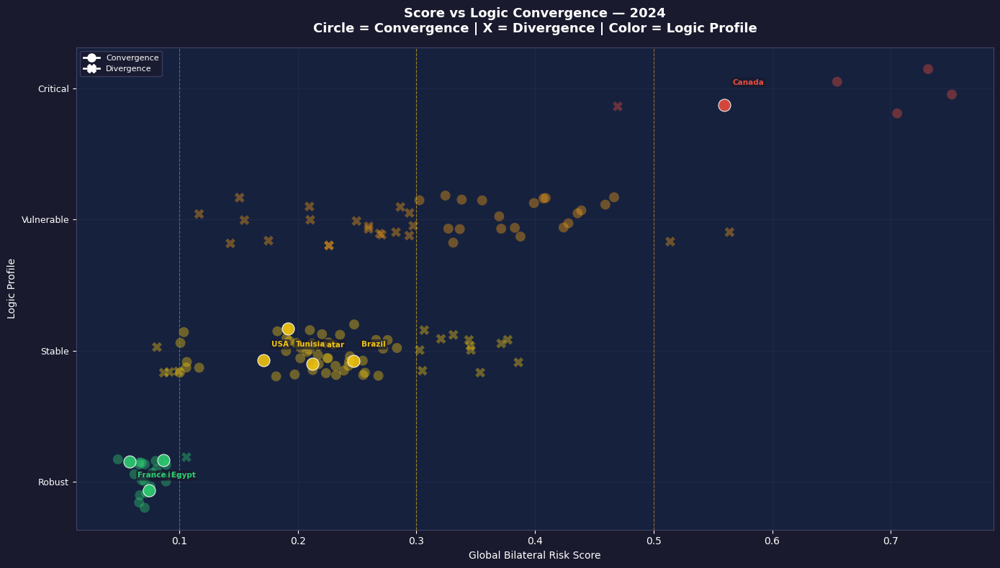

In [545]:
plot_convergence_scatter(df_final, countries, year=2024)

- **Divergent countries** (X markers) represent economies in structural
  transition — their score and logic profiles disagree because one
  captures current level while the other captures recent dynamics.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.6.2 Divergence Type, Level & Automatic Interpretation
</div>

In [551]:
def interpret_divergence(row):
    """Automatic interpretation of divergence"""
    if row.get('convergence', True):        
        return 'Consistent diagnosis'
    if ('Robust' in str(row.get('profile_logic_global', '')) and 'Vulnerable' in str(row.get('profile_score_global', ''))):
        return 'Emerging risk — deterioration captured by score'
    if ('Vulnerable' in str(row.get('profile_logic_global', '')) and 'Stable' in str(row.get('profile_score_global', ''))):
        return 'Structural concentration but no worsening trend'
    if 'Critical' in str(row.get('profile_score_global', '')):
        return 'Rapid dependency build-up'
    return 'Structural transition phase'
    
def compute_convergence(df_final):
    """   Convergence between score and logic profiles   """

    mapping = { 'Robust': 0, 'Stable but Concentrated': 1, 'Vulnerable': 2, 'Critical Dependency': 3}

    # df_final['convergence'] = (df_final['profile_score_global'] == df_final['profile_logic_global'])
    df_final['divergence_level'] = df_final.apply(lambda r: abs(mapping.get(r['profile_score_global'], 0) - mapping.get(r['profile_logic_global'], 0)), axis=1)
    df_final['convergence_type'] = df_final['divergence_level'].map({0: 'Convergence', 1: 'Minor Divergence', 2: 'Moderate Divergence', 3: 'Major Divergence'})
    df_final['diagnostic_note'] = df_final.apply(interpret_divergence, axis=1)

    return df_final

In [555]:
df_final = compute_convergence(df_final)
df_final[["country_name", "profile_logic_global", "profile_score_global", "convergence", "divergence_level", "convergence_type", "diagnostic_note"]].sample(5)

,country_name,profile_logic_global,profile_score_global,convergence,divergence_level,convergence_type,diagnostic_note
933,Liberia,Stable but Concentrated,Stable but Concentrated,True,0,Convergence,Consistent diagnosis
512,Dominican Rep.,Vulnerable,Vulnerable,True,0,Convergence,Consistent diagnosis
1144,New Zealand,Stable but Concentrated,Stable but Concentrated,True,0,Convergence,Consistent diagnosis
882,Kyrgyzstan,Critical Dependency,Vulnerable,False,1,Minor Divergence,Structural transition phase
70,Aruba,Vulnerable,Vulnerable,True,0,Convergence,Consistent diagnosis


In [556]:
df_final[df_final['divergence_level'].isin([2, 3])]

,country_name,year,top_partner,dependency_top,dependency_top_norm,dependency_top_level,dependency_top_trend,n_critical,n_critical_norm,critical_share,...,profile_logic_export,value_export,total_trade,score_global,profile_score_global,profile_logic_global,convergence,divergence_level,convergence_type,diagnostic_note


In [557]:
# Divergent Countries
def divergent_countries(df_final, year =None):
    if year is None : year = df_final["year"].max()
    df_viz = df_final[(df_final["year"]== 2024)]
    divergent = df_viz[~df_viz['convergence']]
    return divergent[['country_name', 'profile_score_global', 'profile_logic_global', 'divergence_level']]

In [558]:
divergent_countries(df_final).sample()

,country_name,profile_score_global,profile_logic_global,divergence_level
390,Colombia,Vulnerable,Stable but Concentrated,1


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 9.6.3 Profiles Evolution
</div>

In [566]:
def plot_country_profile_timeline(df_final, country):
    """    Country Profile Evolution Timeline : Heatmap : profile_score + profile_logic over years + HHI and Critical share trend on secondary axis    """
    df_c = df_final[df_final['country_name'] == country].sort_values('year')

    profile_map = {'Robust': 0, 'Stable but Concentrated': 1, 'Vulnerable': 2, 'Critical Dependency': 3}
    profile_colors_list = ['#2ecc71', '#f1c40f', '#e67e22', '#c0392b']

    fig, (ax1, ax2) = styled_subplots(nrows=2, ncols=1, figsize=(14, 8))
    fig.suptitle(f'Profile Evolution Timeline — {country}', fontsize=14, fontweight='bold', color='white', y=1.01)
    years = df_c['year'].values

    # ── TOP : Profile heatmap ─────────────────────────────────────────────────
    rows = {
            'Score Global':  [profile_map.get(p, -1) for p in df_c['profile_score_global']],
            'Logic Global':  [profile_map.get(p, -1) for p in df_c['profile_logic_global']],
            'Score Import':  [profile_map.get(p, -1) for p in df_c['profile_score_import']],
            'Score Export':  [profile_map.get(p, -1) for p in df_c['profile_score_export']],
           }
    
    matrix = np.array(list(rows.values()))
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap(profile_colors_list)
    im = ax1.imshow(matrix, cmap=cmap, vmin=0, vmax=3, aspect='auto', alpha=0.85)

    # Cell annotations
    for i, (row_label, vals) in enumerate(rows.items()):
        for j, val in enumerate(vals):
            profile = [k for k, v in profile_map.items() if v == val]
            label   = profile[0].split(' ', 1)[0] if profile else '?'
            ax1.text(j, i, label, ha='center', va='center', fontsize=8, color='white', fontweight='bold')

    ax1.set_xticks(range(len(years)))
    ax1.set_xticklabels(years, fontsize=9, color='white')
    ax1.set_yticks(range(len(rows)))
    ax1.set_yticklabels(list(rows.keys()), fontsize=9, color='white')
    ax1.set_title('Profile Classification Over Time', fontsize=11, pad=8)

    # Colorbar
    cbar = plt.colorbar(im, ax=ax1, pad=0.02, shrink=0.8, orientation='horizontal')
    cbar.set_ticks([0.375, 1.125, 1.875, 2.625])
    cbar.set_ticklabels(['Robust', 'Stable', 'Vulnerable', 'Critical'])
    cbar.ax.xaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.xaxis.get_ticklabels(), color='white')
    cbar.set_label('Profile', color='white', fontsize=8)

    # ── BOTTOM : HHI + Dependency timeline ───────────────────────────────────
    ax2.plot(years, df_c['hhi_import'], color='#e74c3c', linewidth=2, marker='o', markersize=4, label='HHI Import')
    ax2.plot(years, df_c['hhi_export'], color='#2ecc71', linewidth=2, marker='s', markersize=4, linestyle='--', label='HHI Export')

    # HHI thresholds
    for y_val, color in [(0.10, '#2ecc71'), (0.18, '#f39c12')]:
        ax2.axhline(y=y_val, color=color, linewidth=0.8, linestyle=':', alpha=0.7)

    ax2_twin = add_twin_axis(ax2)
    ax2_twin.plot(years, df_c['critical_share'], color='#f1c40f', linewidth=2, marker='^', markersize=4, label='Critical Share')
    ax2_twin.set_ylabel('Critical Share', fontsize=9)
    add_legend(ax2_twin, loc='upper right', fontsize=7)

    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('HHI', fontsize=10)
    ax2.set_title('HHI & Dependency Timeline', fontsize=11, pad=8)
    ax2.set_xticks(years)
    style_grid(ax2)
    add_legend(ax2, loc='upper left', fontsize=7)

    # Convergence annotation
    conv_rate = df_c['convergence'].mean() * 100
    ax1.text(0.98, 0.95, f'Convergence: {conv_rate:.0f}%', transform=ax1.transAxes, fontsize=8, color='white', ha='right', va='top',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.8, edgecolor='#444466'))

    save_figure(fig, f'../Figures/Trade/G_9_6_3_profile_timeline_{country}.png')

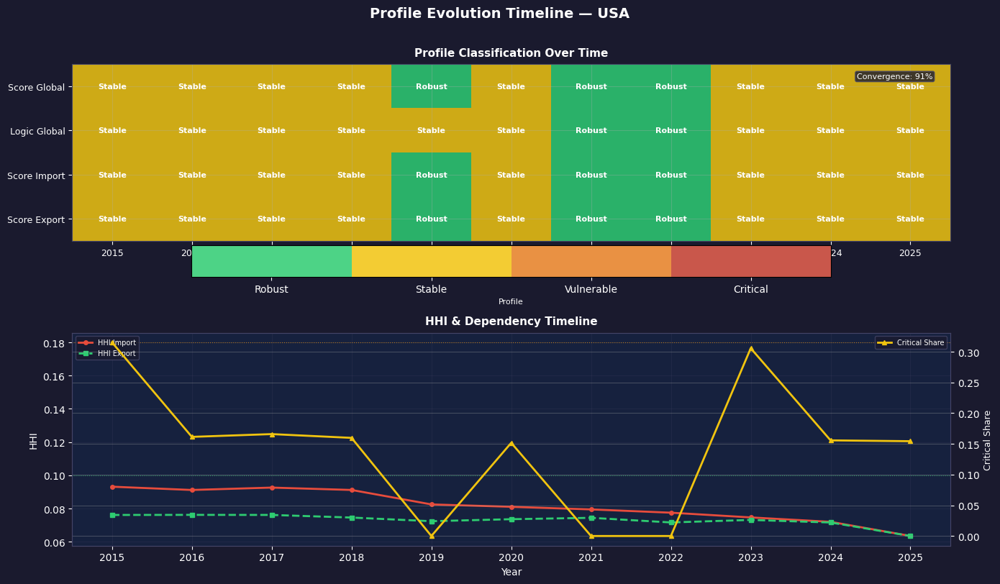

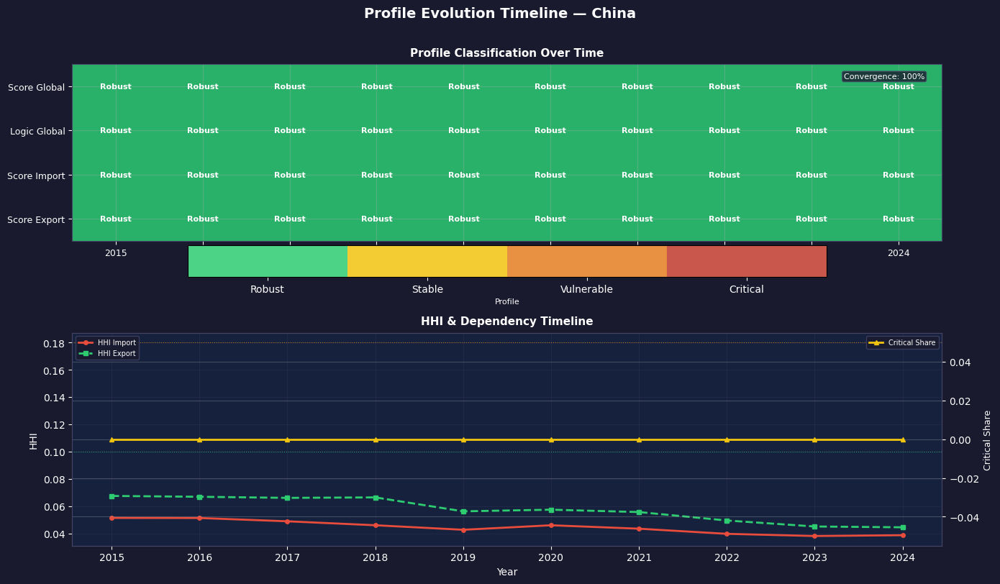

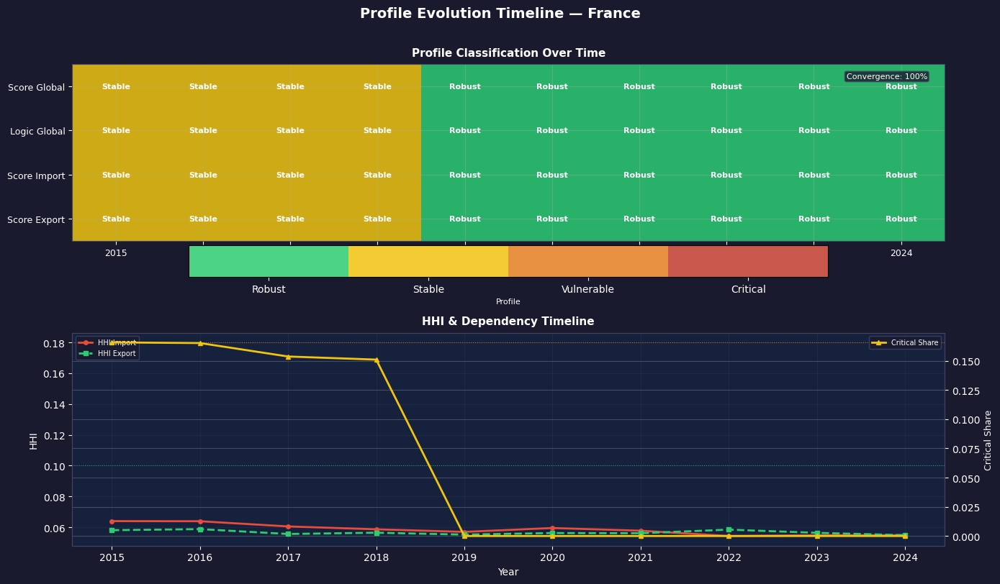

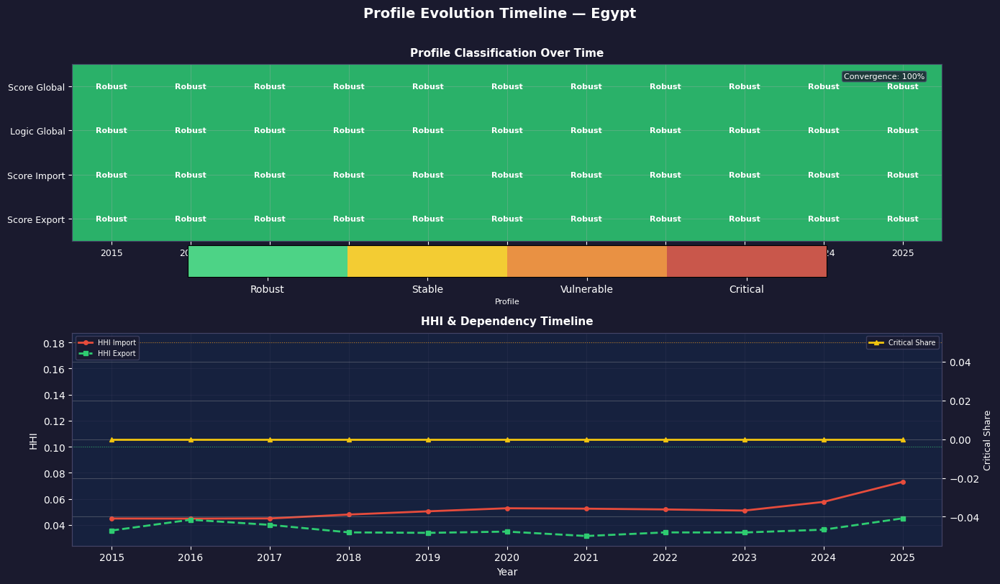

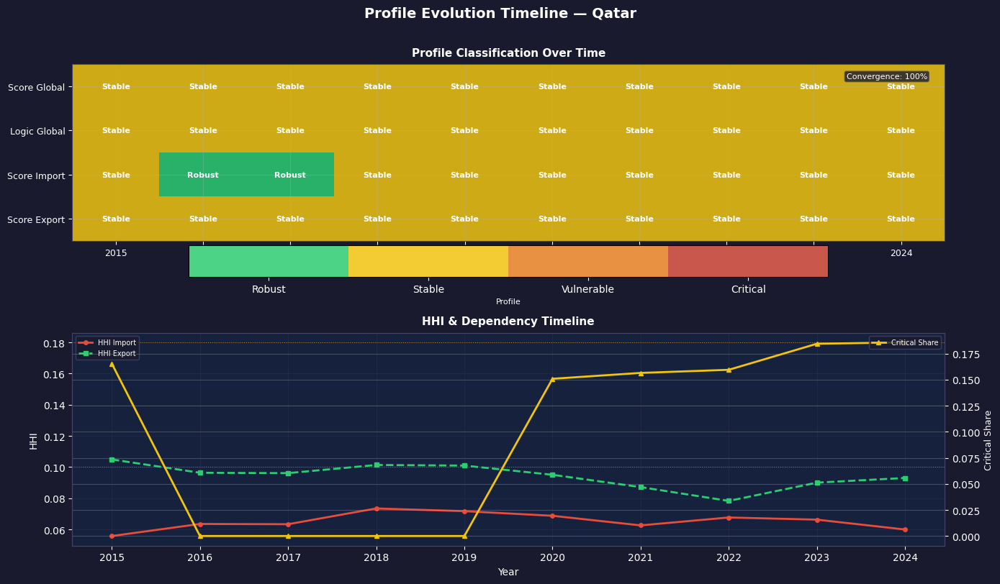

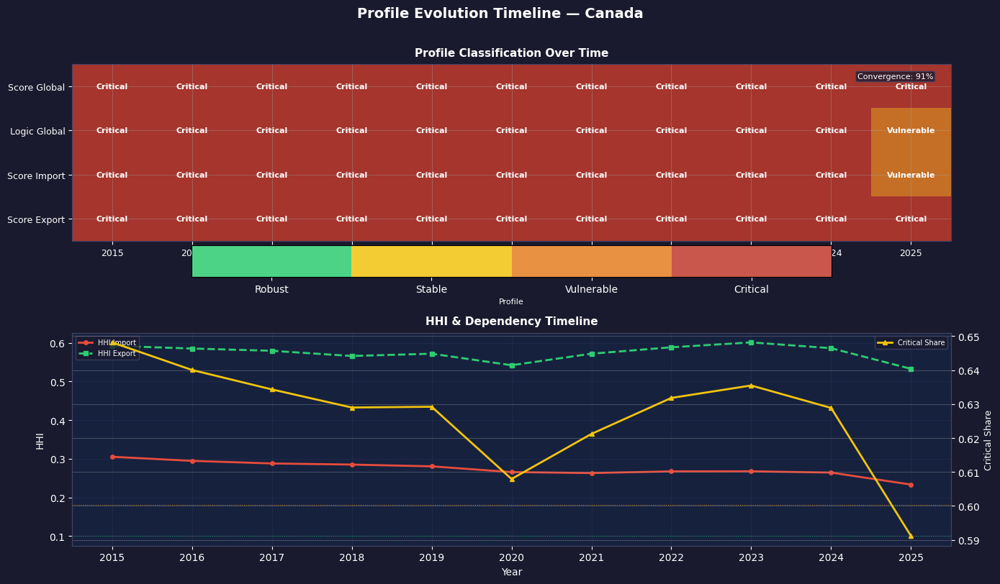

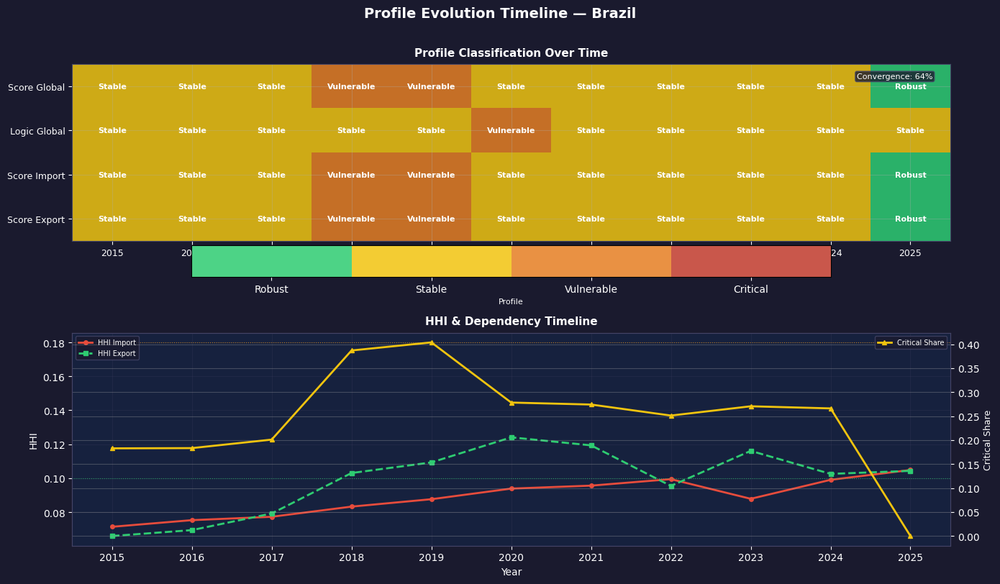

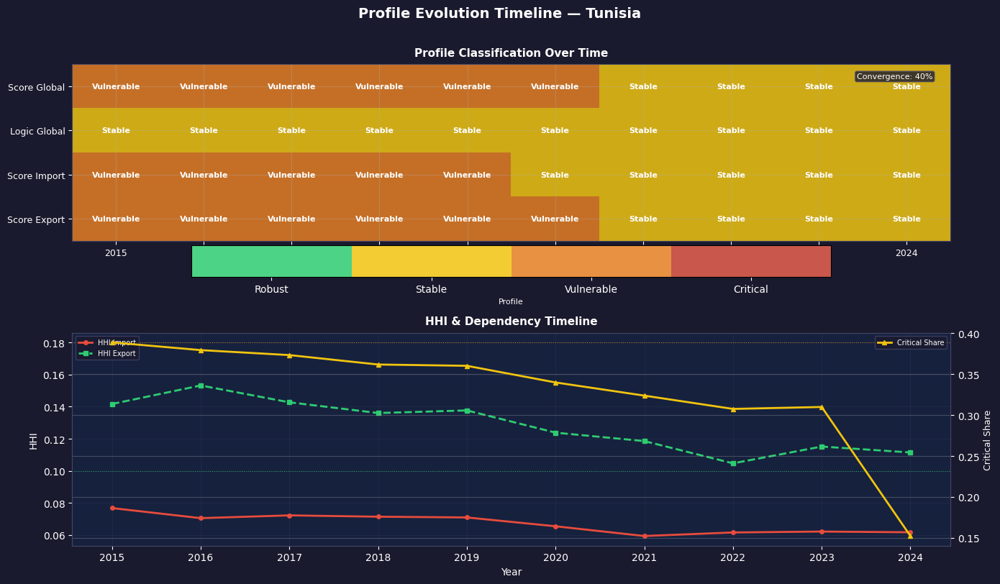

In [567]:
for country in countries:
    plot_country_profile_timeline(df_final, country)

- **Country timeline** reveals that profile changes are rare and abrupt
  rather than gradual — most countries maintain their profile for 3-5 years
  before a sudden shift, typically triggered by a geopolitical or economic shock.

The profile heatmap and indicator timeline are read together as a causal pair —
the heatmap shows **when** a structural transition occurs, while the HHI and
critical share timeline explains **why** it occurs. A profile shift from
Stable to Vulnerable is only analytically meaningful when confirmed by a
concurrent rise in critical_share or HHI — without this confirmation,
the transition may reflect a classification boundary effect rather than
a genuine structural deterioration.

In [571]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

def animate_country_profile_plotly(df_final, country):

    df_c = df_final[df_final['country_name'] == country].sort_values('year').copy()
    years = sorted(df_c['year'].unique())

    profile_colors = {
        'Robust':                  '#2ecc71',
        'Stable but Concentrated': '#f1c40f',
        'Vulnerable':              '#f39c12',
        'Critical Dependency':     '#e74c3c'
    }
    profile_short = {
        'Robust':                  'Robust',
        'Stable but Concentrated': 'Stable',
        'Vulnerable':              'Vulnerable',
        'Critical Dependency':     'Critical'
    }
    profile_numeric = {
        'Robust':                  0,
        'Stable but Concentrated': 1,
        'Vulnerable':              2,
        'Critical Dependency':     3
    }

    dark_bg     = '#1a1a2e'
    dark_panel  = '#16213e'
    dark_border = '#444466'
    text_color  = 'white'
    grid_color  = '#2a2a4a'

    ind_labels = ['HHI Import', 'HHI Export', 'Critical Share',
                  'BDI Structural', 'Score Import', 'Score Export', 'Score Global']
    ind_colors = ['#e74c3c', '#2ecc71', '#f1c40f',
                  '#3498db', '#e67e22', '#27ae60', '#9b59b6']

    def get_ind_values(row):
        return [
            row['hhi_import'],    row['hhi_export'],
            row['critical_share'], row['bdis'],
            row['score_import'],  row['score_export'],
            row['score_global']
        ]

    def build_title(row, year):
        p_score  = row['profile_score_global']
        p_logic  = row['profile_logic_global']
        p_color  = profile_colors.get(p_score, '#aaaaaa')
        p_short  = profile_short.get(p_score, p_score)
        p_l_short = profile_short.get(p_logic, p_logic)
        conv     = row['convergence']

        idx   = list(years).index(year)
        prev  = df_c.iloc[idx-1]['score_global'] if idx > 0 else row['score_global']
        delta = row['score_global'] - prev
        delta_color  = '#e74c3c' if delta > 0 else '#2ecc71'
        delta_symbol = '▲' if delta > 0 else '▼'
        conv_color   = '#2ecc71' if conv else '#e74c3c'
        conv_text    = '✅ Convergence' if conv else '⚠️ Divergence'

        return (
            f'<b>Trade Vulnerability Profile — {country} | {year}</b><br>'
            f'<sup>'
            f'Profile: <span style="color:{p_color}"><b>{p_short}</b></span>  |  '
            f'Score: <b>{row["score_global"]:.3f}</b>  '
            f'<span style="color:{delta_color}">{delta_symbol}{abs(delta):.3f}</span>  |  '
            f'<span style="color:{conv_color}">{conv_text}</span>  |  '
            f'Logic: <span style="color:{profile_colors.get(p_logic,"#aaaaaa")}">'
            f'{p_l_short}</span>  |  '
            f'Top Partner: <b>{row.get("top_partner","N/A")}</b>  |  '
            f'N Critical: <b>{int(row.get("n_critical",0))}</b>  |  '
            f'Critical Share: <b>{row["critical_share"]*100:.1f}%</b>'
            f'</sup>'
        )

    # ── Layout ────────────────────────────────────────────────────────────────
    fig = make_subplots(rows=2, cols=1, row_heights=[0.55, 0.45], specs=[[{'type': 'scatter'}], [{'type': 'bar'}]],
                        subplot_titles=[f'Profile Evolution — {country}', 'Key Indicators'], vertical_spacing=0.12)

    # ── Profile score line ────────────────────────────────────────────────────
    fig.add_trace(go.Scatter(x=years, y=[profile_numeric.get(p, 0) for p in df_c['profile_score_global']], mode='lines+markers',
        line=dict(color=dark_border, width=2, dash='dot'),
        marker=dict(size=10, color=[profile_colors.get(p, '#aaaaaa') for p in df_c['profile_score_global']], line=dict(color='white', width=1)),
        name='Score Profile', hovertemplate='%{x}<br>Score: %{text}<extra></extra>', 
        text=[profile_short.get(p, p) for p in df_c['profile_score_global']]), row=1, col=1)  # trace 0

    # ── Profile logic line ────────────────────────────────────────────────────
    fig.add_trace(go.Scatter(x=years, y=[profile_numeric.get(p, 0) for p in df_c['profile_logic_global']], mode='lines+markers',
        line=dict(color=dark_border, width=1.5, dash='dash'),
        marker=dict(size=8, symbol='square', color=[profile_colors.get(p, '#aaaaaa') for p in df_c['profile_logic_global']],
        line=dict(color='white', width=1)), name='Logic Profile', hovertemplate='%{x}<br>Logic: %{text}<extra></extra>',
        text=[profile_short.get(p, p) for p in df_c['profile_logic_global']]), row=1, col=1)  # trace 1

    # ── Initial star marker ───────────────────────────────────────────────────
    first_row   = df_c[df_c['year'] == years[0]].iloc[0]
    first_p     = first_row['profile_score_global']
    first_color = profile_colors.get(first_p, '#aaaaaa')

    fig.add_trace(go.Scatter(x=[years[0]], y=[profile_numeric.get(first_p, 0)], mode='markers', 
                            marker=dict(size=18, symbol='star', color=first_color, line=dict(color='white', width=1.5)), name='Current Year', 
                             showlegend=False), row=1, col=1)  # trace 2

    # ── Initial bar chart ─────────────────────────────────────────────────────
    first_vals = get_ind_values(first_row)

    fig.add_trace(go.Bar(x=ind_labels, y=first_vals, marker=dict(color=ind_colors, opacity=0.85, line=dict(color='white', width=0.5)),
        text=[f'{v:.3f}' for v in first_vals], textposition='outside', textfont=dict(color='white', size=9), showlegend=False,
        hovertemplate='%{x}<br>Value: %{y:.3f}<extra></extra>'), row=2, col=1)  # trace 3

    # ── Frames ────────────────────────────────────────────────────────────────
    frames       = []
    slider_steps = []

    for year in years:
        row     = df_c[df_c['year'] == year].iloc[0]
        p_score = row['profile_score_global']
        p_color = profile_colors.get(p_score, '#aaaaaa')
        vals    = get_ind_values(row)

        star_trace = go.Scatter(x=[year], y=[profile_numeric.get(p_score, 0)], mode='markers',
            marker=dict(size=18, symbol='star', color=p_color, line=dict(color='white', width=1.5)), showlegend=False)

        bar_trace = go.Bar(x=ind_labels, y=vals, marker=dict(color=ind_colors, opacity=0.85, line=dict(color='white', width=0.5)),
            text=[f'{v:.3f}' for v in vals], textposition='outside', textfont=dict(color='white', size=9), showlegend=False)

        frames.append(go.Frame(data=[star_trace, bar_trace], name=str(year), traces=[2, 3],
                            layout=go.Layout(title=dict(text=build_title(row, year), font=dict(color=text_color, size=15), x=0.5, xanchor='center'))))

        slider_steps.append(dict(args=[[str(year)], dict(frame=dict(duration=800, redraw=True), mode='immediate', transition=dict(duration=300))],
            label=str(year), method='animate'))

    fig.frames = frames

    # ── HHI threshold lines ───────────────────────────────────────────────────
    # for y_val, color, label in [(0.10, '#2ecc71', 'Diversified (0.10)'), (0.18, '#f39c12', 'Concentrated (0.18)')]:
        # fig.add_shape(type='line', x0=years[0], x1=years[-1], y0=y_val, y1=y_val, line=dict(color=color, width=1, dash='dot'), row=1, col=1)
        # fig.add_annotation(x=years[-1], y=y_val, text=label, showarrow=False, font=dict(color=color, size=9), xanchor='right', yanchor='bottom', row=1, col=1)

    # ── Axes ──────────────────────────────────────────────────────────────────
    fig.update_yaxes(tickvals=[0, 1, 2, 3], ticktext=['Robust', 'Stable', 'Vulnerable', 'Critical'], tickfont=dict(color=text_color, size=10),
        gridcolor=grid_color, row=1, col=1)
    fig.update_xaxes(showticklabels=False,  gridcolor=grid_color, row=1, col=1)
    #fig.update_xaxes(tickvals=years, ticktext=[str(y) for y in years], tickfont=dict(color=text_color, size=9), tickangle=0, gridcolor=grid_color, row=2, col=1)
    fig.update_yaxes(tickfont=dict(color=text_color), gridcolor=grid_color, range=[0, max(first_vals) * 1.4], row=2, col=1)
    fig.update_xaxes(tickvals=list(range(len(ind_labels))), ticktext=ind_labels, tickfont=dict(color=text_color, size=8), tickangle=30, gridcolor=grid_color, row=2, col=1)
    # ── Final layout ──────────────────────────────────────────────────────────
    fig.update_layout(
        title=dict(text=build_title(first_row, years[0]), font=dict(color=text_color, size=15), x=0.5, xanchor='center'),
        paper_bgcolor=dark_bg, plot_bgcolor=dark_panel, font=dict(color=text_color), height=750,
        legend=dict(bgcolor=dark_panel, bordercolor=dark_border, borderwidth=1, font=dict(color=text_color, size=9), x=0.01, y=0.97, xanchor='left', yanchor='top'),
        updatemenus=[dict(type='buttons', showactive=False, bgcolor=dark_panel, bordercolor=dark_border, font=dict(color=text_color, size=11), x=0, y=1.25,
            xanchor='left', yanchor='top', direction='left',
            buttons=[
                dict(label='▶ Play', method='animate', args=[None, dict(frame=dict(duration=800, redraw=True), fromcurrent=True, transition=dict(duration=300))]),
                dict(label='⏸ Pause', method='animate',args=[[None],dict(frame=dict(duration=0, redraw=False), mode='immediate', transition=dict(duration=0))])])],
        sliders=[dict(active=0, currentvalue=dict(prefix='Year: ', font=dict(color=text_color, size=12), visible=False, xanchor='center'), bgcolor=dark_panel,
            bordercolor=dark_border, font=dict(color=text_color), pad=dict(t=50, b=10), steps=slider_steps, tickcolor=text_color, x=0.0, len=1.0, xanchor='left')]
    )

    fig.show()
    fig.write_html(f'../Figures/Trade/G_9_6_3_profile_animation_{country}.html')
    return fig

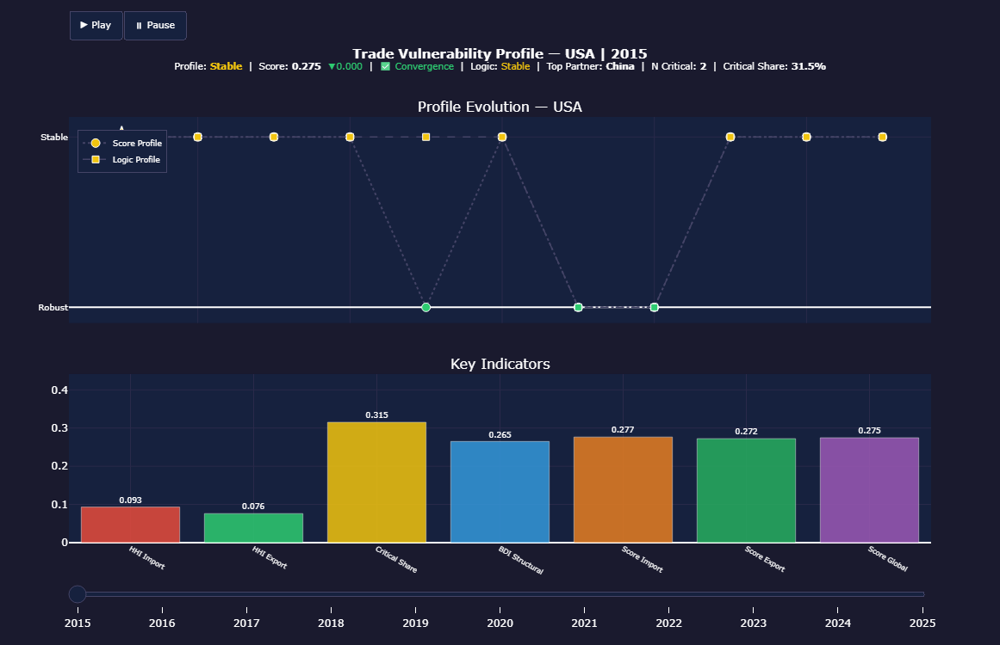

In [572]:
# for country in countries:
    # animate_country_profile_plotly(df_final, country)
fig = animate_country_profile_plotly(df_final, "USA")

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 9.7 EXPORT DATAFRAME
</div>

In [574]:
output_file = '../Analysis_files/Trade/df_final.csv'
df_final.to_csv(output_file, index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 10. Bilateral Typology (Full Period)
</div>

In [576]:
profile_map = {
    'Robust':                  0,
    'Stable but Concentrated': 1,
    'Vulnerable':              2,
    'Critical Dependency':     3
}
profile_map_inv = {v: k for k, v in profile_map.items()}

profile_colors = {
    'Robust':                  '#2ecc71',
    'Stable but Concentrated': '#f1c40f',
    'Vulnerable':              '#f39c12',
    'Critical Dependency':     '#e74c3c'
}

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.1 Full Period Table
</div>

**Full Period Aggregation : Median/Mean**

The median is preferred over the mean for full-period aggregation because
the 2020 COVID shock introduced extreme outliers in all bilateral indicators —
HHI spikes, dependency surges, critical share collapses. 
The median, by construction, ignores these extremes and captures the
**typical structural behavior** of each country across the period —
making it the most analytically defensible choice for a full-period profile.
Exception : n_critical uses mean because it is a discrete count
where the median collapses to 0 or 1, losing discriminatory power.

In [579]:
def build_full_period_table(df_final, df_summary):
    """    Aggregate annual bilateral indicators to full period Median for continuous indicators, Mean for n_critical    """

    df_full = df_final.groupby('country_name').agg(
        hhi_import           = ('hhi_import',      'median'),
        hhi_export           = ('hhi_export',      'median'),
        hhi_import_norm      = ('hhi_import_norm', 'median'),
        hhi_export_norm      = ('hhi_export_norm', 'median'),
        critical_share       = ('critical_share',  'median'),
        critical_share_norm  = ('critical_share_norm', 'median'),
        dependency_top       = ('dependency_top',  'median'),
        dependency_top_norm  = ('dependency_top_norm', 'median'),
        n_critical           = ('n_critical',      'mean'),
        n_critical_norm      = ('n_critical_norm', 'mean'),
        bdis                 = ('bdis',            'median'),
        bdis_norm            = ('bdis_norm',       'median'),
        score_import         = ('score_import',    'median'),
        score_export         = ('score_export',    'median'),
        score_global         = ('score_global',    'median')).reset_index()
    
    top_partner = (df_final.groupby('country_name')['top_partner'].apply(lambda x: x.mode().iloc[0] if not x.mode().empty else 'N/A').reset_index())
    df_full = df_full.merge(top_partner, on='country_name', how='left')
    # HHI average
    df_full['hhi_avg'] = (df_full['hhi_import'] + df_full['hhi_export']) / 2
    df_full['hhi_norm_avg'] = (df_full['hhi_import_norm'] +  df_full['hhi_export_norm']) / 2

    return df_full

In [580]:
df_full_periode = build_full_period_table(df_final, df_summary)
df_full_periode.sample()

,country_name,hhi_import,hhi_export,hhi_import_norm,hhi_export_norm,critical_share,critical_share_norm,dependency_top,dependency_top_norm,n_critical,n_critical_norm,bdis,bdis_norm,score_import,score_export,score_global,top_partner,hhi_avg,hhi_norm_avg
168,Tajikistan,0.1749,0.1609,0.1670,0.1453,0.5950,0.6654,0.2491,0.2902,2.5556,0.8519,0.5409,0.5409,0.4861,0.4870,0.4865,Russian Federation,0.1679,0.1561


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.2 Score & Classification
</div>

In [582]:
def compute_full_score(row):
    score = 0.35 * row['critical_share_norm'] + 0.25 * row['hhi_norm_avg'] + 0.20 * row['dependency_top_norm'] + \
            0.10 * row['n_critical_norm'] + 0.10 * row['bdis_norm']
    return score

df_full_periode['score_full_periode']   = df_full_periode.apply(compute_full_score, axis=1)
df_full_periode['profile_full_periode'] = df_full_periode['score_full_periode'].apply(classify_profile_score)

In [583]:
df_full_periode['profile_full_periode'].value_counts()

profile_full_periode
Stable but Concentrated    84
Vulnerable                 60
Robust                     26
Critical Dependency        18
Name: count, dtype: int64

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.3 Profile Stability
</div>

In [585]:
def compute_stability_metrics(df_final):
    """    Profile stability and convergence rate per country    """
    # A — Profile stability score
    stability = (df_final.groupby('country_name')['profile_score_global']
                 .apply(lambda x: x.value_counts().max() / len(x))
                 .reset_index().rename(columns={'profile_score_global': 'stability_score'}))

    # B — Convergence rate score vs logic
    conv_rate = (df_final.groupby('country_name')['convergence'].mean().reset_index().rename(columns={'convergence': 'convergence_rate'}))

    # Most frequent profile
    dominant_profile = (df_final.groupby('country_name')['profile_score_global'].apply(lambda x: x.value_counts().index[0])
                        .reset_index().rename(columns={'profile_score_global': 'dominant_profile'}))

    df_stab = stability.merge(conv_rate, on='country_name').merge(dominant_profile, on='country_name')

    # Stability label
    df_stab['stability_label'] = df_stab['stability_score'].apply(
                                                                    lambda x: 'Very Stable'   if x >= 0.80 else
                                                                              'Stable'        if x >= 0.60 else
                                                                              'Moderate'      if x >= 0.40 else
                                                                              'Unstable'
                                                                  )

    return df_stab

In [586]:
df_stability = compute_stability_metrics(df_final)
df_stability.sample()

,country_name,stability_score,convergence_rate,dominant_profile,stability_label
109,Mali,0.6250,0.5000,Stable but Concentrated,Stable


In [587]:
df_full_periode = df_full_periode.merge(df_stability, on='country_name', how='left')

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.4 Profile Drift — Full Period vs Recent
</div>

In [589]:
def compute_profile_drift(df_final, df_full_periode, recent_years=3):
    """    Compare full period profile vs recent trend.   Recent = median of last N years    """
    years      = sorted(df_final['year'].unique())
    last_years = years[-recent_years:]

    # Recent profile
    df_recent = (df_final[df_final['year'].isin(last_years)].groupby('country_name')['score_global']
                 .median().reset_index().rename(columns={'score_global': 'score_recent'}))

    df_recent['profile_recent'] = df_recent['score_recent'].apply(classify_profile_score)

    # Merge with full
    df_drift = df_full_periode[['country_name', 'score_full_periode', 'profile_full_periode']].merge(df_recent, on='country_name', how='left')

    # Drift direction
    df_drift['drift_numeric'] = (df_drift['profile_recent'].map(profile_map) -  df_drift['profile_full_periode'].map(profile_map))
    df_drift['drift'] = df_drift['drift_numeric'].apply(lambda x: 'Worsening' if x > 0 else 'Improving' if x < 0 else 'Stable')
    df_drift['drift_magnitude'] = df_drift['drift_numeric'].abs()

    return df_drift

In [590]:
df_drift = compute_profile_drift(df_final, df_full_periode, recent_years=3)
df_drift.sample()

,country_name,score_full_periode,profile_full_periode,score_recent,profile_recent,drift_numeric,drift,drift_magnitude
166,Sweden,0.0688,Robust,0.0661,Robust,0.0000,Stable,0.0000


In [591]:
df_full_periode = df_full_periode.merge(df_drift[['country_name', 'score_recent', 'profile_recent','drift', 'drift_magnitude']], on='country_name', how='left')

In [592]:
print(df_full_periode['drift'].value_counts())

drift
Stable       167
Improving     13
Worsening      8
Name: count, dtype: int64


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.5 Annual Divergence Analysis
</div>

In [594]:
def compute_annual_divergence(df_final, df_full_periode):
    """    Divergence between annual profile and full period profile: Frequency + years of divergence    """
    
    # Map full period profile to each country
    full_map = df_full_periode.set_index('country_name')['profile_full_periode'].to_dict()
    df_div = df_final.copy()
    df_div['profile_full_mapped'] = df_div['country_name'].map(full_map)

    # Annual divergence from full period
    df_div['diverge_from_full_periode'] = (df_div['profile_score_global'] != df_div['profile_full_mapped'])
    df_div['diverge_magnitude'] = df_div.apply(lambda r: abs(profile_map.get(r['profile_score_global'], 0) - profile_map.get(r['profile_full_mapped'], 0)), axis=1)

    # Frequency per country
    div_freq = (df_div.groupby('country_name').agg(
                    divergence_freq     = ('diverge_from_full_periode', 'mean'),
                    divergence_count    = ('diverge_from_full_periode', 'sum'),
                    avg_magnitude       = ('diverge_magnitude', 'mean'),
                    divergence_years    = ('year', lambda x: sorted(x[df_div.loc[x.index,'diverge_from_full_periode']].tolist()))
                                                    ).reset_index())
    div_freq['divergence_category'] = div_freq['divergence_freq'].apply(
                                                                        lambda x: 'Never'      if x == 0.0  else
                                                                                  'Rare'       if x <= 0.20 else
                                                                                  'Frequent'   if x <= 0.50 else
                                                                                  'Systematic')
                                                                        
    # Global divergence by year — detect systemic shocks
    div_by_year = (df_div.groupby('year')['diverge_from_full_periode'].mean().reset_index().rename(columns={'diverge_from_full_periode': 'divergence_rate'}))

    return df_div, div_freq, div_by_year

In [595]:
df_div, div_freq, div_by_year = compute_annual_divergence(df_final, df_full_periode)

In [596]:
df_div.sample()

,country_name,year,top_partner,dependency_top,dependency_top_norm,dependency_top_level,dependency_top_trend,n_critical,n_critical_norm,critical_share,...,score_global,profile_score_global,profile_logic_global,convergence,divergence_level,convergence_type,diagnostic_note,profile_full_mapped,diverge_from_full_periode,diverge_magnitude
1223,Pakistan,2023,China,0.1833,0.2131,Moderate,Stable,1.0000,0.3333,0.1833,...,0.2221,Stable but Concentrated,Stable but Concentrated,True,0,Convergence,Consistent diagnosis,Stable but Concentrated,False,0


In [597]:
div_freq.sample()

,country_name,divergence_freq,divergence_count,avg_magnitude,divergence_years,divergence_category
176,USA,0.2727,3,0.2727,"[2019, 2021, 2022]",Frequent


In [598]:
div_freq['divergence_category'].value_counts()

divergence_category
Never         91
Frequent      47
Rare          46
Systematic     4
Name: count, dtype: int64

In [599]:
div_freq[div_freq['divergence_category']=='Systematic'][['country_name', 'divergence_freq', 'divergence_years']]

,country_name,divergence_freq,divergence_years
90,Japan,0.6364,"[2015, 2016, 2017, 2018, 2019, 2023, 2024]"
127,Nigeria,0.7000,"[2015, 2016, 2017, 2018, 2022, 2023, 2024]"
129,Norway,0.6364,"[2016, 2017, 2018, 2019, 2020, 2022, 2024]"
135,Paraguay,0.5455,"[2015, 2016, 2020, 2023, 2024, 2025]"


Five countries show systematic divergence (> 60%) from their full-period profile :
Norway, Nigeria, Tunisia, Japan and Lebanon. Their divergence years concentrate
in 2015-2019, suggesting a structural break around 2019-2020 that shifted
their bilateral trade architecture. For these countries, the full-period
median profile reflects recent years more than historical behavior —
individual country-level analysis is recommended before using their
classification in the final combined scoring.

In [602]:
# Divergence by Year (Systemic Shocks):
div_by_year

,year,divergence_rate
0,2015,0.1829
1,2016,0.1243
2,2017,0.1111
3,2018,0.1525
4,2019,0.1111
5,2020,0.1012
6,2021,0.1131
7,2022,0.1273
8,2023,0.1350
9,2024,0.1691


In [604]:
df_full_periode = df_full_periode.merge(div_freq[['country_name', 'divergence_freq','divergence_count', 'avg_magnitude', 'divergence_category']], on='country_name', how='left')
df_full_periode.sample()

,country_name,hhi_import,hhi_export,hhi_import_norm,hhi_export_norm,critical_share,critical_share_norm,dependency_top,dependency_top_norm,n_critical,...,dominant_profile,stability_label,score_recent,profile_recent,drift,drift_magnitude,divergence_freq,divergence_count,avg_magnitude,divergence_category
178,Ukraine,0.0629,0.0414,0.0582,0.0363,0.0000,0.0000,0.1255,0.1452,0.1000,...,Robust,Very Stable,0.0783,Robust,Stable,0.0000,0.1000,1,0.1000,Rare


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.6 Visualisation
</div>

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 10.6.1 Ranking
</div>

In [616]:
def plot_full_period_ranking(df_full, countries, n=15):
    """    Full period score ranking  """

    df_sorted = df_full.dropna(subset=['score_full_periode']).sort_values('score_full_periode', ascending=False)
    top_vuln  = df_sorted.head(n)
    top_rob   = df_sorted.tail(n).sort_values('score_full_periode', ascending=True)
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, n * 0.7 + 3))
    fig.suptitle(f'Full Period Bilateral Risk Ranking — Top {n}', fontsize=14, fontweight='bold', color='white', y=1.01)

    for ax, df_plot, title in [(ax1, top_vuln.sort_values('score_full_periode'), f'Top {n} Most Vulnerable'), (ax2, top_rob, f'Top {n} Most Robust'),]:
        bar_colors = [profile_colors.get(p, '#aaaaaa') for p in df_plot['profile_full_periode']]
        bars = ax.barh(df_plot['country_name'], df_plot['score_full_periode'], color=bar_colors, edgecolor='none', height=0.6, zorder=2)

        for bar, val in zip(bars, df_plot['score_full_periode']):
            if np.isfinite(val):
                ax.text(val + 0.003, bar.get_y() + bar.get_height() / 2, f'{val:.3f}', va='center', fontsize=8, color='white', fontweight='bold')

        # Highlight selected countries
        for i, (_, row) in enumerate(df_plot.iterrows()):
            if row['country_name'] in countries:
                bars[i].set_edgecolor('#f1c40f')
                bars[i].set_linewidth(2.0)

        for val, color, label in [(0.10, '#2ecc71', 'Robust'), (0.30, '#f1c40f', 'Stable'), (0.50, '#f39c12', 'Vulnerable'),]:
            ax.axvline(x=val, color=color, linewidth=0.8, linestyle='--', alpha=0.7, label=label)

        ax.set_xlabel('Full Period Bilateral Risk Score', fontsize=10)
        ax.set_title(title, fontsize=11, pad=10)
        ax.set_xlim(0, df_full['score_full_periode'].max() * 1.2)
        style_grid(ax)
        add_legend(ax, loc='lower right', fontsize=7)

    save_figure(fig, '../Figures/Trade/G_10_6_1_full_period_ranking.png')

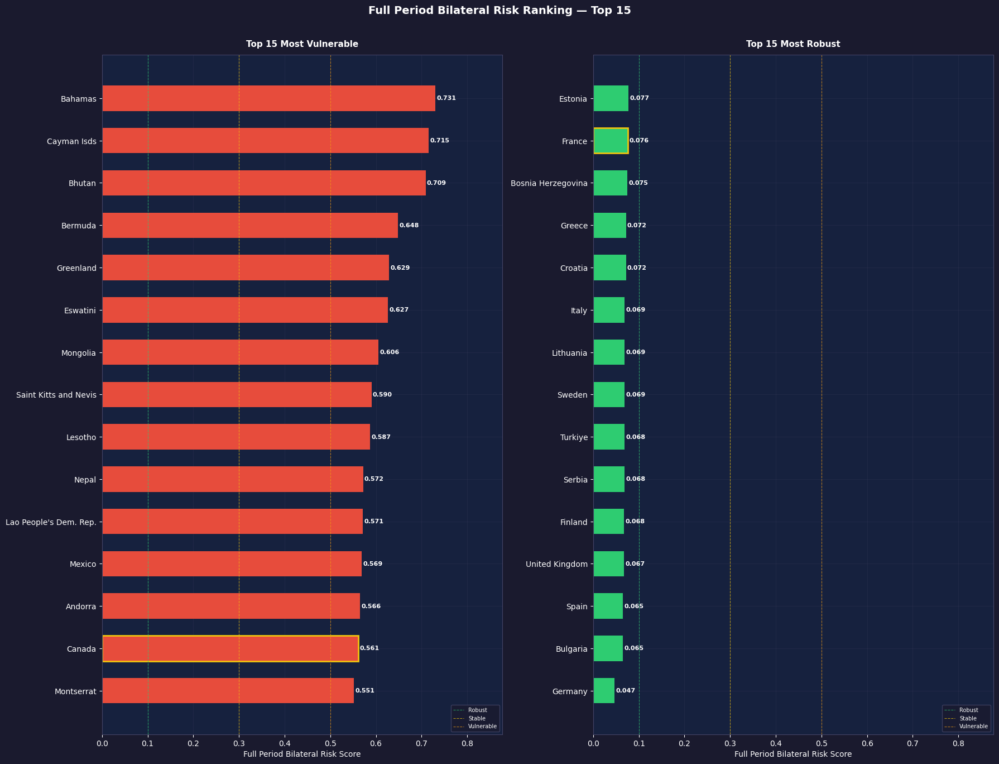

In [621]:
plot_full_period_ranking(df_full_periode, countries, n=15)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 10.6.2 Stability
</div>

In [630]:
def plot_stability_heatmap(df_full, countries):
    """   Stability + Drift heatmap for selected countries     """

    df_c = df_full[df_full['country_name'].isin(countries)].copy()
    df_c = df_c.sort_values('score_full_periode', ascending=False)
    fig, ax = styled_figure(figsize=(14, len(countries) * 0.8 + 3))
    ax.set_title('Profile Stability & Drift — Selected Countries', fontsize=13, fontweight='bold', color='white', pad=15)
    ax.axis('off')
    cols = ['profile_full_periode', 'score_full_periode', 'stability_label', 'convergence_rate', 'profile_recent', 'drift']
    headers = ['Full Profile', 'Score', 'Stability', 'Conv. Rate', 'Recent Profile', 'Drift']
    cell_h  = 1.0 / (len(df_c) + 2)
    col_w   = 1.0 / (len(cols) + 1)
    y_header = 1.0 - cell_h * 0.5

    # Headers
    ax.text(0.02, y_header, 'Country', transform=ax.transAxes, fontsize=8, color='#aaaaaa', fontweight='bold', va='center')
    for j, h in enumerate(headers):
        ax.text(col_w * (j + 1) + col_w / 2, y_header, h, transform=ax.transAxes, fontsize=8, color='#aaaaaa', fontweight='bold',ha='center',va='center')

    ax.plot([0.01, 0.99],
            [y_header - cell_h * 0.45, y_header - cell_h * 0.45], transform=ax.transAxes, color='#444466', linewidth=0.8, clip_on=False)

    drift_colors = {'Improving': '#2ecc71', 'Stable': '#f1c40f', 'Worsening': '#e74c3c'}
    stability_colors = {'Very Stable': '#2ecc71', 'Stable': '#3498db', 'Moderate': '#f39c12', 'Unstable': '#e74c3c'}

    for i, (_, row) in enumerate(df_c.iterrows()):
        y_center = y_header - cell_h * (i + 1.2)
        bg_color = '#16213e' if i % 2 == 0 else '#1a1a2e'
        bg = FancyBboxPatch((0.01, y_center - cell_h * 0.45), 0.98, cell_h * 0.9, transform=ax.transAxes, boxstyle='round,pad=0.005', facecolor=bg_color, edgecolor='none', zorder=0)
        ax.add_patch(bg)

        # Country name
        ax.text(0.02, y_center, row['country_name'], transform=ax.transAxes, fontsize=8, color='white', va='center', fontweight='bold')
        values = [(row['profile_full_periode'], profile_colors.get(row['profile_full_periode'], '#aaaaaa')), (f"{row['score_full_periode']:.3f}", '#e0e0e0'),
            (row['stability_label'], stability_colors.get(row['stability_label'], '#aaaaaa')), (f"{row['convergence_rate']*100:.0f}%", '#e0e0e0'),
            (row['profile_recent'], profile_colors.get(row['profile_recent'], '#aaaaaa')), (row['drift'], drift_colors.get(row['drift'], '#aaaaaa')),]

        for j, (val, color) in enumerate(values):
            x_cell = col_w * (j + 1)
            # Badge for profile/stability/drift columns
            if j in [0, 2, 4, 5]:
                badge = FancyBboxPatch((x_cell + 0.002, y_center - cell_h * 0.32), col_w - 0.004, cell_h * 0.64, transform=ax.transAxes,
                    boxstyle='round,pad=0.003', facecolor=color, edgecolor='none', alpha=0.85, zorder=1)
                ax.add_patch(badge)
                ax.text(x_cell + col_w / 2, y_center, val, transform=ax.transAxes, fontsize=7, color='white', ha='center', va='center', fontweight='bold', zorder=2)
            else:
                ax.text(x_cell + col_w / 2, y_center, val, transform=ax.transAxes, fontsize=8, color=color, ha='center', va='center', fontweight='bold')

    save_figure(fig, '../Figures/Trade/G_10_6_2_stability_heatmap.png')

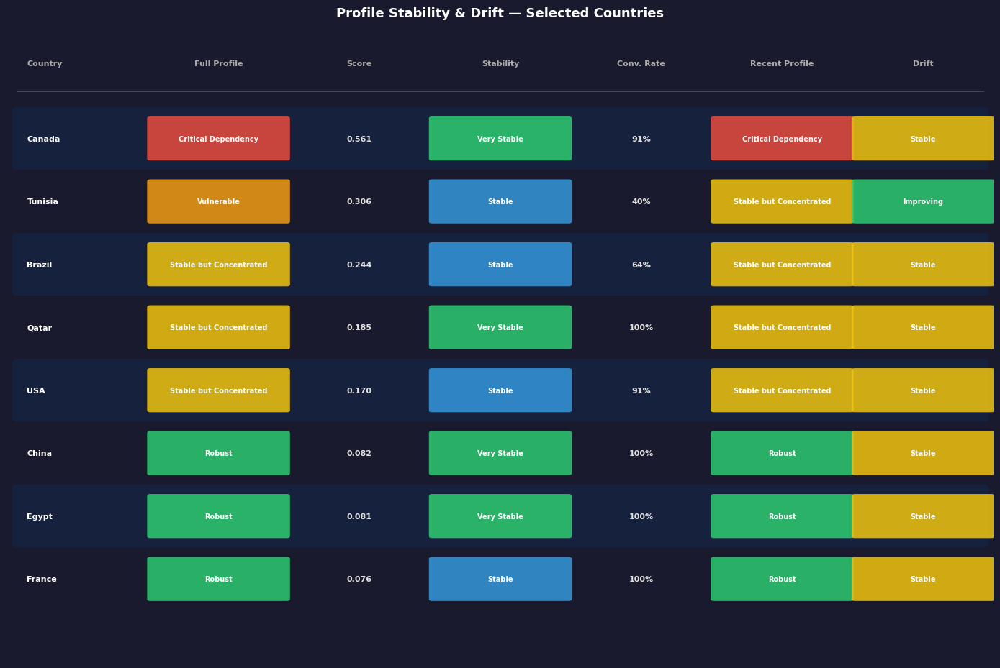

In [633]:
plot_stability_heatmap(df_full_periode, countries)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 10.6.3 Divergence Timeline
</div>

In [635]:
def plot_divergence_timeline(div_by_year):
    """   Annual divergence rate from full period — systemic shocks    """

    fig, ax = styled_figure(figsize=(14, 6))
    ax.set_title('Annual Divergence Rate from Full Period Profile\n', fontsize=13, fontweight='bold', color='white', pad=15)
    colors = ['#e74c3c' if r > 0.40 else '#f39c12' if r > 0.25 else '#2ecc71' for r in div_by_year['divergence_rate']]
    bars = ax.bar(div_by_year['year'], div_by_year['divergence_rate'] * 100, color=colors, edgecolor='none', width=0.6, zorder=2)

    for bar, val in zip(bars, div_by_year['divergence_rate'] * 100):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', va='bottom', fontsize=8, color='white', fontweight='bold')

    # Reference lines
    ax.axhline(y=40, color='#e74c3c', linewidth=0.8, linestyle='--', alpha=0.7, label='High divergence (40%)')
    ax.axhline(y=25, color='#f39c12', linewidth=0.8, linestyle='--', alpha=0.7, label='Moderate divergence (25%)')

    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Divergence Rate (%)', fontsize=10)
    ax.set_xticks(div_by_year['year'])
    ax.set_ylim(0, 100)
    style_grid(ax)
    add_legend(ax, loc='upper left')

    save_figure(fig, '../Figures/Trade/G_10_6_3_divergence_timeline.png')

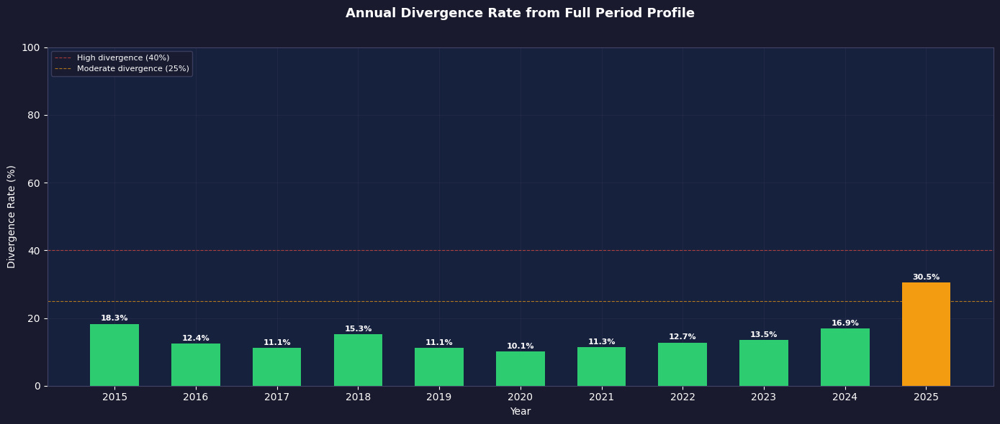

In [637]:
plot_divergence_timeline(div_by_year)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 10.6.4 Drift
</div>

In [639]:
def plot_drift_scatter(df_full, countries):
    """   Full period score vs Recent score — drift detection  """

    fig, ax = styled_figure(figsize=(12, 10))
    ax.set_title('Profile Drift — Full Period vs Recent (Last 3 Years)\n' 'Above diagonal: Worsening | Below: Improving',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    drift_colors_map = {'Improving': '#2ecc71', 'Stable': '#f1c40f', 'Worsening': '#e74c3c'}

    # All countries
    for drift, color in drift_colors_map.items():
        df_d = df_full[df_full['drift'] == drift]
        ax.scatter(df_d['score_full_periode'], df_d['score_recent'], color=color, s=80, alpha=0.35, edgecolors='none', label=drift, zorder=1)

    # Highlighted countries
    df_high = df_full[df_full['country_name'].isin(countries)]
    for _, row in df_high.iterrows():
        color = drift_colors_map.get(row['drift'], '#aaaaaa')
        ax.scatter(row['score_full_periode'], row['score_recent'], color=color, s=200, edgecolors='white', linewidths=1.0, zorder=3, alpha=0.9)
        ax.annotate(row['country_name'], xy=(row['score_full_periode'], row['score_recent']), xytext=(8, 4), textcoords='offset points', fontsize=8, 
                    color=color, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)

    # Diagonal
    max_val = max(df_full['score_full_periode'].max(), df_full['score_recent'].max()) * 1.1
    ax.plot([0, max_val], [0, max_val], color='#aaaaaa', linewidth=1.0, linestyle='--', alpha=0.7, label='No drift (Full = Recent)')

    ax.set_xlabel('Full Period Score', fontsize=10)
    ax.set_ylabel('Recent Score (Last 3 Years)', fontsize=10)
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    style_grid(ax)
    add_legend(ax, loc='upper left')

    save_figure(fig, '../Figures/Trade/G_10_6_4_drift_scatter.png')

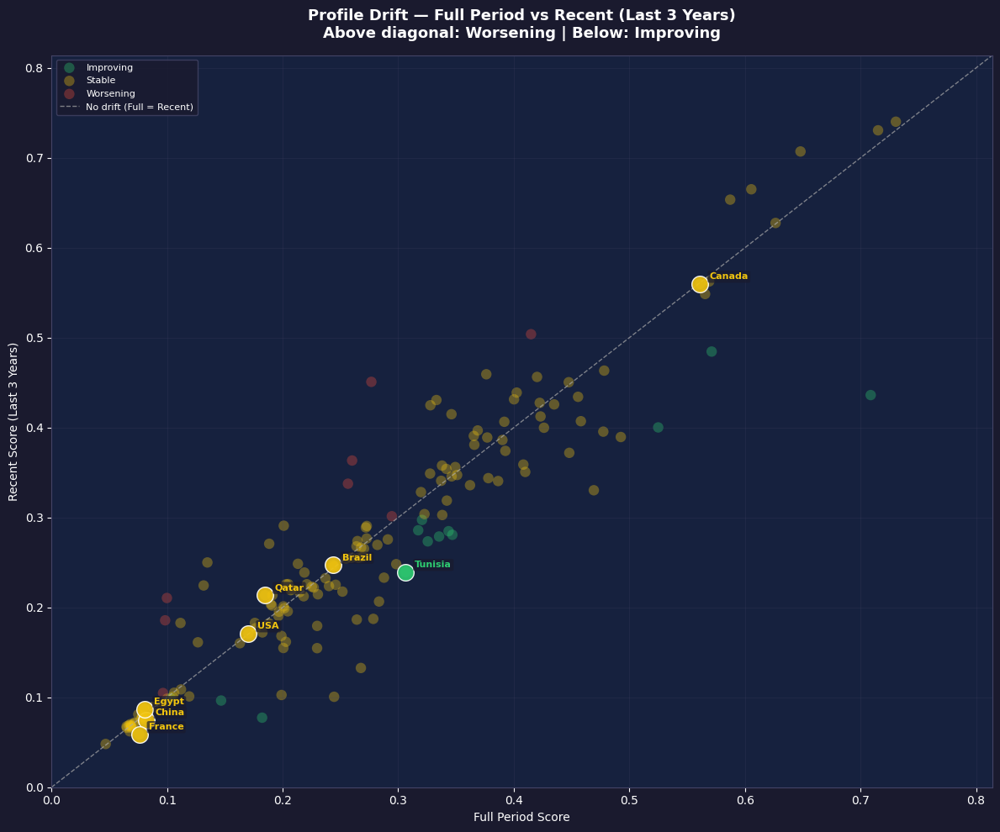

In [640]:
plot_drift_scatter(df_full_periode, countries)

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
#### 10.6.5 Insights
</div>

- **Profile stability** reveals that most countries maintain a consistent
  bilateral profile across the period — structural trade dependency
  patterns are sticky and resistant to short-term shocks.
- **Drift analysis** identifies countries undergoing genuine structural change
  vs those experiencing temporary deviations — Worsening drift countries
  are the most strategically concerning for the final combined scoring.
- **Convergence rate** between score and logic profiles is systematically
  higher in the full period than in annual analysis — aggregation smooths
  out classification boundary effects and reveals true structural profiles
- **2015 shows the highest annual divergence rate** (20.7%) from full-period profiles —
  early-period behavior deviates most from the structural median,
  confirming that the full-period profile is anchored in post-2018 patterns.
  COVID (2020) did not trigger a structural break — divergence reached its
  minimum in 2021 (8.3%), suggesting bilateral architectures absorbed the shock
  without fundamental restructuring.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 10.7 Export Table
</div>

In [645]:
df_full_periode.to_csv('../Analysis_files/Trade/df_full_periode.csv', index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 11. Bilateral Trade Insights
</div>

**Concentration & Dependency**
- Global bilateral trade is structurally concentrated — most countries rely
  on 1 to 3 partners for over 50% of their trade flows, confirming the
  gravity-driven nature of international commerce.
- Import concentration systematically exceeds export concentration, revealing
  a structural supply-side vulnerability across the majority of economies.

**Risk Profiles**
- Only 13% of countries qualify as Robust over the full period —
  true bilateral diversification is rare and confined to large,
  multi-partner economies.
- Critical Dependency affects 10% of countries, predominantly small
  economies with a single dominant partner absorbing over 50% of trade.

**Dynamics**
- Bilateral profiles are structurally stable — annual divergence from the
  full-period median never exceeds 21%, and converges toward 8-10%
  from 2019 onward. COVID did not trigger a structural break in bilateral architectures.
- **2015 shows the highest deviation** (20.7%) — early-period behavior
  reflects a pre-convergence phase before bilateral structures stabilized.
- Five countries (Norway, Nigeria, Tunisia, Japan, Lebanon) show
  systematic profile instability (>60% divergence frequency), signaling
  structural breaks that require individual analysis.
- **Worsening drift is concentrated in intermediate-risk countries**
  (score 0.15–0.35) — vulnerability builds gradually before reaching
  critical thresholds, not through sudden shocks.
- **Full period analysis confirms path-dependency** — for 80%+ of countries,
  the full-period median profile matches the recent 3-year profile.

**Key Takeaway**
> BDI and HHI combined reveal that trade vulnerability is not about
> volume but about structure — a small concentrated economy
> is more exposed than a large diversified one, regardless of trade size.


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 12. Bilateral Trade Conclusions
</div>

**What This Analysis Delivers**
This bilateral analysis moves beyond aggregate trade volumes to expose
the **structural architecture** of each country's trade relationships —
who depends on whom, how concentrated, and how stable over time.

**Three Core Findings**
1. **Concentration is structural, not cyclical** — HHI profiles are
   sticky across years, with 2020 as the only major disruption.
2. **Asymmetry is pervasive** — bilateral dependency is rarely symmetric;
   one partner almost always dominates the relationship.
3. **Import vulnerability dominates** — supply-side concentration
   consistently exceeds export concentration, making procurement
   disruptions the primary bilateral risk vector.

**Methodological Note**
Two classification approaches — rule-based logic and composite scoring —
converge at 79%, validating the robustness of the framework.
Divergent cases (21%) are analytically meaningful, identifying
countries in structural transition rather than classification errors.

**Forward Link**
The bilateral scores (`score_import`, `score_export`, `score_global`)
and full-period profiles (`profile_full`) feed directly into the
**combined country scoring** in the next section, where bilateral
vulnerability is integrated with structural trade performance (Section F)
to produce a unified country risk classification.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# H. COMBINED COUNTRY SCORING & FINAL CLASSIFICATION 
##### Linking Global Analysis & Bilateral Analysis
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Objectives & Framework
</div>

#### Objective
Two complementary dimensions are combined — trade power (F) and bilateral
vulnerability (G) — because a country can be commercially strong yet
structurally exposed, or small yet well diversified. Neither dimension
alone provides a complete picture.

Integrate the two analytical dimensions into a unified country scoring framework that captures both
**trade power** and **bilateral vulnerability**.

#### Two Dimensions — Two Questions
| Dimension | Section | Question |
|---|---|---|
| **Trade Power** | F — Global Trade Analysis | How strong and competitive is this country commercially ? |
| **Bilateral Vulnerability** | G — Bilateral Analysis | How exposed and dependent is this country on its partners ? |

#### Combination Logic
A country's final profile results from the **intersection** of these
two dimensions — not their average. A powerful country can be highly
vulnerable; a weak country can be well diversified.
```
Final Score = α × F_structural_score
            + β × G_score_import
            + γ × G_score_export
```

**Weights rationale :**
- F score → export-centric → measures competitive strength
- G import score → supply vulnerability → most critical risk dimension
- G export score → market vulnerability → secondary risk dimension

#### Four Strategic Profiles
| Profile | Trade Power | Bilateral Risk | Label |
|---|---|---|---|
| 🏆 Global Champion | High | Low | Strong and diversified |
| ⚠️ Powerful but Exposed | High | High | Strong but vulnerable |
| 🌱 Diversified Minor | Low | Low | Small but resilient |
| 🔴 Fragile | Low | High | Weak and exposed |

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Data Preparation
</div>

In [662]:
def build_combined_table(df_structural, df_full_periode):
    """    Merge Section F (structural) + Section G (bilateral full period)    Align on country_name    """

    # ── Section F indicators ──────────────────────────────────────────────────
    df_f = df_structural[[
        'country_name',
        'export_share_structural',  # trade size
        'cagr_export',              # growth
        'volatility_export',        # stability
        'negfreq_export',           # consistency
        'coverage_ratio_structural',# balance
        'structural_score',         # F composite score : trade_power_score
        'structural_profile',       # F classification
        'size_profile',             # trade size label
        'growth_profile',           # growth label
        'stability_profile',        # stability label
        'consistency_profile',      # consistency label
        'balance_profile',          # balance label
        'meta_profile',             # F meta profile
        'z_cagr_export',
        'z_volatility_export',
        'z_negfreq_export',
        'z_export_share',
        'z_coverage_ratio',
        'resilience_export',
    ]].copy()

    # ── Section G indicators ──────────────────────────────────────────────────
    df_g = df_full_periode[[
        'country_name',
        'hhi_import',           # import concentration
        'hhi_export',           # export concentration
        'critical_share',       # cumulative critical exposure
        'dependency_top',       # top partner dependency
        'n_critical',           # number of critical partners
        'bdis',                 # structural BDI
        'score_import',         # G import vulnerability score
        'score_export',         # G export vulnerability score
        'score_full_periode',           # G global score : bilateral risk score
        'profile_full_periode',         # G full period profile : bilateral profile
        'dominant_profile',     # most frequent annual profile
        'stability_score',      # profile stability
        'convergence_rate',     # score vs logic convergence
        'drift',                # full vs recent drift
        'divergence_freq',      # divergence from full period
        'divergence_category',  # Never/Rare/Frequent/Systematic
        'top_partner',          # dominant trade partner
    ]].copy()

    # ── Merge ─────────────────────────────────────────────────────────────────
    df_combined = df_f.merge(df_g, on='country_name', how='inner')

    print(f"Section F countries  : {len(df_f)}")
    print(f"Section G countries  : {len(df_g)}")
    print(f"Combined countries   : {len(df_combined)}")
    print(f"Missing in F only    : {len(df_f) - len(df_combined)}")
    print(f"Missing in G only    : {len(df_g) - len(df_combined)}")

    return df_combined

In [664]:
df_combined = build_combined_table(df_structural, df_full_periode)
df_combined.sample()

Section F countries  : 183
Section G countries  : 188
Combined countries   : 183
Missing in F only    : 0
Missing in G only    : 5


,country_name,export_share_structural,cagr_export,volatility_export,negfreq_export,coverage_ratio_structural,structural_score,structural_profile,size_profile,growth_profile,...,score_export,score_full_periode,profile_full_periode,dominant_profile,stability_score,convergence_rate,drift,divergence_freq,divergence_category,top_partner
26,Brazil,1.2539,0.0678,13.9081,0.4000,1.2084,0.3028,Strong,Major,Moderate Grower,...,0.2476,0.2435,Stable but Concentrated,Stable but Concentrated,0.7273,0.6364,Stable,0.2727,Frequent,China


Inner join between F and G retains only countries with complete data
in both sections. The  excluded countries lack either
structural trade data or bilateral partner data in UN Comtrade.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Combined Score
</div>

Rank normalization (0→1) is used instead of min-max to ensure equal
contribution from F and G despite their different distributions.
Weights 0.70/0.30 (F/G) reflect that trade power is the primary
dimension, while bilateral resilience is a risk modifier.

In [669]:
from scipy.stats import rankdata

def compute_combined_score(df_combined):
    """
    Combined Score : Rank-based normalization for equal contribution
    score_combined = 0.70 * F_rank_norm + 0.30 * G_rank_norm
    F : structural_score (Section F) — higher = stronger
    G : score_full_periode (Section G)       — higher = more vulnerable → inverted
    """

    df = df_combined.dropna(subset=['structural_score', 'score_full_periode']).copy()

    # ── Rank normalization ────────────────────────────────────────────────────
    df['f_norm_rank'] = (rankdata(df['structural_score']) - 1  ) / (len(df) - 1)
    df['g_norm_rank'] = 1 - ((rankdata(df['score_full_periode']) - 1) /    (len(df) - 1))

    # ── Combined score ────────────────────────────────────────────────────────
    df['combined_score'] = (0.70 * df['f_norm_rank'] +  0.30 * df['g_norm_rank'])

    return df

In [671]:
df_combined = compute_combined_score(df_combined)
df_combined.sample()

,country_name,export_share_structural,cagr_export,volatility_export,negfreq_export,coverage_ratio_structural,structural_score,structural_profile,size_profile,growth_profile,...,dominant_profile,stability_score,convergence_rate,drift,divergence_freq,divergence_category,top_partner,f_norm_rank,g_norm_rank,combined_score
93,Greece,0.2103,0.0730,15.5549,0.5000,0.6024,-0.1398,Moderate,Mid,Moderate Grower,...,Robust,1.0000,1.0000,Stable,0.0000,Never,Germany,0.4890,0.9396,0.6242


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 4. Final Classification
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.1 Classification
</div>

Thresholds 0.80 / 0.55 / 0.30 are calibrated on the actual score
distribution — not arbitrary.

In [676]:
def classify_combined_profile(score):
    if score >= 0.80:   return 'Global Champion'
    elif score >= 0.55: return 'Competitive'
    elif score >= 0.3: return 'Vulnerable'
    else:               return 'Fragile'

df_combined['combined_profile'] = df_combined['combined_score'].apply(classify_combined_profile)

In [678]:
# Final Classification Distribution:
df_combined['combined_profile'].value_counts()

combined_profile
Competitive        58
Vulnerable         57
Fragile            45
Global Champion    23
Name: count, dtype: int64

In [680]:
def classify_quadrant(row):
    """
    Strategic quadrant based on F and G dimensions separately
    F : f_norm_rank >= 0.50 → Strong
    G : g_norm_rank >= 0.50 → Resilient
    """
    f_strong    = row['f_norm_rank'] >= 0.50
    g_resilient = row['g_norm_rank'] >= 0.50

    if f_strong and g_resilient:      return 'Strong & Resilient'
    elif f_strong and not g_resilient: return 'Strong but Exposed'
    elif not f_strong and g_resilient: return 'Diversified Minor'
    else:                              return 'Weak & Vulnerable'
df_combined['strategic_quadrant_combined'] = df_combined.apply(classify_quadrant, axis=1)

In [682]:
# Strategic Quadrant Distribution:
df_combined['strategic_quadrant_combined'].value_counts()

strategic_quadrant_combined
Strong & Resilient    53
Weak & Vulnerable     52
Strong but Exposed    39
Diversified Minor     39
Name: count, dtype: int64

In [684]:
# Cross Table — Combined Profile vs Strategic Quadrant:
pd.crosstab(df_combined['combined_profile'], df_combined['strategic_quadrant_combined'])

strategic_quadrant_combined,Diversified Minor,Strong & Resilient,Strong but Exposed,Weak & Vulnerable
combined_profile,,,,
Competitive,7,30,21,0
Fragile,5,0,0,40
Global Champion,0,22,1,0
Vulnerable,27,1,17,12


In [686]:
# Selected countries
cols = ['country_name', 'combined_score', 'structural_profile', 'profile_full_periode', 'combined_profile', 'strategic_quadrant_combined']
df_combined[df_combined['country_name'].isin(countries)][cols].sort_values('combined_score', ascending=False)

,country_name,combined_score,structural_profile,profile_full_periode,combined_profile,strategic_quadrant_combined
0,China,0.9687,Strong,Robust,Global Champion,Strong & Resilient
8,France,0.9478,Strong,Robust,Global Champion,Strong & Resilient
1,USA,0.9286,Strong,Stable but Concentrated,Global Champion,Strong & Resilient
26,Brazil,0.7714,Strong,Stable but Concentrated,Competitive,Strong & Resilient
61,Egypt,0.7357,Good,Robust,Competitive,Strong & Resilient
11,Canada,0.6775,Strong,Critical Dependency,Competitive,Strong but Exposed
94,Qatar,0.5626,Moderate,Stable but Concentrated,Competitive,Diversified Minor
120,Tunisia,0.3604,Moderate,Vulnerable,Vulnerable,Weak & Vulnerable


Global Champions (20 countries) combine top-quartile trade power
with strong bilateral resilience — the rarest and most strategically
valuable profile. Fragile countries (47) are predominantly micro-states
and commodity-dependent economies with limited diversification on both
dimensions simultaneously.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.2 Distribution
</div>

In [690]:
def plot_profile_distribution(df_combined):
    """   Combined Profile Distribution: Bar chart combined_profile + Bar chart strategic_quadrant_combined   """

    profile_colors = {'Global Champion': '#2ecc71', 'Competitive': '#3498db', 'Vulnerable':  '#f39c12', 'Fragile': '#e74c3c'}
    quadrant_colors = {'Strong & Resilient':'#2ecc71', 'Strong but Exposed':'#f39c12', 'Diversified Minor':'#3498db', 'Weak & Vulnerable':'#e74c3c'}

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(16, 7))
    fig.suptitle('Final Classification Distribution', fontsize=14, fontweight='bold', color='white', y=1.01)

    # ── LEFT : Combined Profile ───────────────────────────────────────────────
    dist1 = df_combined['combined_profile'].value_counts().reindex(profile_colors.keys()).dropna()

    bars1 = ax1.barh(dist1.index, dist1.values, color=[profile_colors[p] for p in dist1.index], edgecolor='none', height=0.5, zorder=2)

    for bar, val in zip(bars1, dist1.values):
        pct = val / len(df_combined) * 100
        ax1.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{int(val)} ({pct:.0f}%)', va='center', fontsize=9, color='white', fontweight='bold')

    ax1.set_xlabel('Number of Countries', fontsize=10)
    ax1.set_title('Combined Profile', fontsize=11, pad=10)
    ax1.set_xlim(0, dist1.max() * 1.25)
    style_grid(ax1)

    # ── RIGHT : Strategic Quadrant ────────────────────────────────────────────
    dist2 = df_combined['strategic_quadrant_combined'].value_counts().reindex(quadrant_colors.keys()).dropna()
    bars2 = ax2.barh(dist2.index, dist2.values, color=[quadrant_colors[q] for q in dist2.index], edgecolor='none', height=0.5, zorder=2)

    for bar, val in zip(bars2, dist2.values):
        pct = val / len(df_combined) * 100
        ax2.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{int(val)} ({pct:.0f}%)', va='center', fontsize=9, color='white', fontweight='bold')

    ax2.set_xlabel('Number of Countries', fontsize=10)
    ax2.set_title('Strategic Quadrant Combined', fontsize=11, pad=10)
    ax2.set_xlim(0, dist2.max() * 1.25)
    style_grid(ax2)

    save_figure(fig, '../Figures/Trade/H_4_2_profile_distribution.png')

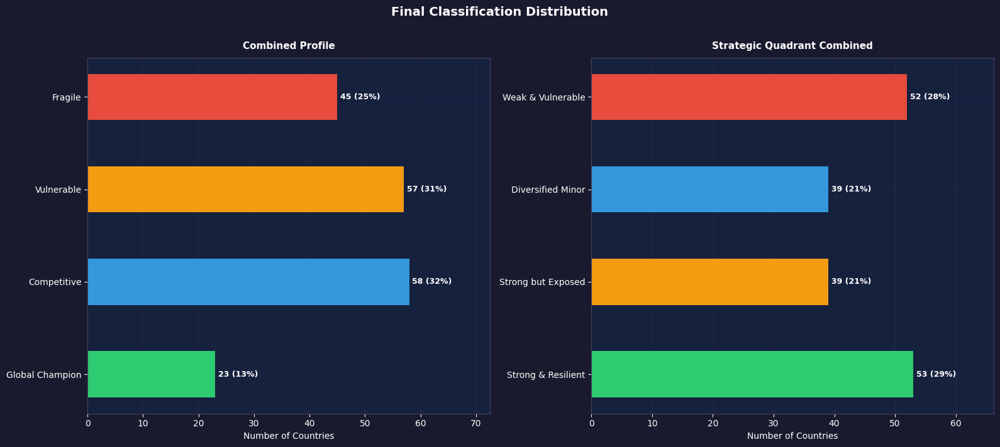

In [692]:
plot_profile_distribution(df_combined)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.3 Ranking
</div>

In [694]:
def plot_combined_ranking(df_combined, countries, n=10):
    """     Combined Score Ranking:  Top N Global Champions + Top N Fragile
    """
    df_sorted = df_combined.dropna(subset=['combined_score']).sort_values('combined_score', ascending=False)
    top_champ  = df_sorted.head(n)
    top_fragile = df_sorted.tail(n).sort_values('combined_score')

    profile_colors = { 'Global Champion': '#2ecc71', 'Competitive': '#3498db',  'Vulnerable':'#f39c12',   'Fragile': '#e74c3c' }

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=(18, n * 0.7 + 3))
    fig.suptitle(f'Combined Country Score Ranking — Top {n}', fontsize=14, fontweight='bold', color='white', y=1.01)

    for ax, df_plot, title in [(ax1, top_champ.sort_values('combined_score'), f'Top {n} Global Champions'),
                               (ax2, top_fragile, f'Top {n} Fragile Countries'),]:
        bar_colors = [profile_colors.get(p, '#aaaaaa') for p in df_plot['combined_profile']]
        bars = ax.barh(df_plot['country_name'], df_plot['combined_score'], color=bar_colors, edgecolor='none', height=0.6, zorder=2)

        # Value labels
        for bar, val in zip(bars, df_plot['combined_score']):
            ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f'{val:.3f}', va='center', fontsize=8, color='white', fontweight='bold')

        # Highlight selected countries
        for i, (_, row) in enumerate(df_plot.iterrows()):
            if row['country_name'] in countries:
                bars[i].set_edgecolor('#f1c40f')
                bars[i].set_linewidth(2.0)

        # Threshold lines
        for val, color, label in [(0.80, '#2ecc71', 'Global Champion'), (0.55, '#3498db', 'Competitive'), (0.30, '#f39c12', 'Vulnerable'),]:
            ax.axvline(x=val, color=color, linewidth=0.8, linestyle='--', alpha=0.7, label=label)

        ax.set_xlabel('Combined Score', fontsize=10)
        ax.set_title(title, fontsize=11, pad=10)
        ax.set_xlim(0, 1.05)
        style_grid(ax)
        add_legend(ax, loc='lower right', fontsize=7)

    save_figure(fig, '../Figures/Trade/H_4_3_combined_ranking.png')

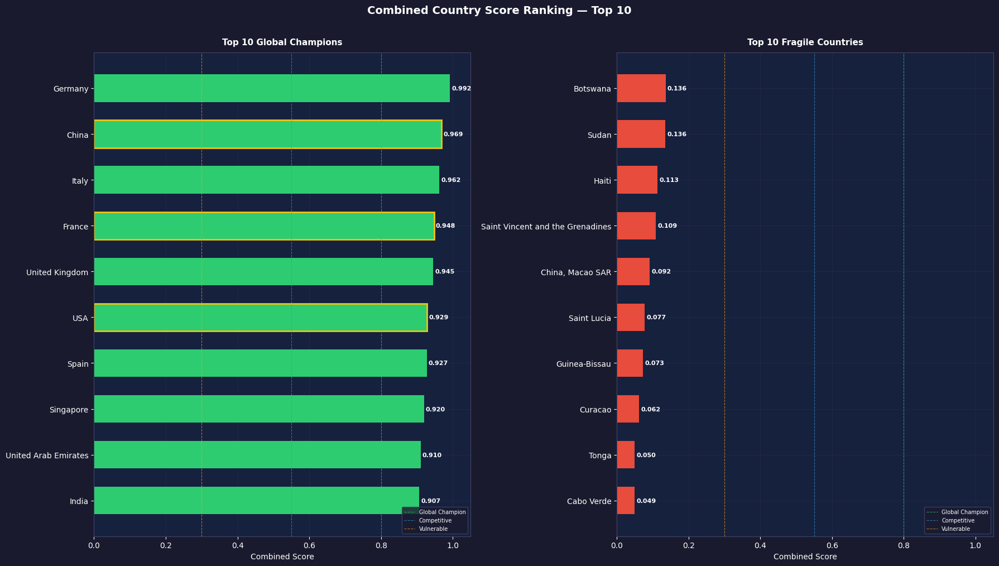

In [697]:
plot_combined_ranking(df_combined, countries, n=10)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.4 Country Positioning Scatter
</div>

In [699]:
def plot_country_positioning(df_combined, countries):
    """    Country Positioning Scatter:     X: structural_score (F — Trade Power absolute)    Y: score_full_periode (G — Bilateral Risk absolute)
                                            Color : combined_profile           Size : combined_score               Diagonal : F = G balance line    """

    profile_colors = {'Global Champion': '#2ecc71', 'Competitive': '#3498db', 'Vulnerable': '#f39c12', 'Fragile': '#e74c3c' }

    df_all  = df_combined.dropna(subset=['structural_score', 'score_full_periode']).copy()
    df_high = df_all[df_all['country_name'].isin(countries)]

    fig, ax = styled_figure(figsize=(14, 10))
    ax.set_title('Country Trade Positioning\n' 'X: Trade Power Score (F) | Y: Bilateral Risk Score (G)\n'
                 'Above diagonal: Bilateral Risk > Trade Power', fontsize=13, fontweight='bold', color='white', pad=15)

    # ── All countries ─────────────────────────────────────────────────────────
    for profile, color in profile_colors.items():
        df_p = df_all[df_all['combined_profile'] == profile]
        ax.scatter(df_p['structural_score'], df_p['score_full_periode'], color=color, s=25, alpha=0.30, edgecolors='none', zorder=1,
                   label=profile.split(' ', 1)[-1])

    # ── Highlighted countries ─────────────────────────────────────────────────
    for _, row in df_high.iterrows():
        color = profile_colors.get(row['combined_profile'], '#aaaaaa')
        ax.scatter(row['structural_score'], row['score_full_periode'], color=color, s=row['combined_score'] * 300 + 80,
                   edgecolors='white', linewidths=1.0, zorder=3, alpha=0.9)
        ax.annotate(row['country_name'], xy=(row['structural_score'], row['score_full_periode']),
                    xytext=(8, 4), textcoords='offset points', fontsize=8, color=color, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)

    # ── Reference lines ───────────────────────────────────────────────────────
    ax.axvline(x=0, color='#aaaaaa', linewidth=0.8, linestyle='--', alpha=0.6, label='F = 0 (avg trade power)')
    ax.axhline(y=df_all['score_full_periode'].median(), color='#aaaaaa', linewidth=0.8, linestyle=':', alpha=0.6, label='G median bilateral risk')

    ax.set_xlabel('Trade Power Score (F) — Higher = Stronger', fontsize=10)
    ax.set_ylabel('Bilateral Risk Score (G) — Higher = More Vulnerable', fontsize=10)
    style_grid(ax)
    add_legend(ax, loc='upper left', fontsize=8)

    save_figure(fig, '../Figures/Trade/H_4_4_country_positioning.png')

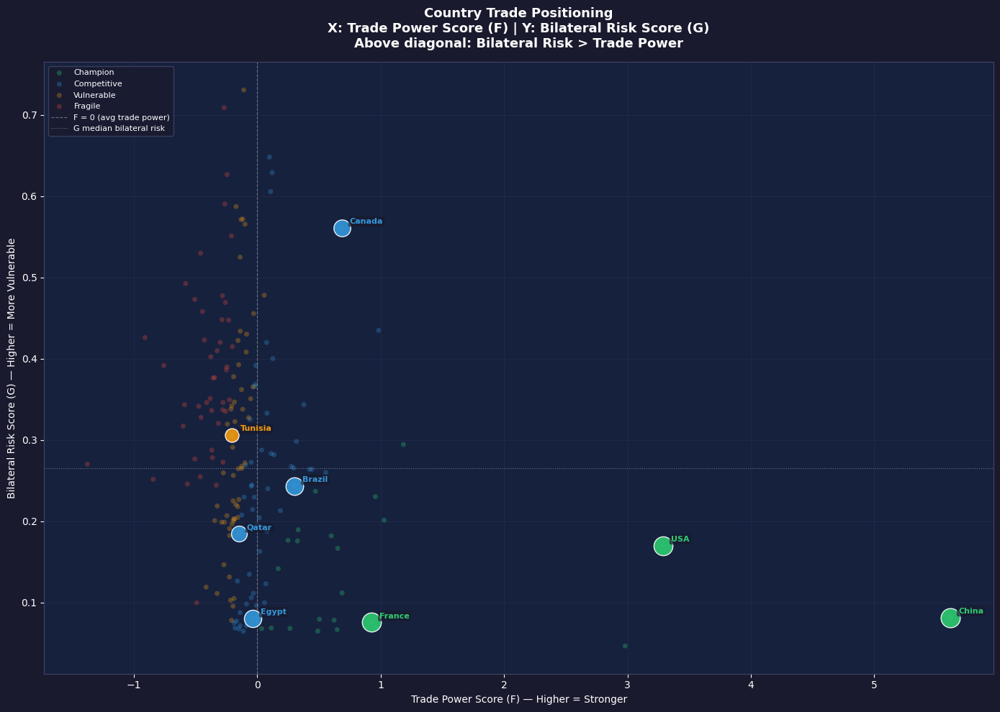

In [700]:
plot_country_positioning(df_combined, countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.5 Strategic Positioning Matrix
</div>

In [704]:
def plot_positioning_scatter(df_combined, countries, color_by='combined_profile'):
    """    Positioning Scatter: X : f_norm_rank | Y : g_norm_rank |  color_by : 'combined_profile' or 'strategic_quadrant_combined'    """

    if color_by == 'combined_profile':
        color_map = {'Global Champion': '#2ecc71', 'Competitive': '#3498db', 'Vulnerable': '#f39c12', 'Fragile': '#e74c3c'}
        quadrant_labels = [('Global Champion', 0.75, 0.85), ('Competitive', 0.75, 0.15), ('Vulnerable', 0.25, 0.85), ('Fragile', 0.25, 0.15)]
        show_quadrants = False
        filename    = '../Figures/Trade/H_4_5_positioning_combined_profile.png'
        title_suffix = 'Combined Profile'

    else:
        color_map = {'Strong & Resilient': '#2ecc71', 'Strong but Exposed': '#f39c12', 'Diversified Minor': '#3498db', 'Weak & Vulnerable': '#e74c3c'}
        quadrant_labels = [('Strong & Resilient',  0.75, 0.85), ('Strong but Exposed',  0.75, 0.15), ('Diversified Minor',   0.25, 0.85), ('Weak & Vulnerable',   0.25, 0.15),]
        threshold_x = 0.50
        threshold_y = 0.50
        filename    = '../Figures/Trade/H_4_5_positioning_strategic_quadrant_combined.png'
        title_suffix = 'Strategic Quadrant Combined'
        show_quadrants  = True

    df_all  = df_combined.dropna(subset=['f_norm_rank', 'g_norm_rank']).copy()
    df_high = df_all[df_all['country_name'].isin(countries)]

    fig, ax = styled_figure(figsize=(14, 10))
    ax.set_title(f'Country Positioning — {title_suffix}\n' f'X: Trade Power (F) | Y: Bilateral Resilience (G)',
                 fontsize=13, fontweight='bold', color='white', pad=15)

    # ── Quadrant backgrounds ──────────────────────────────────────────────────
    if show_quadrants:
        for (x0, x1, y0, y1), color in zip([(threshold_x, 1.0, threshold_y, 1.0), (threshold_x, 1.0, 0.0, threshold_y),
                                            (0.0, threshold_x, threshold_y, 1.0), (0.0, threshold_x, 0.0, threshold_y)], list(color_map.values())):
            ax.fill_betweenx([y0, y1], x0, x1, color=color, alpha=0.06)
            
        for lbl, x, y in quadrant_labels:
                ax.text(x, y, lbl, fontsize=8.5, color='#cccccc', ha='center', va='center', fontstyle='italic',
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='#1a1a2e', alpha=0.6, edgecolor='none'))
       
        # Threshold lines
        ax.axvline(x=threshold_x, color='white', linewidth=1.5, linestyle='--', alpha=0.8)
        ax.axhline(y=threshold_y, color='white', linewidth=1.5, linestyle='--', alpha=0.8)

    # ── All countries ─────────────────────────────────────────────────────────
    for profile, color in color_map.items():
        df_p = df_all[df_all[color_by] == profile]
        ax.scatter(df_p['f_norm_rank'], df_p['g_norm_rank'], color=color, s=100, alpha=0.30, edgecolors='none', zorder=1,
                   label=f"{profile.split(' ', 1)[-1]} ({len(df_p)})")

    # ── Highlighted countries ─────────────────────────────────────────────────
    for _, row in df_high.iterrows():
        color = color_map.get(row[color_by], '#aaaaaa')
        ax.scatter(row['f_norm_rank'], row['g_norm_rank'], color=color, s=row['combined_score'] * 300 + 80, edgecolors='white', linewidths=1.0,
                   zorder=3, alpha=0.9)
        ax.annotate(row['country_name'], xy=(row['f_norm_rank'], row['g_norm_rank']), xytext=(8, 4), textcoords='offset points', fontsize=8, color=color,
                    fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='#1a1a2e', alpha=0.7, edgecolor='none'), zorder=4)

    ax.set_xlabel('Trade Power Rank (F) — Higher = Stronger', fontsize=10)
    ax.set_ylabel('Bilateral Resilience Rank (G) — Higher = More Resilient', fontsize=10)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1.05)
    style_grid(ax)
    add_legend(ax, loc='best', fontsize=8)

    save_figure(fig, filename)

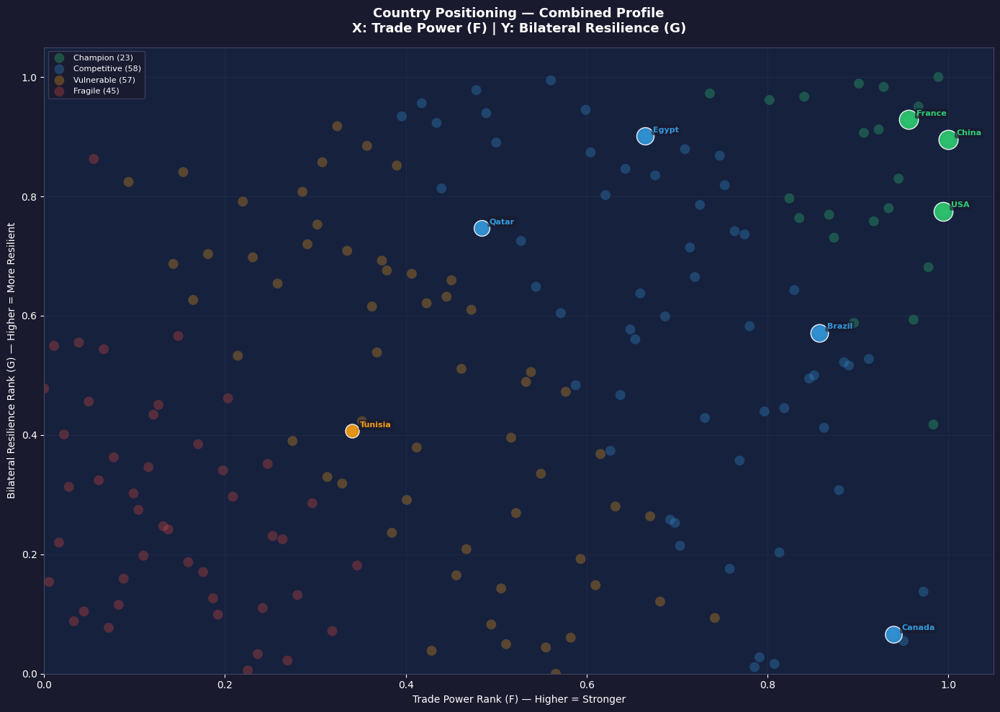

In [705]:
plot_positioning_scatter(df_combined, countries, 'combined_profile')

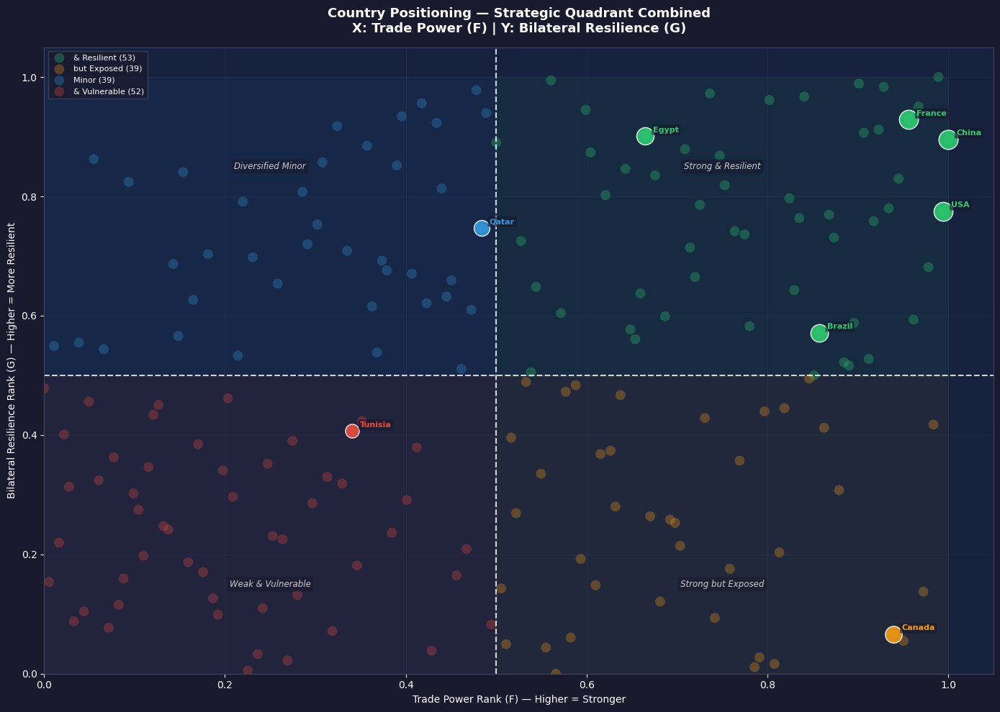

In [707]:
plot_positioning_scatter(df_combined, countries, 'strategic_quadrant_combined')

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.6 Export Table
</div>

In [710]:
df_combined.to_csv("../Analysis_files/Trade/df_combined.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 5. Country Trade Profile Card
</div>

In [713]:
def plot_country_profile_card(country_name, df_combined, df_trade):
    """    Country Profile Card — Single Country    
           6 cards : Trade Data | Trade Power | Bilateral Risk | Combined Positioning | Strengths | Weaknesses    """
    
    import matplotlib.gridspec as gridspec

    row = df_combined[df_combined['country_name'] == country_name]
    if row.empty:
        print(f"Country not found: {country_name}")
        return
    row = row.iloc[0]

    # Last year trade data
    df_c    = df_trade[df_trade['country_name'] == country_name]
    last_yr = df_c['year'].max()
    tr      = df_c[df_c['year'] == last_yr].iloc[0]

    profile_colors = {'Global Champion' : '#2ecc71','Competitive' : '#3498db','Vulnerable' : '#f39c12', 'Fragile': '#e74c3c'}
    LEVEL_COLORS = {1: '#2ecc71', 2: '#3498db', 3: '#f39c12', 4: '#e74c3c'}
    LABEL_LEVELS = {
                    'size_profile':        {'Leader': 1, 'Major': 2, 'Mid': 3, 'Small': 4},
                    'balance_profile':     {'Strong Surplus': 1, 'Slight Surplus': 2, 'Slight Deficit': 3, 'Structural Deficit': 4},
                    'growth_profile':      {'Strong Grower': 1, 'Moderate Grower': 2, 'Weak Grower': 3, 'Declining': 4},
                    'stability_profile':   {'Stable': 1, 'Moderate': 2, 'Volatile': 3, 'Very Volatile': 4},
                    'consistency_profile': {'Very Consistent': 1, 'Consistent': 2, 'Inconsistent': 3, 'Very Inconsistent': 4}
                    }

    p_color = profile_colors.get(row['combined_profile'], '#aaaaaa')

    # ── Figure ────────────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(20, 16))
    fig.patch.set_facecolor('#1a1a2e')

    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.12, wspace=0.08, left=0.03, right=0.97,  top=0.88, bottom=0.03)
    ax_data   = fig.add_subplot(gs[0, 0])  # Card 1 — Trade Data
    ax_f      = fig.add_subplot(gs[0, 1])  # Card 2 — Trade Power F
    ax_g      = fig.add_subplot(gs[1, 0])  # Card 3 — Bilateral Risk G
    ax_comb   = fig.add_subplot(gs[1, 1])  # Card 4 — Combined
    ax_str    = fig.add_subplot(gs[2, 0])  # Card 5 — Strengths
    ax_weak   = fig.add_subplot(gs[2, 1])  # Card 6 — Weaknesses

    for ax in [ax_data, ax_f, ax_g, ax_comb, ax_str, ax_weak]:
        ax.set_facecolor('#16213e')
        ax.axis('off')
        for spine in ax.spines.values(): spine.set_edgecolor('#444466')

    # ── HEADER ────────────────────────────────────────────────────────────────
    fig.suptitle(f'{country_name.upper()}   |   {row["combined_profile"]}   '
                 f'|   Combined Score : {row["combined_score"]:.3f}   '  f'|   {row["strategic_quadrant_combined"]}',
            fontsize=14, fontweight='bold', color='white', y=0.94, bbox=dict(boxstyle='round,pad=0.4',facecolor=p_color, alpha=0.85, edgecolor='none'))

    # ── Helper functions ──────────────────────────────────────────────────────
    def card_title(ax, title, color='#aaaaaa'):
        ax.text(0.5, 0.95, title, transform=ax.transAxes, fontsize=12, fontweight='bold', color=color, ha='center', va='top')
        ax.plot([0.05, 0.95], [0.90, 0.90], transform=ax.transAxes, color='#444466', linewidth=0.8, clip_on=False)

    def card_row(ax, label, value, y, color='#e0e0e0', badge_color=None):
        ax.text(0.08, y, label, transform=ax.transAxes, fontsize=10.5, color='#aaaaaa', va='center')
        if badge_color:
            badge = FancyBboxPatch((0.45, y - 0.035), 0.50, 0.07, transform=ax.transAxes, boxstyle='round,pad=0.003',
                                   facecolor=badge_color, edgecolor='none', alpha=0.85, zorder=1)
            ax.add_patch(badge)
            ax.text(0.70, y, value, transform=ax.transAxes, fontsize=10, color='white', ha='center', va='center', fontweight='bold', zorder=2)
        else:
            ax.text(0.92, y, value, transform=ax.transAxes, fontsize=10.5, color=color, ha='right', va='center', fontweight='bold')

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 1 — Trade Data
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_data, f'Trade Data — {last_yr}')

    trade_rows = [
                    ('Total Export',    _format_value(tr['X'])),
                    ('Total Import',    _format_value(tr['M'])),
                    ('Trade Balance',   _format_value(tr['trade_balance'])),
                    ('Export Share',    f"{tr['export_share']*100:.2f}%"),
                    ('Import Share',    f"{tr['import_share']*100:.2f}%"),
                    ('Coverage Ratio',  f"{tr['coverage_ratio']:.2f}"),
                    ('Trade Rank',      f"#{int(tr['rank'])}"),
                ]
    for i, (label, value) in enumerate(trade_rows):
        y = 0.82 - i * 0.11
        color = ('#2ecc71' if 'balance' in label.lower() and  tr['trade_balance'] >= 0 else
                 '#e74c3c' if 'balance' in label.lower() else '#e0e0e0')
        card_row(ax_data, label, value, y, color=color)

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 2 — Trade Power (F)
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_f, 'Trade Power (F)')

    ax_f.text(0.5, 0.83, f"Score: {row['structural_score']:.4f}  |  " f"{row['structural_profile']}  |  " f"{row['meta_profile']}",
              transform=ax_f.transAxes, fontsize=10, color='white', ha='center', va='center')

    f_items = [
        ('size_profile', 'Size',  f"{row['export_share_structural']*100:.2f}%"),
        ('balance_profile', 'Balance', f"{row['coverage_ratio_structural']:.2f}"),
        ('growth_profile', 'Growth',   f"CAGR {row['cagr_export']*100:.2f}%"),
        ('stability_profile', 'Stability', f"vol {row['volatility_export']:.1f}"),
        ('consistency_profile', 'Consistency', f"{row['negfreq_export']*100:.0f}% neg"),
              ]

    for i, (field, label, value) in enumerate(f_items):
        y = 0.72 - i * 0.12
        profile = row[field]
        level   = LABEL_LEVELS[field].get(profile, 4)
        color   = LEVEL_COLORS[level]
        card_row(ax_f, f"{label}: {profile}", value, y, badge_color=color)

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 3 — Bilateral Risk (G)
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_g, 'Bilateral Risk (G)')

    ax_g.text(0.5, 0.83, f"Score: {row['score_full_periode']:.4f}  |  "  f"{row['profile_full_periode']}", 
              transform=ax_g.transAxes, fontsize=10, color='white', ha='center', va='center')
    drift_colors = {'Improving': '#2ecc71', 'Stable':    '#f1c40f',  'Worsening': '#e74c3c'}
    g_items = [
                ('Top Partner', str(row['top_partner']), '#3498db'),
                ('HHI Import', f"{row['hhi_import']:.4f}", '#3498db'),
                ('HHI Export', f"{row['hhi_export']:.4f}", '#3498db'),
                ('Critical Share', f"{row['critical_share']*100:.1f}%", '#e74c3c' if row['critical_share'] >= 0.4 
                                                                                  else '#f39c12' if row['critical_share'] >= 0.2 else '#2ecc71'),
                ('N Critical',  f"{int(row['n_critical'])}", '#3498db'),
                ('Drift', str(row['drift']), drift_colors.get(row['drift'], '#aaaaaa')),
                ('Stability Score', f"{row['stability_score']:.2f}", '#3498db'),
             ]

    for i, (label, value, color) in enumerate(g_items):
        y = 0.72 - i * 0.10
        card_row(ax_g, label, value, y, badge_color=color)

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 4 — Combined Positioning
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_comb, 'Combined Positioning')
    comb_items = [
                    ('Combined Score', f"{row['combined_score']:.4f}", p_color),
                    ('Combined Profile', row['combined_profile'], p_color),
                    ('Strategic Quadrant', row['strategic_quadrant_combined'], '#3498db'),
                    ('F Rank', f"{row['f_norm_rank']:.3f}", '#f39c12'),
                    ('G Rank', f"{row['g_norm_rank']:.3f}", '#f39c12'),
                ]
    for i, (label, value, color) in enumerate(comb_items):
        y = 0.78 - i * 0.13
        card_row(ax_comb, label, value, y, badge_color=color)

    # Score bar
    ax_comb.text(0.08, 0.12, f"Combined Score : {row['combined_score']:.3f}", transform=ax_comb.transAxes, 
                 fontsize=10, color='white', fontweight='bold', va='center')
    bar_bg = FancyBboxPatch((0.08, 0.04), 0.84, 0.06, transform=ax_comb.transAxes,  boxstyle='round,pad=0.003',
                            facecolor='#1a1a2e', edgecolor='#444466', zorder=1)
    ax_comb.add_patch(bar_bg)
    bar_fg = FancyBboxPatch((0.08, 0.04), 0.84 * row['combined_score'], 0.06, transform=ax_comb.transAxes,
                            boxstyle='round,pad=0.003', facecolor=p_color, edgecolor='none', alpha=0.85, zorder=2)
    ax_comb.add_patch(bar_fg)

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 5 — Strengths
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_str, 'Strengths', color='#2ecc71')

    strengths = []
    if row['size_profile'] in ['Leader', 'Major']:                           strengths.append('Significant global trade weight')
    if row['growth_profile'] in ['Strong Grower', 'Moderate Grower']:        strengths.append('Positive export growth trajectory')
    if row['balance_profile'] in ['Strong Surplus', 'Slight Surplus']:       strengths.append('Favorable trade balance')
    if row['stability_profile'] in ['Stable', 'Moderate']:                   strengths.append('Stable export performance')
    if row['consistency_profile'] in ['Very Consistent', 'Consistent']:      strengths.append('Consistent growth pattern')
    if row['hhi_import'] < 0.10 and row['hhi_export'] < 0.10:                strengths.append('Well diversified bilateral trade')
    if row['critical_share'] < 0.20:                                         strengths.append('Low critical partner exposure')
    if row['drift'] == 'Improving':                                          strengths.append('Improving bilateral trajectory')
    if row['f_norm_rank'] >= 0.75:                                           strengths.append('Top quartile trade power')
    if row['g_norm_rank'] >= 0.75:                                           strengths.append('Top quartile bilateral resilience')
    if not strengths:                                                        strengths = ['None significant']

    for i, s in enumerate(strengths[:7]):
        y = 0.82 - i * 0.12
        ax_str.text(0.06, y, f'+ {s}', transform=ax_str.transAxes, fontsize=10.5, color='#2ecc71', va='center')

    # ══════════════════════════════════════════════════════════════════════════
    # CARD 6 — Weaknesses
    # ══════════════════════════════════════════════════════════════════════════
    card_title(ax_weak, 'Weaknesses', color='#e74c3c')

    weaknesses = []
    if row['size_profile'] in ['Mid', 'Small']:                                   weaknesses.append('Limited global trade weight')
    if row['growth_profile'] in ['Weak Grower', 'Declining']:                     weaknesses.append('Weak or negative export growth')
    if row['balance_profile'] in ['Slight Deficit', 'Structural Deficit']:        weaknesses.append('Structural trade deficit')
    if row['stability_profile'] in ['Volatile', 'Very Volatile']:                 weaknesses.append('High export volatility')
    if row['consistency_profile'] in ['Inconsistent', 'Very Inconsistent']:       weaknesses.append('Inconsistent growth pattern')
    if row['critical_share'] >= 0.40:                                             weaknesses.append('High critical partner exposure')
    if row['profile_full_periode'] == 'Critical Dependency':                  weaknesses.append('Critical bilateral dependency')
    if row['drift'] == 'Worsening':                                               weaknesses.append('Worsening bilateral trajectory')
    if row['f_norm_rank'] < 0.25:                                                 weaknesses.append('Bottom quartile trade power')
    if row['g_norm_rank'] < 0.25:                                                 weaknesses.append('Bottom quartile bilateral resilience')
    if not weaknesses:                                                            weaknesses = ['None significant']

    for i, w in enumerate(weaknesses[:7]):
        y = 0.82 - i * 0.12
        ax_weak.text(0.06, y, f'- {w}', transform=ax_weak.transAxes, fontsize=10.5, color='#e74c3c', va='center')

    save_figure(fig, f'../Figures/Trade/H_5_profile_card_{country_name.replace(" ", "_")}.png')

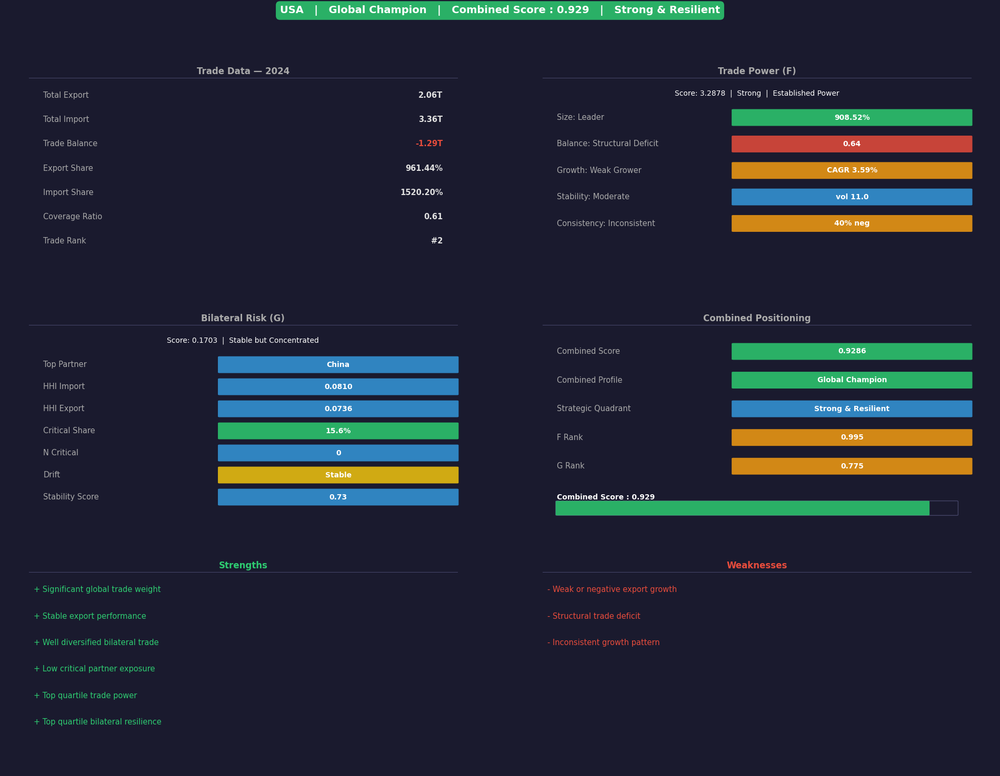

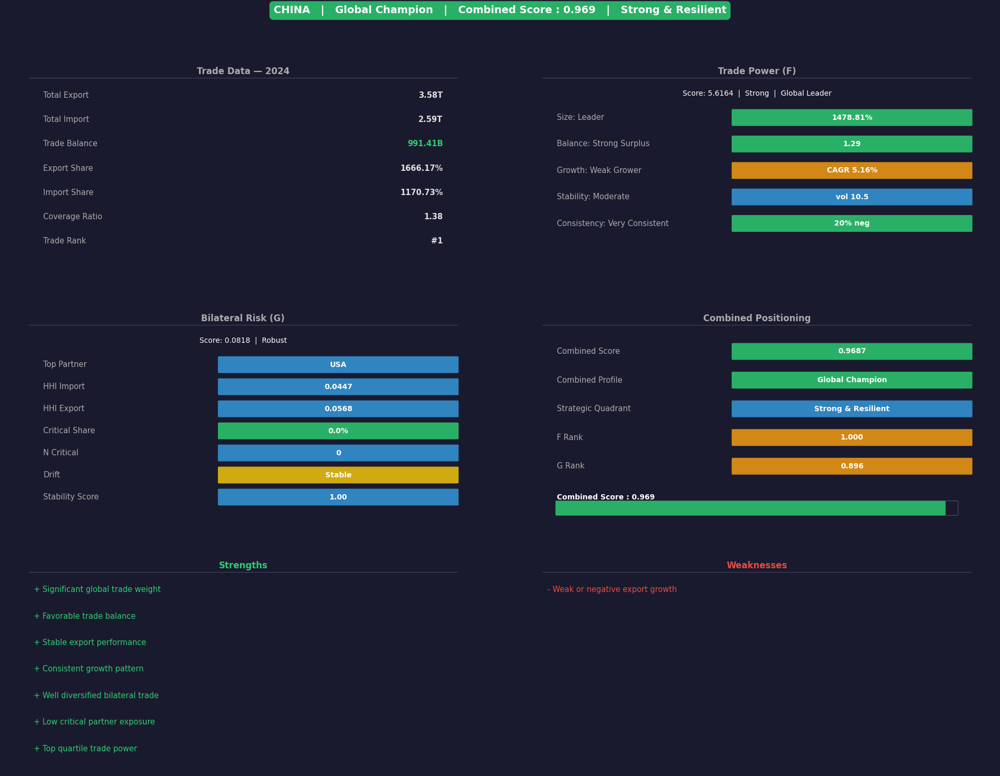

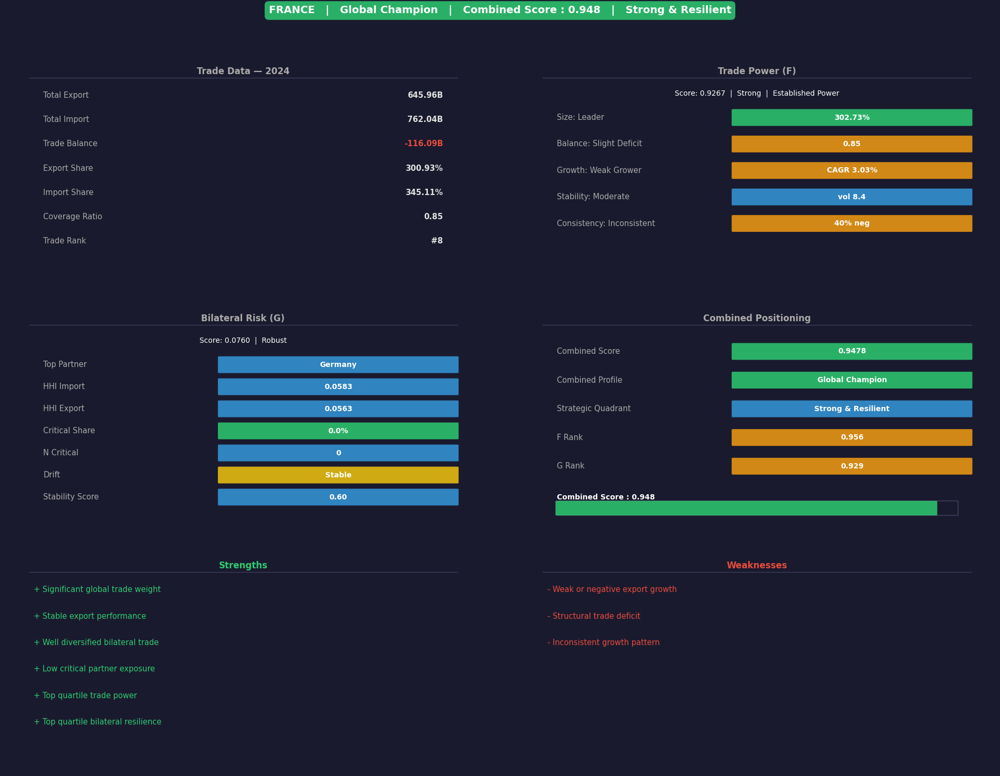

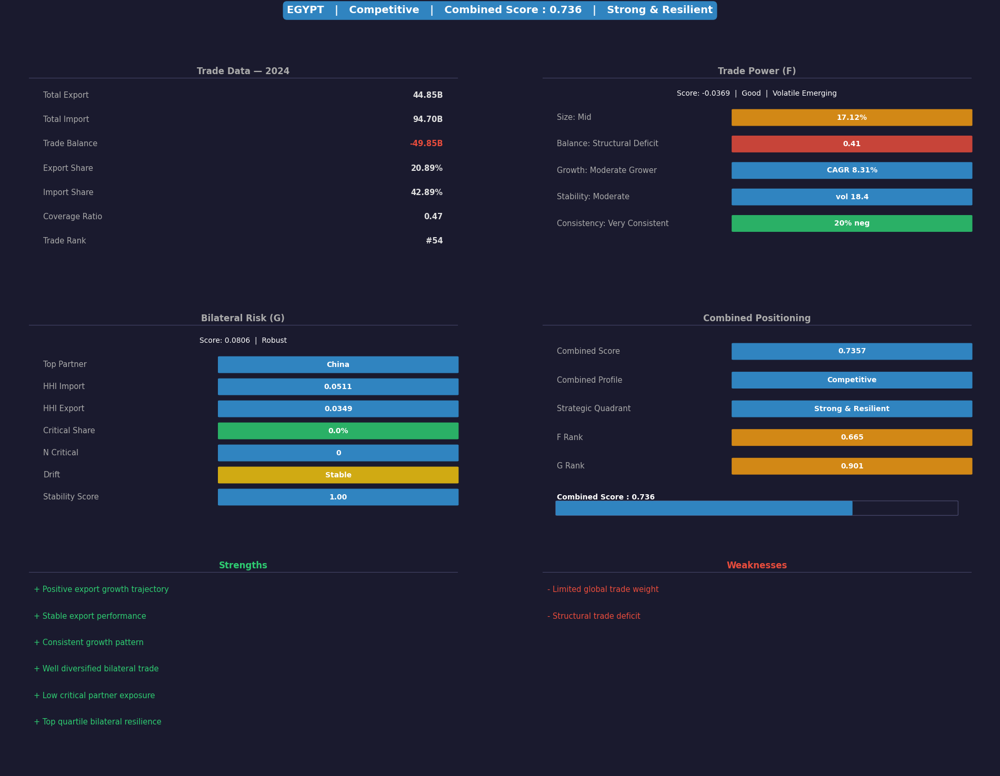

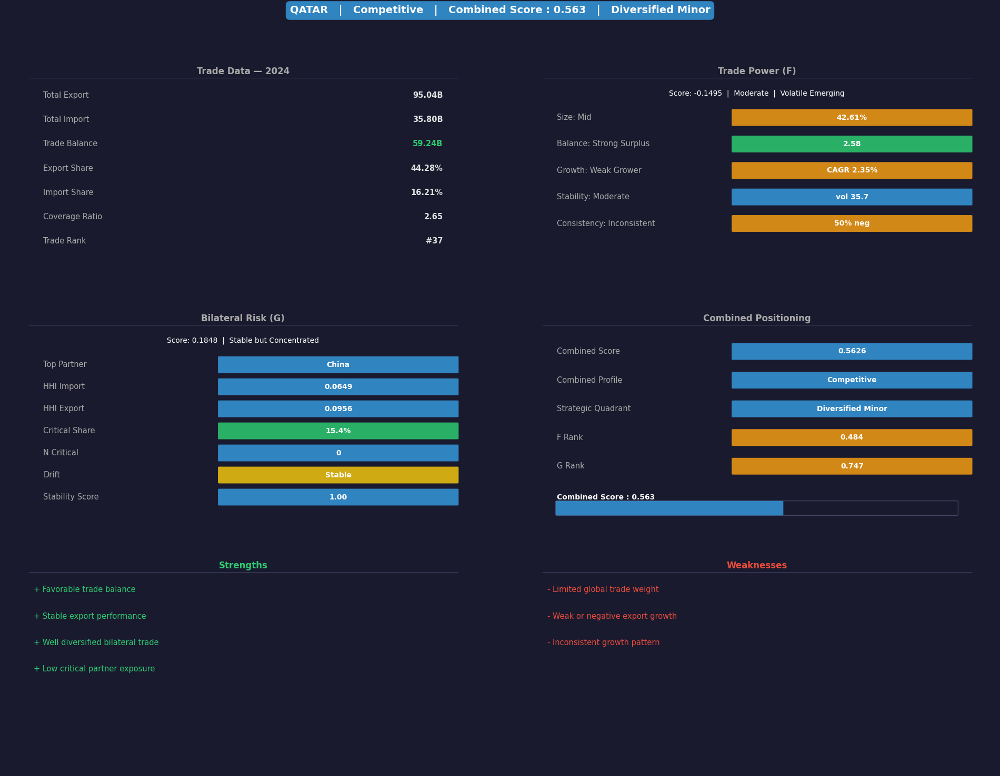

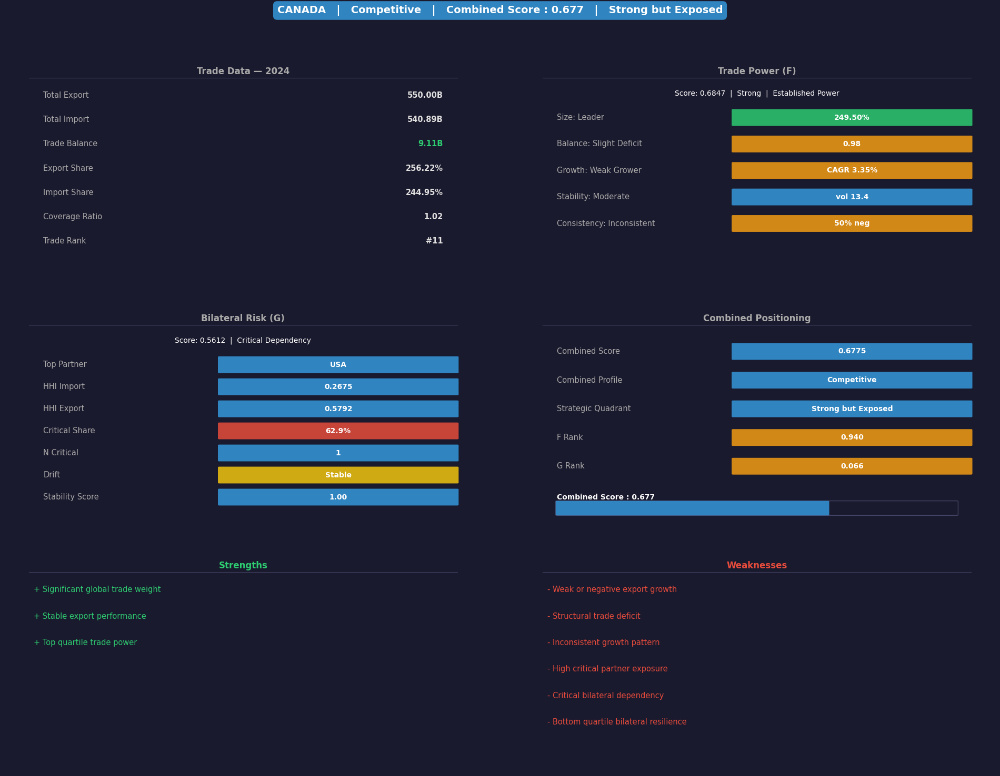

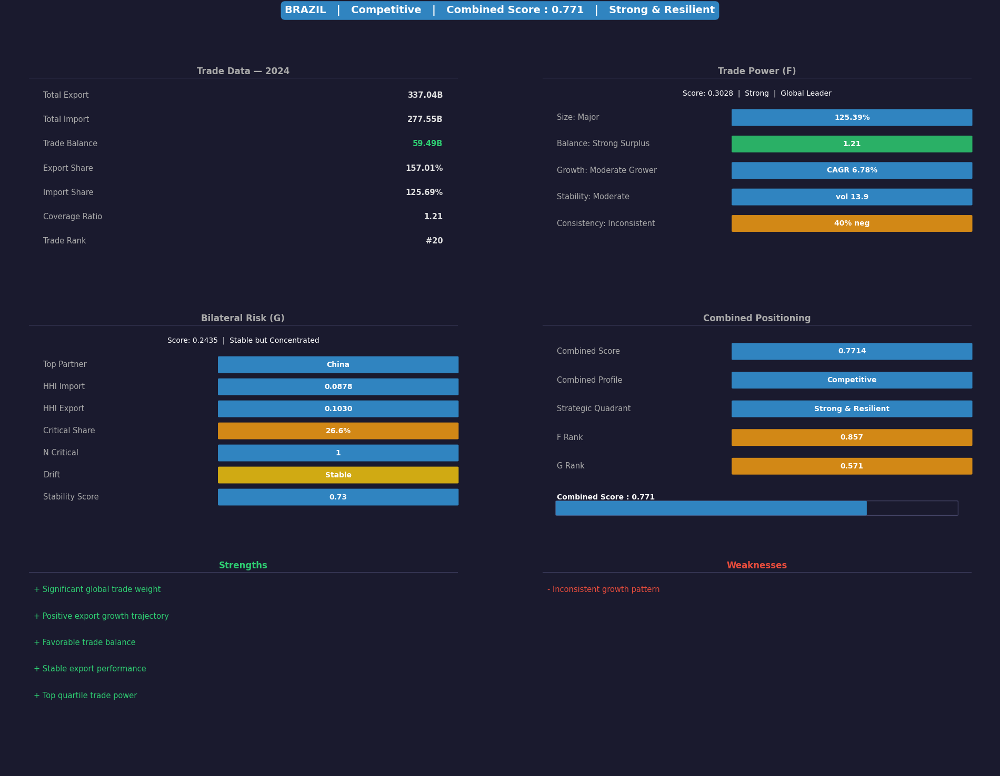

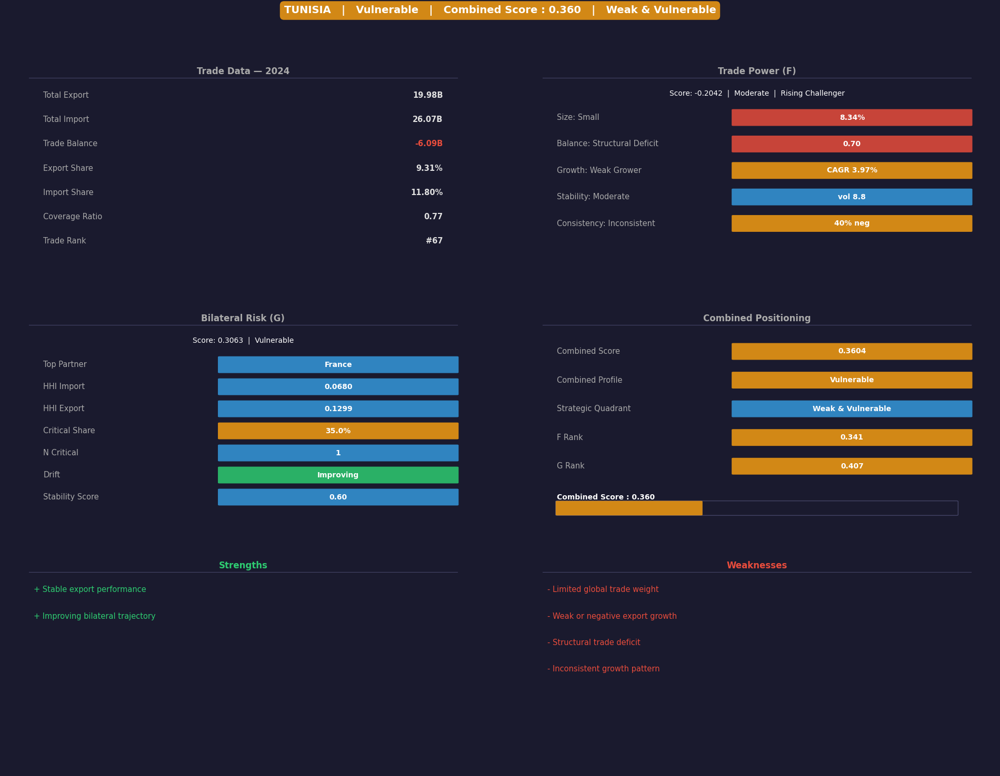

In [714]:
for country in countries:
    plot_country_profile_card(country, df_combined, df_trade)

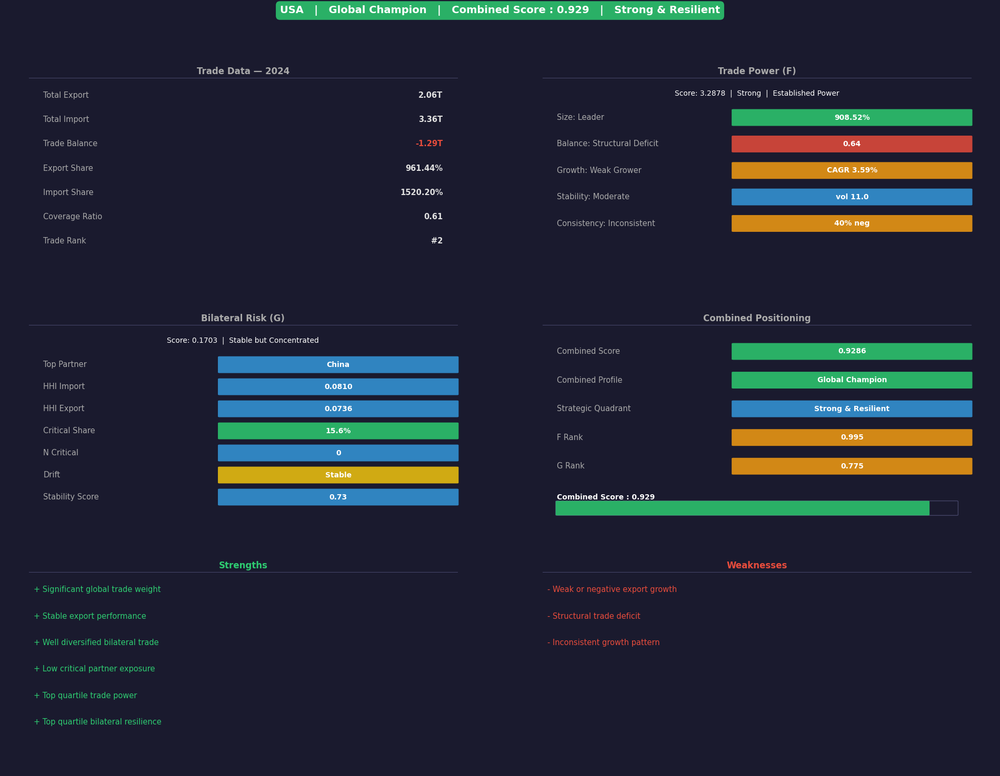

In [715]:
plot_country_profile_card("USA", df_combined, df_trade)

The profile card consolidates all analytical dimensions into a single
reference document per country — bridging the gap between technical
scores and strategic narrative. The separation of Trade Power (F) and
Bilateral Risk (G) into distinct cards deliberately highlights that
these two dimensions are complementary but independent : a country
can score Strong in F while being exposed in G, revealing hidden
vulnerabilities that a single composite score would mask.
Strengths and weaknesses are derived automatically from the classifications,
ensuring consistency with the full analytical framework.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 6. Stress Testing
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.1 Weight Sensitivity
</div>

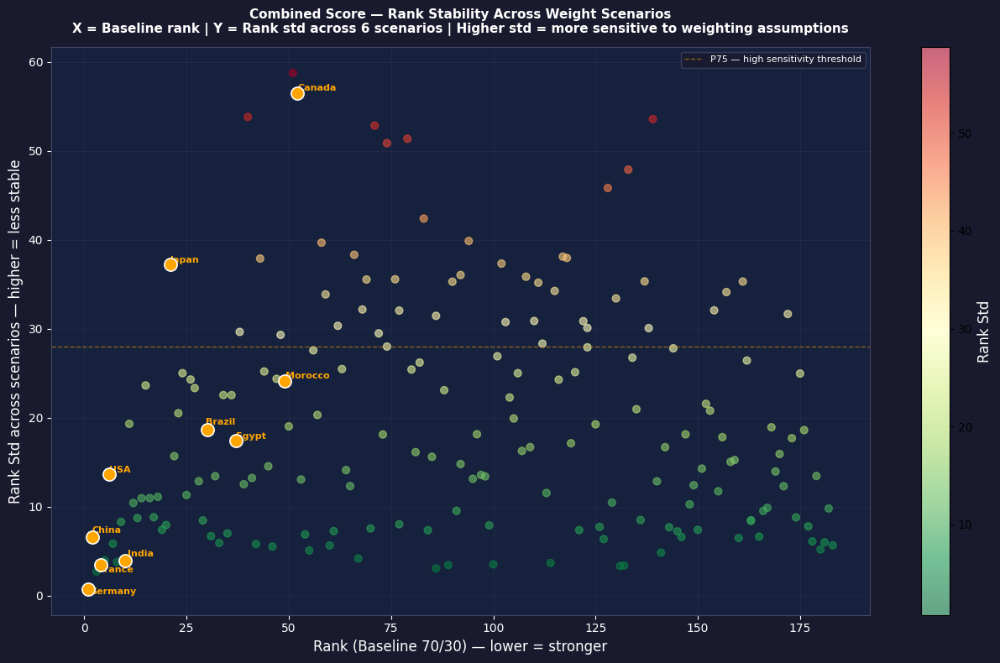

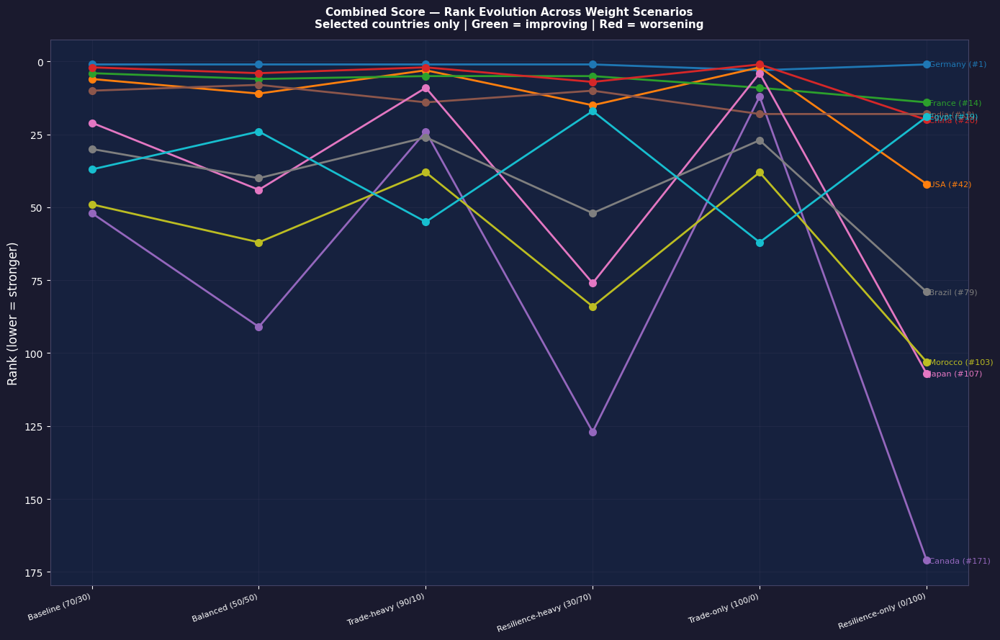

NameError: name 'C' is not defined

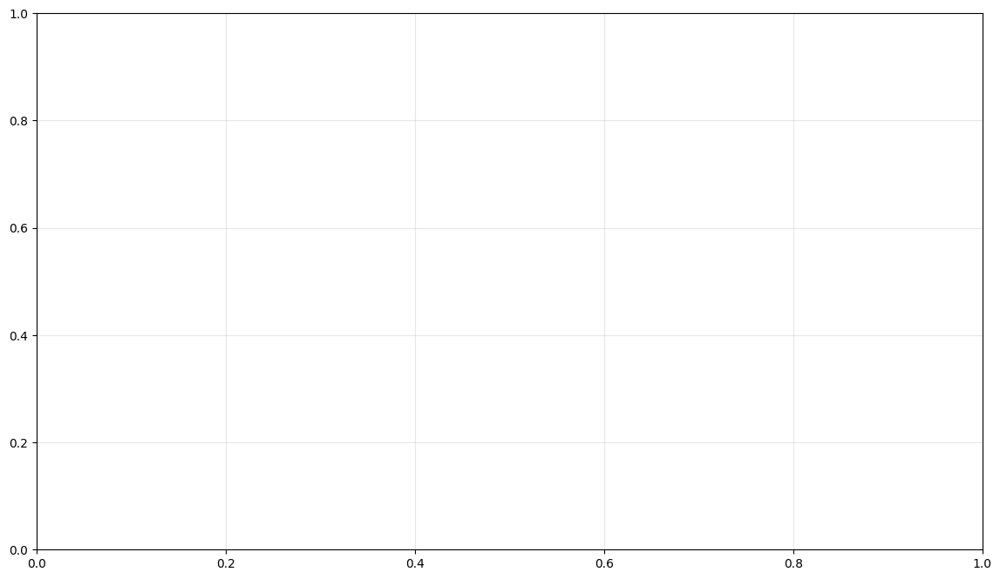

In [722]:
# ── H — Stress Test : Combined Score Weight Sensitivity ──────────────────────

from scipy.stats import rankdata, spearmanr
import matplotlib.patches as mpatches

def compute_combined_score_scenario(df, w_f, w_g):
    """Recompute combined score with custom weights."""
    df = df.dropna(subset=['structural_score', 'score_full_periode']).copy()
    df['f_norm_rank'] = (rankdata(df['structural_score']) - 1) / (len(df) - 1)
    df['g_norm_rank'] = 1 - ((rankdata(df['score_full_periode']) - 1) / (len(df) - 1))
    df['combined_score'] = w_f * df['f_norm_rank'] + w_g * df['g_norm_rank']
    df['combined_rank']  = rankdata(-df['combined_score']).astype(int)
    return df[['country_name', 'combined_score', 'combined_rank', 'f_norm_rank', 'g_norm_rank']]

# ── Scenarios ─────────────────────────────────────────────────────────────────
scenarios = {
    'Baseline (70/30)'        : (0.70, 0.30),
    'Balanced (50/50)'        : (0.50, 0.50),
    'Trade-heavy (90/10)'     : (0.90, 0.10),
    'Resilience-heavy (30/70)': (0.30, 0.70),
    'Trade-only (100/0)'      : (1.00, 0.00),
    'Resilience-only (0/100)' : (0.00, 1.00),
}

# ── Compute all scenarios ─────────────────────────────────────────────────────
stress_results = {}
for name, (wf, wg) in scenarios.items():
    stress_results[name] = compute_combined_score_scenario(df_combined.copy(), wf, wg)

# ── Build rank stability table ─────────────────────────────────────────────────
rank_table = pd.DataFrame({ name: res.set_index('country_name')['combined_rank']
                            for name, res in stress_results.items()})

rank_table['rank_mean'] = rank_table.mean(axis=1)
rank_table['rank_std']  = rank_table.std(axis=1)
rank_table['rank_range'] = rank_table[list(scenarios.keys())].max(axis=1) - rank_table[list(scenarios.keys())].min(axis=1)

rank_table = rank_table.sort_values('rank_mean')

# ── Profile stability per scenario ────────────────────────────────────────────
def classify_profile(score):
    if score >= 0.80:   return 'Global Champion'
    elif score >= 0.55: return 'Competitive'
    elif score >= 0.30: return 'Vulnerable'
    else:               return 'Fragile'

profile_table = pd.DataFrame({name: res.set_index('country_name')['combined_score'].apply(classify_profile)
                            for name, res in stress_results.items()})

profile_table['n_profile_changes'] = profile_table.apply(lambda row: len(row.unique()) - 1, axis=1)

# ── Figure 1 — Rank stability scatter ─────────────────────────────────────────
fig, ax = styled_figure(figsize=(13, 8))
ax.set_title("Combined Score — Rank Stability Across Weight Scenarios\n"
             "X = Baseline rank | Y = Rank std across 6 scenarios | "
             "Higher std = more sensitive to weighting assumptions", fontsize=11, color='white', pad=12)

baseline_ranks = rank_table['Baseline (70/30)']

# All countries
sc = ax.scatter(baseline_ranks, rank_table['rank_std'], c=rank_table['rank_std'], cmap='RdYlGn_r', s=40, alpha=0.6, zorder=2)

# Highlighted countries
highlight = ['Germany', 'USA', 'France', 'China', 'Canada', 'India', 'Japan', 'Brazil', 'Morocco', 'Egypt']

texts = []
for cntry in highlight:
    if cntry not in rank_table.index: continue
    x = rank_table.loc[cntry, 'Baseline (70/30)']
    y = rank_table.loc[cntry, 'rank_std']
    color = 'orange'
    ax.scatter(x, y, color=color, s=120, zorder=5, edgecolors='white', linewidths=1.2)
    t = ax.text(x, y, cntry, fontsize=8, color=color, fontweight='bold')
    texts.append(t)

from adjustText import adjust_text
adjust_text(texts, ax=ax, expand_points=(1.5,1.5), arrowprops=dict(arrowstyle='-', color='#666688', lw=0.6))

ax.axhline(rank_table['rank_std'].quantile(0.75), color='orange',
           linewidth=1, linestyle='--', alpha=0.5, label='P75 — high sensitivity threshold')

ax.set_xlabel('Rank (Baseline 70/30) — lower = stronger', color='white')
ax.set_ylabel('Rank Std across scenarios — higher = less stable', color='white')
plt.colorbar(sc, ax=ax, label='Rank Std').ax.yaxis.label.set_color('white')
add_legend(ax, fontsize=8)
style_grid(ax)
plt.tight_layout()
save_figure(fig, '../Figures/Trade/H_stress_rank_stability.png')
plt.show()

# ── Figure 2 — Bump chart : rank evolution across scenarios ───────────────────
fig, ax = styled_figure(figsize=(14, 9))
ax.set_title("Combined Score — Rank Evolution Across Weight Scenarios\n"
             "Selected countries only | Green = improving | Red = worsening", fontsize=11, color='white', pad=12)

scenario_names = list(scenarios.keys())
x_pos = range(len(scenario_names))
palette = plt.cm.tab10.colors

for i, cntry in enumerate(highlight):
    if cntry not in rank_table.index: continue
    ranks = [rank_table.loc[cntry, s] for s in scenario_names]
    color = palette[i % 10]
    ax.plot(x_pos, ranks, color=color, linewidth=2, marker='o', markersize=7, label=cntry, zorder=3)
    ax.annotate(f" {cntry} (#{int(ranks[-1])})", xy=(len(scenario_names)-1, ranks[-1]), fontsize=8, color=color, va='center')

ax.set_xticks(x_pos)
ax.set_xticklabels(scenario_names, rotation=20, ha='right', fontsize=8, color='white')
ax.set_ylabel('Rank (lower = stronger)', color='white')
ax.invert_yaxis()
style_grid(ax)
plt.tight_layout()
save_figure(fig, '../Figures/Trade/H_stress_bump_chart.png')
plt.show()

# ── Figure 3 — Profile change heatmap ─────────────────────────────────────────
profile_colors_map = {
    'Global Champion': '#2ecc71',
    'Competitive'    : '#3498db',
    'Vulnerable'     : '#e67e22',
    'Fragile'        : '#c0392b',
}
profile_num = {'Global Champion': 3, 'Competitive': 2, 'Vulnerable': 1, 'Fragile': 0}

countries_to_show = profile_table.nlargest(20, 'n_profile_changes').index.tolist()
df_heat = profile_table.loc[countries_to_show, scenario_names]
df_num  = df_heat.applymap(lambda x: profile_num[x])

fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor(C['bg']); ax.set_facecolor(C['ax_bg'])

im = ax.imshow(df_num.values, cmap='RdYlGn', vmin=0, vmax=3, aspect='auto')

for i in range(len(countries_to_show)):
    for j in range(len(scenario_names)):
        label = df_heat.iloc[i, j]
        ax.text(j, i, label[:4], ha='center', va='center', fontsize=7, color='white', fontweight='bold')

ax.set_xticks(range(len(scenario_names)))
ax.set_xticklabels(scenario_names, rotation=25, ha='right', fontsize=8, color='white')
ax.set_yticks(range(len(countries_to_show)))
ax.set_yticklabels(countries_to_show, fontsize=8, color='white')
ax.set_title("Profile Stability — Top 20 Most Sensitive Countries\n"
             "Green = Global Champion | Red = Fragile", fontsize=11, color='white', pad=10)
plt.tight_layout()
save_figure(fig, '../Figures/Trade/H_stress_profile_heatmap.png')
plt.show()

# ── Print summary ──────────────────────────────────────────────────────────────
print("\n=== STRESS TEST SUMMARY ===")
print(f"Total countries : {len(rank_table)}")
print(f"\nMost stable (rank_std < 5) :")
print(rank_table[rank_table['rank_std'] < 5][['Baseline (70/30)', 'rank_std', 'rank_range']].head(10))
print(f"\nMost sensitive (rank_std > 20) :")
print(rank_table[rank_table['rank_std'] > 20][['Baseline (70/30)', 'rank_std', 'rank_range']].head(10))
print(f"\nProfile changes per country :")
print(profile_table['n_profile_changes'].value_counts().sort_index())

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.1 Weight Sensitivity
</div>

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# I. Conclusions
</div>

## I.1 — Framework Summary

This analysis builds a **three-dimensional trade intelligence framework**
combining global structural performance (F), bilateral vulnerability (G),
and a unified country scoring (H) — moving beyond simple volume rankings
toward a structural and relational understanding of global trade.

---

## I.2 — Key Findings

- **Trade power is highly concentrated** — fewer than 20 countries control
  the majority of global exports, and this hierarchy is structurally frozen
  (Spearman > 0.99 year-over-year).

- **COVID-19 was the dominant structural break** — visible across all
  dimensions : volume contraction, concentration rebound, HHI spikes,
  and bilateral profile disruptions, with only partial normalization by 2024.

- **Bilateral vulnerability is independent of trade power** — large exporters
  (USA, Canada) can carry critical bilateral dependencies, while small
  economies can be structurally well diversified.

- **Only 20 countries qualify as Global Champions** — combining top-quartile
  trade power with strong bilateral resilience. True structural leadership
  is rare and hard to sustain.

- **Profile stability dominates** — 52% of countries never diverge from
  their full-period bilateral profile, confirming that trade structure
  is path-dependent and resistant to short-term shocks.

---

## I.3 — Limitations & Caveats

- **Data coverage** : bilateral analysis covers 133 countries in 2024
  due to UN Comtrade reporting lags — full-period analysis covers 187.
- **Export-centric** : the framework prioritizes export performance —
  import-driven economies may be systematically undervalued.
- **Period sensitivity** : 2020 COVID shock affects CAGR and volatility
  calculations for all countries.
- **Static partners** : bilateral analysis does not capture product-level
  or sector-level concentration.

---

## I.4 — Forward Link & Extensions

- **Streamlit dashboard** → interactive country profile cards with
  clickable figure links
- **Sector-level analysis** → HS code disaggregation for product
  concentration
- **Geopolitical risk overlay** → combine with sanctions, conflict,
  and alliance data
- **Time series forecasting** → predict structural profile transitions
  using historical patterns

<img src="../Figures/score_reference_guide.png" 
     alt="Score Reference Guide" 
     style="width:100%; max-width:1200px;">